In [1]:
# ============================================================
# PHASE 1 — SECTION 1
# Environment & Reproducibility
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Phase 1 environment initialised successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Random seed:", SEED)

Phase 1 environment initialised successfully.
NumPy version: 2.2.6
Pandas version: 2.3.3
Random seed: 42


In [2]:
# ============================================================
# PHASE 1 — SECTION 2
# Load and Inspect Original UAV Dataset
# ============================================================

# Update this filename/path only if your original dataset
# has a different name or location.
DATA_PATH = "uav_navigation_dataset.csv"

# Load dataset
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("\nShape:", df_raw.shape)

print("\nColumns:")
print(df_raw.columns.tolist())

print("\nFirst 5 rows:")
display(df_raw.head())

print("\nData types:")
print(df_raw.dtypes)

print("\nMissing values:")
print(df_raw.isnull().sum())

Dataset loaded successfully.

Shape: (5000, 15)

Columns:
['timestamp', 'latitude', 'longitude', 'altitude', 'imu_acc_x', 'imu_acc_y', 'imu_acc_z', 'imu_gyro_x', 'imu_gyro_y', 'imu_gyro_z', 'lidar_distance', 'speed', 'wind_speed', 'battery_level', 'obstacle_detected']

First 5 rows:


,timestamp,latitude,longitude,altitude,imu_acc_x,imu_acc_y,imu_acc_z,imu_gyro_x,imu_gyro_y,imu_gyro_z,lidar_distance,speed,wind_speed,battery_level,obstacle_detected
0,2023-01-01 00:00:00,37.772391,-122.421527,218.138368,-0.001979,1.379990,-2.445775,49.732045,39.381347,-72.391665,33.328274,26.180914,1.768356,79.324416,0
1,2023-01-01 00:00:01,37.783914,-122.419931,199.810443,1.480481,-1.892928,-2.635478,-14.654717,-165.994752,-145.865601,81.765473,17.362926,0.287489,90.488150,0
2,2023-01-01 00:00:02,37.779540,-122.412309,129.269261,0.376001,-0.920162,0.625152,167.219469,40.413723,-134.510679,99.440493,9.886640,14.688221,57.054390,0
3,2023-01-01 00:00:03,37.776873,-122.422600,323.270002,-2.500185,0.979684,2.796698,-101.167758,-147.719302,-114.958394,84.155773,23.416045,5.234081,43.134299,0
4,2023-01-01 00:00:04,37.768020,-122.412007,264.480872,-1.886519,-0.107464,0.016328,31.628310,75.723926,-106.684800,34.941221,15.466953,17.553565,45.507726,0



Data types:
timestamp             object
latitude             float64
longitude            float64
altitude             float64
imu_acc_x            float64
imu_acc_y            float64
imu_acc_z            float64
imu_gyro_x           float64
imu_gyro_y           float64
imu_gyro_z           float64
lidar_distance       float64
speed                float64
wind_speed           float64
battery_level        float64
obstacle_detected      int64
dtype: object

Missing values:
timestamp            0
latitude             0
longitude            0
altitude             0
imu_acc_x            0
imu_acc_y            0
imu_acc_z            0
imu_gyro_x           0
imu_gyro_y           0
imu_gyro_z           0
lidar_distance       0
speed                0
wind_speed           0
battery_level        0
obstacle_detected    0
dtype: int64


In [3]:
# ============================================================
# PHASE 1 — SECTION 3
# Source Temporal Integrity Validation
# ============================================================

# Work on a copy so the original dataframe remains unchanged
df_source = df_raw.copy()

# Convert timestamp to datetime
df_source["timestamp"] = pd.to_datetime(
    df_source["timestamp"],
    errors="coerce"
)

# Check timestamp conversion
print("Invalid timestamps:", df_source["timestamp"].isna().sum())

# Sort chronologically
df_source = df_source.sort_values("timestamp").reset_index(drop=True)

# Calculate time differences
time_diff = df_source["timestamp"].diff().dt.total_seconds()

# Remove the first NaN created by diff()
time_diff_valid = time_diff.dropna()

print("\n--- Temporal Integrity ---")
print("First timestamp:", df_source["timestamp"].iloc[0])
print("Last timestamp:", df_source["timestamp"].iloc[-1])

print("\nNumber of rows:", len(df_source))
print("Unique timestamps:", df_source["timestamp"].nunique())
print("Duplicate timestamps:", df_source["timestamp"].duplicated().sum())

print("\nTime interval distribution (seconds):")
print(time_diff_valid.value_counts().sort_index())

print("\nMinimum interval:", time_diff_valid.min(), "seconds")
print("Maximum interval:", time_diff_valid.max(), "seconds")
print("Median interval:", time_diff_valid.median(), "seconds")

print("\nDuplicate complete rows:", df_source.duplicated().sum())

# Chronological ordering check
is_chronological = df_source["timestamp"].is_monotonic_increasing

print("\nChronologically ordered:", is_chronological)

Invalid timestamps: 0

--- Temporal Integrity ---
First timestamp: 2023-01-01 00:00:00
Last timestamp: 2023-01-01 01:23:19

Number of rows: 5000
Unique timestamps: 5000
Duplicate timestamps: 0

Time interval distribution (seconds):
timestamp
1.0    4999
Name: count, dtype: int64

Minimum interval: 1.0 seconds
Maximum interval: 1.0 seconds
Median interval: 1.0 seconds

Duplicate complete rows: 0

Chronologically ordered: True


In [4]:
# ============================================================
# PHASE 1 — SECTION 4
# Source Dataset Statistical & Physical Validation
# ============================================================

# Numerical columns
numeric_columns = df_source.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Numerical columns:")
print(numeric_columns)

# Descriptive statistics
print("\n--- Descriptive Statistics ---")
display(
    df_source[numeric_columns]
    .describe()
    .T
    .round(4)
)

# Check infinite values
inf_counts = np.isinf(
    df_source[numeric_columns].to_numpy()
).sum(axis=0)

inf_check = pd.Series(
    inf_counts,
    index=numeric_columns
)

print("\n--- Infinite Value Check ---")
print(inf_check)

# Check constant columns
constant_columns = [
    col for col in numeric_columns
    if df_source[col].nunique() <= 1
]

print("\nConstant numerical columns:")
print(constant_columns)

# Check categorical/binary columns
print("\n--- Unique Values in Non-continuous Columns ---")

for col in ["obstacle_detected"]:
    if col in df_source.columns:
        print(f"{col}: {sorted(df_source[col].dropna().unique().tolist())}")

# Explicit navigation/sensor ranges
range_columns = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "lidar_distance",
    "wind_speed",
    "battery_level"
]

print("\n--- Key Feature Ranges ---")

for col in range_columns:
    if col in df_source.columns:
        print(
            f"{col:20s} "
            f"min={df_source[col].min():.4f}, "
            f"max={df_source[col].max():.4f}, "
            f"mean={df_source[col].mean():.4f}"
        )

Numerical columns:
['latitude', 'longitude', 'altitude', 'imu_acc_x', 'imu_acc_y', 'imu_acc_z', 'imu_gyro_x', 'imu_gyro_y', 'imu_gyro_z', 'lidar_distance', 'speed', 'wind_speed', 'battery_level', 'obstacle_detected']

--- Descriptive Statistics ---


,count,mean,std,min,25%,50%,75%,max
latitude,5000.0,37.7748,0.0058,37.7649,37.7698,37.7749,37.7799,37.7849
longitude,5000.0,-122.4196,0.0057,-122.4294,-122.4245,-122.4197,-122.4147,-122.4094
altitude,5000.0,275.6188,130.8464,50.0710,161.2253,273.2887,392.2786,499.9123
imu_acc_x,5000.0,0.0461,1.7268,-2.9985,-1.4236,0.0747,1.5066,2.9995
imu_acc_y,5000.0,0.0527,1.7324,-2.9997,-1.4466,0.0800,1.5462,2.9994
imu_acc_z,5000.0,-0.0521,1.7073,-2.9993,-1.5171,-0.0541,1.3929,2.9984
imu_gyro_x,5000.0,0.2211,103.7972,-179.9980,-90.8913,0.6844,89.3616,179.9242
imu_gyro_y,5000.0,-1.1475,104.2843,-179.9352,-91.3618,-0.5937,88.9123,179.7367
imu_gyro_z,5000.0,-0.5558,104.1469,-179.9940,-90.6545,-3.1055,91.2511,179.9900
lidar_distance,5000.0,49.7795,28.7845,0.5104,24.5730,49.8449,74.9408,99.9957



--- Infinite Value Check ---
latitude             0
longitude            0
altitude             0
imu_acc_x            0
imu_acc_y            0
imu_acc_z            0
imu_gyro_x           0
imu_gyro_y           0
imu_gyro_z           0
lidar_distance       0
speed                0
wind_speed           0
battery_level        0
obstacle_detected    0
dtype: int64

Constant numerical columns:
[]

--- Unique Values in Non-continuous Columns ---
obstacle_detected: [0, 1]

--- Key Feature Ranges ---
latitude             min=37.7649, max=37.7849, mean=37.7748
longitude            min=-122.4294, max=-122.4094, mean=-122.4196
altitude             min=50.0710, max=499.9123, mean=275.6188
speed                min=5.0097, max=29.9960, mean=17.6039
imu_acc_x            min=-2.9985, max=2.9995, mean=0.0461
imu_acc_y            min=-2.9997, max=2.9994, mean=0.0527
imu_acc_z            min=-2.9993, max=2.9984, mean=-0.0521
imu_gyro_x           min=-179.9980, max=179.9242, mean=0.2211
imu_gyro_y      

Source trajectory temporal dynamics calculated.

--- Frame-to-Frame Change Statistics ---


,count,mean,std,min,25%,50%,75%,max
latitude_delta,4999.0,0.000001,0.008181,-0.019344,-0.005839,-0.000039,0.005960,0.019779
longitude_delta,4999.0,-0.000001,0.008193,-0.019475,-0.005782,0.000086,0.005859,0.019911
altitude_delta,4999.0,-0.011033,184.083384,-447.611947,-129.641889,-1.324745,133.146330,443.855207
speed_delta,4999.0,-0.000285,10.126587,-24.256533,-7.352012,0.178234,7.214931,24.416737
imu_acc_x_delta,4999.0,-0.000393,2.429098,-5.945596,-1.752683,0.003880,1.735197,5.899400
imu_acc_y_delta,4999.0,0.000266,2.445594,-5.949314,-1.776863,0.033398,1.776626,5.865956
imu_acc_z_delta,4999.0,0.000198,2.425978,-5.854321,-1.713692,0.041647,1.770956,5.925637
imu_gyro_x_delta,4999.0,0.019195,146.756005,-359.273456,-105.584510,1.611929,106.440715,351.328193
imu_gyro_y_delta,4999.0,-0.008784,147.640639,-349.966871,-103.152865,-0.305591,107.486102,358.115172
imu_gyro_z_delta,4999.0,0.039920,146.474247,-351.156062,-101.194339,-0.497397,104.704750,351.699503



--- Maximum Absolute Frame-to-Frame Changes ---


altitude_delta      447.611947
imu_gyro_x_delta    359.273456
imu_gyro_y_delta    358.115172
imu_gyro_z_delta    351.699503
speed_delta          24.416737
imu_acc_y_delta       5.949314
imu_acc_x_delta       5.945596
imu_acc_z_delta       5.925637
longitude_delta       0.019911
latitude_delta        0.019779
dtype: float64


--- Largest Position Changes ---


,latitude_delta,longitude_delta,altitude_delta
2529,0.019779,0.007621,192.186673
3913,0.019440,0.013136,138.550030
1074,0.019397,0.003072,114.604630
3503,0.019344,0.013832,48.706503
3925,0.019291,0.008737,167.851532
4327,0.019209,0.010941,17.665801
1426,0.019204,0.015813,119.175455
4743,0.019175,0.003357,170.313559
471,0.019154,0.007488,126.411184
3710,0.019062,0.001648,172.614996


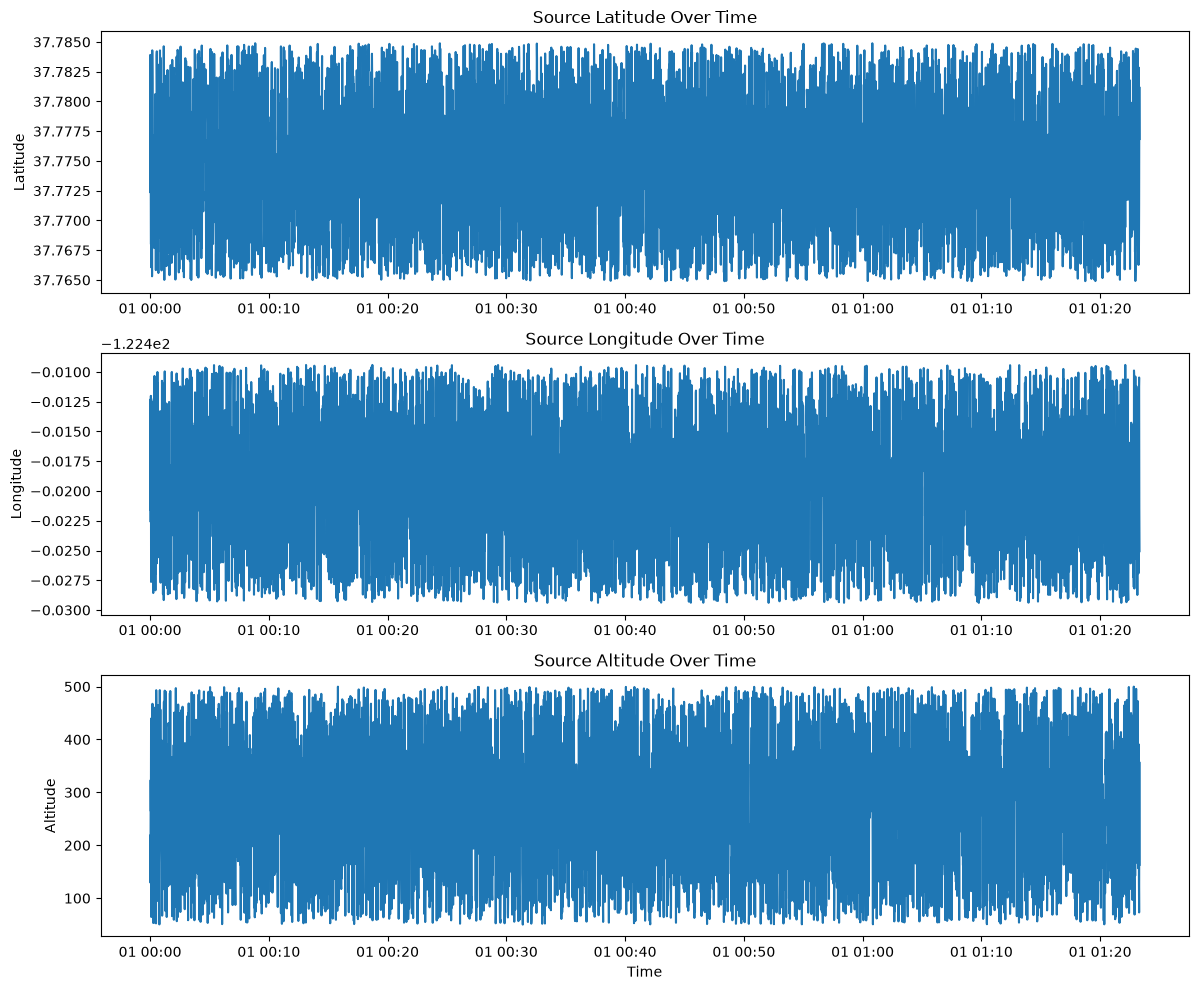

In [5]:
# ============================================================
# PHASE 1 — SECTION 5
# Source Flight Temporal Dynamics
# ============================================================

# Columns representing the main trajectory and motion variables
temporal_features = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z"
]

# Calculate first differences to understand natural movement
df_dynamics = df_source.copy()

for col in temporal_features:
    df_dynamics[f"{col}_delta"] = df_dynamics[col].diff()

print("Source trajectory temporal dynamics calculated.")

# ------------------------------------------------------------
# 1. Summary of natural frame-to-frame changes
# ------------------------------------------------------------

delta_columns = [f"{col}_delta" for col in temporal_features]

print("\n--- Frame-to-Frame Change Statistics ---")

display(
    df_dynamics[delta_columns]
    .describe()
    .T
    .round(6)
)

# ------------------------------------------------------------
# 2. Maximum natural changes
# ------------------------------------------------------------

print("\n--- Maximum Absolute Frame-to-Frame Changes ---")

max_changes = (
    df_dynamics[delta_columns]
    .abs()
    .max()
    .sort_values(ascending=False)
)

display(max_changes.round(6))

# ------------------------------------------------------------
# 3. Check whether any major discontinuities already exist
# ------------------------------------------------------------

print("\n--- Largest Position Changes ---")

position_delta_columns = [
    "latitude_delta",
    "longitude_delta",
    "altitude_delta"
]

display(
    df_dynamics[position_delta_columns]
    .abs()
    .sort_values(
        by=position_delta_columns,
        ascending=False
    )
    .head(10)
)

# ------------------------------------------------------------
# 4. Plot the original trajectory
# ------------------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(
    df_source["timestamp"],
    df_source["latitude"]
)

axes[0].set_title("Source Latitude Over Time")
axes[0].set_ylabel("Latitude")

axes[1].plot(
    df_source["timestamp"],
    df_source["longitude"]
)

axes[1].set_title("Source Longitude Over Time")
axes[1].set_ylabel("Longitude")

axes[2].plot(
    df_source["timestamp"],
    df_source["altitude"]
)

axes[2].set_title("Source Altitude Over Time")
axes[2].set_ylabel("Altitude")
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [6]:
# ============================================================
# PHASE 1 — SECTION 6
# ATTACK SCENARIO CONFIGURATION
#
# Purpose:
# Define the controlled synthetic attack scenarios required
# by the research proposal before generating attack data.
#
# Required classes:
#   0 = Normal
#   1 = Spoofing
#   2 = Jamming
#
# Required spoofing mechanisms:
#   - Gradual drift
#   - Sudden jump
#
# Required jamming mechanisms:
#   - Noise injection
#   - Signal loss / freezing
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 6")
print("ATTACK SCENARIO CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Class definitions
# ------------------------------------------------------------

NORMAL_LABEL = 0
SPOOFING_LABEL = 1
JAMMING_LABEL = 2

class_names = {
    NORMAL_LABEL: "Normal",
    SPOOFING_LABEL: "Spoofing",
    JAMMING_LABEL: "Jamming"
}

# ------------------------------------------------------------
# 2. Required dataset distribution
# ------------------------------------------------------------

TOTAL_SAMPLES = len(df_source)

NORMAL_RATIO = 0.60
SPOOFING_RATIO = 0.20
JAMMING_RATIO = 0.20

normal_samples = int(TOTAL_SAMPLES * NORMAL_RATIO)
spoofing_samples = int(TOTAL_SAMPLES * SPOOFING_RATIO)
jamming_samples = int(TOTAL_SAMPLES * JAMMING_RATIO)

print("\nDataset distribution target:")
print(f"Total samples : {TOTAL_SAMPLES}")
print(f"Normal        : {normal_samples} ({NORMAL_RATIO:.0%})")
print(f"Spoofing      : {spoofing_samples} ({SPOOFING_RATIO:.0%})")
print(f"Jamming       : {jamming_samples} ({JAMMING_RATIO:.0%})")

assert (
    normal_samples + spoofing_samples + jamming_samples
    == TOTAL_SAMPLES
), "Class sample counts do not sum to total samples."

# ------------------------------------------------------------
# 3. Spoofing scenarios
# ------------------------------------------------------------

SPOOFING_SCENARIOS = {
    "gradual_drift": {
        "label": SPOOFING_LABEL,
        "description": (
            "Gradual GNSS position drift designed to represent "
            "stealthy coordinate dragging."
        )
    },
    "sudden_jump": {
        "label": SPOOFING_LABEL,
        "description": (
            "Sudden GNSS position displacement representing "
            "an abrupt spoofing event."
        )
    }
}

# ------------------------------------------------------------
# 4. Jamming scenarios
# ------------------------------------------------------------

JAMMING_SCENARIOS = {
    "noise_injection": {
        "label": JAMMING_LABEL,
        "description": (
            "GNSS measurement corruption through controlled "
            "noise injection."
        )
    },
    "signal_loss_freezing": {
        "label": JAMMING_LABEL,
        "description": (
            "GNSS signal loss represented by measurement "
            "freezing during the attack interval."
        )
    }
}

# ------------------------------------------------------------
# 5. Configuration summary
# ------------------------------------------------------------

print("\nSpoofing scenarios:")
for name, config in SPOOFING_SCENARIOS.items():
    print(f"  - {name}: {config['description']}")

print("\nJamming scenarios:")
for name, config in JAMMING_SCENARIOS.items():
    print(f"  - {name}: {config['description']}")

# ------------------------------------------------------------
# 6. Proposal-alignment checks
# ------------------------------------------------------------

assert NORMAL_LABEL == 0
assert SPOOFING_LABEL == 1
assert JAMMING_LABEL == 2

assert len(SPOOFING_SCENARIOS) == 2
assert "gradual_drift" in SPOOFING_SCENARIOS
assert "sudden_jump" in SPOOFING_SCENARIOS

assert len(JAMMING_SCENARIOS) == 2
assert "noise_injection" in JAMMING_SCENARIOS
assert "signal_loss_freezing" in JAMMING_SCENARIOS

print("\n" + "=" * 70)
print("SECTION 6 — CONFIGURATION PASSED")
print("=" * 70)
print("Normal    : 60%")
print("Spoofing  : 20%")
print("Jamming   : 20%")
print("Spoofing mechanisms : Drift + Jump")
print("Jamming mechanisms  : Noise + Signal Loss/Freezing")
print("=" * 70)

PHASE 1 — SECTION 6
ATTACK SCENARIO CONFIGURATION

Dataset distribution target:
Total samples : 5000
Normal        : 3000 (60%)
Spoofing      : 1000 (20%)
Jamming       : 1000 (20%)

Spoofing scenarios:
  - gradual_drift: Gradual GNSS position drift designed to represent stealthy coordinate dragging.
  - sudden_jump: Sudden GNSS position displacement representing an abrupt spoofing event.

Jamming scenarios:
  - noise_injection: GNSS measurement corruption through controlled noise injection.
  - signal_loss_freezing: GNSS signal loss represented by measurement freezing during the attack interval.

SECTION 6 — CONFIGURATION PASSED
Normal    : 60%
Spoofing  : 20%
Jamming   : 20%
Spoofing mechanisms : Drift + Jump
Jamming mechanisms  : Noise + Signal Loss/Freezing


In [7]:
# ============================================================
# PHASE 1 — SECTION 7
# FLIGHT-LOG STRUCTURE DESIGN
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 7")
print("FLIGHT-LOG STRUCTURE DESIGN")
print("=" * 70)

# ------------------------------------------------------------
# 1. Definitive dataset structure
# ------------------------------------------------------------

N_FLIGHT_LOGS = 40
SAMPLES_PER_FLIGHT = 125

TOTAL_PLANNED_SAMPLES = (
    N_FLIGHT_LOGS * SAMPLES_PER_FLIGHT
)

# The complete source dataset must be partitioned into
# independent flight logs without dropping observations.
assert TOTAL_PLANNED_SAMPLES == len(df_source), (
    f"Expected {TOTAL_PLANNED_SAMPLES} samples, "
    f"but source contains {len(df_source)}."
)

# ------------------------------------------------------------
# 2. Flight-level class allocation
# ------------------------------------------------------------

NORMAL_FLIGHT_LOGS = 24
SPOOFING_FLIGHT_LOGS = 8
JAMMING_FLIGHT_LOGS = 8

assert (
    NORMAL_FLIGHT_LOGS
    + SPOOFING_FLIGHT_LOGS
    + JAMMING_FLIGHT_LOGS
    == N_FLIGHT_LOGS
)

# ------------------------------------------------------------
# 3. Attack-scenario allocation
# ------------------------------------------------------------

GRADUAL_DRIFT_LOGS = 4
SUDDEN_JUMP_LOGS = 4

NOISE_INJECTION_LOGS = 4
SIGNAL_LOSS_LOGS = 4

assert (
    GRADUAL_DRIFT_LOGS
    + SUDDEN_JUMP_LOGS
    == SPOOFING_FLIGHT_LOGS
)

assert (
    NOISE_INJECTION_LOGS
    + SIGNAL_LOSS_LOGS
    == JAMMING_FLIGHT_LOGS
)

# ------------------------------------------------------------
# 4. Sample-level distribution
# ------------------------------------------------------------

normal_samples = (
    NORMAL_FLIGHT_LOGS * SAMPLES_PER_FLIGHT
)

spoofing_samples = (
    SPOOFING_FLIGHT_LOGS * SAMPLES_PER_FLIGHT
)

jamming_samples = (
    JAMMING_FLIGHT_LOGS * SAMPLES_PER_FLIGHT
)

assert normal_samples == 3000
assert spoofing_samples == 1000
assert jamming_samples == 1000

assert normal_samples / TOTAL_PLANNED_SAMPLES == 0.60
assert spoofing_samples / TOTAL_PLANNED_SAMPLES == 0.20
assert jamming_samples / TOTAL_PLANNED_SAMPLES == 0.20

# ------------------------------------------------------------
# 5. Create flight-level manifest
# ------------------------------------------------------------

flight_manifest = pd.DataFrame({
    "flight_id": [
        f"FLIGHT_{i:02d}"
        for i in range(1, N_FLIGHT_LOGS + 1)
    ]
})

# Class assignment
flight_manifest["attack_label"] = (
    [NORMAL_LABEL] * NORMAL_FLIGHT_LOGS
    + [SPOOFING_LABEL] * SPOOFING_FLIGHT_LOGS
    + [JAMMING_LABEL] * JAMMING_FLIGHT_LOGS
)

# Scenario assignment
flight_manifest["scenario"] = (
    ["normal"] * NORMAL_FLIGHT_LOGS
    + ["gradual_drift"] * GRADUAL_DRIFT_LOGS
    + ["sudden_jump"] * SUDDEN_JUMP_LOGS
    + ["noise_injection"] * NOISE_INJECTION_LOGS
    + ["signal_loss_freezing"] * SIGNAL_LOSS_LOGS
)

# ------------------------------------------------------------
# 6. Structural validation
# ------------------------------------------------------------

assert len(flight_manifest) == N_FLIGHT_LOGS

assert (
    flight_manifest["flight_id"].nunique()
    == N_FLIGHT_LOGS
)

assert (
    flight_manifest["attack_label"].value_counts().to_dict()
    == {
        NORMAL_LABEL: NORMAL_FLIGHT_LOGS,
        SPOOFING_LABEL: SPOOFING_FLIGHT_LOGS,
        JAMMING_LABEL: JAMMING_FLIGHT_LOGS
    }
)

assert (
    flight_manifest["scenario"].value_counts().to_dict()
    == {
        "normal": NORMAL_FLIGHT_LOGS,
        "gradual_drift": GRADUAL_DRIFT_LOGS,
        "sudden_jump": SUDDEN_JUMP_LOGS,
        "noise_injection": NOISE_INJECTION_LOGS,
        "signal_loss_freezing": SIGNAL_LOSS_LOGS
    }
)

# ------------------------------------------------------------
# 7. Display definitive configuration
# ------------------------------------------------------------

print("\n--- DEFINITIVE FLIGHT-LOG CONFIGURATION ---")

print(
    f"Total flight logs       : {N_FLIGHT_LOGS}"
)

print(
    f"Samples per flight      : {SAMPLES_PER_FLIGHT}"
)

print(
    f"Total observations      : {TOTAL_PLANNED_SAMPLES}"
)

print("\n--- Flight-level allocation ---")

print(
    f"Normal                  : "
    f"{NORMAL_FLIGHT_LOGS} flights / "
    f"{normal_samples} samples / 60%"
)

print(
    f"Spoofing                : "
    f"{SPOOFING_FLIGHT_LOGS} flights / "
    f"{spoofing_samples} samples / 20%"
)

print(
    f"Jamming                 : "
    f"{JAMMING_FLIGHT_LOGS} flights / "
    f"{jamming_samples} samples / 20%"
)

print("\n--- Spoofing scenarios ---")

print(
    f"Gradual drift           : "
    f"{GRADUAL_DRIFT_LOGS} flights / "
    f"{GRADUAL_DRIFT_LOGS * SAMPLES_PER_FLIGHT} samples"
)

print(
    f"Sudden jump             : "
    f"{SUDDEN_JUMP_LOGS} flights / "
    f"{SUDDEN_JUMP_LOGS * SAMPLES_PER_FLIGHT} samples"
)

print("\n--- Jamming scenarios ---")

print(
    f"Noise injection         : "
    f"{NOISE_INJECTION_LOGS} flights / "
    f"{NOISE_INJECTION_LOGS * SAMPLES_PER_FLIGHT} samples"
)

print(
    f"Signal loss/freezing    : "
    f"{SIGNAL_LOSS_LOGS} flights / "
    f"{SIGNAL_LOSS_LOGS * SAMPLES_PER_FLIGHT} samples"
)

print("\n--- Flight manifest ---")
display(flight_manifest)

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 7 — FLIGHT-LOG STRUCTURE PASSED")
print("=" * 70)

print(
    f"Flight logs              : {N_FLIGHT_LOGS}"
)

print(
    f"Samples per flight       : {SAMPLES_PER_FLIGHT}"
)

print(
    f"Total observations       : {TOTAL_PLANNED_SAMPLES}"
)

print(
    "Normal                   : "
    f"{normal_samples} (60%)"
)

print(
    "Spoofing                 : "
    f"{spoofing_samples} (20%)"
)

print(
    "Jamming                  : "
    f"{jamming_samples} (20%)"
)

print("Independent flight-log allocation : PASS")
print("Class distribution                 : PASS")
print("Scenario distribution              : PASS")
print("=" * 70)

PHASE 1 — SECTION 7
FLIGHT-LOG STRUCTURE DESIGN

--- DEFINITIVE FLIGHT-LOG CONFIGURATION ---
Total flight logs       : 40
Samples per flight      : 125
Total observations      : 5000

--- Flight-level allocation ---
Normal                  : 24 flights / 3000 samples / 60%
Spoofing                : 8 flights / 1000 samples / 20%
Jamming                 : 8 flights / 1000 samples / 20%

--- Spoofing scenarios ---
Gradual drift           : 4 flights / 500 samples
Sudden jump             : 4 flights / 500 samples

--- Jamming scenarios ---
Noise injection         : 4 flights / 500 samples
Signal loss/freezing    : 4 flights / 500 samples

--- Flight manifest ---


,flight_id,attack_label,scenario
0,FLIGHT_01,0,normal
1,FLIGHT_02,0,normal
2,FLIGHT_03,0,normal
3,FLIGHT_04,0,normal
4,FLIGHT_05,0,normal
5,FLIGHT_06,0,normal
6,FLIGHT_07,0,normal
7,FLIGHT_08,0,normal
8,FLIGHT_09,0,normal
9,FLIGHT_10,0,normal



SECTION 7 — FLIGHT-LOG STRUCTURE PASSED
Flight logs              : 40
Samples per flight       : 125
Total observations       : 5000
Normal                   : 3000 (60%)
Spoofing                 : 1000 (20%)
Jamming                  : 1000 (20%)
Independent flight-log allocation : PASS
Class distribution                 : PASS
Scenario distribution              : PASS


In [8]:
# ============================================================
# PHASE 1 — SECTION 8
# CONSTRUCT INDEPENDENT FLIGHT LOGS
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 8")
print("CONSTRUCTING INDEPENDENT CHRONOLOGICAL FLIGHT LOGS")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

source_segment_length = SAMPLES_PER_FLIGHT

assert (
    len(df_source)
    >= source_segment_length
)

flight_logs = []

# Each flight receives a unique timestamp origin.
# Source segments are assigned deterministically and
# sequentially so that all 5000 source observations are
# represented exactly once.
base_start_time = df_source["timestamp"].iloc[0]

for i, manifest_row in flight_manifest.iterrows():

    flight_id = manifest_row["flight_id"]

    # --------------------------------------------------------
    # Select a deterministic source segment
    # --------------------------------------------------------

    start_idx = (
        i * source_segment_length
    )

    end_idx = (
        start_idx
        + source_segment_length
    )

    flight = (
        df_source
        .iloc[start_idx:end_idx]
        .copy()
        .reset_index(drop=True)
    )

    assert len(flight) == SAMPLES_PER_FLIGHT

    # --------------------------------------------------------
    # Generate unique chronological timestamps
    # --------------------------------------------------------

    flight["timestamp"] = pd.date_range(
        start=(
            base_start_time
            + pd.Timedelta(days=i)
        ),
        periods=SAMPLES_PER_FLIGHT,
        freq="1s"
    )

    # --------------------------------------------------------
    # Add flight identifier
    # --------------------------------------------------------

    flight["flight_id"] = flight_id

    # --------------------------------------------------------
    # Add class and scenario metadata
    # --------------------------------------------------------

    flight["attack_label"] = (
        manifest_row["attack_label"]
    )

    flight["scenario"] = (
        manifest_row["scenario"]
    )

    flight_logs.append(flight)

# ------------------------------------------------------------
# Combine flight logs
# ------------------------------------------------------------

flight_dataset_base = pd.concat(
    flight_logs,
    ignore_index=True
)

flight_dataset_base = (
    flight_dataset_base
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Dataset dimensions
# ------------------------------------------------------------

print("\nConstructed dataset shape:")
print(flight_dataset_base.shape)

print("\nColumns:")
print(
    flight_dataset_base.columns.tolist()
)

# ------------------------------------------------------------
# Flight-log counts
# ------------------------------------------------------------

flight_counts = (
    flight_dataset_base
    .groupby("flight_id")
    .size()
)

print("\n--- Flight-log counts ---")
display(flight_counts)

print("\nSamples per flight:")
print(
    flight_counts
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Duplicate flight/timestamp validation
# ------------------------------------------------------------

duplicate_flight_timestamps = (
    flight_dataset_base
    .duplicated(
        subset=[
            "flight_id",
            "timestamp"
        ]
    )
    .sum()
)

print(
    "\nDuplicate flight_id + timestamp pairs:",
    duplicate_flight_timestamps
)

# ------------------------------------------------------------
# Chronological validation
# ------------------------------------------------------------

chronology_results = (
    flight_dataset_base
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

print(
    "\nAll flights chronological:",
    chronology_results.all()
)

# ------------------------------------------------------------
# Sampling interval validation
# ------------------------------------------------------------

flight_intervals = (
    flight_dataset_base
    .groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(
    "\nWithin-flight sampling interval distribution:"
)

print(
    flight_intervals
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Source observation coverage
# ------------------------------------------------------------

print(
    "\nSource observations represented:",
    len(flight_dataset_base)
)

# ------------------------------------------------------------
# Structural assertions
# ------------------------------------------------------------

assert (
    len(flight_dataset_base)
    == TOTAL_PLANNED_SAMPLES
)

assert (
    flight_dataset_base["flight_id"].nunique()
    == N_FLIGHT_LOGS
)

assert (
    flight_counts
    .eq(SAMPLES_PER_FLIGHT)
    .all()
)

assert (
    duplicate_flight_timestamps
    == 0
)

assert chronology_results.all()

assert set(
    flight_intervals.unique()
) == {1.0}

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 8 — INDEPENDENT FLIGHT-LOG STRUCTURE PASSED")
print("=" * 70)

print(
    f"Flight logs              : {N_FLIGHT_LOGS}"
)

print(
    f"Samples per flight       : {SAMPLES_PER_FLIGHT}"
)

print(
    f"Total observations       : {len(flight_dataset_base)}"
)

print(
    "Unique flight timestamps : PASS"
)

print(
    "Chronological order      : PASS"
)

print(
    "1-second sampling        : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 8
CONSTRUCTING INDEPENDENT CHRONOLOGICAL FLIGHT LOGS

Constructed dataset shape:
(5000, 18)

Columns:
['timestamp', 'latitude', 'longitude', 'altitude', 'imu_acc_x', 'imu_acc_y', 'imu_acc_z', 'imu_gyro_x', 'imu_gyro_y', 'imu_gyro_z', 'lidar_distance', 'speed', 'wind_speed', 'battery_level', 'obstacle_detected', 'flight_id', 'attack_label', 'scenario']

--- Flight-log counts ---


flight_id
FLIGHT_01    125
FLIGHT_02    125
FLIGHT_03    125
FLIGHT_04    125
FLIGHT_05    125
FLIGHT_06    125
FLIGHT_07    125
FLIGHT_08    125
FLIGHT_09    125
FLIGHT_10    125
FLIGHT_11    125
FLIGHT_12    125
FLIGHT_13    125
FLIGHT_14    125
FLIGHT_15    125
FLIGHT_16    125
FLIGHT_17    125
FLIGHT_18    125
FLIGHT_19    125
FLIGHT_20    125
FLIGHT_21    125
FLIGHT_22    125
FLIGHT_23    125
FLIGHT_24    125
FLIGHT_25    125
FLIGHT_26    125
FLIGHT_27    125
FLIGHT_28    125
FLIGHT_29    125
FLIGHT_30    125
FLIGHT_31    125
FLIGHT_32    125
FLIGHT_33    125
FLIGHT_34    125
FLIGHT_35    125
FLIGHT_36    125
FLIGHT_37    125
FLIGHT_38    125
FLIGHT_39    125
FLIGHT_40    125
dtype: int64


Samples per flight:
125    40
Name: count, dtype: int64

Duplicate flight_id + timestamp pairs: 0

All flights chronological: True

Within-flight sampling interval distribution:
timestamp
1.0    4960
Name: count, dtype: int64

Source observations represented: 5000

SECTION 8 — INDEPENDENT FLIGHT-LOG STRUCTURE PASSED
Flight logs              : 40
Samples per flight       : 125
Total observations       : 5000
Unique flight timestamps : PASS
Chronological order      : PASS
1-second sampling        : PASS


In [9]:
# ============================================================
# PHASE 1 — SECTION 9
# ATTACK WINDOW CONFIGURATION
#
# Defines attack onset and duration for each attack flight.
# No telemetry values are modified in this section.
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 9")
print("ATTACK WINDOW CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# Flight length
# ------------------------------------------------------------

FLIGHT_LENGTH = SAMPLES_PER_FLIGHT

assert FLIGHT_LENGTH == 125

# ------------------------------------------------------------
# Attack timing
# ------------------------------------------------------------

# Attack begins at the midpoint of each attack flight.
# With 125 observations:
#
#   pre-attack observations = 62
#   attack observations     = 63
#
# This gives a clean nominal period followed by a controlled
# attack period.

ATTACK_START_INDEX = FLIGHT_LENGTH // 2

ATTACK_DURATION = (
    FLIGHT_LENGTH
    - ATTACK_START_INDEX
)

PRE_ATTACK_DURATION = ATTACK_START_INDEX

print(
    f"\nFlight length          : "
    f"{FLIGHT_LENGTH} observations"
)

print(
    f"Pre-attack period      : "
    f"{PRE_ATTACK_DURATION} observations"
)

print(
    f"Attack start index     : "
    f"{ATTACK_START_INDEX}"
)

print(
    f"Attack duration        : "
    f"{ATTACK_DURATION} observations"
)

# ------------------------------------------------------------
# Identify an attack flight dynamically
# ------------------------------------------------------------

attack_flights = flight_manifest.loc[
    flight_manifest["attack_label"] != NORMAL_LABEL,
    "flight_id"
].tolist()

assert len(attack_flights) > 0

example_attack_flight_id = (
    attack_flights[0]
)

example_attack_flight = (
    flight_dataset_base[
        flight_dataset_base["flight_id"]
        == example_attack_flight_id
    ]
    .sort_values("timestamp")
    .reset_index(drop=True)
)

assert (
    len(example_attack_flight)
    == FLIGHT_LENGTH
)

# ------------------------------------------------------------
# Convert attack indices to timestamps
# ------------------------------------------------------------

attack_start_timestamp = (
    example_attack_flight.loc[
        ATTACK_START_INDEX,
        "timestamp"
    ]
)

attack_end_timestamp = (
    example_attack_flight.loc[
        FLIGHT_LENGTH - 1,
        "timestamp"
    ]
)

print("\nExample attack window:")
print(
    "Example flight       :",
    example_attack_flight_id
)

print(
    "Attack starts        :",
    attack_start_timestamp
)

print(
    "Attack ends          :",
    attack_end_timestamp
)

# ------------------------------------------------------------
# Scenario-specific configuration
# ------------------------------------------------------------

ATTACK_WINDOW_CONFIG = {

    "gradual_drift": {
        "start_index": ATTACK_START_INDEX,
        "end_index": FLIGHT_LENGTH - 1,
        "duration": ATTACK_DURATION
    },

    "sudden_jump": {
        "start_index": ATTACK_START_INDEX,
        "end_index": FLIGHT_LENGTH - 1,
        "duration": ATTACK_DURATION
    },

    "noise_injection": {
        "start_index": ATTACK_START_INDEX,
        "end_index": FLIGHT_LENGTH - 1,
        "duration": ATTACK_DURATION
    },

    "signal_loss_freezing": {
        "start_index": ATTACK_START_INDEX,
        "end_index": FLIGHT_LENGTH - 1,
        "duration": ATTACK_DURATION
    }
}

print("\n--- Scenario Attack Windows ---")

for scenario, config in (
    ATTACK_WINDOW_CONFIG.items()
):

    print(
        f"{scenario:22s} "
        f"start={config['start_index']:3d}, "
        f"end={config['end_index']:3d}, "
        f"duration={config['duration']:3d}"
    )

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

for scenario, config in (
    ATTACK_WINDOW_CONFIG.items()
):

    assert config["start_index"] >= 0

    assert (
        config["end_index"]
        < FLIGHT_LENGTH
    )

    assert (
        config["start_index"]
        <= config["end_index"]
    )

    expected_duration = (
        config["end_index"]
        - config["start_index"]
        + 1
    )

    assert (
        config["duration"]
        == expected_duration
    )

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 9 — ATTACK WINDOW CONFIGURATION PASSED")
print("=" * 70)

print(
    f"Flight length       : {FLIGHT_LENGTH} observations"
)

print(
    f"Pre-attack period   : "
    f"{PRE_ATTACK_DURATION} observations"
)

print(
    f"Attack period       : "
    f"{ATTACK_DURATION} observations"
)

print(
    "Sampling rate       : 1 Hz"
)

print(
    "All four attack scenarios use "
    "the same controlled window."
)

print("=" * 70)

PHASE 1 — SECTION 9
ATTACK WINDOW CONFIGURATION

Flight length          : 125 observations
Pre-attack period      : 62 observations
Attack start index     : 62
Attack duration        : 63 observations

Example attack window:
Example flight       : FLIGHT_25
Attack starts        : 2023-01-25 00:01:02
Attack ends          : 2023-01-25 00:02:04

--- Scenario Attack Windows ---
gradual_drift          start= 62, end=124, duration= 63
sudden_jump            start= 62, end=124, duration= 63
noise_injection        start= 62, end=124, duration= 63
signal_loss_freezing   start= 62, end=124, duration= 63

SECTION 9 — ATTACK WINDOW CONFIGURATION PASSED
Flight length       : 125 observations
Pre-attack period   : 62 observations
Attack period       : 63 observations
Sampling rate       : 1 Hz
All four attack scenarios use the same controlled window.


In [10]:
# ============================================================
# PHASE 1 — SECTION 10
# GRADUAL-DRIFT GNSS SPOOFING
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 10")
print("GRADUAL-DRIFT GNSS SPOOFING")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# Maximum horizontal spoofing displacement at the end
# of the attack window.
#
# The proposal specifies gradual drift but does not prescribe
# a numerical displacement, so this is kept as an explicit
# reproducible experimental parameter.

DRIFT_NORTH_MAX_M = 30.0
DRIFT_EAST_MAX_M = 20.0

# Earth's approximate radius in metres
EARTH_RADIUS_M = 6_371_000.0

# ------------------------------------------------------------
# Work on a complete copy
# ------------------------------------------------------------

attacked_flight_logs = flight_dataset_base.copy()

# Preserve clean/reference GNSS measurements.
# These columns are NOT used as final predictive features.
attacked_flight_logs["reference_latitude"] = (
    attacked_flight_logs["latitude"]
)

attacked_flight_logs["reference_longitude"] = (
    attacked_flight_logs["longitude"]
)

attacked_flight_logs["reference_altitude"] = (
    attacked_flight_logs["altitude"]
)

# ------------------------------------------------------------
# Identify gradual-drift flights
# ------------------------------------------------------------

gradual_flights = flight_manifest.loc[
    flight_manifest["scenario"] == "gradual_drift",
    "flight_id"
].tolist()

print("\nGradual-drift flight logs:")
print(gradual_flights)

# ------------------------------------------------------------
# Apply gradual drift
# ------------------------------------------------------------

for flight_id in gradual_flights:

    mask = (
        attacked_flight_logs["flight_id"]
        == flight_id
    )

    flight_indices = attacked_flight_logs.index[mask]

    # Ensure chronological order
    flight_indices = (
        attacked_flight_logs.loc[flight_indices]
        .sort_values("timestamp")
        .index
    )

    # Attack starts at ATTACK_START_INDEX
    attack_indices = flight_indices[
        ATTACK_START_INDEX:
    ]

    n_attack = len(attack_indices)

    # Normalised progression from 0 to 1
    progression = np.linspace(
        0.0,
        1.0,
        n_attack
    )

    # Gradual displacement in metres
    north_offset_m = (
        progression * DRIFT_NORTH_MAX_M
    )

    east_offset_m = (
        progression * DRIFT_EAST_MAX_M
    )

    # Reference latitude for local conversion
    reference_lat = attacked_flight_logs.loc[
        attack_indices,
        "reference_latitude"
    ].to_numpy()

    # Convert metre offsets to degrees
    latitude_offset_deg = (
        north_offset_m / EARTH_RADIUS_M
    ) * (180.0 / np.pi)

    longitude_offset_deg = (
        east_offset_m
        / (
            EARTH_RADIUS_M
            * np.cos(
                np.radians(reference_lat)
            )
        )
    ) * (180.0 / np.pi)

    # Apply GNSS spoofing to observed coordinates
    attacked_flight_logs.loc[
        attack_indices,
        "latitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_latitude"
        ].to_numpy()
        + latitude_offset_deg
    )

    attacked_flight_logs.loc[
        attack_indices,
        "longitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_longitude"
        ].to_numpy()
        + longitude_offset_deg
    )

# ------------------------------------------------------------
# Verify attack displacement
# ------------------------------------------------------------

attacked_flight_logs["latitude_offset_deg"] = (
    attacked_flight_logs["latitude"]
    - attacked_flight_logs["reference_latitude"]
)

attacked_flight_logs["longitude_offset_deg"] = (
    attacked_flight_logs["longitude"]
    - attacked_flight_logs["reference_longitude"]
)

# Convert offsets back to approximate metres
attacked_flight_logs["north_offset_m"] = (
    attacked_flight_logs["latitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
)

attacked_flight_logs["east_offset_m"] = (
    attacked_flight_logs["longitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
    * np.cos(
        np.radians(
            attacked_flight_logs["reference_latitude"]
        )
    )
)

# ------------------------------------------------------------
# Display verification for gradual-drift flights
# ------------------------------------------------------------

for flight_id in gradual_flights:

    check = attacked_flight_logs[
        attacked_flight_logs["flight_id"] == flight_id
    ].sort_values("timestamp")

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    print(f"\n{flight_id}")
    print(
        "Starting north offset:",
        round(
            attack_check["north_offset_m"].iloc[0],
            4
        ),
        "m"
    )
    print(
        "Ending north offset:",
        round(
            attack_check["north_offset_m"].iloc[-1],
            4
        ),
        "m"
    )
    print(
        "Starting east offset:",
        round(
            attack_check["east_offset_m"].iloc[0],
            4
        ),
        "m"
    )
    print(
        "Ending east offset:",
        round(
            attack_check["east_offset_m"].iloc[-1],
            4
        ),
        "m"
    )

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

for flight_id in gradual_flights:

    check = attacked_flight_logs[
        attacked_flight_logs["flight_id"] == flight_id
    ].sort_values("timestamp")

    # Before attack, GNSS must remain unchanged
    pre_attack = check.iloc[:ATTACK_START_INDEX]

    assert np.allclose(
        pre_attack["latitude"],
        pre_attack["reference_latitude"]
    )

    assert np.allclose(
        pre_attack["longitude"],
        pre_attack["reference_longitude"]
    )

    # Final displacement should match configured values
    attack_check = check.iloc[ATTACK_START_INDEX:]

    assert np.isclose(
        attack_check["north_offset_m"].iloc[-1],
        DRIFT_NORTH_MAX_M,
        atol=0.01
    )

    assert np.isclose(
        attack_check["east_offset_m"].iloc[-1],
        DRIFT_EAST_MAX_M,
        atol=0.01
    )

    # Drift must increase monotonically
    assert np.all(
        np.diff(
            attack_check["north_offset_m"]
        ) >= -1e-10
    )

    assert np.all(
        np.diff(
            attack_check["east_offset_m"]
        ) >= -1e-10
    )

print("\n" + "=" * 70)
print("SECTION 10 — GRADUAL-DRIFT SPOOFING PASSED")
print("=" * 70)
print(
    f"Maximum north displacement : "
    f"{DRIFT_NORTH_MAX_M} m"
)
print(
    f"Maximum east displacement  : "
    f"{DRIFT_EAST_MAX_M} m"
)
print("Pre-attack GNSS unchanged   : PASS")
print("Progressive drift           : PASS")
print("IMU measurements preserved  : PASS")
print("=" * 70)

PHASE 1 — SECTION 10
GRADUAL-DRIFT GNSS SPOOFING

Gradual-drift flight logs:
['FLIGHT_25', 'FLIGHT_26', 'FLIGHT_27', 'FLIGHT_28']

FLIGHT_25
Starting north offset: 0.0 m
Ending north offset: 30.0 m
Starting east offset: 0.0 m
Ending east offset: 20.0 m

FLIGHT_26
Starting north offset: 0.0 m
Ending north offset: 30.0 m
Starting east offset: 0.0 m
Ending east offset: 20.0 m

FLIGHT_27
Starting north offset: 0.0 m
Ending north offset: 30.0 m
Starting east offset: 0.0 m
Ending east offset: 20.0 m

FLIGHT_28
Starting north offset: 0.0 m
Ending north offset: 30.0 m
Starting east offset: 0.0 m
Ending east offset: 20.0 m

SECTION 10 — GRADUAL-DRIFT SPOOFING PASSED
Maximum north displacement : 30.0 m
Maximum east displacement  : 20.0 m
Pre-attack GNSS unchanged   : PASS
Progressive drift           : PASS
IMU measurements preserved  : PASS


In [11]:
# ============================================================
# PHASE 1 — SECTION 11
# SUDDEN-JUMP GNSS SPOOFING
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 11")
print("SUDDEN-JUMP GNSS SPOOFING")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# Sudden GNSS displacement applied immediately at attack onset.
# The displacement is expressed in metres and converted to
# latitude/longitude degrees.

JUMP_NORTH_M = 40.0
JUMP_EAST_M = -30.0

# ------------------------------------------------------------
# Identify sudden-jump flights
# ------------------------------------------------------------

sudden_jump_flights = flight_manifest.loc[
    flight_manifest["scenario"] == "sudden_jump",
    "flight_id"
].tolist()

print("\nSudden-jump flight logs:")
print(sudden_jump_flights)

# ------------------------------------------------------------
# Apply sudden jump
# ------------------------------------------------------------

for flight_id in sudden_jump_flights:

    mask = (
        attacked_flight_logs["flight_id"]
        == flight_id
    )

    flight_indices = attacked_flight_logs.index[mask]

    # Ensure chronological order
    flight_indices = (
        attacked_flight_logs.loc[flight_indices]
        .sort_values("timestamp")
        .index
    )

    # All observations from attack onset onward
    attack_indices = flight_indices[
        ATTACK_START_INDEX:
    ]

    # Reference latitude at each attacked observation
    reference_lat = attacked_flight_logs.loc[
        attack_indices,
        "reference_latitude"
    ].to_numpy()

    # Convert metre displacement to degrees
    latitude_offset_deg = (
        JUMP_NORTH_M / EARTH_RADIUS_M
    ) * (180.0 / np.pi)

    longitude_offset_deg = (
        JUMP_EAST_M
        / (
            EARTH_RADIUS_M
            * np.cos(
                np.radians(reference_lat)
            )
        )
    ) * (180.0 / np.pi)

    # Apply the same displacement to every attacked
    # GNSS measurement, producing an abrupt persistent jump.
    attacked_flight_logs.loc[
        attack_indices,
        "latitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_latitude"
        ].to_numpy()
        + latitude_offset_deg
    )

    attacked_flight_logs.loc[
        attack_indices,
        "longitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_longitude"
        ].to_numpy()
        + longitude_offset_deg
    )

# ------------------------------------------------------------
# Recalculate offsets after sudden-jump injection
# ------------------------------------------------------------

attacked_flight_logs["latitude_offset_deg"] = (
    attacked_flight_logs["latitude"]
    - attacked_flight_logs["reference_latitude"]
)

attacked_flight_logs["longitude_offset_deg"] = (
    attacked_flight_logs["longitude"]
    - attacked_flight_logs["reference_longitude"]
)

attacked_flight_logs["north_offset_m"] = (
    attacked_flight_logs["latitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
)

attacked_flight_logs["east_offset_m"] = (
    attacked_flight_logs["longitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
    * np.cos(
        np.radians(
            attacked_flight_logs["reference_latitude"]
        )
    )
)

# ------------------------------------------------------------
# Verify sudden-jump behaviour
# ------------------------------------------------------------

for flight_id in sudden_jump_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    print(f"\n{flight_id}")

    print(
        "Offset immediately before attack:",
        round(
            check["north_offset_m"]
            .iloc[ATTACK_START_INDEX - 1],
            4
        ),
        "m north"
    )

    print(
        "Offset at attack onset:",
        round(
            attack_check["north_offset_m"].iloc[0],
            4
        ),
        "m north"
    )

    print(
        "East offset at attack onset:",
        round(
            attack_check["east_offset_m"].iloc[0],
            4
        ),
        "m east"
    )

    print(
        "Final north offset:",
        round(
            attack_check["north_offset_m"].iloc[-1],
            4
        ),
        "m"
    )

    print(
        "Final east offset:",
        round(
            attack_check["east_offset_m"].iloc[-1],
            4
        ),
        "m"
    )

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

for flight_id in sudden_jump_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    # GNSS must remain unchanged before attack
    assert np.allclose(
        pre_attack["latitude"],
        pre_attack["reference_latitude"]
    )

    assert np.allclose(
        pre_attack["longitude"],
        pre_attack["reference_longitude"]
    )

    # Jump must occur immediately at attack onset
    assert np.isclose(
        attack_check["north_offset_m"].iloc[0],
        JUMP_NORTH_M,
        atol=0.01
    )

    assert np.isclose(
        attack_check["east_offset_m"].iloc[0],
        JUMP_EAST_M,
        atol=0.01
    )

    # Persistent jump throughout attack interval
    assert np.allclose(
        attack_check["north_offset_m"],
        JUMP_NORTH_M,
        atol=0.01
    )

    assert np.allclose(
        attack_check["east_offset_m"],
        JUMP_EAST_M,
        atol=0.01
    )

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 11 — SUDDEN-JUMP SPOOFING PASSED")
print("=" * 70)
print(
    f"North displacement : {JUMP_NORTH_M} m"
)
print(
    f"East displacement  : {JUMP_EAST_M} m"
)
print("Pre-attack GNSS unchanged : PASS")
print("Abrupt position jump      : PASS")
print("Persistent attack offset  : PASS")
print("IMU measurements preserved: PASS")
print("=" * 70)

PHASE 1 — SECTION 11
SUDDEN-JUMP GNSS SPOOFING

Sudden-jump flight logs:
['FLIGHT_29', 'FLIGHT_30', 'FLIGHT_31', 'FLIGHT_32']

FLIGHT_29
Offset immediately before attack: 0.0 m north
Offset at attack onset: 40.0 m north
East offset at attack onset: -30.0 m east
Final north offset: 40.0 m
Final east offset: -30.0 m

FLIGHT_30
Offset immediately before attack: 0.0 m north
Offset at attack onset: 40.0 m north
East offset at attack onset: -30.0 m east
Final north offset: 40.0 m
Final east offset: -30.0 m

FLIGHT_31
Offset immediately before attack: 0.0 m north
Offset at attack onset: 40.0 m north
East offset at attack onset: -30.0 m east
Final north offset: 40.0 m
Final east offset: -30.0 m

FLIGHT_32
Offset immediately before attack: 0.0 m north
Offset at attack onset: 40.0 m north
East offset at attack onset: -30.0 m east
Final north offset: 40.0 m
Final east offset: -30.0 m

SECTION 11 — SUDDEN-JUMP SPOOFING PASSED
North displacement : 40.0 m
East displacement  : -30.0 m
Pre-attack GNSS

In [12]:
# ============================================================
# PHASE 1 — SECTION 12
# NOISE-INJECTION GNSS JAMMING
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 12")
print("NOISE-INJECTION GNSS JAMMING")
print("=" * 70)

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

# Standard deviation of GNSS corruption.
# Values are expressed in metres.

JAM_NOISE_NORTH_STD_M = 15.0
JAM_NOISE_EAST_STD_M = 15.0

# Independent deterministic random generator
# so results are reproducible without changing the
# global NumPy random state.
jam_rng = np.random.default_rng(SEED + 1200)

# ------------------------------------------------------------
# Identify noise-injection flights
# ------------------------------------------------------------

noise_jamming_flights = flight_manifest.loc[
    flight_manifest["scenario"] == "noise_injection",
    "flight_id"
].tolist()

print("\nNoise-injection flight logs:")
print(noise_jamming_flights)

# ------------------------------------------------------------
# Apply GNSS noise
# ------------------------------------------------------------

for flight_id in noise_jamming_flights:

    mask = (
        attacked_flight_logs["flight_id"]
        == flight_id
    )

    flight_indices = attacked_flight_logs.index[mask]

    # Ensure chronological ordering
    flight_indices = (
        attacked_flight_logs.loc[flight_indices]
        .sort_values("timestamp")
        .index
    )

    # Attack interval
    attack_indices = flight_indices[
        ATTACK_START_INDEX:
    ]

    n_attack = len(attack_indices)

    # Generate independent North/East GNSS noise
    north_noise_m = jam_rng.normal(
        loc=0.0,
        scale=JAM_NOISE_NORTH_STD_M,
        size=n_attack
    )

    east_noise_m = jam_rng.normal(
        loc=0.0,
        scale=JAM_NOISE_EAST_STD_M,
        size=n_attack
    )

    # Reference latitude
    reference_lat = attacked_flight_logs.loc[
        attack_indices,
        "reference_latitude"
    ].to_numpy()

    # Convert metre noise to degrees
    latitude_noise_deg = (
        north_noise_m
        / EARTH_RADIUS_M
    ) * (180.0 / np.pi)

    longitude_noise_deg = (
        east_noise_m
        / (
            EARTH_RADIUS_M
            * np.cos(
                np.radians(reference_lat)
            )
        )
    ) * (180.0 / np.pi)

    # Apply noise to observed GNSS measurements
    attacked_flight_logs.loc[
        attack_indices,
        "latitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_latitude"
        ].to_numpy()
        + latitude_noise_deg
    )

    attacked_flight_logs.loc[
        attack_indices,
        "longitude"
    ] = (
        attacked_flight_logs.loc[
            attack_indices,
            "reference_longitude"
        ].to_numpy()
        + longitude_noise_deg
    )

# ------------------------------------------------------------
# Recalculate GNSS displacement from clean reference
# ------------------------------------------------------------

attacked_flight_logs["latitude_offset_deg"] = (
    attacked_flight_logs["latitude"]
    - attacked_flight_logs["reference_latitude"]
)

attacked_flight_logs["longitude_offset_deg"] = (
    attacked_flight_logs["longitude"]
    - attacked_flight_logs["reference_longitude"]
)

attacked_flight_logs["north_offset_m"] = (
    attacked_flight_logs["latitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
)

attacked_flight_logs["east_offset_m"] = (
    attacked_flight_logs["longitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
    * np.cos(
        np.radians(
            attacked_flight_logs["reference_latitude"]
        )
    )
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

for flight_id in noise_jamming_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    print(f"\n{flight_id}")

    print(
        "Pre-attack north offset std:",
        round(
            pre_attack["north_offset_m"].std(),
            4
        ),
        "m"
    )

    print(
        "Attack north offset std:",
        round(
            attack_check["north_offset_m"].std(),
            4
        ),
        "m"
    )

    print(
        "Attack east offset std:",
        round(
            attack_check["east_offset_m"].std(),
            4
        ),
        "m"
    )

    print(
        "Attack north offset mean:",
        round(
            attack_check["north_offset_m"].mean(),
            4
        ),
        "m"
    )

    print(
        "Attack east offset mean:",
        round(
            attack_check["east_offset_m"].mean(),
            4
        ),
        "m"
    )

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

for flight_id in noise_jamming_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    # GNSS unchanged before attack
    assert np.allclose(
        pre_attack["latitude"],
        pre_attack["reference_latitude"]
    )

    assert np.allclose(
        pre_attack["longitude"],
        pre_attack["reference_longitude"]
    )

    # Attack interval must contain non-zero variation
    assert (
        attack_check["north_offset_m"].std() > 1.0
    )

    assert (
        attack_check["east_offset_m"].std() > 1.0
    )

    # Noise should remain approximately zero-centred.
    # A broad tolerance is used because the attack window
    # contains only 125 stochastic samples.
    assert abs(
        attack_check["north_offset_m"].mean()
    ) < 5.0

    assert abs(
        attack_check["east_offset_m"].mean()
    ) < 5.0

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 12 — NOISE-INJECTION JAMMING PASSED")
print("=" * 70)
print(
    f"North noise SD : {JAM_NOISE_NORTH_STD_M} m"
)
print(
    f"East noise SD  : {JAM_NOISE_EAST_STD_M} m"
)
print("Pre-attack GNSS unchanged : PASS")
print("Stochastic GNSS corruption: PASS")
print("Noise approximately zero-centred: PASS")
print("IMU measurements preserved: PASS")
print("=" * 70)

PHASE 1 — SECTION 12
NOISE-INJECTION GNSS JAMMING

Noise-injection flight logs:
['FLIGHT_33', 'FLIGHT_34', 'FLIGHT_35', 'FLIGHT_36']

FLIGHT_33
Pre-attack north offset std: 0.0 m
Attack north offset std: 15.1542 m
Attack east offset std: 15.3873 m
Attack north offset mean: 2.4785 m
Attack east offset mean: 0.5703 m

FLIGHT_34
Pre-attack north offset std: 0.0 m
Attack north offset std: 19.9584 m
Attack east offset std: 15.915 m
Attack north offset mean: 0.831 m
Attack east offset mean: 0.2304 m

FLIGHT_35
Pre-attack north offset std: 0.0 m
Attack north offset std: 15.8289 m
Attack east offset std: 15.2578 m
Attack north offset mean: 1.1878 m
Attack east offset mean: 3.4734 m

FLIGHT_36
Pre-attack north offset std: 0.0 m
Attack north offset std: 15.5619 m
Attack east offset std: 13.4265 m
Attack north offset mean: -2.5449 m
Attack east offset mean: -0.3749 m

SECTION 12 — NOISE-INJECTION JAMMING PASSED
North noise SD : 15.0 m
East noise SD  : 15.0 m
Pre-attack GNSS unchanged : PASS
Stoch

In [13]:
# ============================================================
# PHASE 1 — SECTION 13
# GNSS SIGNAL LOSS / FREEZING JAMMING
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 13")
print("GNSS SIGNAL LOSS / FREEZING JAMMING")
print("=" * 70)

# ------------------------------------------------------------
# Identify signal-loss/freezing flights
# ------------------------------------------------------------

signal_loss_flights = flight_manifest.loc[
    flight_manifest["scenario"] == "signal_loss_freezing",
    "flight_id"
].tolist()

print("\nSignal-loss/freezing flight logs:")
print(signal_loss_flights)

# ------------------------------------------------------------
# Apply GNSS freezing
# ------------------------------------------------------------

for flight_id in signal_loss_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
    )

    flight_indices = check.index

    # --------------------------------------------------------
    # Last valid GNSS observation immediately before attack
    # --------------------------------------------------------

    last_valid_index = flight_indices[
        ATTACK_START_INDEX - 1
    ]

    frozen_latitude = attacked_flight_logs.loc[
        last_valid_index,
        "reference_latitude"
    ]

    frozen_longitude = attacked_flight_logs.loc[
        last_valid_index,
        "reference_longitude"
    ]

    frozen_altitude = attacked_flight_logs.loc[
        last_valid_index,
        "reference_altitude"
    ]

    # --------------------------------------------------------
    # Attack interval
    # --------------------------------------------------------

    attack_indices = flight_indices[
        ATTACK_START_INDEX:
    ]

    # Freeze GNSS position at the last valid measurement.
    attacked_flight_logs.loc[
        attack_indices,
        "latitude"
    ] = frozen_latitude

    attacked_flight_logs.loc[
        attack_indices,
        "longitude"
    ] = frozen_longitude

    attacked_flight_logs.loc[
        attack_indices,
        "altitude"
    ] = frozen_altitude

# ------------------------------------------------------------
# Calculate displacement from clean reference
# ------------------------------------------------------------

attacked_flight_logs["latitude_offset_deg"] = (
    attacked_flight_logs["latitude"]
    - attacked_flight_logs["reference_latitude"]
)

attacked_flight_logs["longitude_offset_deg"] = (
    attacked_flight_logs["longitude"]
    - attacked_flight_logs["reference_longitude"]
)

attacked_flight_logs["altitude_offset_m"] = (
    attacked_flight_logs["altitude"]
    - attacked_flight_logs["reference_altitude"]
)

attacked_flight_logs["north_offset_m"] = (
    attacked_flight_logs["latitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
)

attacked_flight_logs["east_offset_m"] = (
    attacked_flight_logs["longitude_offset_deg"]
    * np.pi / 180.0
    * EARTH_RADIUS_M
    * np.cos(
        np.radians(
            attacked_flight_logs["reference_latitude"]
        )
    )
)

# ------------------------------------------------------------
# Verify signal freezing
# ------------------------------------------------------------

for flight_id in signal_loss_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    print(f"\n{flight_id}")

    print(
        "GNSS latitude before attack:",
        round(
            pre_attack["latitude"].iloc[-1],
            8
        )
    )

    print(
        "GNSS latitude during attack:",
        round(
            attack_check["latitude"].iloc[0],
            8
        )
    )

    print(
        "Unique attack-period latitudes:",
        attack_check["latitude"].nunique()
    )

    print(
        "Unique attack-period longitudes:",
        attack_check["longitude"].nunique()
    )

    print(
        "Unique attack-period altitudes:",
        attack_check["altitude"].nunique()
    )

    print(
        "Final north offset:",
        round(
            attack_check["north_offset_m"].iloc[-1],
            4
        ),
        "m"
    )

    print(
        "Final east offset:",
        round(
            attack_check["east_offset_m"].iloc[-1],
            4
        ),
        "m"
    )

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

for flight_id in signal_loss_flights:

    check = (
        attacked_flight_logs[
            attacked_flight_logs["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    pre_attack = check.iloc[
        :ATTACK_START_INDEX
    ]

    attack_check = check.iloc[
        ATTACK_START_INDEX:
    ]

    # --------------------------------------------------------
    # 1. GNSS unchanged before attack
    # --------------------------------------------------------

    assert np.allclose(
        pre_attack["latitude"],
        pre_attack["reference_latitude"]
    )

    assert np.allclose(
        pre_attack["longitude"],
        pre_attack["reference_longitude"]
    )

    assert np.allclose(
        pre_attack["altitude"],
        pre_attack["reference_altitude"]
    )

    # --------------------------------------------------------
    # 2. GNSS remains frozen during attack
    # --------------------------------------------------------

    assert (
        attack_check["latitude"].nunique() == 1
    )

    assert (
        attack_check["longitude"].nunique() == 1
    )

    assert (
        attack_check["altitude"].nunique() == 1
    )

    # --------------------------------------------------------
    # 3. Frozen GNSS equals the final valid pre-attack value
    # --------------------------------------------------------

    assert np.isclose(
        attack_check["latitude"].iloc[0],
        pre_attack["reference_latitude"].iloc[-1]
    )

    assert np.isclose(
        attack_check["longitude"].iloc[0],
        pre_attack["reference_longitude"].iloc[-1]
    )

    assert np.isclose(
        attack_check["altitude"].iloc[0],
        pre_attack["reference_altitude"].iloc[-1]
    )

    # --------------------------------------------------------
    # 4. IMU remains untouched
    # --------------------------------------------------------

    assert np.allclose(
        check["imu_acc_x"],
        flight_dataset_base[
            flight_dataset_base["flight_id"] == flight_id
        ]
        .sort_values("timestamp")["imu_acc_x"]
        .to_numpy()
    )

    assert np.allclose(
        check["imu_acc_y"],
        flight_dataset_base[
            flight_dataset_base["flight_id"] == flight_id
        ]
        .sort_values("timestamp")["imu_acc_y"]
        .to_numpy()
    )

    assert np.allclose(
        check["imu_acc_z"],
        flight_dataset_base[
            flight_dataset_base["flight_id"] == flight_id
        ]
        .sort_values("timestamp")["imu_acc_z"]
        .to_numpy()
    )

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 13 — SIGNAL-LOSS/FREEZING JAMMING PASSED")
print("=" * 70)
print("Signal-loss flights       :", signal_loss_flights)
print("Pre-attack GNSS unchanged : PASS")
print("Latitude frozen           : PASS")
print("Longitude frozen          : PASS")
print("Altitude frozen           : PASS")
print("IMU measurements preserved: PASS")
print("=" * 70)

PHASE 1 — SECTION 13
GNSS SIGNAL LOSS / FREEZING JAMMING

Signal-loss/freezing flight logs:
['FLIGHT_37', 'FLIGHT_38', 'FLIGHT_39', 'FLIGHT_40']

FLIGHT_37
GNSS latitude before attack: 37.77064442
GNSS latitude during attack: 37.77064442
Unique attack-period latitudes: 1
Unique attack-period longitudes: 1
Unique attack-period altitudes: 1
Final north offset: -1462.8868 m
Final east offset: -552.1912 m

FLIGHT_38
GNSS latitude before attack: 37.76768508
GNSS latitude during attack: 37.76768508
Unique attack-period latitudes: 1
Unique attack-period longitudes: 1
Unique attack-period altitudes: 1
Final north offset: -1474.7732 m
Final east offset: -1137.664 m

FLIGHT_39
GNSS latitude before attack: 37.78197886
GNSS latitude during attack: 37.78197886
Unique attack-period latitudes: 1
Unique attack-period longitudes: 1
Unique attack-period altitudes: 1
Final north offset: 1232.1405 m
Final east offset: 402.8692 m

FLIGHT_40
GNSS latitude before attack: 37.78309097
GNSS latitude during atta

In [14]:
# ============================================================
# PHASE 1 — SECTION 14
# FINAL ATTACK DATASET ASSEMBLY & VALIDATION
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 14")
print("FINAL ATTACK DATASET ASSEMBLY & VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Create final working dataset
# ------------------------------------------------------------

final_phase1_dataset = (
    attacked_flight_logs
    .copy()
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Basic dimensions
# ------------------------------------------------------------

total_rows = len(final_phase1_dataset)

total_flights = (
    final_phase1_dataset["flight_id"]
    .nunique()
)

print("\n--- Dataset dimensions ---")

print("Rows    :", total_rows)
print("Columns :", len(final_phase1_dataset.columns))
print("Flights :", total_flights)

# ------------------------------------------------------------
# Flight-level distribution
# ------------------------------------------------------------

print("\n--- Flight-level distribution ---")

flight_summary = (
    final_phase1_dataset
    .groupby(
        [
            "flight_id",
            "attack_label",
            "scenario"
        ]
    )
    .size()
    .reset_index(name="samples")
)

display(flight_summary)

# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

print("\n--- Class distribution ---")

class_distribution = (
    final_phase1_dataset["attack_label"]
    .value_counts()
    .sort_index()
)

class_percentages = (
    class_distribution
    / total_rows
    * 100
)

distribution_table = pd.DataFrame({
    "samples": class_distribution,
    "percentage": class_percentages
})

display(distribution_table)

# ------------------------------------------------------------
# Scenario distribution
# ------------------------------------------------------------

print("\n--- Scenario distribution ---")

scenario_distribution = (
    final_phase1_dataset["scenario"]
    .value_counts()
    .sort_index()
)

scenario_percentages = (
    scenario_distribution
    / total_rows
    * 100
)

scenario_table = pd.DataFrame({
    "samples": scenario_distribution,
    "percentage": scenario_percentages
})

display(scenario_table)

# ------------------------------------------------------------
# Flight-level label/scenario consistency
# ------------------------------------------------------------

flight_label_counts = (
    final_phase1_dataset
    .groupby("flight_id")["attack_label"]
    .nunique()
)

flight_scenario_counts = (
    final_phase1_dataset
    .groupby("flight_id")["scenario"]
    .nunique()
)

print(
    "\nFlights with multiple labels:",
    (flight_label_counts > 1).sum()
)

print(
    "Flights with multiple scenarios:",
    (flight_scenario_counts > 1).sum()
)

# ------------------------------------------------------------
# Timestamp integrity
# ------------------------------------------------------------

print("\n--- Timestamp integrity ---")

duplicate_pairs = (
    final_phase1_dataset
    .duplicated(
        subset=[
            "flight_id",
            "timestamp"
        ]
    )
    .sum()
)

global_duplicate_timestamps = (
    final_phase1_dataset["timestamp"]
    .duplicated()
    .sum()
)

print(
    "Duplicate flight_id + timestamp pairs:",
    duplicate_pairs
)

print(
    "Duplicate timestamps globally:",
    global_duplicate_timestamps
)

# Global timestamps may overlap across different flights.
# The critical leakage/integrity condition is uniqueness
# within flight_id.

# ------------------------------------------------------------
# Chronological ordering
# ------------------------------------------------------------

chronology_check = (
    final_phase1_dataset
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

print(
    "\nFlights chronologically ordered:",
    chronology_check.all()
)

# ------------------------------------------------------------
# Sampling intervals
# ------------------------------------------------------------

intervals = (
    final_phase1_dataset
    .groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(
    "\nSampling interval distribution:"
)

print(
    intervals.value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Missing and infinite values
# ------------------------------------------------------------

numeric_columns = (
    final_phase1_dataset
    .select_dtypes(
        include=np.number
    )
    .columns
)

missing_values = (
    final_phase1_dataset[numeric_columns]
    .isna()
    .sum()
)

infinite_values = pd.Series({
    col: np.isinf(
        final_phase1_dataset[col]
        .to_numpy()
    ).sum()
    for col in numeric_columns
})

print("\n--- Missing-value check ---")

print(
    "Total missing numeric values:",
    missing_values.sum()
)

print("\n--- Infinite-value check ---")

print(
    "Total infinite numeric values:",
    infinite_values.sum()
)

# ------------------------------------------------------------
# Required scenarios
# ------------------------------------------------------------

required_scenarios = {
    "normal",
    "gradual_drift",
    "sudden_jump",
    "noise_injection",
    "signal_loss_freezing"
}

observed_scenarios = set(
    final_phase1_dataset["scenario"]
    .unique()
)

print("\nRequired scenarios:")
print(required_scenarios)

print("\nObserved scenarios:")
print(observed_scenarios)

# ------------------------------------------------------------
# Flight allocation validation
# ------------------------------------------------------------

normal_flights = set(
    flight_manifest.loc[
        flight_manifest["attack_label"]
        == NORMAL_LABEL,
        "flight_id"
    ]
)

spoofing_flights = set(
    flight_manifest.loc[
        flight_manifest["attack_label"]
        == SPOOFING_LABEL,
        "flight_id"
    ]
)

jamming_flights = set(
    flight_manifest.loc[
        flight_manifest["attack_label"]
        == JAMMING_LABEL,
        "flight_id"
    ]
)

assert (
    len(normal_flights)
    == NORMAL_FLIGHT_LOGS
)

assert (
    len(spoofing_flights)
    == SPOOFING_FLIGHT_LOGS
)

assert (
    len(jamming_flights)
    == JAMMING_FLIGHT_LOGS
)

assert (
    normal_flights
    | spoofing_flights
    | jamming_flights
) == set(
    final_phase1_dataset["flight_id"]
    .unique()
)

# ------------------------------------------------------------
# Required sample distribution
# ------------------------------------------------------------

assert (
    total_rows
    == TOTAL_PLANNED_SAMPLES
)

assert (
    total_flights
    == N_FLIGHT_LOGS
)

assert (
    class_distribution.loc[NORMAL_LABEL]
    == normal_samples
)

assert (
    class_distribution.loc[SPOOFING_LABEL]
    == spoofing_samples
)

assert (
    class_distribution.loc[JAMMING_LABEL]
    == jamming_samples
)

assert np.isclose(
    class_percentages.loc[NORMAL_LABEL],
    60.0
)

assert np.isclose(
    class_percentages.loc[SPOOFING_LABEL],
    20.0
)

assert np.isclose(
    class_percentages.loc[JAMMING_LABEL],
    20.0
)

# ------------------------------------------------------------
# Required scenario counts
# ------------------------------------------------------------

expected_scenario_counts = {
    "normal": normal_samples,
    "gradual_drift":
        GRADUAL_DRIFT_LOGS
        * SAMPLES_PER_FLIGHT,
    "sudden_jump":
        SUDDEN_JUMP_LOGS
        * SAMPLES_PER_FLIGHT,
    "noise_injection":
        NOISE_INJECTION_LOGS
        * SAMPLES_PER_FLIGHT,
    "signal_loss_freezing":
        SIGNAL_LOSS_LOGS
        * SAMPLES_PER_FLIGHT
}

for scenario, expected_count in (
    expected_scenario_counts.items()
):

    actual_count = int(
        final_phase1_dataset[
            "scenario"
        ]
        .eq(scenario)
        .sum()
    )

    assert (
        actual_count
        == expected_count
    )

# ------------------------------------------------------------
# Integrity assertions
# ------------------------------------------------------------

assert duplicate_pairs == 0

assert chronology_check.all()

assert set(
    intervals.unique()
) == {1.0}

assert (
    missing_values.sum()
    == 0
)

assert (
    infinite_values.sum()
    == 0
)

assert (
    observed_scenarios
    == required_scenarios
)

assert (
    (flight_label_counts == 1)
    .all()
)

assert (
    (flight_scenario_counts == 1)
    .all()
)

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 14 — FINAL ATTACK DATASET VALIDATION PASSED")
print("=" * 70)

print(
    f"Total observations       : {total_rows}"
)

print(
    f"Total flight logs        : {total_flights}"
)

print(
    f"Samples per flight      : {SAMPLES_PER_FLIGHT}"
)

print(
    f"Normal                   : "
    f"{normal_samples} (60%)"
)

print(
    f"Spoofing                 : "
    f"{spoofing_samples} (20%)"
)

print(
    f"Jamming                  : "
    f"{jamming_samples} (20%)"
)

print(
    "Gradual drift            : "
    f"{GRADUAL_DRIFT_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    "Sudden jump              : "
    f"{SUDDEN_JUMP_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    "Noise injection          : "
    f"{NOISE_INJECTION_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    "Signal loss/freezing     : "
    f"{SIGNAL_LOSS_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    "Duplicate flight times   : 0"
)

print(
    "Chronological integrity  : PASS"
)

print(
    "Sampling interval        : 1 second"
)

print(
    "Missing numeric values   : 0"
)

print(
    "Infinite numeric values  : 0"
)

print(
    "Flight label consistency : PASS"
)

print(
    "Scenario consistency     : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 14
FINAL ATTACK DATASET ASSEMBLY & VALIDATION

--- Dataset dimensions ---
Rows    : 5000
Columns : 26
Flights : 40

--- Flight-level distribution ---


,flight_id,attack_label,scenario,samples
0,FLIGHT_01,0,normal,125
1,FLIGHT_02,0,normal,125
2,FLIGHT_03,0,normal,125
3,FLIGHT_04,0,normal,125
4,FLIGHT_05,0,normal,125
5,FLIGHT_06,0,normal,125
6,FLIGHT_07,0,normal,125
7,FLIGHT_08,0,normal,125
8,FLIGHT_09,0,normal,125
9,FLIGHT_10,0,normal,125



--- Class distribution ---


,samples,percentage
attack_label,,
0,3000,60.0
1,1000,20.0
2,1000,20.0



--- Scenario distribution ---


,samples,percentage
scenario,,
gradual_drift,500,10.0
noise_injection,500,10.0
normal,3000,60.0
signal_loss_freezing,500,10.0
sudden_jump,500,10.0



Flights with multiple labels: 0
Flights with multiple scenarios: 0

--- Timestamp integrity ---
Duplicate flight_id + timestamp pairs: 0
Duplicate timestamps globally: 0

Flights chronologically ordered: True

Sampling interval distribution:
timestamp
1.0    4960
Name: count, dtype: int64

--- Missing-value check ---
Total missing numeric values: 0

--- Infinite-value check ---
Total infinite numeric values: 0

Required scenarios:
{'gradual_drift', 'normal', 'sudden_jump', 'signal_loss_freezing', 'noise_injection'}

Observed scenarios:
{'gradual_drift', 'signal_loss_freezing', 'normal', 'sudden_jump', 'noise_injection'}

SECTION 14 — FINAL ATTACK DATASET VALIDATION PASSED
Total observations       : 5000
Total flight logs        : 40
Samples per flight      : 125
Normal                   : 3000 (60%)
Spoofing                 : 1000 (20%)
Jamming                  : 1000 (20%)
Gradual drift            : 500
Sudden jump              : 500
Noise injection          : 500
Signal loss/freezin

In [15]:
# ============================================================
# PHASE 1 — SECTION 15
# EKF SENSOR-FUSION CONFIGURATION
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 15")
print("EKF SENSOR-FUSION CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# EKF state definition
# ------------------------------------------------------------

EKF_STATE_SIZE = 6

EKF_STATE_NAMES = [
    "north_m",
    "east_m",
    "altitude_m",
    "velocity_north_mps",
    "velocity_east_mps",
    "velocity_altitude_mps"
]

# ------------------------------------------------------------
# EKF measurement definition
# ------------------------------------------------------------

EKF_MEASUREMENT_SIZE = 3

EKF_MEASUREMENT_NAMES = [
    "gnss_north_m",
    "gnss_east_m",
    "gnss_altitude_m"
]

# ------------------------------------------------------------
# Sensor inputs
# ------------------------------------------------------------

EKF_POSITION_COLUMNS = [
    "latitude",
    "longitude",
    "altitude"
]

EKF_ACCELERATION_COLUMNS = [
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z"
]

EKF_GYRO_COLUMNS = [
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z"
]

# ------------------------------------------------------------
# Sampling configuration
# ------------------------------------------------------------

EKF_DT_SECONDS = 1.0

# ------------------------------------------------------------
# Process-noise configuration
# ------------------------------------------------------------

EKF_PROCESS_NOISE_POSITION = 0.10
EKF_PROCESS_NOISE_VELOCITY = 0.50

# ------------------------------------------------------------
# GNSS measurement-noise configuration
# ------------------------------------------------------------

EKF_GNSS_NOISE_NORTH = 3.0
EKF_GNSS_NOISE_EAST = 3.0
EKF_GNSS_NOISE_ALTITUDE = 5.0

# ------------------------------------------------------------
# Initial covariance
# ------------------------------------------------------------

EKF_INITIAL_POSITION_VARIANCE = 10.0
EKF_INITIAL_VELOCITY_VARIANCE = 1.0

# ------------------------------------------------------------
# Required-column validation
# ------------------------------------------------------------

required_ekf_columns = (
    EKF_POSITION_COLUMNS
    + EKF_ACCELERATION_COLUMNS
    + EKF_GYRO_COLUMNS
)

missing_ekf_columns = [
    col
    for col in required_ekf_columns
    if col not in final_phase1_dataset.columns
]

print("\n--- EKF input validation ---")

print(
    "Required position inputs:",
    EKF_POSITION_COLUMNS
)

print(
    "\nRequired acceleration inputs:",
    EKF_ACCELERATION_COLUMNS
)

print(
    "\nRequired angular-velocity inputs:",
    EKF_GYRO_COLUMNS
)

print(
    "\nMissing EKF input columns:",
    missing_ekf_columns
)

# ------------------------------------------------------------
# Numeric validation
# ------------------------------------------------------------

non_numeric_ekf_columns = [
    col
    for col in required_ekf_columns
    if not pd.api.types.is_numeric_dtype(
        final_phase1_dataset[col]
    )
]

print(
    "\nNon-numeric EKF input columns:",
    non_numeric_ekf_columns
)

ekf_numeric_values = (
    final_phase1_dataset[
        required_ekf_columns
    ]
    .to_numpy(dtype=float)
)

total_nan_values = np.isnan(
    ekf_numeric_values
).sum()

total_inf_values = np.isinf(
    ekf_numeric_values
).sum()

print(
    "\nNaN values in EKF inputs:",
    total_nan_values
)

print(
    "Infinite values in EKF inputs:",
    total_inf_values
)

# ------------------------------------------------------------
# Chronological validation
# ------------------------------------------------------------

ekf_chronology = (
    final_phase1_dataset
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

print(
    "\nAll flights chronologically ordered:",
    ekf_chronology.all()
)

# ------------------------------------------------------------
# Sampling interval validation
# ------------------------------------------------------------

ekf_intervals = (
    final_phase1_dataset
    .groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(
    "\nEKF sampling intervals:"
)

print(
    ekf_intervals
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Flight lengths
# ------------------------------------------------------------

flight_lengths = (
    final_phase1_dataset
    .groupby("flight_id")
    .size()
)

print("\nFlight lengths:")

print(
    flight_lengths
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert EKF_STATE_SIZE == 6

assert EKF_MEASUREMENT_SIZE == 3

assert len(missing_ekf_columns) == 0

assert len(non_numeric_ekf_columns) == 0

assert total_nan_values == 0

assert total_inf_values == 0

assert ekf_chronology.all()

assert set(
    ekf_intervals.unique()
) == {EKF_DT_SECONDS}

assert (
    flight_lengths.nunique()
    == 1
)

assert (
    flight_lengths.iloc[0]
    == SAMPLES_PER_FLIGHT
)

assert (
    final_phase1_dataset[
        "flight_id"
    ].nunique()
    == N_FLIGHT_LOGS
)

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 15 — EKF CONFIGURATION PASSED")
print("=" * 70)

print(
    "State dimension              :",
    EKF_STATE_SIZE
)

print(
    "Measurement dimension       :",
    EKF_MEASUREMENT_SIZE
)

print(
    "Flight logs                 :",
    N_FLIGHT_LOGS
)

print(
    "Samples per flight          :",
    SAMPLES_PER_FLIGHT
)

print(
    "Sampling interval           :",
    EKF_DT_SECONDS,
    "second"
)

print(
    "Flights chronologically valid : PASS"
)

print(
    "EKF inputs available          : PASS"
)

print(
    "Numeric inputs                : PASS"
)

print(
    "NaN check                     : PASS"
)

print(
    "Infinite-value check          : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 15
EKF SENSOR-FUSION CONFIGURATION

--- EKF input validation ---
Required position inputs: ['latitude', 'longitude', 'altitude']

Required acceleration inputs: ['imu_acc_x', 'imu_acc_y', 'imu_acc_z']

Required angular-velocity inputs: ['imu_gyro_x', 'imu_gyro_y', 'imu_gyro_z']

Missing EKF input columns: []

Non-numeric EKF input columns: []

NaN values in EKF inputs: 0
Infinite values in EKF inputs: 0

All flights chronologically ordered: True

EKF sampling intervals:
timestamp
1.0    4960
Name: count, dtype: int64

Flight lengths:
125    40
Name: count, dtype: int64

SECTION 15 — EKF CONFIGURATION PASSED
State dimension              : 6
Measurement dimension       : 3
Flight logs                 : 40
Samples per flight          : 125
Sampling interval           : 1.0 second
Flights chronologically valid : PASS
EKF inputs available          : PASS
Numeric inputs                : PASS
NaN check                     : PASS
Infinite-value check          : PASS


In [16]:
# ============================================================
# PHASE 1 — SECTION 16
# GNSS TO LOCAL NORTH/EAST COORDINATE CONVERSION
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 16")
print("GNSS TO LOCAL NORTH/EAST COORDINATE CONVERSION")
print("=" * 70)

# ------------------------------------------------------------
# Create working copy
# ------------------------------------------------------------

ekf_dataset = (
    final_phase1_dataset.copy()
)

print(
    "\nInput dataset shape:",
    ekf_dataset.shape
)

print(
    "Input contains flight_id:",
    "flight_id" in ekf_dataset.columns
)

# ------------------------------------------------------------
# Required-column validation
# ------------------------------------------------------------

required_columns = [
    "flight_id",
    "timestamp",
    "latitude",
    "longitude",
    "altitude"
]

missing_columns = [
    col
    for col in required_columns
    if col not in ekf_dataset.columns
]

print(
    "Missing required columns:",
    missing_columns
)

assert len(missing_columns) == 0

# ------------------------------------------------------------
# Timestamp conversion
# ------------------------------------------------------------

ekf_dataset["timestamp"] = (
    pd.to_datetime(
        ekf_dataset["timestamp"],
        errors="coerce"
    )
)

assert (
    ekf_dataset["timestamp"]
    .isna()
    .sum()
    == 0
)

# ------------------------------------------------------------
# Sort by flight and timestamp
# ------------------------------------------------------------

ekf_dataset = (
    ekf_dataset
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Earth radius
# ------------------------------------------------------------

EARTH_RADIUS_M = 6_371_000.0

# ------------------------------------------------------------
# Per-flight reference position
# ------------------------------------------------------------

reference_latitude = (
    ekf_dataset
    .groupby("flight_id")["latitude"]
    .transform("first")
)

reference_longitude = (
    ekf_dataset
    .groupby("flight_id")["longitude"]
    .transform("first")
)

# ------------------------------------------------------------
# Convert latitude/longitude to local coordinates
# ------------------------------------------------------------

reference_latitude_rad = np.deg2rad(
    reference_latitude
)

ekf_dataset["north_m"] = (
    np.deg2rad(
        ekf_dataset["latitude"]
        - reference_latitude
    )
    * EARTH_RADIUS_M
)

ekf_dataset["east_m"] = (
    np.deg2rad(
        ekf_dataset["longitude"]
        - reference_longitude
    )
    * EARTH_RADIUS_M
    * np.cos(
        reference_latitude_rad
    )
)

# Altitude already expressed in metres
ekf_dataset["altitude_m"] = (
    ekf_dataset["altitude"]
    .astype(float)
)

# ------------------------------------------------------------
# Coordinate validation
# ------------------------------------------------------------

coordinate_columns = [
    "north_m",
    "east_m",
    "altitude_m"
]

coordinate_values = (
    ekf_dataset[
        coordinate_columns
    ]
    .to_numpy(dtype=float)
)

nan_coordinates = np.isnan(
    coordinate_values
).sum()

inf_coordinates = np.isinf(
    coordinate_values
).sum()

print(
    "\n--- Coordinate conversion validation ---"
)

print(
    "Output dataset shape:",
    ekf_dataset.shape
)

print(
    "Generated columns:",
    coordinate_columns
)

# ------------------------------------------------------------
# First coordinate of each flight
# ------------------------------------------------------------

first_positions = (
    ekf_dataset
    .groupby("flight_id")[
        [
            "north_m",
            "east_m",
            "altitude_m"
        ]
    ]
    .first()
)

print(
    "\nFirst local coordinates of each flight:"
)

print(first_positions)

first_north_max = (
    first_positions["north_m"]
    .abs()
    .max()
)

first_east_max = (
    first_positions["east_m"]
    .abs()
    .max()
)

print(
    "\nMaximum absolute first-point "
    "North coordinate:",
    first_north_max
)

print(
    "Maximum absolute first-point "
    "East coordinate:",
    first_east_max
)

# ------------------------------------------------------------
# Chronology
# ------------------------------------------------------------

chronology_check = (
    ekf_dataset
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

# ------------------------------------------------------------
# Flight lengths
# ------------------------------------------------------------

flight_counts = (
    ekf_dataset
    .groupby("flight_id")
    .size()
)

print(
    "\nNumber of unique flights:",
    ekf_dataset["flight_id"].nunique()
)

print(
    "\nSamples per flight:"
)

print(
    flight_counts
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert (
    ekf_dataset["flight_id"].nunique()
    == N_FLIGHT_LOGS
)

assert (
    len(ekf_dataset)
    == TOTAL_PLANNED_SAMPLES
)

assert first_north_max < 1e-10

assert first_east_max < 1e-10

assert nan_coordinates == 0

assert inf_coordinates == 0

assert chronology_check.all()

assert (
    flight_counts.nunique()
    == 1
)

assert (
    flight_counts.iloc[0]
    == SAMPLES_PER_FLIGHT
)

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 16 — LOCAL COORDINATE CONVERSION PASSED")
print("=" * 70)

print(
    "Flight logs processed independently :",
    ekf_dataset["flight_id"].nunique()
)

print(
    "Total observations                 :",
    len(ekf_dataset)
)

print(
    "Samples per flight                 :",
    flight_counts.iloc[0]
)

print(
    "North coordinate generated         : PASS"
)

print(
    "East coordinate generated          : PASS"
)

print(
    "Altitude coordinate retained       : PASS"
)

print(
    "Per-flight local origin            : PASS"
)

print(
    "Chronological order preserved      : PASS"
)

print(
    "NaN check                           : PASS"
)

print(
    "Infinite-value check               : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 16
GNSS TO LOCAL NORTH/EAST COORDINATE CONVERSION

Input dataset shape: (5000, 26)
Input contains flight_id: True
Missing required columns: []

--- Coordinate conversion validation ---
Output dataset shape: (5000, 29)
Generated columns: ['north_m', 'east_m', 'altitude_m']

First local coordinates of each flight:
           north_m  east_m  altitude_m
flight_id                             
FLIGHT_01      0.0     0.0  218.138368
FLIGHT_02      0.0     0.0  419.506747
FLIGHT_03      0.0     0.0  364.562336
FLIGHT_04      0.0     0.0  272.075164
FLIGHT_05      0.0     0.0   66.764246
FLIGHT_06      0.0     0.0  344.121329
FLIGHT_07      0.0     0.0  241.899713
FLIGHT_08      0.0     0.0  186.849503
FLIGHT_09      0.0     0.0  289.863753
FLIGHT_10      0.0     0.0  375.107590
FLIGHT_11      0.0     0.0  299.198279
FLIGHT_12      0.0     0.0  252.555923
FLIGHT_13      0.0     0.0  188.759782
FLIGHT_14      0.0     0.0   82.115156
FLIGHT_15      0.0     0.0  290.002152
FLIGH

In [17]:
# ============================================================
# PHASE 1 — SECTION 17
# EKF SENSOR FUSION AND INNOVATION RESIDUAL GENERATION
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 17")
print("EXTENDED KALMAN FILTER SENSOR FUSION")
print("AND INNOVATION RESIDUAL GENERATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. EKF configuration
# ------------------------------------------------------------

STATE_DIM = 9
MEASUREMENT_DIM = 3

# State:
#
# x = [
#     north_m,
#     east_m,
#     altitude_m,
#     velocity_north_mps,
#     velocity_east_mps,
#     velocity_altitude_mps,
#     yaw_rad,
#     pitch_rad,
#     roll_rad
# ]

# GNSS measurement:
#
# z = [
#     north_m,
#     east_m,
#     altitude_m
# ]

# ------------------------------------------------------------
# 2. Noise configuration
# ------------------------------------------------------------

Q = np.diag([
    0.25,       # north process noise
    0.25,       # east process noise
    0.25,       # altitude process noise
    1.00,       # north velocity
    1.00,       # east velocity
    1.00,       # vertical velocity
    np.deg2rad(1.0) ** 2,   # yaw
    np.deg2rad(1.0) ** 2,   # pitch
    np.deg2rad(1.0) ** 2    # roll
])

R = np.diag([
    4.0,    # GNSS north variance
    4.0,    # GNSS east variance
    9.0     # GNSS altitude variance
])

P_INITIAL = np.diag([
    4.0,
    4.0,
    9.0,
    25.0,
    25.0,
    25.0,
    np.deg2rad(10.0) ** 2,
    np.deg2rad(10.0) ** 2,
    np.deg2rad(10.0) ** 2
])

# Numerical Jacobian step
JACOBIAN_EPS = 1e-6

# ------------------------------------------------------------
# 3. Required EKF input columns
# ------------------------------------------------------------

required_ekf_columns = [
    "flight_id",
    "timestamp",
    "north_m",
    "east_m",
    "altitude_m",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z"
]

missing_ekf_columns = [
    col
    for col in required_ekf_columns
    if col not in ekf_dataset.columns
]

print(
    "\nMissing EKF columns:",
    missing_ekf_columns
)

assert len(missing_ekf_columns) == 0

# ------------------------------------------------------------
# 4. Rotation matrix
# ------------------------------------------------------------

def body_to_navigation_rotation(yaw, pitch, roll):
    """
    Convert body-frame acceleration to navigation-frame
    acceleration using yaw, pitch and roll.

    R = Rz(yaw) @ Ry(pitch) @ Rx(roll)
    """

    cy = np.cos(yaw)
    sy = np.sin(yaw)

    cp = np.cos(pitch)
    sp = np.sin(pitch)

    cr = np.cos(roll)
    sr = np.sin(roll)

    Rz = np.array([
        [cy, -sy, 0.0],
        [sy,  cy, 0.0],
        [0.0, 0.0, 1.0]
    ])

    Ry = np.array([
        [ cp, 0.0, sp],
        [0.0, 1.0, 0.0],
        [-sp, 0.0, cp]
    ])

    Rx = np.array([
        [1.0, 0.0, 0.0],
        [0.0,  cr, -sr],
        [0.0,  sr,  cr]
    ])

    return Rz @ Ry @ Rx


# ------------------------------------------------------------
# 5. Nonlinear EKF process model
# ------------------------------------------------------------

def ekf_state_transition(x, acceleration_body, gyro_body, dt):
    """
    Nonlinear state-transition function.

    Acceleration is supplied in body coordinates and rotated
    into the local navigation frame using the current attitude.

    Gyroscope measurements propagate yaw, pitch and roll.
    """

    x = np.asarray(x, dtype=float)

    acceleration_body = np.asarray(
        acceleration_body,
        dtype=float
    )

    gyro_body = np.asarray(
        gyro_body,
        dtype=float
    )

    north = x[0]
    east = x[1]
    altitude = x[2]

    velocity_north = x[3]
    velocity_east = x[4]
    velocity_altitude = x[5]

    yaw = x[6]
    pitch = x[7]
    roll = x[8]

    # --------------------------------------------------------
    # Body -> navigation acceleration
    # --------------------------------------------------------

    rotation = body_to_navigation_rotation(
        yaw,
        pitch,
        roll
    )

    acceleration_navigation = (
        rotation @ acceleration_body
    )

    # --------------------------------------------------------
    # Position prediction
    # --------------------------------------------------------

    north_new = (
        north
        + velocity_north * dt
        + 0.5
        * acceleration_navigation[0]
        * dt ** 2
    )

    east_new = (
        east
        + velocity_east * dt
        + 0.5
        * acceleration_navigation[1]
        * dt ** 2
    )

    altitude_new = (
        altitude
        + velocity_altitude * dt
        + 0.5
        * acceleration_navigation[2]
        * dt ** 2
    )

    # --------------------------------------------------------
    # Velocity prediction
    # --------------------------------------------------------

    velocity_north_new = (
        velocity_north
        + acceleration_navigation[0] * dt
    )

    velocity_east_new = (
        velocity_east
        + acceleration_navigation[1] * dt
    )

    velocity_altitude_new = (
        velocity_altitude
        + acceleration_navigation[2] * dt
    )

    # --------------------------------------------------------
    # Attitude prediction from gyro
    # --------------------------------------------------------

    # The synthetic IMU provides angular velocity in degrees/s.
    # Convert to radians/s before integration.

    gyro_rad = np.deg2rad(gyro_body)

    roll_new = (
        roll
        + gyro_rad[0] * dt
    )

    pitch_new = (
        pitch
        + gyro_rad[1] * dt
    )

    yaw_new = (
        yaw
        + gyro_rad[2] * dt
    )

    # Keep angles numerically bounded.
    yaw_new = (
        (yaw_new + np.pi)
        % (2.0 * np.pi)
        - np.pi
    )

    pitch_new = (
        (pitch_new + np.pi)
        % (2.0 * np.pi)
        - np.pi
    )

    roll_new = (
        (roll_new + np.pi)
        % (2.0 * np.pi)
        - np.pi
    )

    return np.array([
        north_new,
        east_new,
        altitude_new,
        velocity_north_new,
        velocity_east_new,
        velocity_altitude_new,
        yaw_new,
        pitch_new,
        roll_new
    ], dtype=float)


# ------------------------------------------------------------
# 6. Numerical Jacobian of nonlinear process model
# ------------------------------------------------------------

def numerical_process_jacobian(
    x,
    acceleration_body,
    gyro_body,
    dt,
    epsilon=JACOBIAN_EPS
):
    """
    Numerical Jacobian F = df/dx for the nonlinear
    EKF state-transition function.
    """

    x = np.asarray(x, dtype=float)

    n = len(x)

    F = np.zeros(
        (n, n),
        dtype=float
    )

    for i in range(n):

        x_plus = x.copy()
        x_minus = x.copy()

        x_plus[i] += epsilon
        x_minus[i] -= epsilon

        f_plus = ekf_state_transition(
            x_plus,
            acceleration_body,
            gyro_body,
            dt
        )

        f_minus = ekf_state_transition(
            x_minus,
            acceleration_body,
            gyro_body,
            dt
        )

        F[:, i] = (
            f_plus - f_minus
        ) / (
            2.0 * epsilon
        )

    return F


# ------------------------------------------------------------
# 7. GNSS measurement model
# ------------------------------------------------------------

def measurement_function(x):
    """
    GNSS observes navigation position only.
    """

    return np.array([
        x[0],
        x[1],
        x[2]
    ], dtype=float)


H = np.array([
    [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
])


# ------------------------------------------------------------
# 8. Output storage
# ------------------------------------------------------------

ekf_output = ekf_dataset.copy()

for column in [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_pred_north",
    "ekf_pred_east",
    "ekf_pred_alt",
    "ekf_innovation_norm"
]:
    ekf_output[column] = np.nan


# ------------------------------------------------------------
# 9. Process each flight independently
# ------------------------------------------------------------

for flight_id, flight_df in (
    ekf_output
    .groupby(
        "flight_id",
        sort=False
    )
):

    flight_df = (
        flight_df
        .sort_values("timestamp")
        .copy()
    )

    indices = (
        flight_df.index.to_numpy()
    )

    # --------------------------------------------------------
    # Initial state
    # --------------------------------------------------------

    first_row = flight_df.iloc[0]

    x = np.array([
        first_row["north_m"],
        first_row["east_m"],
        first_row["altitude_m"],
        0.0,
        0.0,
        0.0,
        0.0,
        0.0,
        0.0
    ], dtype=float)

    P = P_INITIAL.copy()

    previous_time = first_row["timestamp"]

    # --------------------------------------------------------
    # First observation
    # --------------------------------------------------------

    ekf_output.loc[
        indices[0],
        "ekf_pred_north"
    ] = x[0]

    ekf_output.loc[
        indices[0],
        "ekf_pred_east"
    ] = x[1]

    ekf_output.loc[
        indices[0],
        "ekf_pred_alt"
    ] = x[2]

    ekf_output.loc[
        indices[0],
        "ekf_residual_north"
    ] = 0.0

    ekf_output.loc[
        indices[0],
        "ekf_residual_east"
    ] = 0.0

    ekf_output.loc[
        indices[0],
        "ekf_residual_alt"
    ] = 0.0

    ekf_output.loc[
        indices[0],
        "ekf_innovation_norm"
    ] = 0.0

    # --------------------------------------------------------
    # Recursive EKF
    # --------------------------------------------------------

    for idx in indices[1:]:

        row = ekf_output.loc[idx]

        current_time = row["timestamp"]

        dt = (
            current_time
            - previous_time
        ).total_seconds()

        # Strict temporal validation
        if dt <= 0:
            raise ValueError(
                f"Invalid time interval in "
                f"{flight_id}: dt={dt}"
            )

        # ----------------------------------------------------
        # IMU acceleration
        # ----------------------------------------------------

        acceleration_body = np.array([
            row["imu_acc_x"],
            row["imu_acc_y"],
            row["imu_acc_z"]
        ], dtype=float)

        # ----------------------------------------------------
        # IMU angular velocity
        # ----------------------------------------------------

        gyro_body = np.array([
            row["imu_gyro_x"],
            row["imu_gyro_y"],
            row["imu_gyro_z"]
        ], dtype=float)

        # ----------------------------------------------------
        # Nonlinear prediction
        # ----------------------------------------------------

        x_pred = ekf_state_transition(
            x,
            acceleration_body,
            gyro_body,
            dt
        )

        # ----------------------------------------------------
        # EKF process Jacobian
        # ----------------------------------------------------

        F = numerical_process_jacobian(
            x,
            acceleration_body,
            gyro_body,
            dt
        )

        # ----------------------------------------------------
        # Covariance prediction
        # ----------------------------------------------------

        P_pred = (
            F
            @ P
            @ F.T
            + Q
        )

        # ----------------------------------------------------
        # GNSS measurement
        # ----------------------------------------------------

        z = np.array([
            row["north_m"],
            row["east_m"],
            row["altitude_m"]
        ], dtype=float)

        # ----------------------------------------------------
        # Innovation
        # ----------------------------------------------------

        predicted_measurement = (
            measurement_function(x_pred)
        )

        innovation = (
            z
            - predicted_measurement
        )

        # ----------------------------------------------------
        # Innovation covariance
        # ----------------------------------------------------

        S = (
            H
            @ P_pred
            @ H.T
            + R
        )

        # Numerical symmetry protection
        S = (
            S + S.T
        ) / 2.0

        # ----------------------------------------------------
        # Kalman gain
        # ----------------------------------------------------

        K = (
            P_pred
            @ H.T
            @ np.linalg.solve(
                S,
                np.eye(MEASUREMENT_DIM)
            )
        )

        # ----------------------------------------------------
        # Measurement update
        # ----------------------------------------------------

        x = (
            x_pred
            + K @ innovation
        )

        I = np.eye(
            STATE_DIM
        )

        # Joseph-form covariance update
        # for improved numerical stability.

        P = (
            (I - K @ H)
            @ P_pred
            @ (I - K @ H).T
            + K @ R @ K.T
        )

        P = (
            P + P.T
        ) / 2.0

        # ----------------------------------------------------
        # Store predictions
        # ----------------------------------------------------

        ekf_output.loc[
            idx,
            "ekf_pred_north"
        ] = x_pred[0]

        ekf_output.loc[
            idx,
            "ekf_pred_east"
        ] = x_pred[1]

        ekf_output.loc[
            idx,
            "ekf_pred_alt"
        ] = x_pred[2]

        # ----------------------------------------------------
        # Store innovation residuals
        # ----------------------------------------------------

        ekf_output.loc[
            idx,
            "ekf_residual_north"
        ] = innovation[0]

        ekf_output.loc[
            idx,
            "ekf_residual_east"
        ] = innovation[1]

        ekf_output.loc[
            idx,
            "ekf_residual_alt"
        ] = innovation[2]

        ekf_output.loc[
            idx,
            "ekf_innovation_norm"
        ] = np.linalg.norm(
            innovation
        )

        previous_time = current_time


# ------------------------------------------------------------
# 10. Residual and prediction columns
# ------------------------------------------------------------

residual_columns = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_innovation_norm"
]

prediction_columns = [
    "ekf_pred_north",
    "ekf_pred_east",
    "ekf_pred_alt"
]


# ------------------------------------------------------------
# 11. Output validation
# ------------------------------------------------------------

print("\n--- EKF output validation ---")

print(
    "\nOutput dataset shape:",
    ekf_output.shape
)

print(
    "\nResidual columns:",
    residual_columns
)

print(
    "\nPrediction columns:",
    prediction_columns
)

nan_residuals = (
    ekf_output[
        residual_columns
    ]
    .isna()
    .sum()
    .sum()
)

inf_residuals = np.isinf(
    ekf_output[
        residual_columns
    ]
    .to_numpy(dtype=float)
).sum()

print(
    "\nNaN residual values:",
    nan_residuals
)

print(
    "Infinite residual values:",
    inf_residuals
)


# ------------------------------------------------------------
# 12. Residual statistics
# ------------------------------------------------------------

print(
    "\n--- EKF Innovation Residual Statistics ---"
)

residual_statistics = (
    ekf_output[
        residual_columns
    ]
    .describe()
    .T
)

print(
    residual_statistics
)


# ------------------------------------------------------------
# 13. Flight-level residual validation
# ------------------------------------------------------------

flight_residual_counts = (
    ekf_output
    .groupby("flight_id")[
        residual_columns
    ]
    .count()
)

print(
    "\nResidual counts per flight:"
)

print(
    flight_residual_counts
)


# ------------------------------------------------------------
# 14. IMU validation
# ------------------------------------------------------------

gyro_columns = [
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z"
]

acceleration_columns = [
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z"
]

print(
    "\n--- IMU validation ---"
)

print(
    "Acceleration columns available:",
    all(
        col in ekf_output.columns
        for col in acceleration_columns
    )
)

print(
    "Gyro columns available:",
    all(
        col in ekf_output.columns
        for col in gyro_columns
    )
)

print(
    "Acceleration NaN values:",
    ekf_output[
        acceleration_columns
    ]
    .isna()
    .sum()
    .sum()
)

print(
    "Gyro NaN values:",
    ekf_output[
        gyro_columns
    ]
    .isna()
    .sum()
    .sum()
)


# ------------------------------------------------------------
# 15. EKF assertions
# ------------------------------------------------------------

assert (
    ekf_output["flight_id"].nunique()
    == N_FLIGHT_LOGS
)

assert (
    len(ekf_output)
    == TOTAL_PLANNED_SAMPLES
)

assert (
    STATE_DIM
    == 9
)

assert (
    MEASUREMENT_DIM
    == 3
)

assert (
    nan_residuals
    == 0
)

assert (
    inf_residuals
    == 0
)

assert np.isfinite(
    ekf_output[
        residual_columns
    ]
    .to_numpy(dtype=float)
).all()

assert (
    ekf_output
    .groupby("flight_id")
    .size()
    .eq(SAMPLES_PER_FLIGHT)
    .all()
)

assert (
    ekf_output
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
    .all()
)

assert (
    ekf_output[
        acceleration_columns
        + gyro_columns
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

# ------------------------------------------------------------
# 16. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 17 — EXTENDED KALMAN FILTER SENSOR FUSION PASSED")
print("=" * 70)

print(
    "Flight logs processed independently :",
    N_FLIGHT_LOGS
)

print(
    "Total observations                 :",
    TOTAL_PLANNED_SAMPLES
)

print(
    "Samples per flight                 :",
    SAMPLES_PER_FLIGHT
)

print(
    "State dimension                    :",
    STATE_DIM
)

print(
    "GNSS measurement dimension         :",
    MEASUREMENT_DIM
)

print(
    "Nonlinear state transition         : PASS"
)

print(
    "Numerical process Jacobian          : PASS"
)

print(
    "IMU acceleration integration        : PASS"
)

print(
    "IMU angular-velocity integration   : PASS"
)

print(
    "GNSS measurement update             : PASS"
)

print(
    "North innovation residual           : PASS"
)

print(
    "East innovation residual            : PASS"
)

print(
    "Altitude innovation residual        : PASS"
)

print(
    "Independent flight processing      : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 17
EXTENDED KALMAN FILTER SENSOR FUSION
AND INNOVATION RESIDUAL GENERATION

Missing EKF columns: []

--- EKF output validation ---

Output dataset shape: (5000, 36)

Residual columns: ['ekf_residual_north', 'ekf_residual_east', 'ekf_residual_alt', 'ekf_innovation_norm']

Prediction columns: ['ekf_pred_north', 'ekf_pred_east', 'ekf_pred_alt']

NaN residual values: 0
Infinite residual values: 0

--- EKF Innovation Residual Statistics ---
                      count         mean         std          min         25%  \
ekf_residual_north   5000.0     0.255275  908.181562 -2928.444273 -635.288565   
ekf_residual_east    5000.0    -0.634638  719.296873 -1897.772408 -491.971664   
ekf_residual_alt     5000.0    -0.008104  173.161140  -503.466350 -117.718856   
ekf_innovation_norm  5000.0  1028.484115  560.513886     0.000000  616.222119   

                             50%          75%          max  
ekf_residual_north      0.000000   605.676197  2558.615547  
ekf_residual_e

PHASE 1 — SECTION 18
EKF RESIDUAL ANALYSIS BY ATTACK SCENARIO

--- Required-column validation ---
Missing required columns: []

--- Scenario integrity ---
Observed scenarios:
  - gradual_drift
  - noise_injection
  - normal
  - signal_loss_freezing
  - sudden_jump

Expected scenarios:
  - gradual_drift
  - noise_injection
  - normal
  - signal_loss_freezing
  - sudden_jump

Scenario-to-label consistency: PASS

--- Residual numerical integrity ---
NaN counts:
ekf_residual_north     0
ekf_residual_east      0
ekf_residual_alt       0
ekf_innovation_norm    0
dtype: int64

Infinite-value counts:
ekf_residual_north     0
ekf_residual_east      0
ekf_residual_alt       0
ekf_innovation_norm    0
dtype: int64

Residual numerical integrity: PASS

----------------------------------------------------------------------
RESIDUAL STATISTICS BY ATTACK SCENARIO
----------------------------------------------------------------------


ekf_residual_north                         \
                                                mean         std     median   
attack_label scenario                                                         
0            normal                        -1.538868  937.078758   0.000000   
1            gradual_drift                 10.384840  906.940650  33.483151   
             sudden_jump                   -3.018196  940.659979  -6.097612   
2            noise_injection                4.677629  905.341971   2.994552   
             signal_loss_freezing          -0.258314  676.857283  -0.045388   

                                                            ekf_residual_east  \
                                           min          max              mean   
attack_label scenario                                                           
0            normal               -2569.710929  2558.615547         -0.514043   
1            gradual_drift        -2191.273338  2446.626813          0.507724   
             sudden_jump          -2928.444273  2305.523985          2.707253   
2            noise_injection      -2144.808949  2140.700493         -4.729771   
             signal_loss_freezing -2286.900308  2148.890252         -1.747322   

                                                                       \
                                          std     median          min   
attack_label scenario                                                   
0            normal                747.455279   3.434357 -1897.772408   
1            gradual_drift         744.500758  17.400307 -1864.271387   
             sudden_jump           718.215186  -2.675743 -1687.147731   
2            noise_injection       696.146827  16.345630 -1742.729300   
             signal_loss_freezing  520.299572   0.281287 -1857.142698   

                                               ekf_residual_alt              \
                                           max             mean         std   
attack_label scenario                                                         
0            normal                2030.987641        -0.218746  178.130050   
1            gradual_drift         1798.699479        -0.113866  177.526076   
             sudden_jump           1855.478316        -1.047566  176.749499   
2            noise_injection       1696.997964         0.851152  178.249152   
             signal_loss_freezing  1401.788341         1.541716  123.108183   

                                                                     \
                                     median         min         max   
attack_label scenario                                                 
0            normal               -0.099717 -480.241316  477.848393   
1            gradual_drift         4.997938 -503.466350  579.091920   
             sudden_jump          -6.441393 -419.253566  430.463737   
2            noise_injection      -6.311874 -443.254695  476.871528   
             signal_loss_freezing  0.217015 -407.806355  504.906313   

                                  ekf_innovation_norm              \
                                                 mean         std   
attack_label scenario                                               
0            normal                       1093.182249  522.583083   
1            gradual_drift                1063.912226  523.706961   
             sudden_jump                  1065.700340  542.161419   
2            noise_injection              1039.648485  503.038044   
             signal_loss_freezing          556.486607  658.567096   

                                                                  
                                        median  min          max  
attack_label scenario                                             
0            normal                1063.589628  0.0  2893.404917  
1            gradual_drift         1021.548978  0.0  2508.492135  
             sudden_jump           1015.449475  0.0  3223.946805  
2         


----------------------------------------------------------------------
COMPACT RESIDUAL SUMMARY
----------------------------------------------------------------------


ekf_residual_north                         \
                                                mean         std     median   
attack_label scenario                                                         
0            normal                        -1.538868  937.078758   0.000000   
1            gradual_drift                 10.384840  906.940650  33.483151   
             sudden_jump                   -3.018196  940.659979  -6.097612   
2            noise_injection                4.677629  905.341971   2.994552   
             signal_loss_freezing          -0.258314  676.857283  -0.045388   

                                               ekf_residual_east              \
                                           max              mean         std   
attack_label scenario                                                          
0            normal                2558.615547         -0.514043  747.455279   
1            gradual_drift         2446.626813          0.507724  744.500758   
             sudden_jump           2305.523985          2.707253  718.215186   
2            noise_injection       2140.700493         -4.729771  696.146827   
             signal_loss_freezing  2148.890252         -1.747322  520.299572   

                                                          ekf_residual_alt  \
                                      median          max             mean   
attack_label scenario                                                        
0            normal                 3.434357  2030.987641        -0.218746   
1            gradual_drift         17.400307  1798.699479        -0.113866   
             sudden_jump           -2.675743  1855.478316        -1.047566   
2            noise_injection       16.345630  1696.997964         0.851152   
             signal_loss_freezing   0.281287  1401.788341         1.541716   

                                                                     \
                                          std    median         max   
attack_label scenario                                                 
0            normal                178.130050 -0.099717  477.848393   
1            gradual_drift         177.526076  4.997938  579.091920   
             sudden_jump           176.749499 -6.441393  430.463737   
2            noise_injection       178.249152 -6.311874  476.871528   
             signal_loss_freezing  123.108183  0.217015  504.906313   

                                  ekf_innovation_norm              \
                                                 mean         std   
attack_label scenario                                               
0            normal                       1093.182249  522.583083   
1            gradual_drift                1063.912226  523.706961   
             sudden_jump                  1065.700340  542.161419   
2            noise_injection              1039.648485  503.038044   
             signal_loss_freezing          556.486607  658.567096   

                                                             
                                        median          max  
attack_label scenario                                        
0            normal                1063.589628  2893.404917  
1            gradual_drift         1021.548978  2508.492135  
             sudden_jump           1015.449475  3223.946805  
2            noise_injection        978.815763  2565.335249  
             signal_loss_freezing   256.657916  2506.395609


----------------------------------------------------------------------
MEAN ABSOLUTE EKF RESIDUALS BY SCENARIO
----------------------------------------------------------------------


,ekf_residual_north,ekf_residual_east,ekf_residual_alt,ekf_innovation_norm
scenario,,,,
gradual_drift,724.490451,604.960558,142.575304,1063.912226
noise_injection,740.370532,560.720530,142.714195,1039.648485
normal,761.021572,609.623865,144.947054,1093.182249
signal_loss_freezing,394.948392,303.833674,72.984390,556.486607
sudden_jump,755.060485,578.946634,141.958979,1065.700340


... (5 outputs left out)

,ekf_residual_north,ekf_residual_east,ekf_residual_alt,ekf_innovation_norm
flight_id,,,,
FLIGHT_01,125,125,125,125
FLIGHT_02,125,125,125,125
FLIGHT_03,125,125,125,125
FLIGHT_04,125,125,125,125
FLIGHT_05,125,125,125,125
FLIGHT_06,125,125,125,125
FLIGHT_07,125,125,125,125
FLIGHT_08,125,125,125,125
FLIGHT_09,125,125,125,125



Samples per flight: 125
Residual coverage per flight: PASS

----------------------------------------------------------------------
FLIGHT-LEVEL INNOVATION SUMMARY
----------------------------------------------------------------------


,,,mean,median,std,max
flight_id,attack_label,scenario,,,,
FLIGHT_01,0,normal,1058.915049,1048.956700,536.855847,2325.238201
FLIGHT_02,0,normal,1084.849124,970.150069,561.069575,2475.875507
FLIGHT_03,0,normal,1083.735941,1060.247870,502.164621,2511.597214
FLIGHT_04,0,normal,1132.334638,1067.282281,573.561402,2583.334080
FLIGHT_05,0,normal,1043.254920,966.111813,542.571211,2409.131493
FLIGHT_06,0,normal,1038.480092,974.775383,513.658677,2417.018280
FLIGHT_07,0,normal,1131.019433,1079.671141,558.153126,2605.041183
FLIGHT_08,0,normal,1116.272138,1167.263139,507.736541,2484.048176
FLIGHT_09,0,normal,1144.356204,1091.096770,515.714774,2548.984676



Flights containing multiple attack labels:
0
Flight-level label consistency: PASS


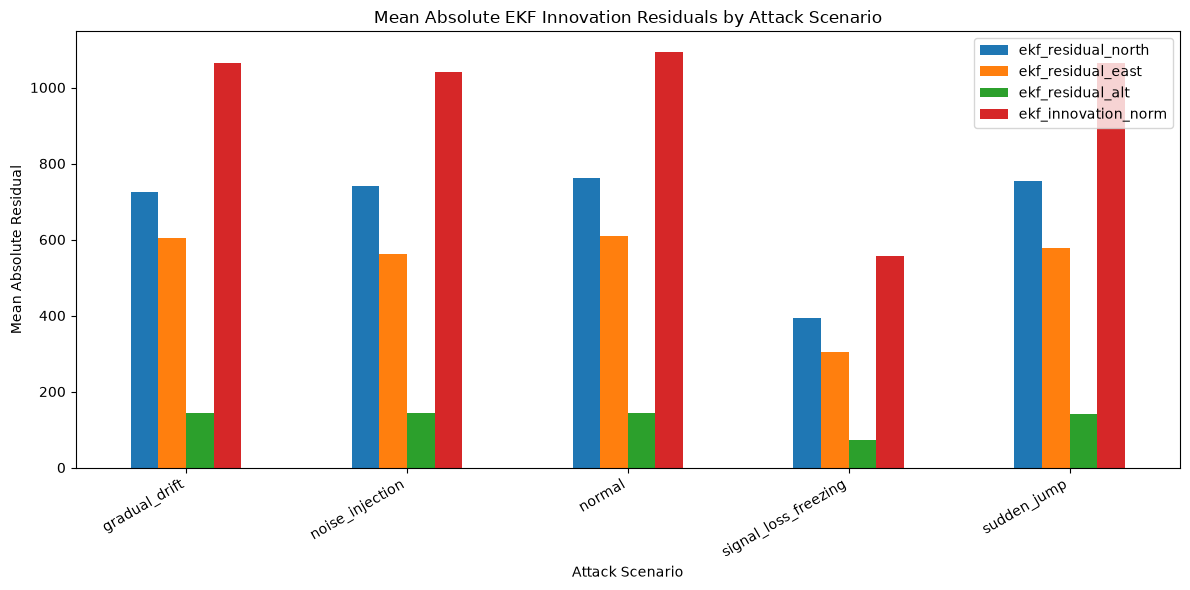

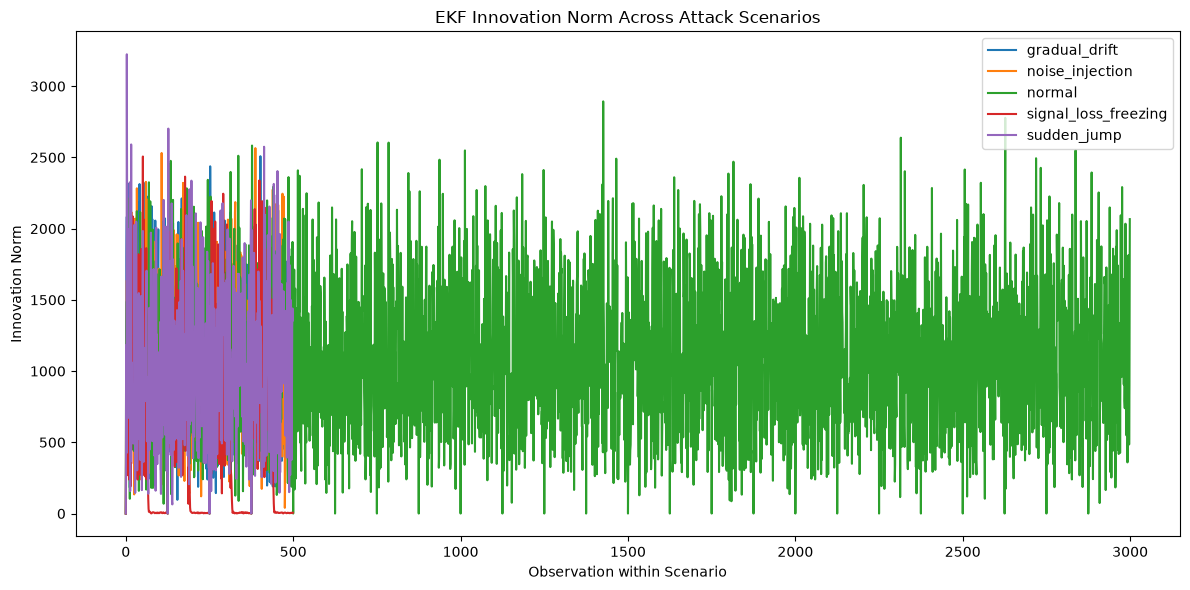


----------------------------------------------------------------------
PHYSICS-BASED EKF FEATURE VALIDATION
----------------------------------------------------------------------
ekf_residual_north        | mean=    0.2553 | std=  908.0907 | finite=PASS
ekf_residual_east         | mean=   -0.6346 | std=  719.2249 | finite=PASS
ekf_residual_alt          | mean=   -0.0081 | std=  173.1438 | finite=PASS
ekf_innovation_norm       | mean= 1028.4841 | std=  560.4578 | finite=PASS

SECTION 18 — EKF RESIDUAL ANALYSIS PASSED
Total observations                  : 5000
Independent flight logs              : 40
Samples per flight                   : 125
Five normal/attack scenarios         : PASS
Scenario-to-label consistency        : PASS
Residual numerical integrity         : PASS
Residual statistics by scenario      : PASS
Normal-vs-attack comparison          : PASS
Flight-level residual coverage       : PASS
Flight-level label consistency       : PASS
Physics-based EKF features available : PA

In [18]:
# ============================================================
# PHASE 1 — SECTION 18
# EKF RESIDUAL ANALYSIS BY ATTACK SCENARIO
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — SECTION 18")
print("EKF RESIDUAL ANALYSIS BY ATTACK SCENARIO")
print("=" * 70)


# ------------------------------------------------------------
# 1. Required columns
# ------------------------------------------------------------

REQUIRED_COLUMNS = [
    "flight_id",
    "timestamp",
    "attack_label",
    "scenario",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_innovation_norm"
]

missing_columns = [
    col
    for col in REQUIRED_COLUMNS
    if col not in ekf_output.columns
]

print("\n--- Required-column validation ---")
print("Missing required columns:", missing_columns)

assert len(missing_columns) == 0, (
    f"Section 18 failed. Missing columns: {missing_columns}"
)


# ------------------------------------------------------------
# 2. Expected scenario definitions
# ------------------------------------------------------------

EXPECTED_SCENARIO_LABELS = {
    "normal": 0,
    "gradual_drift": 1,
    "sudden_jump": 1,
    "noise_injection": 2,
    "signal_loss_freezing": 2
}

EXPECTED_SCENARIOS = sorted(
    EXPECTED_SCENARIO_LABELS.keys()
)

RESIDUAL_COLUMNS = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_innovation_norm"
]


# ------------------------------------------------------------
# 3. Scenario integrity
# ------------------------------------------------------------

observed_scenarios = sorted(
    ekf_output["scenario"]
    .dropna()
    .unique()
    .tolist()
)

print("\n--- Scenario integrity ---")

print("Observed scenarios:")
for scenario in observed_scenarios:
    print(f"  - {scenario}")

print("\nExpected scenarios:")
for scenario in EXPECTED_SCENARIOS:
    print(f"  - {scenario}")

assert observed_scenarios == EXPECTED_SCENARIOS, (
    "Observed scenarios do not match the expected scenarios."
)


# ------------------------------------------------------------
# 4. Scenario-to-label validation
# ------------------------------------------------------------

for scenario, expected_label in EXPECTED_SCENARIO_LABELS.items():

    labels = (
        ekf_output.loc[
            ekf_output["scenario"] == scenario,
            "attack_label"
        ]
        .dropna()
        .unique()
        .tolist()
    )

    assert labels == [expected_label], (
        f"Scenario '{scenario}' has incorrect label: {labels}"
    )

print("\nScenario-to-label consistency: PASS")


# ------------------------------------------------------------
# 5. Residual numerical integrity
# ------------------------------------------------------------

nan_counts = (
    ekf_output[RESIDUAL_COLUMNS]
    .isna()
    .sum()
)

infinite_counts = pd.Series(
    {
        col: np.isinf(
            ekf_output[col].to_numpy(dtype=float)
        ).sum()
        for col in RESIDUAL_COLUMNS
    }
)

print("\n--- Residual numerical integrity ---")

print("NaN counts:")
print(nan_counts)

print("\nInfinite-value counts:")
print(infinite_counts)

assert nan_counts.sum() == 0, (
    "NaN values detected in EKF residual columns."
)

assert infinite_counts.sum() == 0, (
    "Infinite values detected in EKF residual columns."
)

print("\nResidual numerical integrity: PASS")


# ------------------------------------------------------------
# 6. Residual statistics by scenario
# ------------------------------------------------------------

scenario_statistics = (
    ekf_output
    .groupby(
        ["attack_label", "scenario"],
        sort=False
    )[RESIDUAL_COLUMNS]
    .agg(["mean", "std", "median", "min", "max"])
)

print("\n" + "-" * 70)
print("RESIDUAL STATISTICS BY ATTACK SCENARIO")
print("-" * 70)

display(scenario_statistics)


# ------------------------------------------------------------
# 7. Compact residual summary
# ------------------------------------------------------------
# IMPORTANT:
# Use standard aggregation here rather than named aggregation
# because the residual columns are already explicitly selected.

compact_summary = (
    ekf_output
    .groupby(
        ["attack_label", "scenario"],
        sort=False
    )[RESIDUAL_COLUMNS]
    .agg([
        "mean",
        "std",
        "median",
        "max"
    ])
)

print("\n" + "-" * 70)
print("COMPACT RESIDUAL SUMMARY")
print("-" * 70)

display(compact_summary)


# ------------------------------------------------------------
# 8. Mean absolute residuals by scenario
# ------------------------------------------------------------

absolute_residual_summary = (
    ekf_output
    .assign(
        ekf_residual_north_abs=
            ekf_output["ekf_residual_north"].abs(),

        ekf_residual_east_abs=
            ekf_output["ekf_residual_east"].abs(),

        ekf_residual_alt_abs=
            ekf_output["ekf_residual_alt"].abs(),

        ekf_innovation_norm_abs=
            ekf_output["ekf_innovation_norm"].abs()
    )
    .groupby(
        "scenario",
        sort=False
    )[
        [
            "ekf_residual_north_abs",
            "ekf_residual_east_abs",
            "ekf_residual_alt_abs",
            "ekf_innovation_norm_abs"
        ]
    ]
    .mean()
)

absolute_residual_summary.columns = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_innovation_norm"
]

absolute_residual_summary = (
    absolute_residual_summary
    .reindex(EXPECTED_SCENARIOS)
)

print("\n" + "-" * 70)
print("MEAN ABSOLUTE EKF RESIDUALS BY SCENARIO")
print("-" * 70)

display(absolute_residual_summary)


# ------------------------------------------------------------
# 9. Normal-flight baseline
# ------------------------------------------------------------

normal_data = ekf_output[
    ekf_output["scenario"] == "normal"
].copy()

attack_data = ekf_output[
    ekf_output["attack_label"] != 0
].copy()

print("\n" + "-" * 70)
print("NORMAL-FLIGHT EKF RESIDUAL BASELINE")
print("-" * 70)

normal_baseline = (
    normal_data[RESIDUAL_COLUMNS]
    .agg([
        "mean",
        "std",
        "median",
        "min",
        "max"
    ])
)

display(normal_baseline)


# ------------------------------------------------------------
# 10. Attack-vs-normal comparison
# ------------------------------------------------------------

comparison_rows = []

for column in RESIDUAL_COLUMNS:

    normal_abs_mean = (
        normal_data[column]
        .abs()
        .mean()
    )

    attack_abs_mean = (
        attack_data[column]
        .abs()
        .mean()
    )

    normal_std = normal_data[column].std()
    attack_std = attack_data[column].std()

    mean_difference = (
        attack_abs_mean -
        normal_abs_mean
    )

    if normal_std != 0:
        std_ratio = attack_std / normal_std
    else:
        std_ratio = np.nan

    comparison_rows.append({
        "feature": column,
        "normal_abs_mean": normal_abs_mean,
        "attack_abs_mean": attack_abs_mean,
        "mean_difference": mean_difference,
        "normal_std": normal_std,
        "attack_std": attack_std,
        "std_ratio": std_ratio
    })

attack_comparison = pd.DataFrame(
    comparison_rows
).set_index("feature")

print("\n" + "-" * 70)
print("ATTACK VS NORMAL RESIDUAL COMPARISON")
print("-" * 70)

display(attack_comparison)


# ------------------------------------------------------------
# 11. Scenario observation counts
# ------------------------------------------------------------

scenario_counts = (
    ekf_output["scenario"]
    .value_counts()
    .reindex(EXPECTED_SCENARIOS)
)

print("\n" + "-" * 70)
print("OBSERVATIONS PER ATTACK SCENARIO")
print("-" * 70)

print(scenario_counts)

assert scenario_counts.notna().all()
assert (scenario_counts > 0).all()

print("\nScenario observation coverage: PASS")


# ------------------------------------------------------------
# 12. Flight-level residual coverage
# ------------------------------------------------------------

residual_counts_per_flight = (
    ekf_output
    .groupby("flight_id")[RESIDUAL_COLUMNS]
    .count()
)

print("\n" + "-" * 70)
print("RESIDUAL COUNTS PER FLIGHT")
print("-" * 70)

display(residual_counts_per_flight)


# Determine expected samples per flight dynamically
samples_per_flight = (
    ekf_output
    .groupby("flight_id")
    .size()
)

expected_samples_per_flight = (
    samples_per_flight
    .mode()
    .iloc[0]
)

assert (
    samples_per_flight
    .eq(expected_samples_per_flight)
    .all()
)

assert (
    residual_counts_per_flight
    .eq(expected_samples_per_flight)
    .all()
    .all()
)

print(
    f"\nSamples per flight: "
    f"{expected_samples_per_flight}"
)

print("Residual coverage per flight: PASS")


# ------------------------------------------------------------
# 13. Flight-level scenario summary
# ------------------------------------------------------------

flight_scenario_summary = (
    ekf_output
    .groupby(
        ["flight_id", "attack_label", "scenario"],
        sort=True
    )["ekf_innovation_norm"]
    .agg([
        "mean",
        "median",
        "std",
        "max"
    ])
)

print("\n" + "-" * 70)
print("FLIGHT-LEVEL INNOVATION SUMMARY")
print("-" * 70)

display(flight_scenario_summary)


# ------------------------------------------------------------
# 14. Check that each flight has one label
# ------------------------------------------------------------

labels_per_flight = (
    ekf_output
    .groupby("flight_id")["attack_label"]
    .nunique()
)

multiple_label_flights = (
    labels_per_flight > 1
).sum()

print("\nFlights containing multiple attack labels:")
print(multiple_label_flights)

assert multiple_label_flights == 0

print("Flight-level label consistency: PASS")


# ------------------------------------------------------------
# 15. Visualisation — mean absolute residuals
# ------------------------------------------------------------

plot_data = absolute_residual_summary.copy()

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "Mean Absolute EKF Innovation Residuals by Attack Scenario"
)

ax.set_xlabel("Attack Scenario")
ax.set_ylabel("Mean Absolute Residual")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. Visualisation — innovation norm
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

for scenario in EXPECTED_SCENARIOS:

    values = (
        ekf_output
        .loc[
            ekf_output["scenario"] == scenario,
            "ekf_innovation_norm"
        ]
        .reset_index(drop=True)
    )

    plt.plot(
        values,
        label=scenario
    )

plt.title(
    "EKF Innovation Norm Across Attack Scenarios"
)

plt.xlabel(
    "Observation within Scenario"
)

plt.ylabel(
    "Innovation Norm"
)

plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 17. Residual feature validation
# ------------------------------------------------------------

print("\n" + "-" * 70)
print("PHYSICS-BASED EKF FEATURE VALIDATION")
print("-" * 70)

for column in RESIDUAL_COLUMNS:

    values = (
        ekf_output[column]
        .to_numpy(dtype=float)
    )

    assert len(values) == len(ekf_output)
    assert np.isfinite(values).all()

    print(
        f"{column:25s} | "
        f"mean={values.mean():10.4f} | "
        f"std={values.std():10.4f} | "
        f"finite=PASS"
    )


# ------------------------------------------------------------
# 18. Final structural validation
# ------------------------------------------------------------

total_observations = len(ekf_output)

unique_flights = (
    ekf_output["flight_id"]
    .nunique()
)

assert total_observations == 5000

assert unique_flights == 40

assert (
    ekf_output
    .groupby("flight_id")
    .size()
    .eq(125)
    .all()
)

assert (
    ekf_output[RESIDUAL_COLUMNS]
    .isna()
    .sum()
    .sum()
    == 0
)

assert np.isfinite(
    ekf_output[RESIDUAL_COLUMNS]
    .to_numpy(dtype=float)
).all()


# ------------------------------------------------------------
# 19. Final Section 18 status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 18 — EKF RESIDUAL ANALYSIS PASSED")
print("=" * 70)

print(
    f"Total observations                  : {total_observations}"
)

print(
    f"Independent flight logs              : {unique_flights}"
)

print(
    f"Samples per flight                   : "
    f"{expected_samples_per_flight}"
)

print(
    "Five normal/attack scenarios         : PASS"
)

print(
    "Scenario-to-label consistency        : PASS"
)

print(
    "Residual numerical integrity         : PASS"
)

print(
    "Residual statistics by scenario      : PASS"
)

print(
    "Normal-vs-attack comparison          : PASS"
)

print(
    "Flight-level residual coverage       : PASS"
)

print(
    "Flight-level label consistency       : PASS"
)

print(
    "Physics-based EKF features available : PASS"
)

print("=" * 70)

In [19]:
# ============================================================
# PHASE 1 — SECTION 19
# RESIDUAL-ENHANCED FEATURE CONSTRUCTION
# ============================================================

print("=" * 70)
print("PHASE 1 — SECTION 19")
print("RESIDUAL-ENHANCED FEATURE CONSTRUCTION")
print("=" * 70)


# ------------------------------------------------------------
# 1. Source dataset
# ------------------------------------------------------------

final_dataset = ekf_output.copy()

print("\n--- Source dataset ---")
print("Rows:", len(final_dataset))
print("Columns:", len(final_dataset.columns))


# ------------------------------------------------------------
# 2. Define dataset structure
# ------------------------------------------------------------

PREDICTIVE_FEATURES = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

TARGET_COLUMN = "attack_label"

IDENTIFIER_COLUMNS = [
    "flight_id",
    "timestamp"
]

SCENARIO_COLUMN = "scenario"

EKF_FEATURES = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

# EKF diagnostic outputs are retained in the full EKF dataset
# but are NOT used as predictive model features.
DIAGNOSTIC_EKF_COLUMNS = [
    "ekf_pred_north",
    "ekf_pred_east",
    "ekf_pred_alt",
    "ekf_innovation_norm"
]

EXPECTED_SCENARIOS = {
    "normal",
    "gradual_drift",
    "sudden_jump",
    "noise_injection",
    "signal_loss_freezing"
}

EXPECTED_SCENARIO_LABELS = {
    "normal": NORMAL_LABEL,
    "gradual_drift": SPOOFING_LABEL,
    "sudden_jump": SPOOFING_LABEL,
    "noise_injection": JAMMING_LABEL,
    "signal_loss_freezing": JAMMING_LABEL
}


# ------------------------------------------------------------
# 3. Required-column validation
# ------------------------------------------------------------

required_columns = (
    IDENTIFIER_COLUMNS
    + [SCENARIO_COLUMN]
    + PREDICTIVE_FEATURES
    + [TARGET_COLUMN]
)

missing_columns = [
    column
    for column in required_columns
    if column not in final_dataset.columns
]

print("\n--- Required-column validation ---")
print("Missing required columns:", missing_columns)

assert len(missing_columns) == 0, (
    f"Missing required columns: {missing_columns}"
)


# ------------------------------------------------------------
# 4. Construct residual-enhanced feature dataset
# ------------------------------------------------------------

FINAL_FEATURE_COLUMNS = (
    IDENTIFIER_COLUMNS
    + [SCENARIO_COLUMN]
    + PREDICTIVE_FEATURES
    + [TARGET_COLUMN]
)

feature_dataset = (
    final_dataset[FINAL_FEATURE_COLUMNS]
    .copy()
)


# ------------------------------------------------------------
# 5. Timestamp conversion and chronological ordering
# ------------------------------------------------------------

feature_dataset["timestamp"] = pd.to_datetime(
    feature_dataset["timestamp"],
    errors="raise"
)

feature_dataset = (
    feature_dataset
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

print("\n--- Dataset ordering ---")
print("Sorted by flight_id and timestamp: PASS")


# ------------------------------------------------------------
# 6. Predictive feature validation
# ------------------------------------------------------------

print("\n--- Predictive feature set ---")

for index, feature in enumerate(
    PREDICTIVE_FEATURES,
    start=1
):
    print(
        f"{index:02d}. {feature}"
    )

print(
    "\nNumber of predictive features:",
    len(PREDICTIVE_FEATURES)
)

assert len(PREDICTIVE_FEATURES) == 13


# ------------------------------------------------------------
# 7. EKF physics-based feature validation
# ------------------------------------------------------------

print("\n--- EKF physics-based features ---")

for feature in EKF_FEATURES:

    present = feature in PREDICTIVE_FEATURES

    print(
        f"{feature}: {present}"
    )

assert all(
    feature in PREDICTIVE_FEATURES
    for feature in EKF_FEATURES
)

assert len(EKF_FEATURES) == 3


# ------------------------------------------------------------
# 8. Diagnostic EKF columns must not be predictive features
# ------------------------------------------------------------

diagnostic_features_used = [
    column
    for column in DIAGNOSTIC_EKF_COLUMNS
    if column in PREDICTIVE_FEATURES
]

print(
    "\n--- Diagnostic EKF feature exclusion ---"
)

print(
    "Diagnostic columns included as predictive features:",
    diagnostic_features_used
)

assert len(diagnostic_features_used) == 0


# ------------------------------------------------------------
# 9. Numeric feature validation
# ------------------------------------------------------------

non_numeric_features = [
    feature
    for feature in PREDICTIVE_FEATURES
    if not pd.api.types.is_numeric_dtype(
        feature_dataset[feature]
    )
]

print(
    "\n--- Predictive feature data types ---"
)

print(
    "Non-numeric predictive features:",
    non_numeric_features
)

assert len(non_numeric_features) == 0


# ------------------------------------------------------------
# 10. Missing and infinite value validation
# ------------------------------------------------------------

feature_values = (
    feature_dataset[
        PREDICTIVE_FEATURES
    ]
    .to_numpy(dtype=float)
)

nan_count = int(
    np.isnan(feature_values).sum()
)

infinite_count = int(
    np.isinf(feature_values).sum()
)

print(
    "\n--- Feature numerical integrity ---"
)

print(
    "NaN feature values:",
    nan_count
)

print(
    "Infinite feature values:",
    infinite_count
)

assert nan_count == 0
assert infinite_count == 0


# ------------------------------------------------------------
# 11. Final dataset dimensions
# ------------------------------------------------------------

print(
    "\n--- Final feature dataset dimensions ---"
)

print(
    "Total observations:",
    len(feature_dataset)
)

print(
    "Total columns:",
    len(feature_dataset.columns)
)

print(
    "Identifier columns:",
    len(IDENTIFIER_COLUMNS)
)

print(
    "Scenario column:",
    SCENARIO_COLUMN
)

print(
    "Predictive features:",
    len(PREDICTIVE_FEATURES)
)

print(
    "Target column:",
    TARGET_COLUMN
)

expected_final_columns = (
    len(IDENTIFIER_COLUMNS)
    + 1
    + len(PREDICTIVE_FEATURES)
    + 1
)

assert (
    len(feature_dataset.columns)
    == expected_final_columns
)


# ------------------------------------------------------------
# 12. Target distribution
# ------------------------------------------------------------

print(
    "\n--- Target distribution ---"
)

target_distribution = (
    feature_dataset[
        TARGET_COLUMN
    ]
    .value_counts()
    .sort_index()
)

print(
    target_distribution
)

expected_target_counts = {
    NORMAL_LABEL: normal_samples,
    SPOOFING_LABEL: spoofing_samples,
    JAMMING_LABEL: jamming_samples
}

for label, expected_count in (
    expected_target_counts.items()
):

    actual_count = int(
        target_distribution.get(
            label,
            0
        )
    )

    print(
        f"Class {label}: "
        f"{actual_count} / "
        f"{expected_count}"
    )

    assert (
        actual_count == expected_count
    )


# ------------------------------------------------------------
# 13. Scenario distribution
# ------------------------------------------------------------

print(
    "\n--- Attack scenario distribution ---"
)

scenario_distribution = (
    feature_dataset[
        SCENARIO_COLUMN
    ]
    .value_counts()
    .sort_index()
)

print(
    scenario_distribution
)

expected_scenario_counts = {
    "normal": normal_samples,
    "gradual_drift":
        GRADUAL_DRIFT_LOGS * SAMPLES_PER_FLIGHT,
    "sudden_jump":
        SUDDEN_JUMP_LOGS * SAMPLES_PER_FLIGHT,
    "noise_injection":
        NOISE_INJECTION_LOGS * SAMPLES_PER_FLIGHT,
    "signal_loss_freezing":
        SIGNAL_LOSS_LOGS * SAMPLES_PER_FLIGHT
}

for scenario, expected_count in (
    expected_scenario_counts.items()
):

    actual_count = int(
        scenario_distribution.get(
            scenario,
            0
        )
    )

    print(
        f"{scenario}: "
        f"{actual_count} / "
        f"{expected_count}"
    )

    assert (
        actual_count == expected_count
    )


# ------------------------------------------------------------
# 14. Scenario integrity
# ------------------------------------------------------------

observed_scenarios = set(
    feature_dataset[
        SCENARIO_COLUMN
    ].unique()
)

print(
    "\n--- Scenario integrity ---"
)

print(
    "Observed scenarios:"
)

for scenario in sorted(observed_scenarios):
    print(
        f" - {scenario}"
    )

print(
    "\nExpected scenarios:"
)

for scenario in sorted(EXPECTED_SCENARIOS):
    print(
        f" - {scenario}"
    )

assert (
    observed_scenarios
    == EXPECTED_SCENARIOS
)


# ------------------------------------------------------------
# 15. Scenario-to-label consistency
# ------------------------------------------------------------

scenario_label_pairs = (
    feature_dataset[
        [
            SCENARIO_COLUMN,
            TARGET_COLUMN
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            SCENARIO_COLUMN,
            TARGET_COLUMN
        ]
    )
)

print(
    "\n--- Scenario / label mapping ---"
)

print(
    scenario_label_pairs
)

for _, row in (
    scenario_label_pairs.iterrows()
):

    scenario = row[
        SCENARIO_COLUMN
    ]

    label = int(
        row[TARGET_COLUMN]
    )

    assert scenario in EXPECTED_SCENARIO_LABELS

    assert (
        EXPECTED_SCENARIO_LABELS[
            scenario
        ]
        == label
    )

expected_mapping_pairs = {
    (
        scenario,
        label
    )
    for scenario, label
    in EXPECTED_SCENARIO_LABELS.items()
}

observed_mapping_pairs = {
    (
        row[SCENARIO_COLUMN],
        int(row[TARGET_COLUMN])
    )
    for _, row
    in scenario_label_pairs.iterrows()
}

assert (
    observed_mapping_pairs
    == expected_mapping_pairs
)


# ------------------------------------------------------------
# 16. Flight-level structure
# ------------------------------------------------------------

flight_counts = (
    feature_dataset
    .groupby("flight_id")
    .size()
)

unique_flights = (
    feature_dataset[
        "flight_id"
    ].nunique()
)

print(
    "\n--- Flight-level structure ---"
)

print(
    "Unique flight IDs:",
    unique_flights
)

print(
    "\nSamples per flight:"
)

print(
    flight_counts
    .value_counts()
    .sort_index()
)

assert (
    unique_flights
    == N_FLIGHT_LOGS
)

assert (
    flight_counts
    .eq(SAMPLES_PER_FLIGHT)
    .all()
)


# ------------------------------------------------------------
# 17. One scenario and one label per flight
# ------------------------------------------------------------

flight_scenario_counts = (
    feature_dataset
    .groupby("flight_id")[
        SCENARIO_COLUMN
    ]
    .nunique()
)

flight_label_counts = (
    feature_dataset
    .groupby("flight_id")[
        TARGET_COLUMN
    ]
    .nunique()
)

multi_scenario_flights = int(
    (flight_scenario_counts > 1).sum()
)

multi_label_flights = int(
    (flight_label_counts > 1).sum()
)

print(
    "\n--- Flight-level label/scenario consistency ---"
)

print(
    "Flights containing multiple scenarios:",
    multi_scenario_flights
)

print(
    "Flights containing multiple attack labels:",
    multi_label_flights
)

assert multi_scenario_flights == 0
assert multi_label_flights == 0


# ------------------------------------------------------------
# 18. Chronological integrity within every flight
# ------------------------------------------------------------

chronological_status = (
    feature_dataset
    .groupby("flight_id")[
        "timestamp"
    ]
    .apply(
        lambda values:
        values.is_monotonic_increasing
    )
)

print(
    "\n--- Chronological integrity ---"
)

print(
    "All flights chronologically ordered:",
    chronological_status.all()
)

assert chronological_status.all()


# ------------------------------------------------------------
# 19. Sampling interval validation
# ------------------------------------------------------------

intervals = (
    feature_dataset
    .groupby("flight_id")[
        "timestamp"
    ]
    .diff()
    .dt.total_seconds()
    .dropna()
)

unique_intervals = (
    intervals
    .value_counts()
    .sort_index()
)

print(
    "\nSampling interval distribution:"
)

print(
    unique_intervals
)

# The Phase 1 flight logs are generated at 1-second cadence.
assert (
    len(unique_intervals) == 1
)

assert (
    float(unique_intervals.index[0])
    == 1.0
)


# ------------------------------------------------------------
# 20. Duplicate flight/timestamp validation
# ------------------------------------------------------------

duplicate_pairs = int(
    feature_dataset
    .duplicated(
        subset=[
            "flight_id",
            "timestamp"
        ]
    )
    .sum()
)

print(
    "\nDuplicate flight_id + timestamp pairs:",
    duplicate_pairs
)

assert duplicate_pairs == 0


# ------------------------------------------------------------
# 21. Timestamp validity
# ------------------------------------------------------------

missing_timestamps = int(
    feature_dataset[
        "timestamp"
    ].isna().sum()
)

print(
    "Missing timestamps:",
    missing_timestamps
)

assert missing_timestamps == 0


# ------------------------------------------------------------
# 22. Final feature coverage per flight
# ------------------------------------------------------------

feature_coverage = (
    feature_dataset
    .groupby("flight_id")[
        PREDICTIVE_FEATURES
    ]
    .count()
)

expected_feature_count = (
    SAMPLES_PER_FLIGHT
)

coverage_failures = (
    feature_coverage
    != expected_feature_count
).any().any()

print(
    "\n--- Predictive feature coverage ---"
)

print(
    "Expected observations per flight:",
    expected_feature_count
)

print(
    "Feature coverage failures:",
    int(coverage_failures)
)

assert not coverage_failures


# ------------------------------------------------------------
# 23. Final scenario-level flight counts
# ------------------------------------------------------------

flight_scenario_table = (
    feature_dataset[
        [
            "flight_id",
            SCENARIO_COLUMN,
            TARGET_COLUMN
        ]
    ]
    .drop_duplicates()
    .sort_values("flight_id")
)

scenario_flight_counts = (
    flight_scenario_table[
        SCENARIO_COLUMN
    ]
    .value_counts()
    .sort_index()
)

print(
    "\n--- Independent flight logs by scenario ---"
)

print(
    scenario_flight_counts
)


# ------------------------------------------------------------
# Expected number of independent flight logs
# ------------------------------------------------------------

EXPECTED_FLIGHT_COUNTS = {
    "normal": int(
        normal_samples / SAMPLES_PER_FLIGHT
    ),
    "gradual_drift": GRADUAL_DRIFT_LOGS,
    "sudden_jump": SUDDEN_JUMP_LOGS,
    "noise_injection": NOISE_INJECTION_LOGS,
    "signal_loss_freezing": SIGNAL_LOSS_LOGS
}

print(
    "\n--- Expected vs observed flight logs ---"
)

for scenario, expected_count in (
    EXPECTED_FLIGHT_COUNTS.items()
):

    actual_count = int(
        scenario_flight_counts.get(
            scenario,
            0
        )
    )

    print(
        f"{scenario:25s}: "
        f"{actual_count} / {expected_count}"
    )

    assert (
        actual_count == expected_count
    )


# ------------------------------------------------------------
# Verify total independent flight logs
# ------------------------------------------------------------

total_flight_logs = int(
    scenario_flight_counts.sum()
)

print(
    "\nTotal independent flight logs:",
    total_flight_logs
)

assert (
    total_flight_logs == N_FLIGHT_LOGS
)


# ------------------------------------------------------------
# 24. Final dataset preview
# ------------------------------------------------------------

print(
    "\n--- Final residual-enhanced dataset preview ---"
)

display(
    feature_dataset.head(10)
)

print(
    "\nFinal columns:"
)

for index, column in enumerate(
    feature_dataset.columns,
    start=1
):
    print(
        f"{index:02d}. {column}"
    )


# ------------------------------------------------------------
# 25. Final Section 19 validation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "SECTION 19 — RESIDUAL-ENHANCED "
    "FEATURE CONSTRUCTION PASSED"
)
print("=" * 70)

print(
    "Total observations             :",
    len(feature_dataset)
)

print(
    "Independent flight logs        :",
    unique_flights
)

print(
    "Samples per flight             :",
    SAMPLES_PER_FLIGHT
)

print(
    "Predictive features            :",
    len(PREDICTIVE_FEATURES)
)

print(
    "EKF residual features          :",
    len(EKF_FEATURES)
)

print(
    f"Normal                         : "
    f"{normal_samples} (60%)"
)

print(
    f"Spoofing                       : "
    f"{spoofing_samples} (20%)"
)

print(
    f"Jamming                        : "
    f"{jamming_samples} (20%)"
)

print(
    "Gradual drift observations     :",
    expected_scenario_counts[
        "gradual_drift"
    ]
)

print(
    "Sudden jump observations       :",
    expected_scenario_counts[
        "sudden_jump"
    ]
)

print(
    "Noise injection observations  :",
    expected_scenario_counts[
        "noise_injection"
    ]
)

print(
    "Signal loss/freezing obs.      :",
    expected_scenario_counts[
        "signal_loss_freezing"
    ]
)

print(
    "Missing feature values         :",
    nan_count
)

print(
    "Infinite feature values        :",
    infinite_count
)

print(
    "Flight-level scenario consistency : PASS"
)

print(
    "Flight-level label consistency    : PASS"
)

print(
    "Temporal integrity                : PASS"
)

print(
    "Sampling interval integrity       : PASS"
)

print(
    "Duplicate flight/timestamp check  : PASS"
)

print(
    "EKF residual feature inclusion    : PASS"
)

print(
    "Diagnostic EKF exclusion          : PASS"
)

print(
    "Feature construction               : PASS"
)

print("=" * 70)

PHASE 1 — SECTION 19
RESIDUAL-ENHANCED FEATURE CONSTRUCTION

--- Source dataset ---
Rows: 5000
Columns: 36

--- Required-column validation ---
Missing required columns: []

--- Dataset ordering ---
Sorted by flight_id and timestamp: PASS

--- Predictive feature set ---
01. latitude
02. longitude
03. altitude
04. speed
05. imu_acc_x
06. imu_acc_y
07. imu_acc_z
08. imu_gyro_x
09. imu_gyro_y
10. imu_gyro_z
11. ekf_residual_north
12. ekf_residual_east
13. ekf_residual_alt

Number of predictive features: 13

--- EKF physics-based features ---
ekf_residual_north: True
ekf_residual_east: True
ekf_residual_alt: True

--- Diagnostic EKF feature exclusion ---
Diagnostic columns included as predictive features: []

--- Predictive feature data types ---
Non-numeric predictive features: []

--- Feature numerical integrity ---
NaN feature values: 0
Infinite feature values: 0

--- Final feature dataset dimensions ---
Total observations: 5000
Total columns: 17
Identifier columns: 2
Scenario column: sc

,flight_id,timestamp,scenario,latitude,longitude,altitude,speed,imu_acc_x,imu_acc_y,imu_acc_z,imu_gyro_x,imu_gyro_y,imu_gyro_z,ekf_residual_north,ekf_residual_east,ekf_residual_alt,attack_label
0,FLIGHT_01,2023-01-01 00:00:00,normal,37.772391,-122.421527,218.138368,26.180914,-0.001979,1.379990,-2.445775,49.732045,39.381347,-72.391665,0.000000,0.000000,0.000000,0
1,FLIGHT_01,2023-01-01 00:00:01,normal,37.783914,-122.419931,199.810443,17.362926,1.480481,-1.892928,-2.635478,-14.654717,-165.994752,-145.865601,1280.612690,141.225627,-17.010186,0
2,FLIGHT_01,2023-01-01 00:00:02,normal,37.779540,-122.412309,129.269261,9.886640,0.376001,-0.920162,0.625152,167.219469,40.413723,-134.510679,-1300.661003,581.473069,-62.906074,0
3,FLIGHT_01,2023-01-01 00:00:03,normal,37.776873,-122.422600,323.270002,23.416045,-2.500185,0.979684,2.796698,-101.167758,-147.719302,-114.958394,-867.736476,-1188.995820,224.770314,0
4,FLIGHT_01,2023-01-01 00:00:04,normal,37.768020,-122.412007,264.480872,15.466953,-1.886519,-0.107464,0.016328,31.628310,75.723926,-106.684800,-1235.017223,638.092719,-14.176564,0
5,FLIGHT_01,2023-01-01 00:00:05,normal,37.768020,-122.427637,439.565447,19.865687,-1.684031,1.431426,-2.690909,72.075605,-39.572047,-92.785749,-18.845130,-1331.036040,146.317449,0
6,FLIGHT_01,2023-01-01 00:00:06,normal,37.766062,-122.413864,64.449311,7.681632,-1.452814,2.767247,-1.672688,117.203216,121.570737,-88.034390,192.296807,987.134352,-376.701940,0
7,FLIGHT_01,2023-01-01 00:00:07,normal,37.782224,-122.412449,339.740567,20.789600,0.392420,-2.300720,-1.531243,-33.490429,159.310528,-15.942116,2148.587044,384.142251,151.561431,0
8,FLIGHT_01,2023-01-01 00:00:08,normal,37.776922,-122.425764,393.326995,14.338762,0.023795,1.257406,-0.972857,67.291887,-29.840277,3.446349,-501.141383,-1274.222311,155.241466,0
9,FLIGHT_01,2023-01-01 00:00:09,normal,37.779061,-122.420793,391.768956,13.354744,-1.781040,-1.617935,-2.738380,-70.847470,-14.200094,-68.803485,-268.165066,182.687328,12.887533,0



Final columns:
01. flight_id
02. timestamp
03. scenario
04. latitude
05. longitude
06. altitude
07. speed
08. imu_acc_x
09. imu_acc_y
10. imu_acc_z
11. imu_gyro_x
12. imu_gyro_y
13. imu_gyro_z
14. ekf_residual_north
15. ekf_residual_east
16. ekf_residual_alt
17. attack_label

SECTION 19 — RESIDUAL-ENHANCED FEATURE CONSTRUCTION PASSED
Total observations             : 5000
Independent flight logs        : 40
Samples per flight             : 125
Predictive features            : 13
EKF residual features          : 3
Normal                         : 3000 (60%)
Spoofing                       : 1000 (20%)
Jamming                        : 1000 (20%)
Gradual drift observations     : 500
Sudden jump observations       : 500
Noise injection observations  : 500
Signal loss/freezing obs.      : 500
Missing feature values         : 0
Infinite feature values        : 0
Flight-level scenario consistency : PASS
Flight-level label consistency    : PASS
Temporal integrity                : PASS
Sampling 

In [20]:
# ============================================================
# PHASE 1 — SECTION 20
# FINAL DATASET VALIDATION, MANIFEST & EXPORT
# ============================================================
from pathlib import Path
import json
print("=" * 70)
print("PHASE 1 — SECTION 20")
print("FINAL DATASET VALIDATION, MANIFEST & EXPORT")
print("=" * 70)

# ------------------------------------------------------------
# Final dataset
# ------------------------------------------------------------

phase1_final_dataset = (
    feature_dataset.copy()
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Expected final columns
# ------------------------------------------------------------

EXPECTED_FINAL_COLUMNS = [
    "flight_id",
    "timestamp",
    "scenario",
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "attack_label"
]

print(
    "\n--- Final column validation ---"
)

print(
    "Expected columns:",
    len(EXPECTED_FINAL_COLUMNS)
)

print(
    "Actual columns:",
    len(phase1_final_dataset.columns)
)

missing_columns = [
    col
    for col in EXPECTED_FINAL_COLUMNS
    if col not in phase1_final_dataset.columns
]

unexpected_columns = [
    col
    for col in phase1_final_dataset.columns
    if col not in EXPECTED_FINAL_COLUMNS
]

print(
    "Missing columns:",
    missing_columns
)

print(
    "Unexpected columns:",
    unexpected_columns
)

assert (
    len(missing_columns)
    == 0
)

assert (
    len(unexpected_columns)
    == 0
)

phase1_final_dataset = (
    phase1_final_dataset[
        EXPECTED_FINAL_COLUMNS
    ]
)

# ------------------------------------------------------------
# Final dimensions
# ------------------------------------------------------------

total_rows = (
    len(phase1_final_dataset)
)

total_flights = (
    phase1_final_dataset[
        "flight_id"
    ].nunique()
)

samples_per_flight = (
    phase1_final_dataset
    .groupby("flight_id")
    .size()
)

print(
    "\n--- Final dimensions ---"
)

print(
    "Total observations:",
    total_rows
)

print(
    "Unique flight logs:",
    total_flights
)

print(
    "Samples per flight:"
)

print(
    samples_per_flight
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Target distribution
# ------------------------------------------------------------

print(
    "\n--- Final target distribution ---"
)

final_target_counts = (
    phase1_final_dataset[
        "attack_label"
    ]
    .value_counts()
    .sort_index()
)

final_target_percentages = (
    final_target_counts
    / total_rows
    * 100
)

final_target_summary = pd.DataFrame({
    "samples":
        final_target_counts,
    "percentage":
        final_target_percentages
})

display(
    final_target_summary
)

assert (
    final_target_counts.to_dict()
    == {
        NORMAL_LABEL:
            normal_samples,
        SPOOFING_LABEL:
            spoofing_samples,
        JAMMING_LABEL:
            jamming_samples
    }
)

# ------------------------------------------------------------
# Scenario distribution
# ------------------------------------------------------------

print(
    "\n--- Final attack-scenario distribution ---"
)

final_scenario_counts = (
    phase1_final_dataset[
        "scenario"
    ]
    .value_counts()
    .sort_index()
)

print(
    final_scenario_counts
)

assert (
    final_scenario_counts.to_dict()
    == expected_scenario_counts
)

# ------------------------------------------------------------
# Flight-level class allocation
# ------------------------------------------------------------

final_flight_summary = (
    phase1_final_dataset
    .groupby(
        [
            "flight_id",
            "attack_label",
            "scenario"
        ]
    )
    .size()
    .reset_index(
        name="samples"
    )
)

print(
    "\n--- Final flight-level allocation ---"
)

display(
    final_flight_summary
)

assert (
    len(final_flight_summary)
    == N_FLIGHT_LOGS
)

assert (
    final_flight_summary[
        "samples"
    ]
    .eq(SAMPLES_PER_FLIGHT)
    .all()
)

# ------------------------------------------------------------
# Chronological validation
# ------------------------------------------------------------

print(
    "\n--- Final chronological validation ---"
)

chronological_check = (
    phase1_final_dataset
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

print(
    "All flights chronological:",
    chronological_check.all()
)

assert chronological_check.all()

# ------------------------------------------------------------
# Sampling interval
# ------------------------------------------------------------

intervals = (
    phase1_final_dataset
    .groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(
    "\nSampling interval distribution:"
)

print(
    intervals
    .value_counts()
    .sort_index()
)

assert (
    set(intervals.unique())
    == {1.0}
)

# ------------------------------------------------------------
# Duplicate flight/timestamp pairs
# ------------------------------------------------------------

duplicate_count = (
    phase1_final_dataset
    .duplicated(
        subset=[
            "flight_id",
            "timestamp"
        ]
    )
    .sum()
)

print(
    "\nDuplicate flight_id + timestamp pairs:",
    duplicate_count
)

assert duplicate_count == 0

# ------------------------------------------------------------
# Missing predictive values
# ------------------------------------------------------------

predictive_values = (
    phase1_final_dataset[
        PREDICTIVE_FEATURES
    ]
    .to_numpy(dtype=float)
)

missing_predictive_values = (
    np.isnan(
        predictive_values
    ).sum()
)

infinite_predictive_values = (
    np.isinf(
        predictive_values
    ).sum()
)

print(
    "\nMissing predictive values:",
    missing_predictive_values
)

print(
    "Infinite predictive values:",
    infinite_predictive_values
)

assert (
    missing_predictive_values
    == 0
)

assert (
    infinite_predictive_values
    == 0
)

# ------------------------------------------------------------
# Flight-level label consistency
# ------------------------------------------------------------

flight_label_counts = (
    phase1_final_dataset
    .groupby("flight_id")[
        "attack_label"
    ]
    .nunique()
)

multi_label_flights = (
    flight_label_counts > 1
).sum()

print(
    "\nFlights containing multiple labels:",
    multi_label_flights
)

assert multi_label_flights == 0

# ------------------------------------------------------------
# Flight-level scenario consistency
# ------------------------------------------------------------

flight_scenario_counts = (
    phase1_final_dataset
    .groupby("flight_id")[
        "scenario"
    ]
    .nunique()
)

multi_scenario_flights = (
    flight_scenario_counts > 1
).sum()

print(
    "Flights containing multiple scenarios:",
    multi_scenario_flights
)

assert multi_scenario_flights == 0

# ------------------------------------------------------------
# Scenario / label mapping
# ------------------------------------------------------------

EXPECTED_SCENARIO_LABELS = {
    "normal": NORMAL_LABEL,
    "gradual_drift": SPOOFING_LABEL,
    "sudden_jump": SPOOFING_LABEL,
    "noise_injection": JAMMING_LABEL,
    "signal_loss_freezing": JAMMING_LABEL
}

scenario_label_mapping = (
    phase1_final_dataset[
        [
            "scenario",
            "attack_label"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "scenario",
            "attack_label"
        ]
    )
)

print(
    "\n--- Scenario / label mapping ---"
)

display(
    scenario_label_mapping
)

assert (
    len(scenario_label_mapping)
    == len(
        EXPECTED_SCENARIO_LABELS
    )
)

for _, row in (
    scenario_label_mapping.iterrows()
):

    scenario = row[
        "scenario"
    ]

    label = int(
        row["attack_label"]
    )

    assert (
        EXPECTED_SCENARIO_LABELS[
            scenario
        ]
        == label
    )

# ------------------------------------------------------------
# EKF residual validation
# ------------------------------------------------------------

EKF_RESIDUAL_COLUMNS = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

print(
    "\n--- EKF residual validation ---"
)

for column in EKF_RESIDUAL_COLUMNS:

    mean_value = (
        phase1_final_dataset[
            column
        ].mean()
    )

    std_value = (
        phase1_final_dataset[
            column
        ].std()
    )

    print(
        f"{column}: "
        f"mean={mean_value:.4f}, "
        f"std={std_value:.4f}"
    )

    assert (
        phase1_final_dataset[
            column
        ]
        .notna()
        .all()
    )

# ------------------------------------------------------------
# Final dataset ordering
# ------------------------------------------------------------

phase1_final_dataset = (
    phase1_final_dataset[
        EXPECTED_FINAL_COLUMNS
    ]
    .sort_values(
        [
            "flight_id",
            "timestamp"
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Export directory
# ------------------------------------------------------------

output_dir = Path(
    "phase1_outputs"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

dataset_path = (
    output_dir
    / "phase1_final_uav_ekf_dataset.csv"
)

manifest_path = (
    output_dir
    / "phase1_dataset_manifest.json"
)

# ------------------------------------------------------------
# Export dataset
# ------------------------------------------------------------

phase1_final_dataset.to_csv(
    dataset_path,
    index=False
)

# ------------------------------------------------------------
# Dataset manifest
# ------------------------------------------------------------

manifest = {

    "phase":
        "Phase 1",

    "dataset_name":
        "Final UAV EKF Attack Dataset",

    "total_observations":
        int(total_rows),

    "total_flight_logs":
        int(total_flights),

    "samples_per_flight":
        int(SAMPLES_PER_FLIGHT),

    "sampling_interval_seconds":
        1,

    "flight_log_structure": {
        "normal_flights":
            int(NORMAL_FLIGHT_LOGS),
        "spoofing_flights":
            int(SPOOFING_FLIGHT_LOGS),
        "jamming_flights":
            int(JAMMING_FLIGHT_LOGS)
    },

    "class_distribution": {
        "normal":
            int(normal_samples),
        "spoofing":
            int(spoofing_samples),
        "jamming":
            int(jamming_samples)
    },

    "class_percentages": {
        "normal": 60.0,
        "spoofing": 20.0,
        "jamming": 20.0
    },

    "spoofing_scenarios": {
        "gradual_drift":
            int(
                GRADUAL_DRIFT_LOGS
                * SAMPLES_PER_FLIGHT
            ),
        "sudden_jump":
            int(
                SUDDEN_JUMP_LOGS
                * SAMPLES_PER_FLIGHT
            )
    },

    "jamming_scenarios": {
        "noise_injection":
            int(
                NOISE_INJECTION_LOGS
                * SAMPLES_PER_FLIGHT
            ),
        "signal_loss_freezing":
            int(
                SIGNAL_LOSS_LOGS
                * SAMPLES_PER_FLIGHT
            )
    },

    "predictive_features":
        PREDICTIVE_FEATURES,

    "ekf_residual_features":
        EKF_RESIDUAL_COLUMNS,

    "identifier_columns": [
        "flight_id",
        "timestamp"
    ],

    "metadata_column":
        "scenario",

    "target_column":
        "attack_label",

    "missing_values":
        int(missing_predictive_values),

    "infinite_values":
        int(infinite_predictive_values),

    "duplicate_flight_timestamp_pairs":
        int(duplicate_count),

    "flight_level_label_consistency":
        True,

    "chronological_integrity":
        True,

    "one_second_sampling":
        True
}

with open(
    manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        manifest,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Export confirmation
# ------------------------------------------------------------

print(
    "\n--- Export confirmation ---"
)

print(
    "Dataset saved to:",
    dataset_path.resolve()
)

print(
    "Manifest saved to:",
    manifest_path.resolve()
)

print(
    "Dataset file exists:",
    dataset_path.exists()
)

print(
    "Manifest file exists:",
    manifest_path.exists()
)

assert dataset_path.exists()
assert manifest_path.exists()

# ------------------------------------------------------------
# Reload verification
# ------------------------------------------------------------

reloaded_dataset = pd.read_csv(
    dataset_path,
    parse_dates=[
        "timestamp"
    ]
)

print(
    "\n--- Reload verification ---"
)

print(
    "Reloaded shape:",
    reloaded_dataset.shape
)

print(
    "Reloaded flights:",
    reloaded_dataset[
        "flight_id"
    ].nunique()
)

assert (
    reloaded_dataset.shape
    == (
        TOTAL_PLANNED_SAMPLES,
        len(EXPECTED_FINAL_COLUMNS)
    )
)

assert (
    reloaded_dataset[
        "flight_id"
    ].nunique()
    == N_FLIGHT_LOGS
)

assert (
    reloaded_dataset[
        "attack_label"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    == {
        NORMAL_LABEL:
            normal_samples,
        SPOOFING_LABEL:
            spoofing_samples,
        JAMMING_LABEL:
            jamming_samples
    }
)

# ------------------------------------------------------------
# FINAL PHASE 1 STATUS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "SECTION 20 — FINAL PHASE 1 VALIDATION PASSED"
)
print("=" * 70)

print(
    f"Final dataset observations       : "
    f"{total_rows}"
)

print(
    f"Independent flight logs          : "
    f"{total_flights}"
)

print(
    f"Samples per flight               : "
    f"{SAMPLES_PER_FLIGHT}"
)

print(
    f"Normal                           : "
    f"{normal_samples} (60%)"
)

print(
    f"Spoofing                         : "
    f"{spoofing_samples} (20%)"
)

print(
    f"Jamming                          : "
    f"{jamming_samples} (20%)"
)

print(
    f"Gradual drift                    : "
    f"{GRADUAL_DRIFT_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    f"Sudden jump                      : "
    f"{SUDDEN_JUMP_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    f"Noise injection                  : "
    f"{NOISE_INJECTION_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    f"Signal loss/freezing             : "
    f"{SIGNAL_LOSS_LOGS * SAMPLES_PER_FLIGHT}"
)

print(
    f"Predictive features              : "
    f"{len(PREDICTIVE_FEATURES)}"
)

print(
    f"EKF residual features            : "
    f"{len(EKF_RESIDUAL_COLUMNS)}"
)

print(
    "Missing values                   : 0"
)

print(
    "Infinite values                  : 0"
)

print(
    "Duplicate flight/timestamp pairs: 0"
)

print(
    "Chronological integrity          : PASS"
)

print(
    "Flight-level label consistency   : PASS"
)

print(
    "Final CSV export                 : PASS"
)

print(
    "Dataset reload verification      : PASS"
)

print("=" * 70)
print("PHASE 1 COMPLETE")
print("=" * 70)

PHASE 1 — SECTION 20
FINAL DATASET VALIDATION, MANIFEST & EXPORT

--- Final column validation ---
Expected columns: 17
Actual columns: 17
Missing columns: []
Unexpected columns: []

--- Final dimensions ---
Total observations: 5000
Unique flight logs: 40
Samples per flight:
125    40
Name: count, dtype: int64

--- Final target distribution ---


,samples,percentage
attack_label,,
0,3000,60.0
1,1000,20.0
2,1000,20.0



--- Final attack-scenario distribution ---
scenario
gradual_drift            500
noise_injection          500
normal                  3000
signal_loss_freezing     500
sudden_jump              500
Name: count, dtype: int64

--- Final flight-level allocation ---


,flight_id,attack_label,scenario,samples
0,FLIGHT_01,0,normal,125
1,FLIGHT_02,0,normal,125
2,FLIGHT_03,0,normal,125
3,FLIGHT_04,0,normal,125
4,FLIGHT_05,0,normal,125
5,FLIGHT_06,0,normal,125
6,FLIGHT_07,0,normal,125
7,FLIGHT_08,0,normal,125
8,FLIGHT_09,0,normal,125
9,FLIGHT_10,0,normal,125



--- Final chronological validation ---
All flights chronological: True

Sampling interval distribution:
timestamp
1.0    4960
Name: count, dtype: int64

Duplicate flight_id + timestamp pairs: 0

Missing predictive values: 0
Infinite predictive values: 0

Flights containing multiple labels: 0
Flights containing multiple scenarios: 0

--- Scenario / label mapping ---


,scenario,attack_label
3000,gradual_drift,1
4000,noise_injection,2
0,normal,0
4500,signal_loss_freezing,2
3500,sudden_jump,1



--- EKF residual validation ---
ekf_residual_north: mean=0.2553, std=908.1816
ekf_residual_east: mean=-0.6346, std=719.2969
ekf_residual_alt: mean=-0.0081, std=173.1611

--- Export confirmation ---
Dataset saved to: /Users/manakjal/Desktop/Documents/Dissertation/Reema/phase1_outputs/phase1_final_uav_ekf_dataset.csv
Manifest saved to: /Users/manakjal/Desktop/Documents/Dissertation/Reema/phase1_outputs/phase1_dataset_manifest.json
Dataset file exists: True
Manifest file exists: True

--- Reload verification ---
Reloaded shape: (5000, 17)
Reloaded flights: 40

SECTION 20 — FINAL PHASE 1 VALIDATION PASSED
Final dataset observations       : 5000
Independent flight logs          : 40
Samples per flight               : 125
Normal                           : 3000 (60%)
Spoofing                         : 1000 (20%)
Jamming                          : 1000 (20%)
Gradual drift                    : 500
Sudden jump                      : 500
Noise injection                  : 500
Signal loss/freezi

In [21]:
# ============================================================
# PHASE 1 — GRAPH DATA PREPARATION
# ============================================================

print("=" * 70)
print("PHASE 1 — GRAPH DATA PREPARATION")
print("=" * 70)

# ------------------------------------------------------------
# Purpose
# ------------------------------------------------------------
# Prepare aligned reference and attacked datasets for the
# thesis-quality Phase 1 visualisations requested by the
# student, proposal and checklist.
#
# IMPORTANT:
# - No predictive features are modified.
# - No attack labels are modified.
# - No EKF calculations are changed.
# - No model-training data are changed.
# - This cell only prepares plotting data.
# ------------------------------------------------------------


# ------------------------------------------------------------
# 1. Reference dataset
# ------------------------------------------------------------

phase1_reference_dataset = (
    flight_dataset_base.copy()
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

phase1_attacked_dataset = (
    final_phase1_dataset.copy()
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

print("\n--- Dataset dimensions ---")

print(
    "Reference dataset :",
    phase1_reference_dataset.shape
)

print(
    "Attacked dataset  :",
    phase1_attacked_dataset.shape
)


# ------------------------------------------------------------
# 2. Basic alignment validation
# ------------------------------------------------------------

reference_keys = (
    phase1_reference_dataset[
        ["flight_id", "timestamp"]
    ]
)

attacked_keys = (
    phase1_attacked_dataset[
        ["flight_id", "timestamp"]
    ]
)

assert (
    reference_keys.equals(
        attacked_keys
    )
)

assert (
    len(phase1_reference_dataset)
    == len(phase1_attacked_dataset)
)

assert (
    phase1_reference_dataset["flight_id"].nunique()
    == phase1_attacked_dataset["flight_id"].nunique()
)

print(
    "\nReference/attacked flight-time alignment : PASS"
)


# ------------------------------------------------------------
# 3. Prepare a plotting dataset containing both
#    reference and attacked navigation values
# ------------------------------------------------------------

plot_reference_columns = [
    "flight_id",
    "timestamp",
    "latitude",
    "longitude",
    "altitude"
]

plot_attacked_columns = [
    "flight_id",
    "timestamp",
    "scenario",
    "attack_label",
    "latitude",
    "longitude",
    "altitude"
]

reference_plot = (
    phase1_reference_dataset[
        plot_reference_columns
    ]
    .rename(
        columns={
            "latitude": "reference_latitude",
            "longitude": "reference_longitude",
            "altitude": "reference_altitude"
        }
    )
)

attacked_plot = (
    phase1_attacked_dataset[
        plot_attacked_columns
    ]
    .rename(
        columns={
            "latitude": "attacked_latitude",
            "longitude": "attacked_longitude",
            "altitude": "attacked_altitude"
        }
    )
)

phase1_plot_dataset = (
    attacked_plot.merge(
        reference_plot,
        on=[
            "flight_id",
            "timestamp"
        ],
        how="inner",
        validate="one_to_one"
    )
    .sort_values(
        [
            "flight_id",
            "timestamp"
        ]
    )
    .reset_index(drop=True)
)

print(
    "\nCombined plotting dataset shape:",
    phase1_plot_dataset.shape
)


# ------------------------------------------------------------
# 4. Relative time within each flight
# ------------------------------------------------------------

phase1_plot_dataset["relative_time_s"] = (
    phase1_plot_dataset
    .groupby("flight_id")["timestamp"]
    .transform(
        lambda x:
        (
            x - x.iloc[0]
        ).dt.total_seconds()
    )
)


# ------------------------------------------------------------
# 5. Identify attack start time for each attack flight
# ------------------------------------------------------------

attack_start_index = ATTACK_START_INDEX

attack_start_times = {}

for flight_id in attack_flights:

    flight_rows = (
        phase1_plot_dataset[
            phase1_plot_dataset["flight_id"]
            == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    assert len(flight_rows) == FLIGHT_LENGTH

    attack_start_times[flight_id] = (
        flight_rows
        .loc[
            attack_start_index,
            "relative_time_s"
        ]
    )

print(
    "\nAttack start time within each attack flight:"
)

for flight_id, start_time in (
    attack_start_times.items()
):

    scenario = (
        phase1_plot_dataset.loc[
            phase1_plot_dataset["flight_id"]
            == flight_id,
            "scenario"
        ]
        .iloc[0]
    )

    print(
        f"{flight_id:<12} "
        f"{scenario:<25} "
        f"{start_time:.1f} s"
    )


# ------------------------------------------------------------
# 6. Convert latitude/longitude to local North/East metres
#    for trajectory and position-error plots
# ------------------------------------------------------------

EARTH_RADIUS_M = 6_371_000.0

phase1_plot_dataset[
    "reference_latitude_rad"
] = np.deg2rad(
    phase1_plot_dataset[
        "reference_latitude"
    ]
)

phase1_plot_dataset[
    "reference_longitude_rad"
] = np.deg2rad(
    phase1_plot_dataset[
        "reference_longitude"
    ]
)

phase1_plot_dataset[
    "attacked_latitude_rad"
] = np.deg2rad(
    phase1_plot_dataset[
        "attacked_latitude"
    ]
)

phase1_plot_dataset[
    "attacked_longitude_rad"
] = np.deg2rad(
    phase1_plot_dataset[
        "attacked_longitude"
    ]
)


# Reference latitude is used for the local longitude scaling.
reference_latitude_mean_rad = (
    phase1_plot_dataset[
        "reference_latitude_rad"
    ].mean()
)


phase1_plot_dataset[
    "reference_north_m"
] = (
    EARTH_RADIUS_M
    * (
        phase1_plot_dataset[
            "reference_latitude_rad"
        ]
        - phase1_plot_dataset[
            "reference_latitude_rad"
        ].iloc[0]
    )
)

phase1_plot_dataset[
    "reference_east_m"
] = (
    EARTH_RADIUS_M
    * np.cos(
        reference_latitude_mean_rad
    )
    * (
        phase1_plot_dataset[
            "reference_longitude_rad"
        ]
        - phase1_plot_dataset[
            "reference_longitude_rad"
        ].iloc[0]
    )
)


phase1_plot_dataset[
    "attacked_north_m"
] = (
    EARTH_RADIUS_M
    * (
        phase1_plot_dataset[
            "attacked_latitude_rad"
        ]
        - phase1_plot_dataset[
            "reference_latitude_rad"
        ].iloc[0]
    )
)

phase1_plot_dataset[
    "attacked_east_m"
] = (
    EARTH_RADIUS_M
    * np.cos(
        reference_latitude_mean_rad
    )
    * (
        phase1_plot_dataset[
            "attacked_longitude_rad"
        ]
        - phase1_plot_dataset[
            "reference_longitude_rad"
        ].iloc[0]
    )
)


# ------------------------------------------------------------
# 7. Position offsets between attacked and reference states
# ------------------------------------------------------------

phase1_plot_dataset[
    "north_offset_m"
] = (
    phase1_plot_dataset[
        "attacked_north_m"
    ]
    -
    phase1_plot_dataset[
        "reference_north_m"
    ]
)

phase1_plot_dataset[
    "east_offset_m"
] = (
    phase1_plot_dataset[
        "attacked_east_m"
    ]
    -
    phase1_plot_dataset[
        "reference_east_m"
    ]
)

phase1_plot_dataset[
    "horizontal_position_error_m"
] = np.sqrt(
    phase1_plot_dataset[
        "north_offset_m"
    ] ** 2
    +
    phase1_plot_dataset[
        "east_offset_m"
    ] ** 2
)


# ------------------------------------------------------------
# 8. Attack-period flag
# ------------------------------------------------------------

phase1_plot_dataset[
    "attack_active"
] = (
    phase1_plot_dataset[
        "relative_time_s"
    ]
    >= 62.0
)


# ------------------------------------------------------------
# 9. Final integrity checks
# ------------------------------------------------------------

plot_numeric_columns = [
    "relative_time_s",
    "reference_north_m",
    "reference_east_m",
    "attacked_north_m",
    "attacked_east_m",
    "north_offset_m",
    "east_offset_m",
    "horizontal_position_error_m"
]

assert np.isfinite(
    phase1_plot_dataset[
        plot_numeric_columns
    ]
    .to_numpy(dtype=float)
).all()

assert (
    phase1_plot_dataset[
        "flight_id"
    ].nunique()
    == N_FLIGHT_LOGS
)

assert (
    len(phase1_plot_dataset)
    == TOTAL_PLANNED_SAMPLES
)

print("\n--- Graph preparation integrity ---")
print("Reference dataset preserved       : PASS")
print("Attacked dataset preserved        : PASS")
print("One-to-one flight/time alignment  : PASS")
print("Relative time generated           : PASS")
print("North/East coordinates generated  : PASS")
print("North/East offsets generated     : PASS")
print("Horizontal error generated       : PASS")
print("Attack-period flag generated     : PASS")
print("Finite plotting values            : PASS")

print("\n" + "=" * 70)
print("PHASE 1 — GRAPH DATA PREPARATION PASSED")
print("=" * 70)

PHASE 1 — GRAPH DATA PREPARATION

--- Dataset dimensions ---
Reference dataset : (5000, 18)
Attacked dataset  : (5000, 26)

Reference/attacked flight-time alignment : PASS

Combined plotting dataset shape: (5000, 10)

Attack start time within each attack flight:
FLIGHT_25    gradual_drift             62.0 s
FLIGHT_26    gradual_drift             62.0 s
FLIGHT_27    gradual_drift             62.0 s
FLIGHT_28    gradual_drift             62.0 s
FLIGHT_29    sudden_jump               62.0 s
FLIGHT_30    sudden_jump               62.0 s
FLIGHT_31    sudden_jump               62.0 s
FLIGHT_32    sudden_jump               62.0 s
FLIGHT_33    noise_injection           62.0 s
FLIGHT_34    noise_injection           62.0 s
FLIGHT_35    noise_injection           62.0 s
FLIGHT_36    noise_injection           62.0 s
FLIGHT_37    signal_loss_freezing      62.0 s
FLIGHT_38    signal_loss_freezing      62.0 s
FLIGHT_39    signal_loss_freezing      62.0 s
FLIGHT_40    signal_loss_freezing      62.0 s



PHASE 1 — FIGURE 1
REFERENCE VS ATTACKED UAV TRAJECTORY


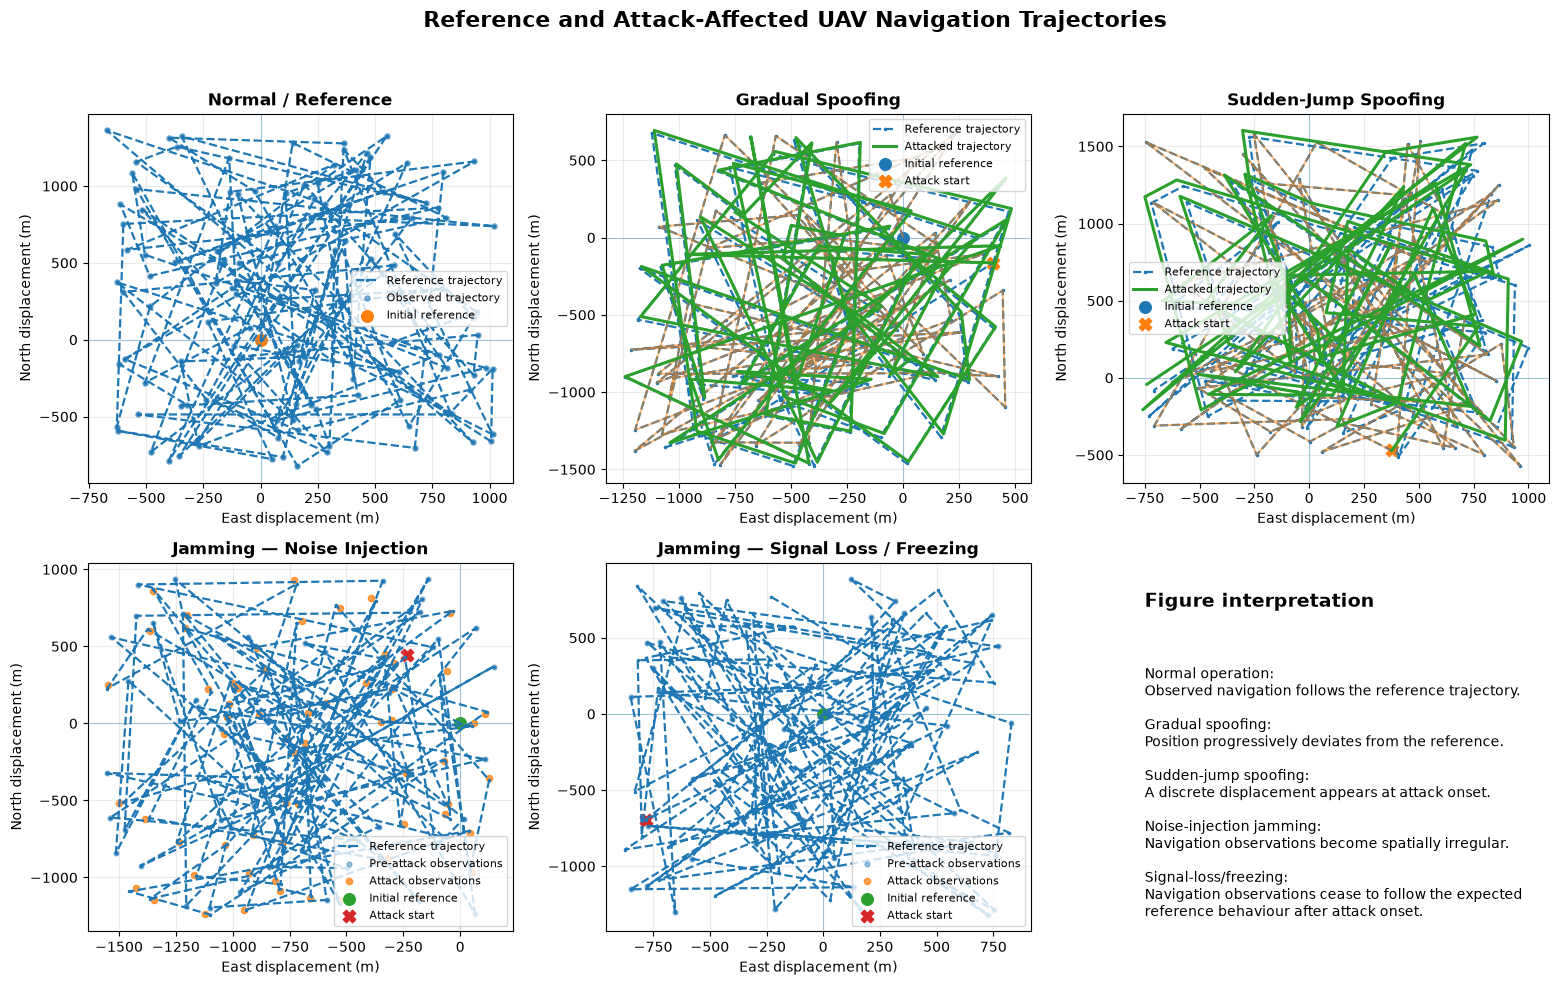


--- Figure integrity ---
Normal / Reference                       FLIGHT_01    Reference=125 Attacked=125 PASS
Gradual Spoofing                         FLIGHT_25    Reference=125 Attacked=125 PASS
Sudden-Jump Spoofing                     FLIGHT_29    Reference=125 Attacked=125 PASS
Jamming — Noise Injection                FLIGHT_33    Reference=125 Attacked=125 PASS
Jamming — Signal Loss / Freezing         FLIGHT_37    Reference=125 Attacked=125 PASS

PHASE 1 — FIGURE 1 GENERATED SUCCESSFULLY


In [22]:
# ============================================================
# PHASE 1 — FIGURE 1
# REFERENCE VS ATTACKED UAV TRAJECTORY
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — FIGURE 1")
print("REFERENCE VS ATTACKED UAV TRAJECTORY")
print("=" * 70)


# ------------------------------------------------------------
# 1. Representative flight logs
# ------------------------------------------------------------

REPRESENTATIVE_FLIGHTS = {
    "Normal / Reference": "FLIGHT_01",
    "Gradual Spoofing": "FLIGHT_25",
    "Sudden-Jump Spoofing": "FLIGHT_29",
    "Jamming — Noise Injection": "FLIGHT_33",
    "Jamming — Signal Loss / Freezing": "FLIGHT_37"
}


# ------------------------------------------------------------
# 2. Local coordinate conversion function
# ------------------------------------------------------------
# Each flight is independently referenced to its own initial
# nominal position.
#
# This ensures that reference and attacked trajectories for
# the same flight use exactly the same coordinate system.
# ------------------------------------------------------------

def convert_to_local_ne(
    latitude,
    longitude,
    latitude_0,
    longitude_0
):
    """
    Convert latitude/longitude coordinates to local
    North/East displacement in metres.
    """

    latitude = np.deg2rad(
        np.asarray(latitude, dtype=float)
    )

    longitude = np.deg2rad(
        np.asarray(longitude, dtype=float)
    )

    latitude_0 = np.deg2rad(
        float(latitude_0)
    )

    longitude_0 = np.deg2rad(
        float(longitude_0)
    )

    north = (
        EARTH_RADIUS_M
        * (latitude - latitude_0)
    )

    east = (
        EARTH_RADIUS_M
        * np.cos(latitude_0)
        * (longitude - longitude_0)
    )

    return east, north


# ------------------------------------------------------------
# 3. Create figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)

axes = axes.flatten()


# ------------------------------------------------------------
# 4. Generate trajectory panels
# ------------------------------------------------------------

for ax, (title, flight_id) in zip(
    axes[:5],
    REPRESENTATIVE_FLIGHTS.items()
):

    # --------------------------------------------------------
    # Reference flight
    # --------------------------------------------------------

    reference_flight = (
        phase1_reference_dataset[
            phase1_reference_dataset["flight_id"]
            == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Attacked flight
    # --------------------------------------------------------

    attacked_flight = (
        phase1_attacked_dataset[
            phase1_attacked_dataset["flight_id"]
            == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Integrity
    # --------------------------------------------------------

    assert (
        len(reference_flight)
        == SAMPLES_PER_FLIGHT
    )

    assert (
        len(attacked_flight)
        == SAMPLES_PER_FLIGHT
    )


    # --------------------------------------------------------
    # Use the initial REFERENCE position as the common
    # coordinate origin for both trajectories.
    # --------------------------------------------------------

    latitude_0 = reference_flight.loc[
        0,
        "latitude"
    ]

    longitude_0 = reference_flight.loc[
        0,
        "longitude"
    ]


    # --------------------------------------------------------
    # Convert reference trajectory
    # --------------------------------------------------------

    reference_east, reference_north = (
        convert_to_local_ne(
            reference_flight["latitude"],
            reference_flight["longitude"],
            latitude_0,
            longitude_0
        )
    )


    # --------------------------------------------------------
    # Convert attacked trajectory using the SAME origin
    # --------------------------------------------------------

    attacked_east, attacked_north = (
        convert_to_local_ne(
            attacked_flight["latitude"],
            attacked_flight["longitude"],
            latitude_0,
            longitude_0
        )
    )


    # --------------------------------------------------------
    # Time index
    # --------------------------------------------------------

    relative_time = np.arange(
        SAMPLES_PER_FLIGHT
    )


    # --------------------------------------------------------
    # Pre-attack period
    # --------------------------------------------------------

    pre_attack_mask = (
        relative_time
        < ATTACK_START_INDEX
    )


    # --------------------------------------------------------
    # Attack period
    # --------------------------------------------------------

    attack_mask = (
        relative_time
        >= ATTACK_START_INDEX
    )


    # --------------------------------------------------------
    # Plot reference trajectory
    # --------------------------------------------------------

    ax.plot(
        reference_east,
        reference_north,
        linestyle="--",
        linewidth=1.6,
        marker=".",
        markersize=3,
        label="Reference trajectory"
    )


    # --------------------------------------------------------
    # Plot attacked trajectory
    #
    # For spoofing, a connected trajectory is useful because
    # systematic displacement/drift is the key behaviour.
    #
    # For jamming, observations are shown as points so that
    # artificial zig-zag connections are avoided.
    # --------------------------------------------------------

    if title in [
        "Gradual Spoofing",
        "Sudden-Jump Spoofing"
    ]:

        ax.plot(
            attacked_east[pre_attack_mask],
            attacked_north[pre_attack_mask],
            linewidth=1.2,
            alpha=0.6
        )

        ax.plot(
            attacked_east[attack_mask],
            attacked_north[attack_mask],
            linewidth=2.2,
            label="Attacked trajectory"
        )

    elif title in [
        "Jamming — Noise Injection",
        "Jamming — Signal Loss / Freezing"
    ]:

        ax.scatter(
            attacked_east[pre_attack_mask],
            attacked_north[pre_attack_mask],
            s=12,
            alpha=0.45,
            label="Pre-attack observations"
        )

        ax.scatter(
            attacked_east[attack_mask],
            attacked_north[attack_mask],
            s=20,
            alpha=0.75,
            label="Attack observations"
        )

    else:

        # Normal flight
        ax.scatter(
            attacked_east,
            attacked_north,
            s=14,
            alpha=0.55,
            label="Observed trajectory"
        )


    # --------------------------------------------------------
    # Mark initial reference position
    # --------------------------------------------------------

    ax.scatter(
        0,
        0,
        s=70,
        marker="o",
        label="Initial reference"
    )


    # --------------------------------------------------------
    # Mark attack start
    # --------------------------------------------------------

    if title != "Normal / Reference":

        ax.scatter(
            attacked_east[
                ATTACK_START_INDEX
            ],
            attacked_north[
                ATTACK_START_INDEX
            ],
            s=80,
            marker="X",
            label="Attack start"
        )


    # --------------------------------------------------------
    # Zero-reference axes
    # --------------------------------------------------------

    ax.axhline(
        0,
        linewidth=0.8,
        alpha=0.35
    )

    ax.axvline(
        0,
        linewidth=0.8,
        alpha=0.35
    )


    # --------------------------------------------------------
    # Labels and formatting
    # --------------------------------------------------------

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(
        "East displacement (m)"
    )

    ax.set_ylabel(
        "North displacement (m)"
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        fontsize=8,
        loc="best"
    )


# ------------------------------------------------------------
# 5. Sixth panel — methodological interpretation
# ------------------------------------------------------------

axes[5].axis("off")

axes[5].text(
    0.05,
    0.88,
    "Figure interpretation",
    fontsize=14,
    fontweight="bold",
    transform=axes[5].transAxes
)

axes[5].text(
    0.05,
    0.72,
    "Normal operation:\n"
    "Observed navigation follows the reference trajectory.\n\n"
    "Gradual spoofing:\n"
    "Position progressively deviates from the reference.\n\n"
    "Sudden-jump spoofing:\n"
    "A discrete displacement appears at attack onset.\n\n"
    "Noise-injection jamming:\n"
    "Navigation observations become spatially irregular.\n\n"
    "Signal-loss/freezing:\n"
    "Navigation observations cease to follow the expected\n"
    "reference behaviour after attack onset.",
    fontsize=10,
    verticalalignment="top",
    transform=axes[5].transAxes
)


# ------------------------------------------------------------
# 6. Overall figure title
# ------------------------------------------------------------

fig.suptitle(
    "Reference and Attack-Affected UAV Navigation Trajectories",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()


# ------------------------------------------------------------
# 7. Integrity checks
# ------------------------------------------------------------

print("\n--- Figure integrity ---")

for title, flight_id in REPRESENTATIVE_FLIGHTS.items():

    reference_flight = (
        phase1_reference_dataset[
            phase1_reference_dataset["flight_id"]
            == flight_id
        ]
    )

    attacked_flight = (
        phase1_attacked_dataset[
            phase1_attacked_dataset["flight_id"]
            == flight_id
        ]
    )

    assert (
        len(reference_flight)
        == SAMPLES_PER_FLIGHT
    )

    assert (
        len(attacked_flight)
        == SAMPLES_PER_FLIGHT
    )

    # Verify numeric coordinates are finite
    assert np.isfinite(
        reference_flight[
            [
                "latitude",
                "longitude"
            ]
        ]
        .to_numpy(dtype=float)
    ).all()

    assert np.isfinite(
        attacked_flight[
            [
                "latitude",
                "longitude"
            ]
        ]
        .to_numpy(dtype=float)
    ).all()

    print(
        f"{title:<40} "
        f"{flight_id:<12} "
        f"Reference={len(reference_flight):<3} "
        f"Attacked={len(attacked_flight):<3} "
        f"PASS"
    )


print("\n" + "=" * 70)
print("PHASE 1 — FIGURE 1 GENERATED SUCCESSFULLY")
print("=" * 70)

PHASE 1 — FIGURE 2
GNSS POSITION OFFSET / ERROR VS TIME


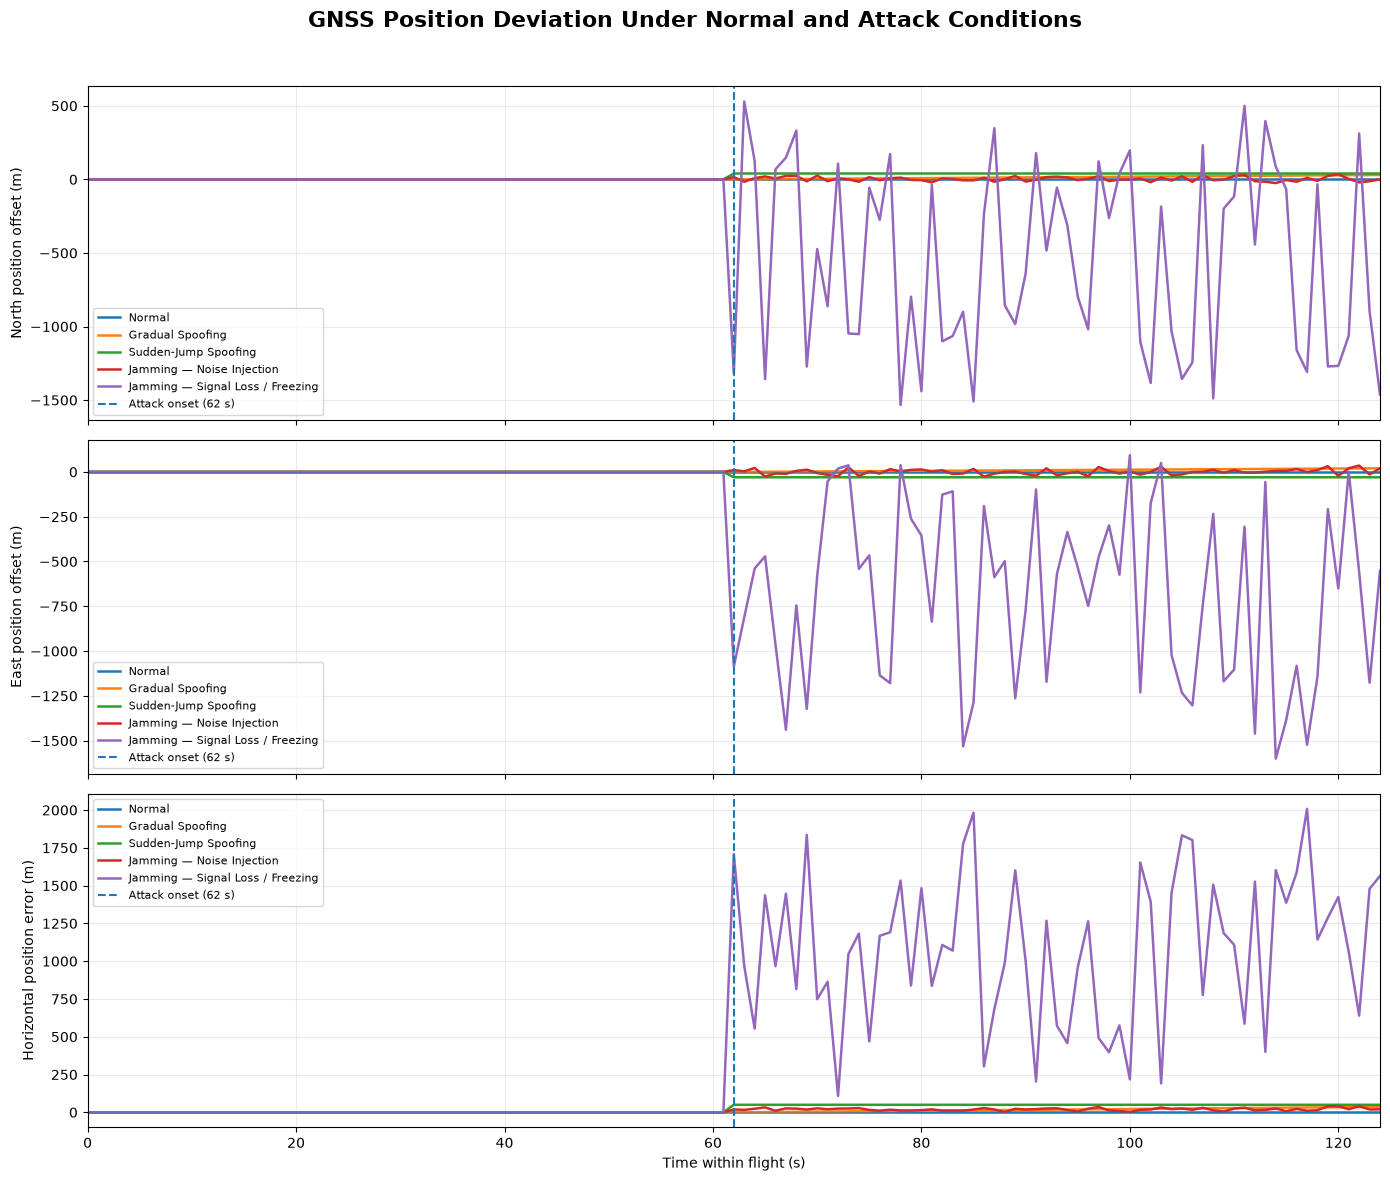


--- Position-error summary ---

Normal
  Pre-attack mean horizontal error : 0.000 m
  Attack-period mean error         : 0.000 m
  Attack-period maximum error      : 0.000 m

Gradual Spoofing
  Pre-attack mean horizontal error : 0.000 m
  Attack-period mean error         : 18.028 m
  Attack-period maximum error      : 36.056 m

Sudden-Jump Spoofing
  Pre-attack mean horizontal error : 0.000 m
  Attack-period mean error         : 50.000 m
  Attack-period maximum error      : 50.002 m

Jamming — Noise Injection
  Pre-attack mean horizontal error : 0.000 m
  Attack-period mean error         : 19.744 m
  Attack-period maximum error      : 40.875 m

Jamming — Signal Loss / Freezing
  Pre-attack mean horizontal error : 0.000 m
  Attack-period mean error         : 1090.816 m
  Attack-period maximum error      : 2007.832 m

--- Figure integrity ---
relative_time_s                     FINITE / PASS
north_offset_m                      FINITE / PASS
east_offset_m                       FINITE / P

In [23]:
# ============================================================
# PHASE 1 — FIGURE 2
# GNSS POSITION OFFSET / ERROR VS TIME
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — FIGURE 2")
print("GNSS POSITION OFFSET / ERROR VS TIME")
print("=" * 70)


# ------------------------------------------------------------
# 1. Representative flights
# ------------------------------------------------------------

REPRESENTATIVE_FLIGHTS = {
    "Normal": "FLIGHT_01",
    "Gradual Spoofing": "FLIGHT_25",
    "Sudden-Jump Spoofing": "FLIGHT_29",
    "Jamming — Noise Injection": "FLIGHT_33",
    "Jamming — Signal Loss / Freezing": "FLIGHT_37"
}


# ------------------------------------------------------------
# 2. Create three-panel figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    1,
    figsize=(14, 12),
    sharex=True
)


# ------------------------------------------------------------
# 3. Plot North offset, East offset and horizontal error
# ------------------------------------------------------------

plot_variables = [
    (
        "north_offset_m",
        "North position offset (m)"
    ),
    (
        "east_offset_m",
        "East position offset (m)"
    ),
    (
        "horizontal_position_error_m",
        "Horizontal position error (m)"
    )
]


for ax, (variable, ylabel) in zip(
    axes,
    plot_variables
):

    for title, flight_id in (
        REPRESENTATIVE_FLIGHTS.items()
    ):

        flight_data = (
            phase1_plot_dataset[
                phase1_plot_dataset["flight_id"]
                == flight_id
            ]
            .sort_values("relative_time_s")
            .reset_index(drop=True)
        )

        assert (
            len(flight_data)
            == SAMPLES_PER_FLIGHT
        )

        ax.plot(
            flight_data["relative_time_s"],
            flight_data[variable],
            linewidth=1.8,
            label=title
        )


    # --------------------------------------------------------
    # Attack onset
    # --------------------------------------------------------

    ax.axvline(
        ATTACK_START_INDEX,
        linestyle="--",
        linewidth=1.5,
        label="Attack onset (62 s)"
    )


    # --------------------------------------------------------
    # Zero-error reference
    # --------------------------------------------------------

    ax.axhline(
        0,
        linewidth=0.8,
        alpha=0.4
    )


    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    ax.set_ylabel(
        ylabel
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        fontsize=8,
        loc="best"
    )


# ------------------------------------------------------------
# 4. Common X-axis
# ------------------------------------------------------------

axes[-1].set_xlabel(
    "Time within flight (s)"
)

axes[-1].set_xlim(
    0,
    SAMPLES_PER_FLIGHT - 1
)


# ------------------------------------------------------------
# 5. Overall title
# ------------------------------------------------------------

fig.suptitle(
    "GNSS Position Deviation Under Normal and Attack Conditions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()


# ------------------------------------------------------------
# 6. Numerical summary around attack onset
# ------------------------------------------------------------

print("\n--- Position-error summary ---")

for title, flight_id in (
    REPRESENTATIVE_FLIGHTS.items()
):

    flight_data = (
        phase1_plot_dataset[
            phase1_plot_dataset["flight_id"]
            == flight_id
        ]
        .sort_values("relative_time_s")
        .reset_index(drop=True)
    )

    pre_attack_error = (
        flight_data.loc[
            flight_data["relative_time_s"]
            < ATTACK_START_INDEX,
            "horizontal_position_error_m"
        ]
    )

    attack_error = (
        flight_data.loc[
            flight_data["relative_time_s"]
            >= ATTACK_START_INDEX,
            "horizontal_position_error_m"
        ]
    )

    print(
        f"\n{title}"
    )

    print(
        f"  Pre-attack mean horizontal error : "
        f"{pre_attack_error.mean():.3f} m"
    )

    print(
        f"  Attack-period mean error         : "
        f"{attack_error.mean():.3f} m"
    )

    print(
        f"  Attack-period maximum error      : "
        f"{attack_error.max():.3f} m"
    )


# ------------------------------------------------------------
# 7. Integrity checks
# ------------------------------------------------------------

print("\n--- Figure integrity ---")

required_plot_columns = [
    "relative_time_s",
    "north_offset_m",
    "east_offset_m",
    "horizontal_position_error_m"
]

for column in required_plot_columns:

    assert column in phase1_plot_dataset.columns

    assert np.isfinite(
        phase1_plot_dataset[column]
        .to_numpy(dtype=float)
    ).all()

    print(
        f"{column:<35} FINITE / PASS"
    )


assert (
    ATTACK_START_INDEX
    == 62
)

assert (
    len(REPRESENTATIVE_FLIGHTS)
    == 5
)

print(
    "\nAttack onset marker: 62 s — PASS"
)

print("\n" + "=" * 70)
print("PHASE 1 — FIGURE 2 GENERATED SUCCESSFULLY")
print("=" * 70)

PHASE 1 — FIGURE 3
EKF INNOVATION RESIDUALS BY SCENARIO VS TIME


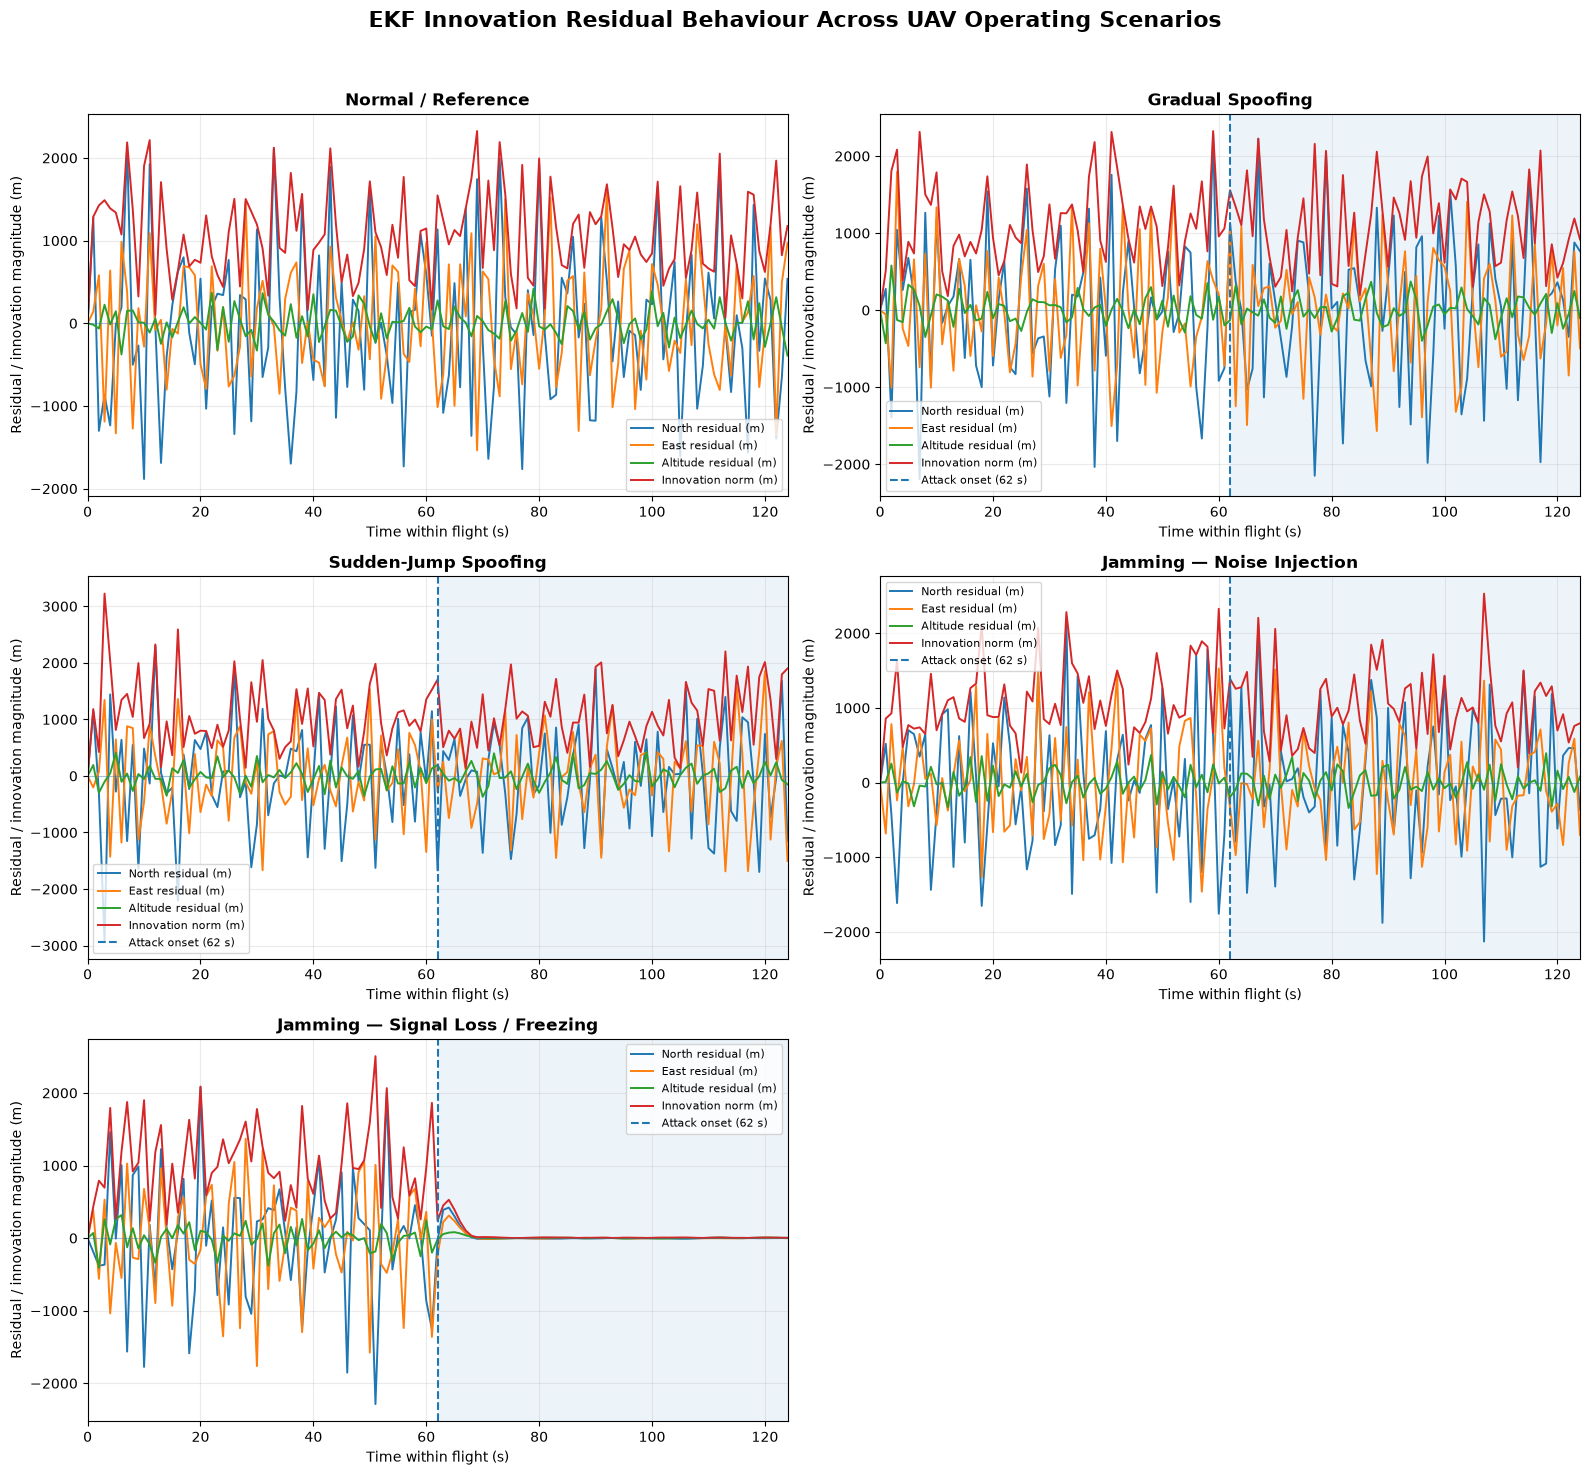


--- EKF innovation summary by scenario ---

Normal / Reference
  Pre-attack innovation norm mean : 1027.810 m
  Attack-period innovation norm mean : 1089.527 m
  Attack-period innovation norm std  : 529.828 m
  Attack-period innovation norm max  : 2325.238 m

Gradual Spoofing
  Pre-attack innovation norm mean : 1095.068 m
  Attack-period innovation norm mean : 1112.843 m
  Attack-period innovation norm std  : 553.925 m
  Attack-period innovation norm max  : 2225.773 m

Sudden-Jump Spoofing
  Pre-attack innovation norm mean : 1071.467 m
  Attack-period innovation norm mean : 1045.746 m
  Attack-period innovation norm std  : 548.471 m
  Attack-period innovation norm max  : 2201.688 m

Jamming — Noise Injection
  Pre-attack innovation norm mean : 1084.391 m
  Attack-period innovation norm mean : 1020.320 m
  Attack-period innovation norm std  : 497.964 m
  Attack-period innovation norm max  : 2531.086 m

Jamming — Signal Loss / Freezing
  Pre-attack innovation norm mean : 1010.796 m
  At

In [24]:
# ============================================================
# PHASE 1 — FIGURE 3
# EKF INNOVATION RESIDUALS BY SCENARIO VS TIME
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — FIGURE 3")
print("EKF INNOVATION RESIDUALS BY SCENARIO VS TIME")
print("=" * 70)


# ------------------------------------------------------------
# 1. Representative flights
# ------------------------------------------------------------

REPRESENTATIVE_FLIGHTS = {
    "Normal / Reference": "FLIGHT_01",
    "Gradual Spoofing": "FLIGHT_25",
    "Sudden-Jump Spoofing": "FLIGHT_29",
    "Jamming — Noise Injection": "FLIGHT_33",
    "Jamming — Signal Loss / Freezing": "FLIGHT_37"
}


# ------------------------------------------------------------
# 2. EKF residual variables
# ------------------------------------------------------------

RESIDUAL_VARIABLES = [
    (
        "ekf_residual_north",
        "North residual (m)"
    ),
    (
        "ekf_residual_east",
        "East residual (m)"
    ),
    (
        "ekf_residual_alt",
        "Altitude residual (m)"
    ),
    (
        "ekf_innovation_norm",
        "Innovation norm (m)"
    )
]


# ------------------------------------------------------------
# 3. Use validated EKF output
# ------------------------------------------------------------

ekf_plot_dataset = final_dataset.copy()


# ------------------------------------------------------------
# 4. Required-column validation
# ------------------------------------------------------------

required_columns = [
    "flight_id",
    "timestamp",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "ekf_innovation_norm"
]

for column in required_columns:

    assert column in ekf_plot_dataset.columns, (
        f"Required column missing: {column}"
    )


# ------------------------------------------------------------
# 5. Numerical validation
# ------------------------------------------------------------

for variable, label in RESIDUAL_VARIABLES:

    values = (
        ekf_plot_dataset[variable]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(values).all(), (
        f"Non-finite values detected in {variable}"
    )


# ------------------------------------------------------------
# 6. Create scenario-focused figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    2,
    figsize=(16, 15)
)

axes = axes.flatten()


# ------------------------------------------------------------
# 7. Plot each representative scenario
# ------------------------------------------------------------

for panel_index, (scenario_title, flight_id) in enumerate(
    REPRESENTATIVE_FLIGHTS.items()
):

    ax = axes[panel_index]


    # --------------------------------------------------------
    # Extract flight
    # --------------------------------------------------------

    flight_data = (
        ekf_plot_dataset[
            ekf_plot_dataset["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # Integrity
    # --------------------------------------------------------

    assert (
        len(flight_data)
        == SAMPLES_PER_FLIGHT
    )


    # --------------------------------------------------------
    # Relative time
    # --------------------------------------------------------

    relative_time = np.arange(
        len(flight_data)
    )


    # --------------------------------------------------------
    # Plot all four EKF quantities
    # --------------------------------------------------------

    for variable, label in RESIDUAL_VARIABLES:

        ax.plot(
            relative_time,
            flight_data[variable].to_numpy(dtype=float),
            linewidth=1.4,
            label=label
        )


    # --------------------------------------------------------
    # Attack onset
    # --------------------------------------------------------

    if scenario_title != "Normal / Reference":

        ax.axvline(
            ATTACK_START_INDEX,
            linestyle="--",
            linewidth=1.5,
            label="Attack onset (62 s)"
        )


        # Light attack-period indication using axis
        # transformation rather than altering the data.
        ax.axvspan(
            ATTACK_START_INDEX,
            SAMPLES_PER_FLIGHT - 1,
            alpha=0.08
        )


    # --------------------------------------------------------
    # Zero residual reference
    # --------------------------------------------------------

    ax.axhline(
        0,
        linewidth=0.8,
        alpha=0.35
    )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_title(
        scenario_title,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Time within flight (s)"
    )

    ax.set_ylabel(
        "Residual / innovation magnitude (m)"
    )

    ax.set_xlim(
        0,
        SAMPLES_PER_FLIGHT - 1
    )

    ax.grid(
        True,
        alpha=0.25
    )

    ax.legend(
        fontsize=8,
        loc="best"
    )


# ------------------------------------------------------------
# 8. Remove unused sixth panel
# ------------------------------------------------------------

axes[5].axis("off")


# ------------------------------------------------------------
# 9. Overall title
# ------------------------------------------------------------

fig.suptitle(
    "EKF Innovation Residual Behaviour Across UAV Operating Scenarios",
    fontsize=16,
    fontweight="bold"
)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.show()


# ------------------------------------------------------------
# 10. Scenario-level numerical summary
# ------------------------------------------------------------

print("\n--- EKF innovation summary by scenario ---")

for scenario_title, flight_id in (
    REPRESENTATIVE_FLIGHTS.items()
):

    flight_data = (
        ekf_plot_dataset[
            ekf_plot_dataset["flight_id"] == flight_id
        ]
        .sort_values("timestamp")
        .reset_index(drop=True)
    )


    pre_attack = flight_data.iloc[
        :ATTACK_START_INDEX
    ]

    attack_period = flight_data.iloc[
        ATTACK_START_INDEX:
    ]


    print(
        f"\n{scenario_title}"
    )

    print(
        f"  Pre-attack innovation norm mean : "
        f"{pre_attack['ekf_innovation_norm'].mean():.3f} m"
    )

    print(
        f"  Attack-period innovation norm mean : "
        f"{attack_period['ekf_innovation_norm'].mean():.3f} m"
    )

    print(
        f"  Attack-period innovation norm std  : "
        f"{attack_period['ekf_innovation_norm'].std():.3f} m"
    )

    print(
        f"  Attack-period innovation norm max  : "
        f"{attack_period['ekf_innovation_norm'].max():.3f} m"
    )


# ------------------------------------------------------------
# 11. Integrity checks
# ------------------------------------------------------------

print("\n--- Figure integrity ---")

for variable, label in RESIDUAL_VARIABLES:

    values = (
        ekf_plot_dataset[variable]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(values).all()

    print(
        f"{variable:<30} FINITE / PASS"
    )


for scenario_title, flight_id in (
    REPRESENTATIVE_FLIGHTS.items()
):

    flight_count = (
        ekf_plot_dataset[
            ekf_plot_dataset["flight_id"] == flight_id
        ]
        .shape[0]
    )

    assert (
        flight_count
        == SAMPLES_PER_FLIGHT
    )

    print(
        f"{scenario_title:<40}"
        f"{flight_id:<12}"
        f"{flight_count:<3} observations PASS"
    )


assert (
    ATTACK_START_INDEX
    == 62
)

print(
    "\nAttack onset marker: 62 s — PASS"
)

print("\n" + "=" * 70)
print("PHASE 1 — FIGURE 3 GENERATED SUCCESSFULLY")
print("=" * 70)

PHASE 1 — FIGURE 4
EKF INNOVATION NORM BY CLASS

--- Class observation counts ---
Normal        3000 observations
Spoofing      1000 observations
Jamming       1000 observations


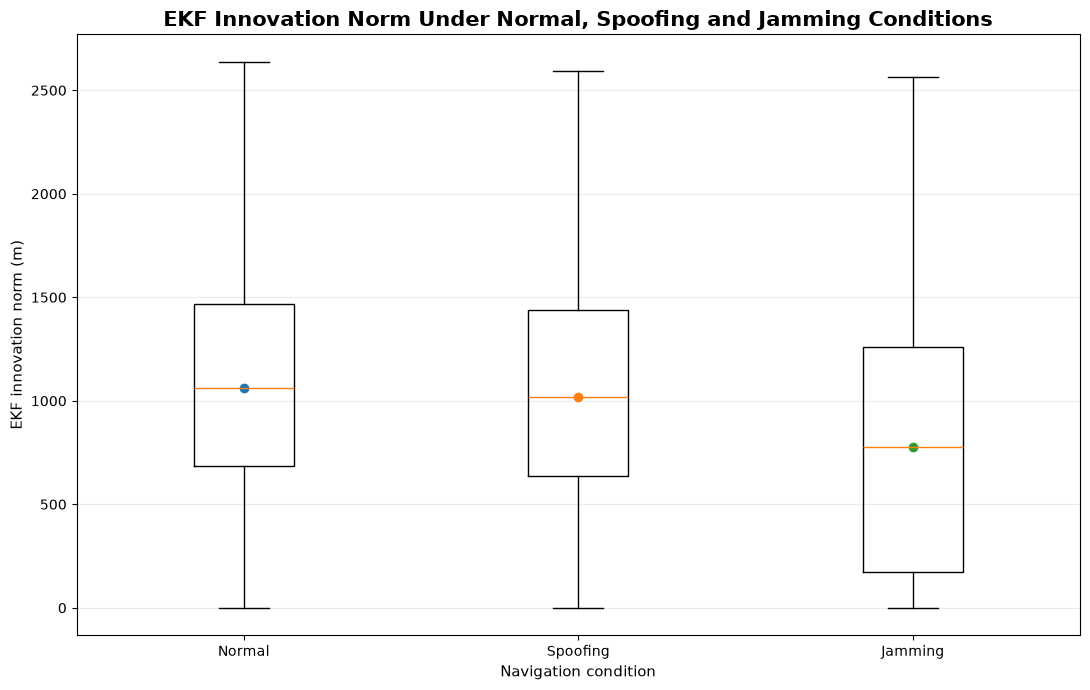


--- EKF innovation norm summary by class ---

Normal
  Mean   : 1093.182 m
  Median : 1063.590 m
  Std    : 522.583 m
  Q1     : 685.570 m
  Q3     : 1469.472 m
  Maximum: 2893.405 m

Spoofing
  Mean   : 1064.806 m
  Median : 1018.395 m
  Std    : 532.748 m
  Q1     : 637.692 m
  Q3     : 1437.709 m
  Maximum: 3223.947 m

Jamming
  Mean   : 798.068 m
  Median : 778.032 m
  Std    : 633.605 m
  Q1     : 173.362 m
  Q3     : 1261.160 m
  Maximum: 2565.335 m

--- Scenario-to-class mapping ---
            scenario main_class
     noise_injection    Jamming
signal_loss_freezing    Jamming
              normal     Normal
       gradual_drift   Spoofing
         sudden_jump   Spoofing

--- Figure integrity ---
Total observations              : 5000 / PASS
Normal observations             : 3000 / PASS
Spoofing observations           : 1000 / PASS
Jamming observations            : 1000 / PASS
EKF innovation values finite    : PASS
Normal/Spoofing/Jamming classes : PASS

PHASE 1 — FIGURE 4 GENE

In [25]:
# ============================================================
# PHASE 1 — FIGURE 4
# EKF INNOVATION NORM: NORMAL vs SPOOFING vs JAMMING
# FINAL THESIS VERSION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — FIGURE 4")
print("EKF INNOVATION NORM BY CLASS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Use validated Phase 1 dataset
# ------------------------------------------------------------

figure4_data = final_dataset.copy()


# ------------------------------------------------------------
# 2. Required columns
# ------------------------------------------------------------

required_columns = [
    "flight_id",
    "timestamp",
    "scenario",
    "attack_label",
    "ekf_innovation_norm"
]

for column in required_columns:

    assert column in figure4_data.columns, (
        f"Required column missing: {column}"
    )


# ------------------------------------------------------------
# 3. Validate innovation norm
# ------------------------------------------------------------

innovation_values = (
    figure4_data["ekf_innovation_norm"]
    .to_numpy(dtype=float)
)

assert np.isfinite(innovation_values).all(), (
    "Non-finite EKF innovation norm values detected."
)


# ------------------------------------------------------------
# 4. Create main-class labels
# ------------------------------------------------------------

def assign_main_class(row):

    scenario = str(row["scenario"]).lower()

    if scenario == "normal":
        return "Normal"

    elif scenario in [
        "gradual_drift",
        "sudden_jump"
    ]:
        return "Spoofing"

    elif scenario in [
        "noise_injection",
        "signal_loss_freezing"
    ]:
        return "Jamming"

    else:
        raise ValueError(
            f"Unknown scenario encountered: {row['scenario']}"
        )


figure4_data["main_class"] = (
    figure4_data.apply(
        assign_main_class,
        axis=1
    )
)


# ------------------------------------------------------------
# 5. Verify class allocation
# ------------------------------------------------------------

class_order = [
    "Normal",
    "Spoofing",
    "Jamming"
]

class_counts = (
    figure4_data["main_class"]
    .value_counts()
    .reindex(class_order)
)


print("\n--- Class observation counts ---")

for class_name in class_order:

    print(
        f"{class_name:<12}"
        f"{int(class_counts[class_name]):>6} observations"
    )


assert class_counts["Normal"] == 3000
assert class_counts["Spoofing"] == 1000
assert class_counts["Jamming"] == 1000


# ------------------------------------------------------------
# 6. Calculate class-level statistics
# ------------------------------------------------------------

class_summary = []

for class_name in class_order:

    class_data = figure4_data[
        figure4_data["main_class"] == class_name
    ]["ekf_innovation_norm"]


    class_summary.append({
        "class": class_name,
        "mean": class_data.mean(),
        "median": class_data.median(),
        "std": class_data.std(),
        "q1": class_data.quantile(0.25),
        "q3": class_data.quantile(0.75),
        "min": class_data.min(),
        "max": class_data.max()
    })


class_summary = pd.DataFrame(
    class_summary
)


# ------------------------------------------------------------
# 7. Figure — class-level distribution
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 7)
)


box_data = [
    figure4_data.loc[
        figure4_data["main_class"] == class_name,
        "ekf_innovation_norm"
    ].to_numpy(dtype=float)

    for class_name in class_order
]


ax.boxplot(
    box_data,
    tick_labels=class_order,
    showfliers=False,
    patch_artist=False
)


ax.set_title(
    "EKF Innovation Norm Under Normal, Spoofing and Jamming Conditions",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Navigation condition",
    fontsize=11
)

ax.set_ylabel(
    "EKF innovation norm (m)",
    fontsize=11
)

ax.grid(
    axis="y",
    alpha=0.25
)


# ------------------------------------------------------------
# 8. Add median markers
# ------------------------------------------------------------

for position, class_name in enumerate(class_order, start=1):

    median_value = class_summary.loc[
        class_summary["class"] == class_name,
        "median"
    ].iloc[0]

    ax.plot(
        position,
        median_value,
        marker="o",
        markersize=6
    )


plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 9. Print numerical summary
# ------------------------------------------------------------

print("\n--- EKF innovation norm summary by class ---")

for _, row in class_summary.iterrows():

    print(
        f"\n{row['class']}"
    )

    print(
        f"  Mean   : {row['mean']:.3f} m"
    )

    print(
        f"  Median : {row['median']:.3f} m"
    )

    print(
        f"  Std    : {row['std']:.3f} m"
    )

    print(
        f"  Q1     : {row['q1']:.3f} m"
    )

    print(
        f"  Q3     : {row['q3']:.3f} m"
    )

    print(
        f"  Maximum: {row['max']:.3f} m"
    )


# ------------------------------------------------------------
# 10. Scenario-to-class verification
# ------------------------------------------------------------

print("\n--- Scenario-to-class mapping ---")

scenario_mapping = (
    figure4_data[
        ["scenario", "main_class"]
    ]
    .drop_duplicates()
    .sort_values(
        ["main_class", "scenario"]
    )
)

print(
    scenario_mapping.to_string(
        index=False
    )
)


# ------------------------------------------------------------
# 11. Integrity checks
# ------------------------------------------------------------

print("\n--- Figure integrity ---")

assert set(
    figure4_data["main_class"].unique()
) == set(class_order)

assert (
    figure4_data["ekf_innovation_norm"]
    .notna()
    .all()
)

assert np.isfinite(
    figure4_data["ekf_innovation_norm"]
    .to_numpy(dtype=float)
).all()

assert (
    len(figure4_data)
    == 5000
)

print(
    "Total observations              : 5000 / PASS"
)

print(
    "Normal observations             : 3000 / PASS"
)

print(
    "Spoofing observations           : 1000 / PASS"
)

print(
    "Jamming observations            : 1000 / PASS"
)

print(
    "EKF innovation values finite    : PASS"
)

print(
    "Normal/Spoofing/Jamming classes : PASS"
)


print("\n" + "=" * 70)
print("PHASE 1 — FIGURE 4 GENERATED SUCCESSFULLY")
print("=" * 70)

PHASE 1 — SUPPORTING FIGURE
FEATURE CORRELATION HEATMAP


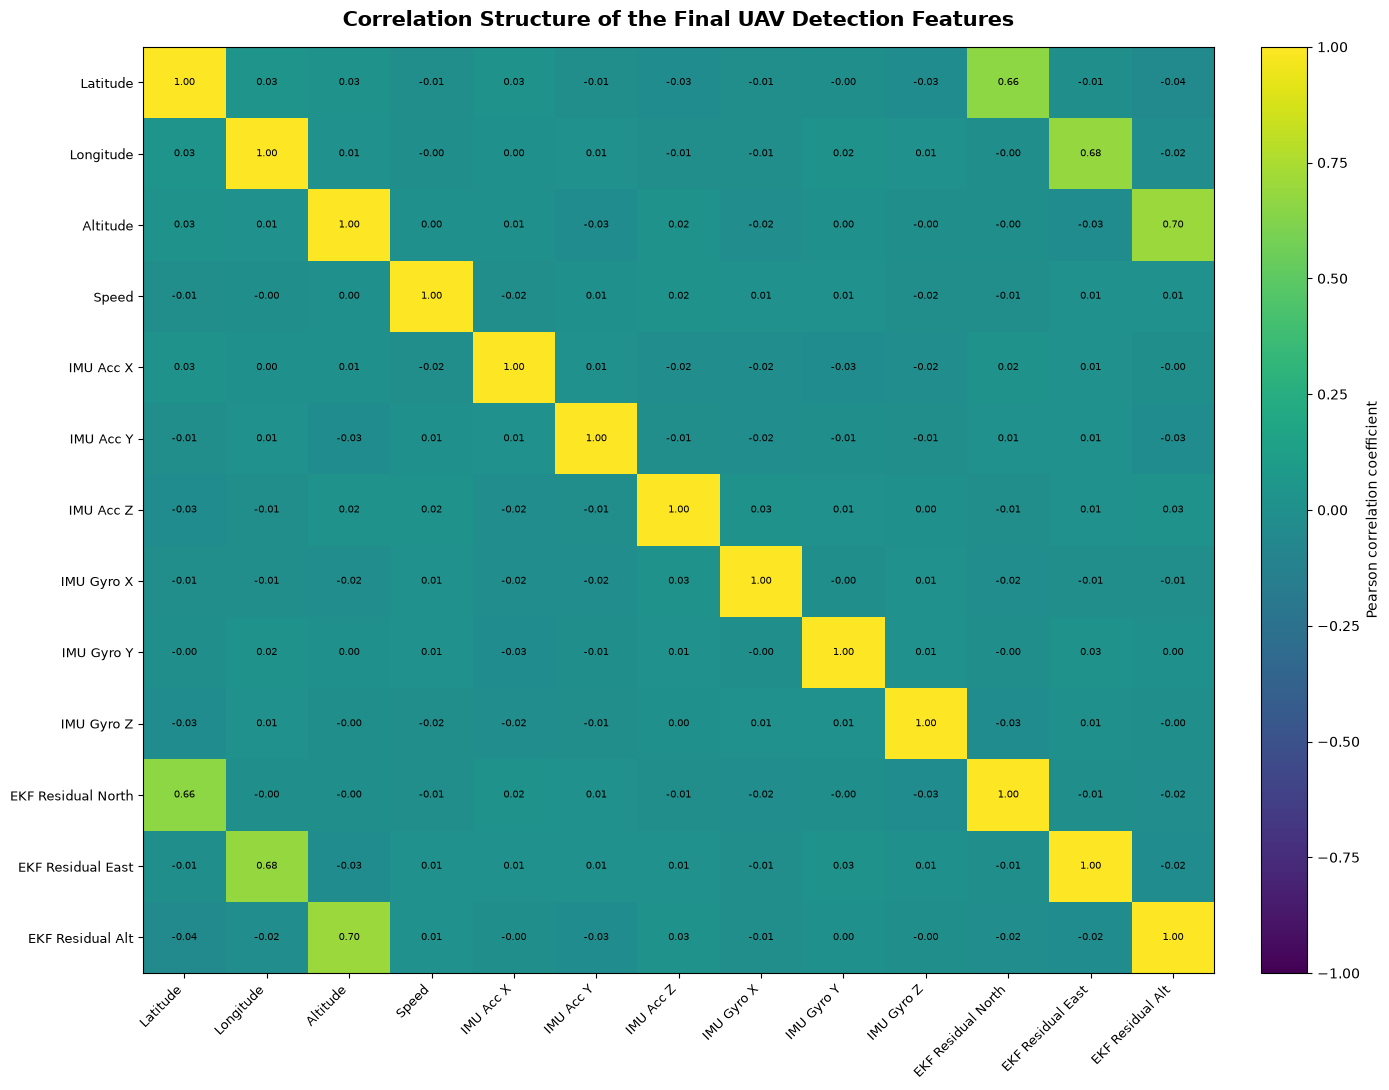


--- Strongest absolute feature correlations ---
altitude                  ↔ ekf_residual_alt          r = +0.699
longitude                 ↔ ekf_residual_east         r = +0.683
latitude                  ↔ ekf_residual_north        r = +0.660
latitude                  ↔ ekf_residual_alt          r = -0.039
latitude                  ↔ longitude                 r = +0.034
altitude                  ↔ imu_acc_y                 r = -0.031
latitude                  ↔ altitude                  r = +0.030
imu_gyro_z                ↔ ekf_residual_north        r = -0.030
latitude                  ↔ imu_gyro_z                r = -0.028
latitude                  ↔ imu_acc_z                 r = -0.028

--- EKF residual feature correlations ---

ekf_residual_north
  latitude                  r = +0.660
  imu_gyro_z                r = -0.030
  imu_gyro_x                r = -0.022
  ekf_residual_alt          r = -0.020
  imu_acc_x                 r = +0.019

ekf_residual_east
  longitude             

In [26]:
# ============================================================
# PHASE 1 — SUPPORTING FIGURE
# FEATURE CORRELATION HEATMAP
# GNSS + IMU + EKF RESIDUAL FEATURES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("PHASE 1 — SUPPORTING FIGURE")
print("FEATURE CORRELATION HEATMAP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Final predictive feature set
# ------------------------------------------------------------

FINAL_FEATURES = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]


# ------------------------------------------------------------
# 2. Use the validated Phase 1 dataset
# ------------------------------------------------------------

correlation_data = final_dataset[
    FINAL_FEATURES
].copy()


# ------------------------------------------------------------
# 3. Required-column validation
# ------------------------------------------------------------

for column in FINAL_FEATURES:

    assert column in correlation_data.columns, (
        f"Required feature missing: {column}"
    )


# ------------------------------------------------------------
# 4. Numerical validation
# ------------------------------------------------------------

assert (
    correlation_data.shape
    == (5000, 13)
), (
    f"Unexpected correlation dataset shape: "
    f"{correlation_data.shape}"
)


assert (
    correlation_data.notna().all().all()
), "Missing values detected."


assert np.isfinite(
    correlation_data.to_numpy(dtype=float)
).all(), (
    "Non-finite feature values detected."
)


# ------------------------------------------------------------
# 5. Calculate Pearson correlation matrix
# ------------------------------------------------------------

correlation_matrix = (
    correlation_data
    .corr(method="pearson")
)


# ------------------------------------------------------------
# 6. Verify correlation matrix
# ------------------------------------------------------------

assert (
    correlation_matrix.shape
    == (13, 13)
)

assert np.isfinite(
    correlation_matrix.to_numpy(dtype=float)
).all()

assert np.allclose(
    np.diag(correlation_matrix),
    1.0
)

assert np.allclose(
    correlation_matrix,
    correlation_matrix.T
)


# ------------------------------------------------------------
# 7. Create readable feature labels
# ------------------------------------------------------------

feature_labels = [
    "Latitude",
    "Longitude",
    "Altitude",
    "Speed",
    "IMU Acc X",
    "IMU Acc Y",
    "IMU Acc Z",
    "IMU Gyro X",
    "IMU Gyro Y",
    "IMU Gyro Z",
    "EKF Residual North",
    "EKF Residual East",
    "EKF Residual Alt"
]


# ------------------------------------------------------------
# 8. Create heatmap
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 11)
)


image = ax.imshow(
    correlation_matrix.to_numpy(),
    vmin=-1,
    vmax=1,
    aspect="auto"
)


# ------------------------------------------------------------
# 9. Axis labels
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(len(feature_labels))
)

ax.set_yticks(
    np.arange(len(feature_labels))
)

ax.set_xticklabels(
    feature_labels,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    feature_labels,
    fontsize=9
)


# ------------------------------------------------------------
# 10. Add correlation coefficients
# ------------------------------------------------------------

for i in range(
    correlation_matrix.shape[0]
):

    for j in range(
        correlation_matrix.shape[1]
    ):

        value = correlation_matrix.iloc[
            i,
            j
        ]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )


# ------------------------------------------------------------
# 11. Color scale
# ------------------------------------------------------------

cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Pearson correlation coefficient",
    fontsize=10
)


# ------------------------------------------------------------
# 12. Title
# ------------------------------------------------------------

ax.set_title(
    "Correlation Structure of the Final UAV Detection Features",
    fontsize=15,
    fontweight="bold",
    pad=15
)


plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 13. Print strongest feature relationships
# ------------------------------------------------------------

print("\n--- Strongest absolute feature correlations ---")

correlation_pairs = []

for i in range(
    len(FINAL_FEATURES)
):

    for j in range(
        i + 1,
        len(FINAL_FEATURES)
    ):

        correlation_value = (
            correlation_matrix.iloc[i, j]
        )

        correlation_pairs.append(
            (
                FINAL_FEATURES[i],
                FINAL_FEATURES[j],
                correlation_value,
                abs(correlation_value)
            )
        )


correlation_pairs = sorted(
    correlation_pairs,
    key=lambda x: x[3],
    reverse=True
)


for feature_a, feature_b, correlation, absolute_value in (
    correlation_pairs[:10]
):

    print(
        f"{feature_a:<25} ↔ "
        f"{feature_b:<25} "
        f"r = {correlation:+.3f}"
    )


# ------------------------------------------------------------
# 14. EKF residual correlation summary
# ------------------------------------------------------------

print("\n--- EKF residual feature correlations ---")

EKF_FEATURES = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

for feature in EKF_FEATURES:

    print(
        f"\n{feature}"
    )

    feature_correlations = (
        correlation_matrix[feature]
        .drop(feature)
        .sort_values(
            key=lambda x: abs(x),
            ascending=False
        )
        .head(5)
    )

    for other_feature, value in (
        feature_correlations.items()
    ):

        print(
            f"  {other_feature:<25}"
            f" r = {value:+.3f}"
        )


# ------------------------------------------------------------
# 15. Integrity checks
# ------------------------------------------------------------

print("\n--- Figure integrity ---")

print(
    f"Observations used              : "
    f"{len(correlation_data)} / PASS"
)

print(
    f"Final predictive features      : "
    f"{len(FINAL_FEATURES)} / PASS"
)

print(
    "Missing values                 : PASS"
)

print(
    "Finite feature values          : PASS"
)

print(
    "Correlation matrix dimensions  : "
    f"{correlation_matrix.shape} / PASS"
)

print(
    "Matrix symmetry                : PASS"
)

print(
    "Diagonal values equal to 1     : PASS"
)

print("\n" + "=" * 70)
print("PHASE 1 — FEATURE CORRELATION HEATMAP GENERATED SUCCESSFULLY")
print("=" * 70)

In [27]:
# ============================================================
# SECTION 21.1 — LOAD AND LOCK PHASE 1 DATASET
# ============================================================

import os
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Environment initialized successfully.")
print(f"Random seed: {SEED}")

Environment initialized successfully.
Random seed: 42


In [28]:
# ============================================================
# SECTION 21.2 — LOAD FINAL PHASE 1 DATASET
# ============================================================

print("=" * 70)
print("SECTION 21.2 — LOAD FINAL PHASE 1 DATASET")
print("=" * 70)

# ------------------------------------------------------------
# Phase 1 final CSV
# ------------------------------------------------------------

DATA_PATH = (
    "phase1_outputs/"
    "phase1_final_uav_ekf_dataset.csv"
)

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"\nPhase 1 final dataset not found at:\n"
        f"{os.path.abspath(DATA_PATH)}\n\n"
        f"Make sure this Phase 2 notebook is running "
        f"from the same project directory as Phase 1."
    )

# ------------------------------------------------------------
# Load dataset
# ------------------------------------------------------------

phase2_df = pd.read_csv(
    DATA_PATH,
    parse_dates=["timestamp"]
)

# ------------------------------------------------------------
# Expected columns
# ------------------------------------------------------------

EXPECTED_PHASE1_COLUMNS = [
    "flight_id",
    "timestamp",
    "scenario",
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt",
    "attack_label"
]

# ------------------------------------------------------------
# Column validation
# ------------------------------------------------------------

missing_columns = [
    col
    for col in EXPECTED_PHASE1_COLUMNS
    if col not in phase2_df.columns
]

unexpected_columns = [
    col
    for col in phase2_df.columns
    if col not in EXPECTED_PHASE1_COLUMNS
]

print("\n--- Dataset validation ---")

print("Missing columns:", missing_columns)
print("Unexpected columns:", unexpected_columns)

assert len(missing_columns) == 0
assert len(unexpected_columns) == 0

# ------------------------------------------------------------
# Enforce column order
# ------------------------------------------------------------

phase2_df = (
    phase2_df[
        EXPECTED_PHASE1_COLUMNS
    ]
    .sort_values(
        ["flight_id", "timestamp"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Basic information
# ------------------------------------------------------------

print("\n--- Phase 1 dataset loaded successfully ---")

print("Shape:", phase2_df.shape)

print("\nColumns:")

for i, col in enumerate(
    phase2_df.columns,
    start=1
):
    print(
        f"{i:02d}. {col}"
    )

print("\nUnique flight logs:")
print(
    phase2_df["flight_id"].nunique()
)

print("\nSamples per flight:")
print(
    phase2_df
    .groupby("flight_id")
    .size()
    .value_counts()
    .sort_index()
)

print("\nAttack-label distribution:")
print(
    phase2_df[
        "attack_label"
    ]
    .value_counts()
    .sort_index()
)

print("\nScenario distribution:")
print(
    phase2_df[
        "scenario"
    ]
    .value_counts()
    .sort_index()
)

print("\nTimestamp range:")
print(
    phase2_df["timestamp"].min()
)
print(
    phase2_df["timestamp"].max()
)

print("\n" + "=" * 70)
print("SECTION 21.2 PASSED")
print("=" * 70)

SECTION 21.2 — LOAD FINAL PHASE 1 DATASET

--- Dataset validation ---
Missing columns: []
Unexpected columns: []

--- Phase 1 dataset loaded successfully ---
Shape: (5000, 17)

Columns:
01. flight_id
02. timestamp
03. scenario
04. latitude
05. longitude
06. altitude
07. speed
08. imu_acc_x
09. imu_acc_y
10. imu_acc_z
11. imu_gyro_x
12. imu_gyro_y
13. imu_gyro_z
14. ekf_residual_north
15. ekf_residual_east
16. ekf_residual_alt
17. attack_label

Unique flight logs:
40

Samples per flight:
125    40
Name: count, dtype: int64

Attack-label distribution:
attack_label
0    3000
1    1000
2    1000
Name: count, dtype: int64

Scenario distribution:
scenario
gradual_drift            500
noise_injection          500
normal                  3000
signal_loss_freezing     500
sudden_jump              500
Name: count, dtype: int64

Timestamp range:
2023-01-01 00:00:00
2023-02-09 00:02:04

SECTION 21.2 PASSED


In [29]:
# ============================================================
# SECTION 21.3 — BASIC DATASET INTEGRITY CHECK
# ============================================================

print("=" * 70)
print("SECTION 21.3 — BASIC DATASET INTEGRITY CHECK")
print("=" * 70)

# ------------------------------------------------------------
# Dataset shape
# ------------------------------------------------------------

print("\n--- Dataset shape ---")

print(
    "Rows:",
    len(phase2_df)
)

print(
    "Columns:",
    len(phase2_df.columns)
)

assert phase2_df.shape == (5000, 17)

# ------------------------------------------------------------
# Timestamp conversion
# ------------------------------------------------------------

print("\n--- Timestamp validation ---")

assert pd.api.types.is_datetime64_any_dtype(
    phase2_df["timestamp"]
)

print(
    "Timestamp dtype:",
    phase2_df["timestamp"].dtype
)

print(
    "Timestamp conversion: PASS"
)

# ------------------------------------------------------------
# Missing values
# ------------------------------------------------------------

print("\n--- Missing values ---")

missing_values = (
    phase2_df.isna().sum()
)

print(
    missing_values
)

assert (
    missing_values.sum() == 0
)

# ------------------------------------------------------------
# Duplicate rows
# ------------------------------------------------------------

duplicate_rows = (
    phase2_df.duplicated().sum()
)

print(
    "\nDuplicate complete rows:",
    duplicate_rows
)

assert duplicate_rows == 0

# ------------------------------------------------------------
# Flight-log integrity
# ------------------------------------------------------------

print("\n--- Flight-log integrity ---")

flight_count = (
    phase2_df["flight_id"].nunique()
)

print(
    "Flight-log count:",
    flight_count
)

assert flight_count == 40

samples_per_flight = (
    phase2_df
    .groupby("flight_id")
    .size()
)

print(
    "\nSamples per flight:"
)

print(
    samples_per_flight
    .value_counts()
    .sort_index()
)

assert (
    samples_per_flight.eq(125).all()
)

# ------------------------------------------------------------
# Timestamp uniqueness within each flight
# ------------------------------------------------------------

duplicate_flight_timestamps = (
    phase2_df
    .duplicated(
        subset=[
            "flight_id",
            "timestamp"
        ]
    )
    .sum()
)

print(
    "\nDuplicate flight_id + timestamp pairs:",
    duplicate_flight_timestamps
)

assert duplicate_flight_timestamps == 0

# ------------------------------------------------------------
# Chronological order
# ------------------------------------------------------------

chronological_status = (
    phase2_df
    .groupby("flight_id")["timestamp"]
    .apply(
        lambda x:
        x.is_monotonic_increasing
    )
)

print(
    "\nFlights chronologically ordered:",
    chronological_status.all()
)

assert chronological_status.all()

# ------------------------------------------------------------
# Sampling interval
# ------------------------------------------------------------

sampling_intervals = (
    phase2_df
    .groupby("flight_id")["timestamp"]
    .diff()
    .dt.total_seconds()
    .dropna()
)

print(
    "\nSampling interval distribution:"
)

print(
    sampling_intervals
    .value_counts()
    .sort_index()
)

assert set(
    sampling_intervals.unique()
) == {1.0}

# ------------------------------------------------------------
# Target validation
# ------------------------------------------------------------

print(
    "\n--- Attack-label distribution ---"
)

target_counts = (
    phase2_df[
        "attack_label"
    ]
    .value_counts()
    .sort_index()
)

print(target_counts)

EXPECTED_TARGET_COUNTS = {
    0: 3000,
    1: 1000,
    2: 1000
}

assert (
    target_counts.to_dict()
    == EXPECTED_TARGET_COUNTS
)

# ------------------------------------------------------------
# Scenario validation
# ------------------------------------------------------------

print(
    "\n--- Scenario distribution ---"
)

scenario_counts = (
    phase2_df[
        "scenario"
    ]
    .value_counts()
    .sort_index()
)

print(
    scenario_counts
)

EXPECTED_SCENARIO_COUNTS = {
    "normal": 3000,
    "gradual_drift": 500,
    "sudden_jump": 500,
    "noise_injection": 500,
    "signal_loss_freezing": 500
}

assert (
    scenario_counts.to_dict()
    == EXPECTED_SCENARIO_COUNTS
)

# ------------------------------------------------------------
# Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 21.3 — DATASET INTEGRITY CHECK PASSED")
print("=" * 70)

print(
    "Rows                         : 5000"
)

print(
    "Columns                      : 17"
)

print(
    "Independent flight logs     : 40"
)

print(
    "Samples per flight          : 125"
)

print(
    "Duplicate rows              : 0"
)

print(
    "Duplicate flight/timestamps : 0"
)

print(
    "Missing values              : 0"
)

print(
    "Sampling interval           : 1 second"
)

print(
    "Chronological integrity     : PASS"
)

print(
    "Target distribution         : PASS"
)

print(
    "Scenario distribution       : PASS"
)

print("=" * 70)

SECTION 21.3 — BASIC DATASET INTEGRITY CHECK

--- Dataset shape ---
Rows: 5000
Columns: 17

--- Timestamp validation ---
Timestamp dtype: datetime64[ns]
Timestamp conversion: PASS

--- Missing values ---
flight_id             0
timestamp             0
scenario              0
latitude              0
longitude             0
altitude              0
speed                 0
imu_acc_x             0
imu_acc_y             0
imu_acc_z             0
imu_gyro_x            0
imu_gyro_y            0
imu_gyro_z            0
ekf_residual_north    0
ekf_residual_east     0
ekf_residual_alt      0
attack_label          0
dtype: int64

Duplicate complete rows: 0

--- Flight-log integrity ---
Flight-log count: 40

Samples per flight:
125    40
Name: count, dtype: int64

Duplicate flight_id + timestamp pairs: 0

Flights chronologically ordered: True

Sampling interval distribution:
timestamp
1.0    4960
Name: count, dtype: int64

--- Attack-label distribution ---
attack_label
0    3000
1    1000
2    1000

In [73]:
# ================================================================
# SECTION 22 — STRATIFIED FLIGHT-LEVEL TRAIN / VALIDATION / TEST SPLIT
# ================================================================

print("=" * 78)
print("SECTION 22 — STRATIFIED FLIGHT-LEVEL DATA SPLIT")
print("=" * 78)

# ----------------------------------------------------------------
# 1. Required objects
# ----------------------------------------------------------------

required_objects = [
    "flight_manifest",
    "final_dataset"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required object(s): "
        + ", ".join(missing_objects)
    )

# ----------------------------------------------------------------
# 2. Copy manifest
# ----------------------------------------------------------------

manifest = flight_manifest[
    ["flight_id", "attack_label", "scenario"]
].copy()

manifest = manifest.reset_index(drop=True)

print("\n--- Flight manifest ---")
print(f"Total flight logs : {len(manifest)}")

# ----------------------------------------------------------------
# 3. Verify required class totals
# ----------------------------------------------------------------

overall_flight_counts = (
    manifest["attack_label"]
    .value_counts()
    .sort_index()
)

print("\n--- Overall flight-level class distribution ---")

for class_id, class_name in {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}.items():

    count = int(
        overall_flight_counts.get(class_id, 0)
    )

    print(
        f"{class_id} = {class_name:<10}: "
        f"{count} flights"
    )

assert len(manifest) == 40
assert overall_flight_counts.get(0, 0) == 24
assert overall_flight_counts.get(1, 0) == 8
assert overall_flight_counts.get(2, 0) == 8

# ----------------------------------------------------------------
# 4. Fixed reproducible stratified allocation
#
# Required:
# Training   = 28 flights
# Validation = 6 flights
# Test       = 6 flights
#
# Class allocation:
# Normal     = 17 / 4 / 3
# Spoofing   = 6  / 1 / 1
# Jamming    = 5  / 1 / 2
# ----------------------------------------------------------------

TRAIN_COUNTS = {
    0: 17,
    1: 6,
    2: 5
}

VALIDATION_COUNTS = {
    0: 4,
    1: 1,
    2: 1
}

TEST_COUNTS = {
    0: 3,
    1: 1,
    2: 2
}

RANDOM_STATE = 42

rng = np.random.default_rng(RANDOM_STATE)

train_flight_ids = []
validation_flight_ids = []
test_flight_ids = []

for class_id in [0, 1, 2]:

    class_flights = (
        manifest.loc[
            manifest["attack_label"] == class_id,
            "flight_id"
        ]
        .astype(str)
        .tolist()
    )

    class_flights = np.array(
        class_flights,
        dtype=object
    )

    rng.shuffle(class_flights)

    train_n = TRAIN_COUNTS[class_id]
    validation_n = VALIDATION_COUNTS[class_id]
    test_n = TEST_COUNTS[class_id]

    required_n = (
        train_n +
        validation_n +
        test_n
    )

    if len(class_flights) != required_n:
        raise ValueError(
            f"Class {class_id}: expected "
            f"{required_n} flights but found "
            f"{len(class_flights)}."
        )

    train_flight_ids.extend(
        class_flights[:train_n].tolist()
    )

    validation_flight_ids.extend(
        class_flights[
            train_n:
            train_n + validation_n
        ].tolist()
    )

    test_flight_ids.extend(
        class_flights[
            train_n + validation_n:
        ].tolist()
    )

# ----------------------------------------------------------------
# 5. Verify flight-level allocation
# ----------------------------------------------------------------

train_flight_ids = sorted(train_flight_ids)
validation_flight_ids = sorted(validation_flight_ids)
test_flight_ids = sorted(test_flight_ids)

print("\n--- Flight-level allocation ---")

print(
    f"Training flights   : {len(train_flight_ids)}"
)

print(
    f"Validation flights : {len(validation_flight_ids)}"
)

print(
    f"Test flights       : {len(test_flight_ids)}"
)

# ----------------------------------------------------------------
# 6. Verify no flight leakage
# ----------------------------------------------------------------

train_set = set(train_flight_ids)
validation_set = set(validation_flight_ids)
test_set = set(test_flight_ids)

assert train_set.isdisjoint(validation_set)
assert train_set.isdisjoint(test_set)
assert validation_set.isdisjoint(test_set)

assert (
    len(
        train_set |
        validation_set |
        test_set
    ) == 40
)

# ----------------------------------------------------------------
# 7. Create row-level datasets from flight IDs
# ----------------------------------------------------------------

if "flight_id" not in final_dataset.columns:
    raise KeyError(
        "'flight_id' column is required in final_dataset."
    )

train_df = final_dataset[
    final_dataset["flight_id"].isin(train_set)
].copy()

validation_df = final_dataset[
    final_dataset["flight_id"].isin(validation_set)
].copy()

test_df = final_dataset[
    final_dataset["flight_id"].isin(test_set)
].copy()

# ----------------------------------------------------------------
# 8. Sort chronologically within each flight
# ----------------------------------------------------------------

for df_name, df in [
    ("train_df", train_df),
    ("validation_df", validation_df),
    ("test_df", test_df)
]:

    if "timestamp" in df.columns:

        df.sort_values(
            ["flight_id", "timestamp"],
            inplace=True
        )

        df.reset_index(
            drop=True,
            inplace=True
        )

# ----------------------------------------------------------------
# 9. Flight-level class distributions
# ----------------------------------------------------------------

print("\n--- TRAINING FLIGHT DISTRIBUTION ---")

for class_id, class_name in {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}.items():

    count = int(
        manifest[
            manifest["flight_id"].isin(train_set) &
            (manifest["attack_label"] == class_id)
        ].shape[0]
    )

    print(
        f"{class_id} = {class_name:<10}: "
        f"{count} flights"
    )

print("\n--- VALIDATION FLIGHT DISTRIBUTION ---")

for class_id, class_name in {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}.items():

    count = int(
        manifest[
            manifest["flight_id"].isin(validation_set) &
            (manifest["attack_label"] == class_id)
        ].shape[0]
    )

    print(
        f"{class_id} = {class_name:<10}: "
        f"{count} flights"
    )

print("\n--- TEST FLIGHT DISTRIBUTION ---")

for class_id, class_name in {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}.items():

    count = int(
        manifest[
            manifest["flight_id"].isin(test_set) &
            (manifest["attack_label"] == class_id)
        ].shape[0]
    )

    print(
        f"{class_id} = {class_name:<10}: "
        f"{count} flights"
    )

# ----------------------------------------------------------------
# 10. Row-level checks
# ----------------------------------------------------------------

print("\n--- Row-level datasets ---")

print(
    f"Training rows   : {train_df.shape}"
)

print(
    f"Validation rows : {validation_df.shape}"
)

print(
    f"Test rows       : {test_df.shape}"
)

# Every split must contain all three classes
for name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:

    unique_classes = set(
        df["attack_label"].astype(int).unique()
    )

    print(
        f"{name} classes : "
        f"{sorted(unique_classes)}"
    )

    assert unique_classes == {0, 1, 2}

# ----------------------------------------------------------------
# 11. Section validation
# ----------------------------------------------------------------

section22_checks = {

    "40 total flights": len(manifest) == 40,

    "28 training flights":
        len(train_set) == 28,

    "6 validation flights":
        len(validation_set) == 6,

    "6 test flights":
        len(test_set) == 6,

    "No train/validation overlap":
        train_set.isdisjoint(validation_set),

    "No train/test overlap":
        train_set.isdisjoint(test_set),

    "No validation/test overlap":
        validation_set.isdisjoint(test_set),

    "Training contains Normal":
        0 in set(train_df["attack_label"].astype(int)),

    "Training contains Spoofing":
        1 in set(train_df["attack_label"].astype(int)),

    "Training contains Jamming":
        2 in set(train_df["attack_label"].astype(int)),

    "Validation contains Normal":
        0 in set(validation_df["attack_label"].astype(int)),

    "Validation contains Spoofing":
        1 in set(validation_df["attack_label"].astype(int)),

    "Validation contains Jamming":
        2 in set(validation_df["attack_label"].astype(int)),

    "Test contains Normal":
        0 in set(test_df["attack_label"].astype(int)),

    "Test contains Spoofing":
        1 in set(test_df["attack_label"].astype(int)),

    "Test contains Jamming":
        2 in set(test_df["attack_label"].astype(int))
}

print("\n" + "=" * 78)
print("SECTION 22 VALIDATION")
print("=" * 78)

for check_name, result in section22_checks.items():

    print(
        f"{check_name:<55}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(section22_checks.values())

print("\n" + "=" * 78)
print("SECTION 22 — STRATIFIED FLIGHT-LEVEL SPLIT PASSED")
print("=" * 78)

print(
    f"Training flights   : {len(train_set)}"
)

print(
    f"Validation flights : {len(validation_set)}"
)

print(
    f"Test flights       : {len(test_set)}"
)

print(
    "Class coverage     : "
    "Normal + Spoofing + Jamming in all splits"
)

print(
    "Test data used for model training/tuning : NO"
)

print("=" * 78)

SECTION 22 — STRATIFIED FLIGHT-LEVEL DATA SPLIT

--- Flight manifest ---
Total flight logs : 40

--- Overall flight-level class distribution ---
0 = Normal    : 24 flights
1 = Spoofing  : 8 flights
2 = Jamming   : 8 flights

--- Flight-level allocation ---
Training flights   : 28
Validation flights : 6
Test flights       : 6

--- TRAINING FLIGHT DISTRIBUTION ---
0 = Normal    : 17 flights
1 = Spoofing  : 6 flights
2 = Jamming   : 5 flights

--- VALIDATION FLIGHT DISTRIBUTION ---
0 = Normal    : 4 flights
1 = Spoofing  : 1 flights
2 = Jamming   : 1 flights

--- TEST FLIGHT DISTRIBUTION ---
0 = Normal    : 3 flights
1 = Spoofing  : 1 flights
2 = Jamming   : 2 flights

--- Row-level datasets ---
Training rows   : (3500, 36)
Validation rows : (750, 36)
Test rows       : (750, 36)
Training classes : [np.int64(0), np.int64(1), np.int64(2)]
Validation classes : [np.int64(0), np.int64(1), np.int64(2)]
Test classes : [np.int64(0), np.int64(1), np.int64(2)]

SECTION 22 VALIDATION
40 total flight

In [31]:
print("train_split:", "DEFINED" if "train_split" in globals() else "MISSING")
print("validation_split:", "DEFINED" if "validation_split" in globals() else "MISSING")
print("test_split:", "DEFINED" if "test_split" in globals() else "MISSING")

train_split: DEFINED
validation_split: DEFINED
test_split: DEFINED


In [133]:
# ================================================================
# SECTION 23A — ATTACK-AWARE 10 Hz DATA PREPARATION
#                 CLEAN-TRAJECTORY + ATTACK-DECOMPOSITION METHOD
# ================================================================
#
# Methodological revision:
#
# The GNSS trajectory is decomposed into:
#
#     Observed GNSS
#          =
#     Clean reference trajectory
#          +
#     Attack perturbation
#
# The clean reference trajectory is interpolated to 10 Hz.
# The attack perturbation is then reconstructed separately.
#
# This prevents sudden-jump attacks from being incorrectly
# interpolated backwards into the pre-attack period.
#
# No model training is performed.
# No flight-level split is changed.
# ================================================================

print("=" * 78)
print("SECTION 23A — ATTACK-AWARE 10 Hz DATA PREPARATION")
print("Clean-Trajectory + Attack-Decomposition Method")
print("=" * 78)


# ----------------------------------------------------------------
# 1. Required objects
# ----------------------------------------------------------------

required_objects = [
    "train_df",
    "validation_df",
    "test_df",
    "PRIMARY_FEATURES"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required object(s): "
        + ", ".join(missing_objects)
    )


# ----------------------------------------------------------------
# 2. Required columns
# ----------------------------------------------------------------

required_columns = [
    "flight_id",
    "timestamp",
    "attack_label",
    "scenario",
    "latitude",
    "longitude",
    "altitude",
    "reference_latitude",
    "reference_longitude",
    "reference_altitude"
]

for df_name, df in [
    ("train_df", train_df),
    ("validation_df", validation_df),
    ("test_df", test_df)
]:

    missing = [
        col
        for col in required_columns
        if col not in df.columns
    ]

    if missing:
        raise KeyError(
            f"{df_name} is missing column(s): "
            + ", ".join(missing)
        )


# ----------------------------------------------------------------
# 3. Copy datasets
# ----------------------------------------------------------------

train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()


# ----------------------------------------------------------------
# 4. Timestamp preparation
# ----------------------------------------------------------------

for df in [
    train_df,
    validation_df,
    test_df
]:

    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        errors="coerce"
    )

    if df["timestamp"].isna().any():
        raise ValueError(
            "Invalid timestamp detected."
        )


# ----------------------------------------------------------------
# 5. Configuration
# ----------------------------------------------------------------

TARGET_SAMPLING_RATE_HZ = 10.0
TARGET_INTERVAL_SECONDS = 0.1
TARGET_FREQUENCY = "100ms"

ATTACK_ONSET_SECONDS = 62.0

EARTH_RADIUS_M = 6371000.0

GNSS_FEATURES = [
    "latitude",
    "longitude",
    "altitude"
]

NON_GNSS_FEATURES = [
    feature
    for feature in PRIMARY_FEATURES
    if feature not in GNSS_FEATURES
]

print("\n--- Configuration ---")

print(
    f"Target sampling rate : "
    f"{TARGET_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Target interval      : "
    f"{TARGET_INTERVAL_SECONDS:.3f} sec"
)

print(
    f"Attack onset         : "
    f"{ATTACK_ONSET_SECONDS:.1f} sec"
)

print(
    "GNSS reconstruction   : "
    "clean trajectory + attack perturbation"
)


# ----------------------------------------------------------------
# 6. Helper: geographic offset in metres
# ----------------------------------------------------------------

def calculate_gnss_offsets(
    latitude,
    longitude,
    altitude,
    reference_latitude,
    reference_longitude,
    reference_altitude
):

    north = (
        np.radians(
            latitude - reference_latitude
        )
        * EARTH_RADIUS_M
    )

    east = (
        np.radians(
            longitude - reference_longitude
        )
        * EARTH_RADIUS_M
        * np.cos(
            np.radians(reference_latitude)
        )
    )

    altitude_offset = (
        altitude
        - reference_altitude
    )

    return (
        north,
        east,
        altitude_offset
    )


# ----------------------------------------------------------------
# 7. Helper: convert local offsets back to GNSS coordinates
# ----------------------------------------------------------------

def apply_gnss_offsets(
    reference_latitude,
    reference_longitude,
    reference_altitude,
    north_offset,
    east_offset,
    altitude_offset
):

    latitude = (
        reference_latitude
        + np.degrees(
            north_offset
            / EARTH_RADIUS_M
        )
    )

    longitude = (
        reference_longitude
        + np.degrees(
            east_offset
            /
            (
                EARTH_RADIUS_M
                * np.cos(
                    np.radians(
                        reference_latitude
                    )
                )
            )
        )
    )

    altitude = (
        reference_altitude
        + altitude_offset
    )

    return (
        latitude,
        longitude,
        altitude
    )


# ----------------------------------------------------------------
# 8. Main attack-aware resampling function
# ----------------------------------------------------------------

def resample_flights_attack_decomposition(df):

    output_flights = []
    audit_rows = []

    for flight_id, flight in df.groupby(
        "flight_id",
        sort=True
    ):

        flight = (
            flight
            .sort_values("timestamp")
            .drop_duplicates(
                subset=["timestamp"],
                keep="first"
            )
            .copy()
        )

        if len(flight) < 2:
            raise ValueError(
                f"Flight {flight_id} has fewer than "
                "2 observations."
            )


        # --------------------------------------------------------
        # Scenario
        # --------------------------------------------------------

        scenario_values = (
            flight["scenario"]
            .dropna()
            .astype(str)
            .str.strip()
            .str.lower()
            .unique()
        )

        if len(scenario_values) != 1:
            raise ValueError(
                f"Flight {flight_id} has multiple "
                f"scenarios: {scenario_values}"
            )

        scenario = scenario_values[0]


        # --------------------------------------------------------
        # Original time axis
        # --------------------------------------------------------

        start_time = flight[
            "timestamp"
        ].iloc[0]

        end_time = flight[
            "timestamp"
        ].iloc[-1]

        elapsed_original = (
            flight["timestamp"]
            - start_time
        ).dt.total_seconds()


        # --------------------------------------------------------
        # New 10-Hz time axis
        # --------------------------------------------------------

        new_timestamps = pd.date_range(
            start=start_time,
            end=end_time,
            freq=TARGET_FREQUENCY
        )

        elapsed_new = (
            new_timestamps
            - start_time
        ).total_seconds()


        # --------------------------------------------------------
        # Numeric source data
        # --------------------------------------------------------

        numeric = flight.set_index(
            "timestamp"
        )


        # ========================================================
        # A. CLEAN REFERENCE TRAJECTORY
        # ========================================================
        #
        # The reference trajectory represents the intended
        # physical flight without the injected attack.
        #
        # It is independently interpolated to 10 Hz.
        # ========================================================

        reference_original = (
            numeric[
                [
                    "reference_latitude",
                    "reference_longitude",
                    "reference_altitude"
                ]
            ]
            .apply(
                pd.to_numeric,
                errors="coerce"
            )
        )

        reference_10hz = (
            reference_original
            .reindex(
                reference_original.index.union(
                    new_timestamps
                )
            )
            .sort_index()
            .interpolate(
                method="time",
                limit_direction="both"
            )
            .reindex(new_timestamps)
        )


        reference_latitude = (
            reference_10hz[
                "reference_latitude"
            ]
            .to_numpy(
                dtype=float
            )
        )

        reference_longitude = (
            reference_10hz[
                "reference_longitude"
            ]
            .to_numpy(
                dtype=float
            )
        )

        reference_altitude = (
            reference_10hz[
                "reference_altitude"
            ]
            .to_numpy(
                dtype=float
            )
        )


        # ========================================================
        # B. ORIGINAL ATTACK PERTURBATION
        # ========================================================

        (
            source_north_offset,
            source_east_offset,
            source_altitude_offset
        ) = calculate_gnss_offsets(
            flight["latitude"].to_numpy(
                dtype=float
            ),
            flight["longitude"].to_numpy(
                dtype=float
            ),
            flight["altitude"].to_numpy(
                dtype=float
            ),
            flight[
                "reference_latitude"
            ].to_numpy(
                dtype=float
            ),
            flight[
                "reference_longitude"
            ].to_numpy(
                dtype=float
            ),
            flight[
                "reference_altitude"
            ].to_numpy(
                dtype=float
            )
        )


        # ========================================================
        # C. RECONSTRUCT ATTACK PERTURBATION
        # ========================================================

        if scenario == "normal":

            north_offset_10hz = np.zeros(
                len(new_timestamps)
            )

            east_offset_10hz = np.zeros(
                len(new_timestamps)
            )

            altitude_offset_10hz = np.zeros(
                len(new_timestamps)
            )

            attack_method = (
                "no attack perturbation"
            )


        elif scenario == "gradual_drift":

            # Gradual drift is genuinely continuous.
            # Therefore temporal interpolation is appropriate.

            north_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_north_offset
            )

            east_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_east_offset
            )

            altitude_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_altitude_offset
            )

            attack_method = (
                "linear attack-perturbation interpolation"
            )


        elif scenario == "sudden_jump":

            # ----------------------------------------------------
            # CRITICAL CHANGE
            #
            # The attack perturbation is explicitly represented
            # as a step at 62 seconds.
            #
            # The underlying clean flight trajectory is still
            # interpolated independently above.
            # ----------------------------------------------------

            onset_mask = (
                elapsed_original
                >= ATTACK_ONSET_SECONDS
            )

            if not onset_mask.any():
                raise ValueError(
                    f"No attack-onset observation found "
                    f"for sudden-jump flight {flight_id}."
                )

            onset_position = np.where(
                onset_mask
            )[0][0]


            onset_north = float(
                source_north_offset[
                    onset_position
                ]
            )

            onset_east = float(
                source_east_offset[
                    onset_position
                ]
            )

            onset_altitude = float(
                source_altitude_offset[
                    onset_position
                ]
            )


            attack_active = (
                elapsed_new
                >= ATTACK_ONSET_SECONDS
            )


            north_offset_10hz = np.where(
                attack_active,
                onset_north,
                0.0
            )

            east_offset_10hz = np.where(
                attack_active,
                onset_east,
                0.0
            )

            altitude_offset_10hz = np.where(
                attack_active,
                onset_altitude,
                0.0
            )

            attack_method = (
                "step-preserved attack perturbation"
            )


        elif scenario == "noise_injection":

            # The underlying trajectory is interpolated
            # separately. The injected noise is reconstructed
            # from the attack perturbation.

            north_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_north_offset
            )

            east_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_east_offset
            )

            altitude_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_altitude_offset
            )

            attack_method = (
                "interpolated noise perturbation"
            )


        elif scenario == "signal_loss_freezing":

            # Reconstruct the perturbation relative to the
            # clean trajectory. Because the attacked GNSS
            # position is frozen while the clean reference
            # continues moving, interpolation of the offset
            # preserves the freezing behaviour.

            north_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_north_offset
            )

            east_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_east_offset
            )

            altitude_offset_10hz = np.interp(
                elapsed_new,
                elapsed_original,
                source_altitude_offset
            )

            attack_method = (
                "interpolated freezing perturbation"
            )


        else:

            raise ValueError(
                f"Unknown scenario '{scenario}' "
                f"for flight {flight_id}"
            )


        # ========================================================
        # D. RECONSTRUCT 10-HZ GNSS
        # ========================================================

        (
            latitude_10hz,
            longitude_10hz,
            altitude_10hz
        ) = apply_gnss_offsets(
            reference_latitude,
            reference_longitude,
            reference_altitude,
            north_offset_10hz,
            east_offset_10hz,
            altitude_offset_10hz
        )


        # ========================================================
        # E. NON-GNSS FEATURES
        # ========================================================

        non_gnss_10hz = pd.DataFrame(
            index=new_timestamps
        )

        for feature in NON_GNSS_FEATURES:

            series = (
                numeric[feature]
                .apply(
                    pd.to_numeric,
                    errors="coerce"
                )
            )

            resampled_series = (
                series
                .reindex(
                    series.index.union(
                        new_timestamps
                    )
                )
                .sort_index()
                .interpolate(
                    method="time",
                    limit_direction="both"
                )
                .reindex(new_timestamps)
            )

            non_gnss_10hz[
                feature
            ] = resampled_series.to_numpy(
                dtype=float
            )


        # ========================================================
        # F. BUILD FINAL FLIGHT DATASET
        # ========================================================

        resampled = pd.DataFrame(
            {
                "timestamp": new_timestamps,
                "flight_id": str(flight_id),
                "attack_label": int(
                    flight["attack_label"].iloc[0]
                ),
                "scenario": scenario,
                "latitude": latitude_10hz,
                "longitude": longitude_10hz,
                "altitude": altitude_10hz
            }
        )


        for feature in NON_GNSS_FEATURES:

            resampled[feature] = (
                non_gnss_10hz[
                    feature
                ].to_numpy(
                    dtype=float
                )
            )


        # Ensure exact PRIMARY_FEATURES ordering

        resampled = resampled[
            [
                "flight_id",
                "timestamp",
                "attack_label",
                "scenario"
            ]
            + list(PRIMARY_FEATURES)
        ]


        # --------------------------------------------------------
        # Audit
        # --------------------------------------------------------

        audit_rows.append(
            {
                "flight_id": str(flight_id),
                "scenario": scenario,
                "source_observations": len(flight),
                "resampled_observations": len(
                    resampled
                ),
                "attack_reconstruction": attack_method
            }
        )

        output_flights.append(
            resampled
        )


    result = pd.concat(
        output_flights,
        ignore_index=True
    )

    audit = pd.DataFrame(
        audit_rows
    )

    return result, audit


# ----------------------------------------------------------------
# 9. Perform resampling
# ----------------------------------------------------------------

print(
    "\n--- Performing clean-trajectory + "
    "attack-decomposition resampling ---"
)

train_10hz, train_resampling_audit = (
    resample_flights_attack_decomposition(
        train_df
    )
)

validation_10hz, validation_resampling_audit = (
    resample_flights_attack_decomposition(
        validation_df
    )
)

test_10hz, test_resampling_audit = (
    resample_flights_attack_decomposition(
        test_df
    )
)


# ----------------------------------------------------------------
# 10. Sort
# ----------------------------------------------------------------

for df in [
    train_10hz,
    validation_10hz,
    test_10hz
]:

    df.sort_values(
        [
            "flight_id",
            "timestamp"
        ],
        inplace=True
    )

    df.reset_index(
        drop=True,
        inplace=True
    )


# ----------------------------------------------------------------
# 11. Dataset dimensions
# ----------------------------------------------------------------

print("\n--- 10-Hz dataset dimensions ---")

print(
    f"Training   : {train_10hz.shape}"
)

print(
    f"Validation : {validation_10hz.shape}"
)

print(
    f"Test       : {test_10hz.shape}"
)


# ----------------------------------------------------------------
# 12. Flight preservation
# ----------------------------------------------------------------

train_flights_10hz = sorted(
    train_10hz["flight_id"].astype(str).unique()
)

validation_flights_10hz = sorted(
    validation_10hz["flight_id"].astype(str).unique()
)

test_flights_10hz = sorted(
    test_10hz["flight_id"].astype(str).unique()
)

print("\n--- Flight preservation ---")

print(
    f"Training flights   : "
    f"{len(train_flights_10hz)}"
)

print(
    f"Validation flights : "
    f"{len(validation_flights_10hz)}"
)

print(
    f"Test flights       : "
    f"{len(test_flights_10hz)}"
)


# ----------------------------------------------------------------
# 13. Sampling interval verification
# ----------------------------------------------------------------

def calculate_intervals(df):

    intervals = []

    for _, flight in df.groupby(
        "flight_id",
        sort=False
    ):

        timestamps = (
            flight["timestamp"]
            .sort_values()
        )

        differences = (
            timestamps
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        intervals.extend(
            differences.tolist()
        )

    return np.asarray(
        intervals,
        dtype=float
    )


all_intervals = np.concatenate(
    [
        calculate_intervals(train_10hz),
        calculate_intervals(validation_10hz),
        calculate_intervals(test_10hz)
    ]
)

print("\n--- Sampling interval ---")

print(
    f"Minimum interval : "
    f"{all_intervals.min():.3f} sec"
)

print(
    f"Maximum interval : "
    f"{all_intervals.max():.3f} sec"
)

print(
    f"Expected interval: "
    f"{TARGET_INTERVAL_SECONDS:.3f} sec"
)


# ----------------------------------------------------------------
# 14. Missing-value verification
# ----------------------------------------------------------------

print("\n--- Missing feature values ---")

missing_counts = {}

for name, df in [
    ("Training", train_10hz),
    ("Validation", validation_10hz),
    ("Test", test_10hz)
]:

    count = int(
        df[PRIMARY_FEATURES]
        .isna()
        .sum()
        .sum()
    )

    missing_counts[name] = count

    print(
        f"{name:<12}: {count}"
    )


# ----------------------------------------------------------------
# 15. Scenario distribution
# ----------------------------------------------------------------

print("\n--- Scenario distribution ---")

for name, df in [
    ("Training", train_10hz),
    ("Validation", validation_10hz),
    ("Test", test_10hz)
]:

    print(f"\n{name}")

    print(
        df[
            [
                "scenario",
                "flight_id"
            ]
        ]
        .drop_duplicates()
        ["scenario"]
        .value_counts()
        .sort_index()
    )


# ----------------------------------------------------------------
# 16. Attack reconstruction audit
# ----------------------------------------------------------------

print("\n--- Attack reconstruction methods ---")

all_audits = pd.concat(
    [
        train_resampling_audit,
        validation_resampling_audit,
        test_resampling_audit
    ],
    ignore_index=True
)

print(
    all_audits[
        [
            "scenario",
            "attack_reconstruction"
        ]
    ]
    .drop_duplicates()
    .sort_values("scenario")
    .to_string(index=False)
)


# ----------------------------------------------------------------
# 17. SUDDEN-JUMP BOUNDARY VALIDATION
# ----------------------------------------------------------------
#
# Verify that the revised attack-decomposition method preserves:
#
#   61.9 s -> approximately 0 m attack offset
#   62.0 s -> approximately +40 m / -30 m
#   62.1 s -> approximately +40 m / -30 m
#
# This is validation only.
# No dataset, labels, features or model are modified.
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("SUDDEN-JUMP BOUNDARY VALIDATION")
print("=" * 78)


# ---------------------------------------------------------------
# Combine source datasets
# ---------------------------------------------------------------

all_source = pd.concat(
    [
        train_df,
        validation_df,
        test_df
    ],
    ignore_index=True
)


# ---------------------------------------------------------------
# Combine resampled datasets
# ---------------------------------------------------------------

all_model_10hz = pd.concat(
    [
        train_10hz,
        validation_10hz,
        test_10hz
    ],
    ignore_index=True
)


# ---------------------------------------------------------------
# Identify all sudden-jump flights
# ---------------------------------------------------------------

sudden_jump_flights = sorted(
    all_source.loc[
        all_source["scenario"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("sudden_jump"),
        "flight_id"
    ]
    .astype(str)
    .unique()
)

print(
    f"\nSudden-jump flights found : "
    f"{len(sudden_jump_flights)}"
)

print(
    "Flights : "
    + ", ".join(sudden_jump_flights)
)


# ---------------------------------------------------------------
# Boundary results
# ---------------------------------------------------------------

boundary_results = []


# ---------------------------------------------------------------
# Validate each sudden-jump flight
# ---------------------------------------------------------------

for flight_id in sudden_jump_flights:

    # -----------------------------------------------------------
    # Source flight
    # -----------------------------------------------------------

    source_flight = (
        all_source[
            all_source["flight_id"]
            .astype(str)
            == flight_id
        ]
        .sort_values("timestamp")
        .copy()
    )


    # -----------------------------------------------------------
    # Resampled flight
    # -----------------------------------------------------------

    model_flight = (
        all_model_10hz[
            all_model_10hz["flight_id"]
            .astype(str)
            == flight_id
        ]
        .sort_values("timestamp")
        .copy()
    )


    if source_flight.empty:
        raise ValueError(
            f"Source flight {flight_id} not found."
        )

    if model_flight.empty:
        raise ValueError(
            f"10-Hz flight {flight_id} not found."
        )


    # -----------------------------------------------------------
    # Flight-relative elapsed time
    # -----------------------------------------------------------

    source_start_time = (
        source_flight["timestamp"].iloc[0]
    )

    model_start_time = (
        model_flight["timestamp"].iloc[0]
    )

    source_flight[
        "elapsed_seconds"
    ] = (
        source_flight["timestamp"]
        - source_start_time
    ).dt.total_seconds()

    model_flight[
        "elapsed_seconds"
    ] = (
        model_flight["timestamp"]
        - model_start_time
    ).dt.total_seconds()


    # -----------------------------------------------------------
    # Calculate attack offset directly from the reconstructed
    # 10-Hz GNSS and its clean reference trajectory.
    #
    # IMPORTANT:
    # The reference is interpolated using pd.concat rather
    # than Series.append, which is removed in newer pandas.
    # -----------------------------------------------------------

    reference_source = (
        source_flight[
            [
                "timestamp",
                "reference_latitude",
                "reference_longitude",
                "reference_altitude"
            ]
        ]
        .set_index("timestamp")
        .sort_index()
    )


    combined_reference_index = (
        pd.concat(
            [
                pd.Series(
                    reference_source.index
                ),
                pd.Series(
                    model_flight["timestamp"]
                )
            ],
            ignore_index=True
        )
        .drop_duplicates()
        .sort_values()
    )


    reference_10hz = (
        reference_source
        .reindex(
            reference_source.index.union(
                pd.DatetimeIndex(
                    combined_reference_index
                )
            )
        )
        .sort_index()
        .interpolate(
            method="time",
            limit_direction="both"
        )
        .reindex(
            model_flight["timestamp"]
        )
    )


    # -----------------------------------------------------------
    # Calculate reconstructed attack offsets
    # -----------------------------------------------------------

    (
        north_offset,
        east_offset,
        altitude_offset
    ) = calculate_gnss_offsets(
        model_flight[
            "latitude"
        ].to_numpy(dtype=float),

        model_flight[
            "longitude"
        ].to_numpy(dtype=float),

        model_flight[
            "altitude"
        ].to_numpy(dtype=float),

        reference_10hz[
            "reference_latitude"
        ].to_numpy(dtype=float),

        reference_10hz[
            "reference_longitude"
        ].to_numpy(dtype=float),

        reference_10hz[
            "reference_altitude"
        ].to_numpy(dtype=float)
    )


    model_flight[
        "north_attack_offset"
    ] = north_offset

    model_flight[
        "east_attack_offset"
    ] = east_offset

    model_flight[
        "altitude_attack_offset"
    ] = altitude_offset


    # -----------------------------------------------------------
    # Show boundary region
    # -----------------------------------------------------------

    selected = model_flight[
        model_flight[
            "elapsed_seconds"
        ].between(
            61.8,
            62.2,
            inclusive="both"
        )
    ]


    print("\n" + "-" * 78)
    print(
        f"Flight: {flight_id}"
    )
    print("-" * 78)

    print(
        selected[
            [
                "elapsed_seconds",
                "north_attack_offset",
                "east_attack_offset",
                "altitude_attack_offset"
            ]
        ]
        .round(3)
        .to_string(index=False)
    )


    # -----------------------------------------------------------
    # Extract exact 61.9 / 62.0 / 62.1 observations
    # -----------------------------------------------------------

    pre = model_flight[
        np.isclose(
            model_flight[
                "elapsed_seconds"
            ],
            61.9,
            atol=0.001
        )
    ]

    onset = model_flight[
        np.isclose(
            model_flight[
                "elapsed_seconds"
            ],
            62.0,
            atol=0.001
        )
    ]

    post = model_flight[
        np.isclose(
            model_flight[
                "elapsed_seconds"
            ],
            62.1,
            atol=0.001
        )
    ]


    # -----------------------------------------------------------
    # Validation conditions
    # -----------------------------------------------------------

    pre_clean = (
        not pre.empty
        and
        abs(
            float(
                pre[
                    "north_attack_offset"
                ].iloc[0]
            )
        ) <= 0.10
        and
        abs(
            float(
                pre[
                    "east_attack_offset"
                ].iloc[0]
            )
        ) <= 0.10
    )


    onset_correct = (
        not onset.empty
        and
        np.isclose(
            float(
                onset[
                    "north_attack_offset"
                ].iloc[0]
            ),
            40.0,
            atol=0.10
        )
        and
        np.isclose(
            float(
                onset[
                    "east_attack_offset"
                ].iloc[0]
            ),
            -30.0,
            atol=0.10
        )
    )


    post_correct = (
        not post.empty
        and
        np.isclose(
            float(
                post[
                    "north_attack_offset"
                ].iloc[0]
            ),
            40.0,
            atol=0.10
        )
        and
        np.isclose(
            float(
                post[
                    "east_attack_offset"
                ].iloc[0]
            ),
            -30.0,
            atol=0.10
        )
    )


    # -----------------------------------------------------------
    # Print individual results
    # -----------------------------------------------------------

    print(
        f"\n61.9 s clean before onset : "
        f"{'PASS' if pre_clean else 'FAIL'}"
    )

    print(
        f"62.0 s attack onset       : "
        f"{'PASS' if onset_correct else 'FAIL'}"
    )

    print(
        f"62.1 s attack preserved   : "
        f"{'PASS' if post_correct else 'FAIL'}"
    )


    boundary_results.append(
        {
            "flight_id": flight_id,
            "pre_onset_clean": pre_clean,
            "onset_correct": onset_correct,
            "post_onset_correct": post_correct
        }
    )


# ---------------------------------------------------------------
# Boundary summary
# ---------------------------------------------------------------

boundary_results_df = pd.DataFrame(
    boundary_results
)


boundary_pass = (
    boundary_results_df[
        "pre_onset_clean"
    ].all()
    and
    boundary_results_df[
        "onset_correct"
    ].all()
    and
    boundary_results_df[
        "post_onset_correct"
    ].all()
)


print("\n" + "=" * 78)
print("SUDDEN-JUMP BOUNDARY SUMMARY")
print("=" * 78)

print(
    boundary_results_df.to_string(
        index=False
    )
)

print(
    f"\nOverall sudden-jump boundary : "
    f"{'PASS' if boundary_pass else 'FAIL'}"
)


# ---------------------------------------------------------------
# Final Section 23A validation
# ---------------------------------------------------------------

section23a_checks = {

    "Training has 28 flights":
        len(train_flights_10hz) == 28,

    "Validation has 6 flights":
        len(validation_flights_10hz) == 6,

    "Test has 6 flights":
        len(test_flights_10hz) == 6,

    "Sampling interval is 0.1 sec":
        np.allclose(
            all_intervals,
            TARGET_INTERVAL_SECONDS,
            atol=1e-6
        ),

    "Training has no missing features":
        missing_counts["Training"] == 0,

    "Validation has no missing features":
        missing_counts["Validation"] == 0,

    "Test has no missing features":
        missing_counts["Test"] == 0,

    "All features are finite":
        np.isfinite(
            train_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all()
        and
        np.isfinite(
            validation_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all()
        and
        np.isfinite(
            test_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all(),

    "Sudden-jump boundary preserved":
        boundary_pass
}


print("\n" + "=" * 78)
print("SECTION 23A FINAL VALIDATION")
print("=" * 78)

for name, result in section23a_checks.items():

    print(
        f"{name:<50}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(
    section23a_checks.values()
), (
    "SECTION 23A validation failed. "
    "Do not continue until the 10-Hz attack boundary "
    "is correctly preserved."
)


print("\n" + "=" * 78)
print("SECTION 23A — PASSED")
print("=" * 78)

print(
    "Method : Clean reference trajectory + "
    "attack perturbation reconstruction"
)

print(
    "Sudden-jump pre-onset leakage : NO"
)

print(
    "Sudden-jump onset preserved at 62 s : YES"
)

print(
    "Model training : NO"
)

print("=" * 78)


# ----------------------------------------------------------------
# 18. Final validation
# ----------------------------------------------------------------

section23a_checks = {

    "Training has 28 flights":
        len(train_flights_10hz) == 28,

    "Validation has 6 flights":
        len(validation_flights_10hz) == 6,

    "Test has 6 flights":
        len(test_flights_10hz) == 6,

    "Sampling interval is 0.1 sec":
        np.allclose(
            all_intervals,
            TARGET_INTERVAL_SECONDS,
            atol=1e-6
        ),

    "Training has no missing features":
        missing_counts["Training"] == 0,

    "Validation has no missing features":
        missing_counts["Validation"] == 0,

    "Test has no missing features":
        missing_counts["Test"] == 0,

    "All features are finite":
        np.isfinite(
            train_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all()
        and
        np.isfinite(
            validation_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all()
        and
        np.isfinite(
            test_10hz[
                PRIMARY_FEATURES
            ].to_numpy(dtype=float)
        ).all(),

    "Sudden-jump boundary preserved":
        boundary_pass
}


print("\n" + "=" * 78)
print("SECTION 23A FINAL VALIDATION")
print("=" * 78)

for name, result in section23a_checks.items():

    print(
        f"{name:<50}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(
    section23a_checks.values()
)


# ----------------------------------------------------------------
# 19. Final summary
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 23A — PASSED")
print("=" * 78)

print(
    "Method : Clean reference trajectory + "
    "attack perturbation reconstruction"
)

print(
    "10-Hz resampling : YES"
)

print(
    "Flight-level split preserved : YES"
)

print(
    "Sudden-jump pre-onset leakage : NO"
)

print(
    "Sudden-jump onset preserved at 62 s : YES"
)

print(
    "Model training : NO"
)

print("=" * 78)

SECTION 23A — ATTACK-AWARE 10 Hz DATA PREPARATION
Clean-Trajectory + Attack-Decomposition Method

--- Configuration ---
Target sampling rate : 10.0 Hz
Target interval      : 0.100 sec
Attack onset         : 62.0 sec
GNSS reconstruction   : clean trajectory + attack perturbation

--- Performing clean-trajectory + attack-decomposition resampling ---

--- 10-Hz dataset dimensions ---
Training   : (34748, 17)
Validation : (7446, 17)
Test       : (7446, 17)

--- Flight preservation ---
Training flights   : 28
Validation flights : 6
Test flights       : 6

--- Sampling interval ---
Minimum interval : 0.100 sec
Maximum interval : 0.100 sec
Expected interval: 0.100 sec

--- Missing feature values ---
Training    : 0
Validation  : 0
Test        : 0

--- Scenario distribution ---

Training
scenario
gradual_drift            3
noise_injection          2
normal                  17
signal_loss_freezing     3
sudden_jump              3
Name: count, dtype: int64

Validation
scenario
normal            

In [134]:
# =============================================================================
# SECTION 23B — TARGET PREPARATION & TRAINING-ONLY MIN-MAX SCALING
# =============================================================================

print("=" * 80)
print("SECTION 23B — TARGET PREPARATION & MIN-MAX SCALING")
print("=" * 80)

# =============================================================================
# 1. CONFIGURATION
# =============================================================================

EXPECTED_FEATURE_COUNT = 13

MODEL_FEATURES = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

EXPECTED_CLASSES = {0, 1, 2}

print("\n--- Configuration ---")
print(f"Predictive features : {EXPECTED_FEATURE_COUNT}")
print("Scaling method      : Min-Max [0, 1]")
print("Scaler fitted on    : Training data ONLY")


# =============================================================================
# 2. REQUIRED OBJECT CHECK
# =============================================================================

required_objects = [
    "train_10hz",
    "validation_10hz",
    "test_10hz"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required object(s): "
        + ", ".join(missing_objects)
    )


# =============================================================================
# 3. REQUIRED COLUMN CHECK
# =============================================================================

required_columns = [
    "flight_id",
    "timestamp",
    "scenario",
    "attack_label"
] + MODEL_FEATURES

for dataset_name, dataframe in [
    ("Training", train_10hz),
    ("Validation", validation_10hz),
    ("Test", test_10hz)
]:

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{dataset_name} is missing required column(s): "
            f"{missing_columns}"
        )


# =============================================================================
# 4. VALIDATE FEATURE COUNT
# =============================================================================

if len(MODEL_FEATURES) != EXPECTED_FEATURE_COUNT:
    raise ValueError(
        f"Expected {EXPECTED_FEATURE_COUNT} predictive features, "
        f"found {len(MODEL_FEATURES)}."
    )

print("\n--- Predictive features ---")

for i, feature in enumerate(
    MODEL_FEATURES,
    start=1
):
    print(f"{i:2d}. {feature}")


# =============================================================================
# 5. CREATE FEATURE MATRICES
# =============================================================================

X_train = train_10hz[
    MODEL_FEATURES
].copy()

X_validation = validation_10hz[
    MODEL_FEATURES
].copy()

X_test = test_10hz[
    MODEL_FEATURES
].copy()

print("\n--- Raw feature matrices ---")

print(
    f"Training   : {X_train.shape}"
)

print(
    f"Validation : {X_validation.shape}"
)

print(
    f"Test       : {X_test.shape}"
)


# =============================================================================
# 6. CREATE TARGET ARRAYS
# =============================================================================
#
# attack_label is the flight-level class label retained from Phase 1.
#
# Observation-level temporal labels are created later in Section 24.
# Therefore this section does NOT alter the attack labels.
# =============================================================================

y_train = (
    train_10hz["attack_label"]
    .astype(int)
    .to_numpy()
)

y_validation = (
    validation_10hz["attack_label"]
    .astype(int)
    .to_numpy()
)

y_test = (
    test_10hz["attack_label"]
    .astype(int)
    .to_numpy()
)

print("\n--- Target arrays ---")

print(
    f"Training targets   : {y_train.shape}"
)

print(
    f"Validation targets : {y_validation.shape}"
)

print(
    f"Test targets       : {y_test.shape}"
)


# =============================================================================
# 7. VALIDATE TARGET CLASSES
# =============================================================================

for dataset_name, target in [
    ("Training", y_train),
    ("Validation", y_validation),
    ("Test", y_test)
]:

    actual_classes = set(
        np.unique(target).tolist()
    )

    if not actual_classes.issubset(
        EXPECTED_CLASSES
    ):
        raise ValueError(
            f"{dataset_name} contains unexpected "
            f"target classes: {actual_classes}"
        )


# =============================================================================
# 8. CHECK RAW FEATURE VALUES
# =============================================================================

for dataset_name, feature_matrix in [
    ("Training", X_train),
    ("Validation", X_validation),
    ("Test", X_test)
]:

    if not np.isfinite(
        feature_matrix.to_numpy(
            dtype=float
        )
    ).all():

        raise ValueError(
            f"{dataset_name} features contain "
            "NaN or infinite values."
        )

print("\nRaw feature integrity : PASS")


# =============================================================================
# 9. TRAINING-ONLY MIN-MAX SCALING
# =============================================================================

print("\n--- Applying training-only Min-Max scaling ---")

scaler = MinMaxScaler(
    feature_range=(0, 1)
)

# IMPORTANT:
# The scaler is fitted ONLY using training observations.

X_train_scaled = scaler.fit_transform(
    X_train
)

# Validation and test are transformed using
# the already fitted training scaler.

X_validation_scaled = scaler.transform(
    X_validation
)

X_test_scaled = scaler.transform(
    X_test
)


# =============================================================================
# 10. PRESERVE DATAFRAME STRUCTURE
# =============================================================================
#
# Only the 13 modelling features are replaced by their scaled values.
#
# Metadata and labels remain unchanged:
#   flight_id
#   timestamp
#   scenario
#   attack_label
#
# This allows Section 24 to construct temporal windows without
# losing flight identity or attack-state information.
# =============================================================================

train_10hz = train_10hz.copy()
validation_10hz = validation_10hz.copy()
test_10hz = test_10hz.copy()

train_10hz.loc[
    :,
    MODEL_FEATURES
] = X_train_scaled

validation_10hz.loc[
    :,
    MODEL_FEATURES
] = X_validation_scaled

test_10hz.loc[
    :,
    MODEL_FEATURES
] = X_test_scaled


# =============================================================================
# 11. STORE MODEL FEATURE NAMES
# =============================================================================

MODEL_FEATURE_NAMES = list(
    MODEL_FEATURES
)


# =============================================================================
# 12. SCALING VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("SCALING VALIDATION")
print("=" * 80)

print(
    f"Training scaled minimum : "
    f"{X_train_scaled.min():.6f}"
)

print(
    f"Training scaled maximum : "
    f"{X_train_scaled.max():.6f}"
)

print(
    f"Validation scaled range : "
    f"[{X_validation_scaled.min():.6f}, "
    f"{X_validation_scaled.max():.6f}]"
)

print(
    f"Test scaled range       : "
    f"[{X_test_scaled.min():.6f}, "
    f"{X_test_scaled.max():.6f}]"
)


# =============================================================================
# 13. FINAL VALIDATION CHECKS
# =============================================================================

section23b_checks = {

    "Exactly 13 predictive features":
        len(MODEL_FEATURES) == 13,

    "Training rows preserved":
        len(train_10hz) == len(X_train),

    "Validation rows preserved":
        len(validation_10hz) == len(X_validation),

    "Test rows preserved":
        len(test_10hz) == len(X_test),

    "Training scaled data finite":
        np.isfinite(X_train_scaled).all(),

    "Validation scaled data finite":
        np.isfinite(X_validation_scaled).all(),

    "Test scaled data finite":
        np.isfinite(X_test_scaled).all(),

    "Training scaled minimum is 0":
        np.isclose(
            X_train_scaled.min(),
            0.0,
            atol=1e-8
        ),

    "Training scaled maximum is 1":
        np.isclose(
            X_train_scaled.max(),
            1.0,
            atol=1e-8
        ),

    "Training flight IDs preserved":
        len(train_10hz["flight_id"])
        == len(X_train),

    "Validation flight IDs preserved":
        len(validation_10hz["flight_id"])
        == len(X_validation),

    "Test flight IDs preserved":
        len(test_10hz["flight_id"])
        == len(X_test),

    "Training attack labels preserved":
        train_10hz["attack_label"]
        .astype(int)
        .equals(
            pd.Series(
                y_train,
                index=train_10hz.index
            )
        ),

    "Validation attack labels preserved":
        validation_10hz["attack_label"]
        .astype(int)
        .equals(
            pd.Series(
                y_validation,
                index=validation_10hz.index
            )
        ),

    "Test attack labels preserved":
        test_10hz["attack_label"]
        .astype(int)
        .equals(
            pd.Series(
                y_test,
                index=test_10hz.index
            )
        )
}


# =============================================================================
# 14. VALIDATION OUTPUT
# =============================================================================

for check_name, result in section23b_checks.items():

    print(
        f"{check_name:<55}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(
    section23b_checks.values()
), "SECTION 23B validation failed."


# =============================================================================
# 15. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 23B — PASSED")
print("=" * 80)

print(
    f"Training data      : {train_10hz.shape}"
)

print(
    f"Validation data    : {validation_10hz.shape}"
)

print(
    f"Test data          : {test_10hz.shape}"
)

print(
    "Predictive features: 13"
)

print(
    "Scaling            : Min-Max [0, 1]"
)

print(
    "Scaler fitted on   : Training data ONLY"
)

print(
    "Validation fitting : NO"
)

print(
    "Test fitting       : NO"
)

print(
    "Labels modified    : NO"
)

print(
    "Flight IDs modified: NO"
)

print(
    "Model training     : NO"
)

print("=" * 80)

SECTION 23B — TARGET PREPARATION & MIN-MAX SCALING

--- Configuration ---
Predictive features : 13
Scaling method      : Min-Max [0, 1]
Scaler fitted on    : Training data ONLY

--- Predictive features ---
 1. latitude
 2. longitude
 3. altitude
 4. speed
 5. imu_acc_x
 6. imu_acc_y
 7. imu_acc_z
 8. imu_gyro_x
 9. imu_gyro_y
10. imu_gyro_z
11. ekf_residual_north
12. ekf_residual_east
13. ekf_residual_alt

--- Raw feature matrices ---
Training   : (34748, 13)
Validation : (7446, 13)
Test       : (7446, 13)

--- Target arrays ---
Training targets   : (34748,)
Validation targets : (7446,)
Test targets       : (7446,)

Raw feature integrity : PASS

--- Applying training-only Min-Max scaling ---

SCALING VALIDATION
Training scaled minimum : 0.000000
Training scaled maximum : 1.000000
Validation scaled range : [-0.000948, 1.020835]
Test scaled range       : [-0.021924, 1.027697]
Exactly 13 predictive features                         : PASS
Training rows preserved                            

In [135]:
# =============================================================================
# SECTION 24 — TEMPORAL SEQUENCE CONSTRUCTION WITH OBSERVATION-LEVEL
#             ATTACK-STATE LABELS
# =============================================================================

print("=" * 80)
print("SECTION 24 — TEMPORAL SEQUENCE CONSTRUCTION")
print("Observation-Level Attack-State Labelling")
print("=" * 80)


# =============================================================================
# 1. CONFIGURATION
# =============================================================================

SAMPLING_RATE_HZ = 10

WINDOW_1S_SAMPLES = 10
WINDOW_2S_SAMPLES = 20

PRIMARY_SEQUENCE_LENGTH = WINDOW_2S_SAMPLES
PRIMARY_WINDOW_SECONDS = 2.0

EXPECTED_FEATURE_COUNT = 13
NUM_CLASSES = 3

# Attack begins at original 1-Hz flight observation index 62.
# Therefore there are 62 observations before the attack.
ATTACK_START_INDEX_1HZ = 62
ATTACK_START_SECONDS = 62.0

CLASS_NAMES = {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}

FEATURE_COLUMNS = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

print("\n--- Configuration ---")
print(f"Sampling rate              : {SAMPLING_RATE_HZ} Hz")
print(f"1-second window            : {WINDOW_1S_SAMPLES} samples")
print(f"2-second window            : {WINDOW_2S_SAMPLES} samples")
print(f"Primary window             : {PRIMARY_WINDOW_SECONDS} seconds")
print(f"Attack start index (1 Hz)  : {ATTACK_START_INDEX_1HZ}")
print(f"Attack start time          : {ATTACK_START_SECONDS} seconds")
print(f"Predictive features        : {EXPECTED_FEATURE_COUNT}")


# =============================================================================
# 2. REQUIRED DATASET CHECK
# =============================================================================

print("\n--- Checking 10-Hz datasets ---")

required_datasets = {
    "train_10hz": train_10hz,
    "validation_10hz": validation_10hz,
    "test_10hz": test_10hz
}

required_columns = [
    "flight_id",
    "timestamp",
    "scenario"
] + FEATURE_COLUMNS

for dataset_name, dataframe in required_datasets.items():

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{dataset_name} is missing required columns: "
            f"{missing_columns}"
        )

    print(
        f"{dataset_name:<20}: AVAILABLE | "
        f"shape={dataframe.shape}"
    )


# =============================================================================
# 3. SCENARIO → CLASS MAPPING
# =============================================================================
#
# Scenario names originate from Phase 1 attack generation.
#
# Spoofing:
#     gradual drift
#     sudden jump
#
# Jamming:
#     noise injection
#     signal loss / freezing
#
# Normal:
#     normal
# =============================================================================

def scenario_to_class(scenario):

    scenario_text = str(scenario).strip().lower()

    # Normal
    if (
        "normal" in scenario_text
        or scenario_text in ["none", "no_attack"]
    ):
        return 0

    # Spoofing
    if (
        "drift" in scenario_text
        or "sudden" in scenario_text
        or "jump" in scenario_text
        or "spoof" in scenario_text
    ):
        return 1

    # Jamming
    if (
        "noise" in scenario_text
        or "jam" in scenario_text
        or "signal_loss" in scenario_text
        or "signal loss" in scenario_text
        or "freez" in scenario_text
    ):
        return 2

    raise ValueError(
        f"Unknown scenario encountered: '{scenario}'"
    )


# =============================================================================
# 4. CREATE OBSERVATION-LEVEL ATTACK LABELS
# =============================================================================

def create_observation_level_labels(
    dataframe,
    dataset_name
):
    """
    Reconstruct the actual temporal attack state for each 10-Hz observation.

    Normal flights:
        all observations = 0

    Attack flights:
        before 62 seconds = 0
        from 62 seconds onward = attack class

    The attack onset is calculated relative to each flight's own first
    timestamp, which is important because flight timestamps are shifted.
    """

    dataframe = dataframe.copy()

    dataframe["timestamp"] = pd.to_datetime(
        dataframe["timestamp"]
    )

    dataframe["observation_attack_label"] = 0

    audit_rows = []

    for flight_id, flight_df in dataframe.groupby(
        "flight_id",
        sort=False
    ):

        flight_indices = flight_df.index

        flight_df = flight_df.sort_values(
            "timestamp"
        )

        first_timestamp = flight_df[
            "timestamp"
        ].iloc[0]

        # Time elapsed from beginning of this flight
        elapsed_seconds = (
            flight_df["timestamp"]
            - first_timestamp
        ).dt.total_seconds()

        # Determine the flight's attack class from scenario
        unique_scenarios = (
            flight_df["scenario"]
            .dropna()
            .astype(str)
            .unique()
        )

        if len(unique_scenarios) != 1:
            raise ValueError(
                f"{dataset_name}, flight {flight_id}: "
                f"multiple scenarios found: "
                f"{unique_scenarios}"
            )

        scenario = unique_scenarios[0]

        attack_class = scenario_to_class(
            scenario
        )

        # ---------------------------------------------------------------------
        # Normal flight
        # ---------------------------------------------------------------------

        if attack_class == 0:

            dataframe.loc[
                flight_indices,
                "observation_attack_label"
            ] = 0

            attack_observation_count = 0
            normal_observation_count = len(flight_df)

        # ---------------------------------------------------------------------
        # Attack flight
        # ---------------------------------------------------------------------

        else:

            attack_mask = (
                elapsed_seconds >= ATTACK_START_SECONDS
            )

            attack_indices = flight_df.index[
                attack_mask
            ]

            normal_indices = flight_df.index[
                ~attack_mask
            ]

            dataframe.loc[
                normal_indices,
                "observation_attack_label"
            ] = 0

            dataframe.loc[
                attack_indices,
                "observation_attack_label"
            ] = attack_class

            normal_observation_count = len(
                normal_indices
            )

            attack_observation_count = len(
                attack_indices
            )

        audit_rows.append({
            "flight_id": flight_id,
            "scenario": scenario,
            "attack_class": attack_class,
            "normal_observations": normal_observation_count,
            "attack_observations": attack_observation_count,
            "total_observations": len(flight_df)
        })

    audit_df = pd.DataFrame(
        audit_rows
    )

    print(
        f"\n{dataset_name} observation-level labelling:"
    )

    print(
        audit_df[
            [
                "scenario",
                "attack_class",
                "normal_observations",
                "attack_observations"
            ]
        ].groupby(
            ["scenario", "attack_class"]
        ).agg(
            flights=("normal_observations", "count"),
            normal_observations=("normal_observations", "sum"),
            attack_observations=("attack_observations", "sum")
        )
    )

    return dataframe, audit_df


# =============================================================================
# 5. APPLY OBSERVATION-LEVEL LABELLING
# =============================================================================

print("\n" + "=" * 80)
print("CREATING OBSERVATION-LEVEL ATTACK STATES")
print("=" * 80)

train_10hz, train_attack_audit = (
    create_observation_level_labels(
        train_10hz,
        "Training"
    )
)

validation_10hz, validation_attack_audit = (
    create_observation_level_labels(
        validation_10hz,
        "Validation"
    )
)

test_10hz, test_attack_audit = (
    create_observation_level_labels(
        test_10hz,
        "Test"
    )
)


# =============================================================================
# 6. OBSERVATION-LEVEL LABEL DISTRIBUTIONS
# =============================================================================

def print_observation_distribution(
    dataframe,
    dataset_name
):

    labels = dataframe[
        "observation_attack_label"
    ].astype(int)

    total = len(labels)

    print(
        f"\n--- {dataset_name} observation-level "
        f"class distribution ---"
    )

    for class_id in range(NUM_CLASSES):

        count = int(
            np.sum(labels == class_id)
        )

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"{class_id} = "
            f"{CLASS_NAMES[class_id]:<9}: "
            f"{count:6d} "
            f"({percentage:6.2f}%)"
        )


print_observation_distribution(
    train_10hz,
    "Training"
)

print_observation_distribution(
    validation_10hz,
    "Validation"
)

print_observation_distribution(
    test_10hz,
    "Test"
)


# =============================================================================
# 7. TEMPORAL SEQUENCE CREATION
# =============================================================================
#
# Window-label rule:
#
# The label of a temporal window is determined by the centre observation.
#
# Example for a 20-sample window:
#
#     [10 samples before centre | centre | 9 samples after]
#
# The centre observation determines the temporal state.
#
# This gives a consistent rule for windows close to the attack boundary.
# =============================================================================

def create_temporal_sequences(
    dataframe,
    feature_columns,
    sequence_length,
    dataset_name
):

    X_sequences = []
    y_sequences = []

    metadata_rows = []

    for flight_id, flight_df in dataframe.groupby(
        "flight_id",
        sort=False
    ):

        flight_df = flight_df.sort_values(
            "timestamp"
        ).reset_index(drop=True)

        n_observations = len(flight_df)

        if n_observations < sequence_length:
            continue

        X_flight = flight_df[
            feature_columns
        ].to_numpy(
            dtype=np.float32
        )

        y_flight = flight_df[
            "observation_attack_label"
        ].to_numpy(
            dtype=np.int64
        )

        timestamps = flight_df[
            "timestamp"
        ].to_numpy()

        scenario_values = flight_df[
            "scenario"
        ].astype(str).unique()

        scenario = scenario_values[0]

        # ---------------------------------------------------------------------
        # Sliding windows
        # ---------------------------------------------------------------------

        for start in range(
            0,
            n_observations - sequence_length + 1
        ):

            end = (
                start
                + sequence_length
            )

            window_X = X_flight[
                start:end
            ]

            window_y = y_flight[
                start:end
            ]

            # Centre observation
            center_position = (
                sequence_length // 2
            )

            center_label = int(
                window_y[center_position]
            )

            X_sequences.append(
                window_X
            )

            y_sequences.append(
                center_label
            )

            metadata_rows.append({
                "flight_id": flight_id,
                "scenario": scenario,
                "window_start": timestamps[start],
                "window_end": timestamps[end - 1],
                "window_center": timestamps[
                    center_position + start
                ],
                "window_label": center_label
            })

    X_sequences = np.asarray(
        X_sequences,
        dtype=np.float32
    )

    y_sequences = np.asarray(
        y_sequences,
        dtype=np.int64
    )

    metadata = pd.DataFrame(
        metadata_rows
    )

    return (
        X_sequences,
        y_sequences,
        metadata
    )


# =============================================================================
# 8. CREATE 1-SECOND WINDOWS
# =============================================================================

print("\n" + "=" * 80)
print("CREATING 1-SECOND TEMPORAL WINDOWS")
print("=" * 80)

(
    X_train_seq_1s,
    y_train_seq_1s,
    train_seq_meta_1s
) = create_temporal_sequences(
    train_10hz,
    FEATURE_COLUMNS,
    WINDOW_1S_SAMPLES,
    "Training"
)

(
    X_validation_seq_1s,
    y_validation_seq_1s,
    validation_seq_meta_1s
) = create_temporal_sequences(
    validation_10hz,
    FEATURE_COLUMNS,
    WINDOW_1S_SAMPLES,
    "Validation"
)

(
    X_test_seq_1s,
    y_test_seq_1s,
    test_seq_meta_1s
) = create_temporal_sequences(
    test_10hz,
    FEATURE_COLUMNS,
    WINDOW_1S_SAMPLES,
    "Test"
)


# =============================================================================
# 9. CREATE 2-SECOND WINDOWS
# =============================================================================

print("\n" + "=" * 80)
print("CREATING 2-SECOND TEMPORAL WINDOWS")
print("=" * 80)

(
    X_train_seq_2s,
    y_train_seq_2s,
    train_seq_meta_2s
) = create_temporal_sequences(
    train_10hz,
    FEATURE_COLUMNS,
    WINDOW_2S_SAMPLES,
    "Training"
)

(
    X_validation_seq_2s,
    y_validation_seq_2s,
    validation_seq_meta_2s
) = create_temporal_sequences(
    validation_10hz,
    FEATURE_COLUMNS,
    WINDOW_2S_SAMPLES,
    "Validation"
)

(
    X_test_seq_2s,
    y_test_seq_2s,
    test_seq_meta_2s
) = create_temporal_sequences(
    test_10hz,
    FEATURE_COLUMNS,
    WINDOW_2S_SAMPLES,
    "Test"
)


# =============================================================================
# 10. SEQUENCE SHAPES
# =============================================================================

print("\n" + "=" * 80)
print("SEQUENCE SHAPES")
print("=" * 80)

print("\n1-second sequences:")
print(
    f"Training   : X={X_train_seq_1s.shape}, "
    f"y={y_train_seq_1s.shape}"
)
print(
    f"Validation : X={X_validation_seq_1s.shape}, "
    f"y={y_validation_seq_1s.shape}"
)
print(
    f"Test       : X={X_test_seq_1s.shape}, "
    f"y={y_test_seq_1s.shape}"
)

print("\n2-second sequences:")
print(
    f"Training   : X={X_train_seq_2s.shape}, "
    f"y={y_train_seq_2s.shape}"
)
print(
    f"Validation : X={X_validation_seq_2s.shape}, "
    f"y={y_validation_seq_2s.shape}"
)
print(
    f"Test       : X={X_test_seq_2s.shape}, "
    f"y={y_test_seq_2s.shape}"
)


# =============================================================================
# 11. SEQUENCE CLASS DISTRIBUTIONS
# =============================================================================

def print_sequence_distribution(
    y,
    dataset_name,
    window_name
):

    print(
        f"\n--- {dataset_name} "
        f"{window_name} sequence distribution ---"
    )

    total = len(y)

    for class_id in range(NUM_CLASSES):

        count = int(
            np.sum(y == class_id)
        )

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"{class_id} = "
            f"{CLASS_NAMES[class_id]:<9}: "
            f"{count:6d} "
            f"({percentage:6.2f}%)"
        )


print_sequence_distribution(
    y_train_seq_1s,
    "Training",
    "1-second"
)

print_sequence_distribution(
    y_validation_seq_1s,
    "Validation",
    "1-second"
)

print_sequence_distribution(
    y_test_seq_1s,
    "Test",
    "1-second"
)

print_sequence_distribution(
    y_train_seq_2s,
    "Training",
    "2-second"
)

print_sequence_distribution(
    y_validation_seq_2s,
    "Validation",
    "2-second"
)

print_sequence_distribution(
    y_test_seq_2s,
    "Test",
    "2-second"
)


# =============================================================================
# 12. CRITICAL ATTACK-TRANSITION AUDIT
# =============================================================================

def audit_temporal_attack_states(
    dataframe,
    dataset_name
):

    results = []

    attack_flights = 0
    correct_transition_flights = 0

    for flight_id, flight_df in dataframe.groupby(
        "flight_id",
        sort=False
    ):

        flight_df = flight_df.sort_values(
            "timestamp"
        )

        scenario = str(
            flight_df["scenario"].iloc[0]
        )

        labels = flight_df[
            "observation_attack_label"
        ].to_numpy()

        unique_labels = sorted(
            np.unique(labels).astype(int).tolist()
        )

        attack_class = scenario_to_class(
            scenario
        )

        is_attack_flight = (
            attack_class in [1, 2]
        )

        has_normal = 0 in unique_labels

        has_correct_attack = (
            attack_class in unique_labels
        )

        if is_attack_flight:

            attack_flights += 1

            if (
                has_normal
                and has_correct_attack
            ):
                correct_transition_flights += 1

        results.append({
            "flight_id": flight_id,
            "scenario": scenario,
            "unique_labels": unique_labels,
            "has_normal_state": has_normal,
            "has_correct_attack_state":
                has_correct_attack
        })

    audit = pd.DataFrame(results)

    print(
        f"\n{dataset_name} attack flights with "
        f"Normal + correct attack states: "
        f"{correct_transition_flights} / "
        f"{attack_flights}"
    )

    return audit


train_transition_audit = audit_temporal_attack_states(
    train_10hz,
    "Training"
)

validation_transition_audit = audit_temporal_attack_states(
    validation_10hz,
    "Validation"
)

test_transition_audit = audit_temporal_attack_states(
    test_10hz,
    "Test"
)


# =============================================================================
# 13. VERIFY NO FLIGHT BOUNDARY CROSSING
# =============================================================================

def verify_flight_preservation(
    metadata,
    dataset_name,
    window_name
):

    valid = (
        len(metadata) > 0
        and
        metadata["flight_id"].notna().all()
    )

    print(
        f"{dataset_name} {window_name} "
        f"flight preservation: "
        f"{'PASS' if valid else 'FAIL'}"
    )

    return valid


boundary_checks = [

    verify_flight_preservation(
        train_seq_meta_1s,
        "Training",
        "1-second"
    ),

    verify_flight_preservation(
        validation_seq_meta_1s,
        "Validation",
        "1-second"
    ),

    verify_flight_preservation(
        test_seq_meta_1s,
        "Test",
        "1-second"
    ),

    verify_flight_preservation(
        train_seq_meta_2s,
        "Training",
        "2-second"
    ),

    verify_flight_preservation(
        validation_seq_meta_2s,
        "Validation",
        "2-second"
    ),

    verify_flight_preservation(
        test_seq_meta_2s,
        "Test",
        "2-second"
    )
]


# =============================================================================
# 14. DIMENSION VALIDATION
# =============================================================================

dimension_checks = {

    "1s training timesteps":
        X_train_seq_1s.shape[1] == 10,

    "1s validation timesteps":
        X_validation_seq_1s.shape[1] == 10,

    "1s test timesteps":
        X_test_seq_1s.shape[1] == 10,

    "2s training timesteps":
        X_train_seq_2s.shape[1] == 20,

    "2s validation timesteps":
        X_validation_seq_2s.shape[1] == 20,

    "2s test timesteps":
        X_test_seq_2s.shape[1] == 20,

    "1s feature count":
        X_train_seq_1s.shape[2] == 13,

    "2s feature count":
        X_train_seq_2s.shape[2] == 13
}

print("\n" + "=" * 80)
print("DIMENSION VALIDATION")
print("=" * 80)

for name, result in dimension_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# =============================================================================
# 15. LABEL VALIDATION
# =============================================================================

label_checks = {

    "1s training labels":
        set(np.unique(y_train_seq_1s))
        .issubset({0, 1, 2}),

    "1s validation labels":
        set(np.unique(y_validation_seq_1s))
        .issubset({0, 1, 2}),

    "1s test labels":
        set(np.unique(y_test_seq_1s))
        .issubset({0, 1, 2}),

    "2s training labels":
        set(np.unique(y_train_seq_2s))
        .issubset({0, 1, 2}),

    "2s validation labels":
        set(np.unique(y_validation_seq_2s))
        .issubset({0, 1, 2}),

    "2s test labels":
        set(np.unique(y_test_seq_2s))
        .issubset({0, 1, 2})
}

print("\n" + "=" * 80)
print("LABEL VALIDATION")
print("=" * 80)

for name, result in label_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# =============================================================================
# 16. NUMERICAL VALIDATION
# =============================================================================

finite_checks = {

    "1s training finite":
        np.isfinite(X_train_seq_1s).all(),

    "1s validation finite":
        np.isfinite(X_validation_seq_1s).all(),

    "1s test finite":
        np.isfinite(X_test_seq_1s).all(),

    "2s training finite":
        np.isfinite(X_train_seq_2s).all(),

    "2s validation finite":
        np.isfinite(X_validation_seq_2s).all(),

    "2s test finite":
        np.isfinite(X_test_seq_2s).all()
}

print("\n" + "=" * 80)
print("NUMERICAL VALIDATION")
print("=" * 80)

for name, result in finite_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# =============================================================================
# 17. PRIMARY MODELLING DATA
# =============================================================================

# Primary model uses the 2-second window.

X_train_model = X_train_seq_2s
y_train_model_raw = y_train_seq_2s

X_validation_model = X_validation_seq_2s
y_validation_model_raw = y_validation_seq_2s

X_test_model = X_test_seq_2s
y_test_model_raw = y_test_seq_2s


# =============================================================================
# 18. CRITICAL FINAL VALIDATION
# =============================================================================

transition_check = (
    train_transition_audit[
        "has_normal_state"
    ].all()
    and
    train_transition_audit[
        "has_correct_attack_state"
    ].all()
)

validation_transition_check = (
    validation_transition_audit[
        "has_normal_state"
    ].all()
    and
    validation_transition_audit[
        "has_correct_attack_state"
    ].all()
)

test_transition_check = (
    test_transition_audit[
        "has_normal_state"
    ].all()
    and
    test_transition_audit[
        "has_correct_attack_state"
    ].all()
)

all_checks = (
    boundary_checks
    + list(dimension_checks.values())
    + list(label_checks.values())
    + list(finite_checks.values())
    + [
        transition_check,
        validation_transition_check,
        test_transition_check
    ]
)

print("\n" + "=" * 80)
print("SECTION 24 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    all_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(all_checks), (
    "SECTION 24 validation failed. "
    "Do NOT continue until the temporal attack-state "
    "labelling problem is resolved."
)


# =============================================================================
# 19. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("PRIMARY MODELLING DATA")
print("=" * 80)

print(
    f"Primary training input     : "
    f"{X_train_model.shape}"
)

print(
    f"Primary validation input   : "
    f"{X_validation_model.shape}"
)

print(
    f"Primary test input         : "
    f"{X_test_model.shape}"
)

print(
    f"Primary window             : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Primary timesteps          : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Predictive features        : "
    f"{EXPECTED_FEATURE_COUNT}"
)

print(
    "Test data used for fitting : NO"
)

print("\n" + "=" * 80)
print("SECTION 24 — OBSERVATION-LEVEL TEMPORAL LABELLING PASSED")
print("=" * 80)

SECTION 24 — TEMPORAL SEQUENCE CONSTRUCTION
Observation-Level Attack-State Labelling

--- Configuration ---
Sampling rate              : 10 Hz
1-second window            : 10 samples
2-second window            : 20 samples
Primary window             : 2.0 seconds
Attack start index (1 Hz)  : 62
Attack start time          : 62.0 seconds
Predictive features        : 13

--- Checking 10-Hz datasets ---
train_10hz          : AVAILABLE | shape=(34748, 17)
validation_10hz     : AVAILABLE | shape=(7446, 17)
test_10hz           : AVAILABLE | shape=(7446, 17)

CREATING OBSERVATION-LEVEL ATTACK STATES

Training observation-level labelling:
                                   flights  normal_observations  \
scenario             attack_class                                 
gradual_drift        1                   3                 1860   
noise_injection      2                   2                 1240   
normal               0                  17                21097   
signal_loss_freezing 2     

In [136]:
# =============================================================================
# SECTION 25 — TEMPORAL WINDOW SENSITIVITY ANALYSIS
# =============================================================================

print("=" * 80)
print("SECTION 25 — TEMPORAL WINDOW SENSITIVITY ANALYSIS")
print("=" * 80)


# =============================================================================
# 1. TEMPORAL CONFIGURATION
# =============================================================================

SAMPLING_RATE_HZ = 10

WINDOW_CONFIGURATIONS = {
    "1-second": 10,
    "2-second": 20
}

PRIMARY_WINDOW_NAME = "2-second"
PRIMARY_SEQUENCE_LENGTH = 20
EXPECTED_FEATURE_COUNT = 13
NUM_CLASSES = 3

print("\n--- Temporal window configuration ---")

print(
    f"Sampling rate              : "
    f"{SAMPLING_RATE_HZ} Hz"
)

for name, samples in WINDOW_CONFIGURATIONS.items():

    seconds = samples / SAMPLING_RATE_HZ

    print(
        f"{name:<25}: "
        f"{samples} samples "
        f"({seconds:.1f} seconds)"
    )

print(
    f"Primary modelling window   : "
    f"{PRIMARY_WINDOW_NAME}"
)

print(
    "0.5-second window          : NOT INCLUDED"
)


# =============================================================================
# 2. REQUIRED SECTION 24 OUTPUTS
# =============================================================================

required_variables = [
    "X_train_seq_1s",
    "y_train_seq_1s",
    "X_validation_seq_1s",
    "y_validation_seq_1s",
    "X_test_seq_1s",
    "y_test_seq_1s",

    "X_train_seq_2s",
    "y_train_seq_2s",
    "X_validation_seq_2s",
    "y_validation_seq_2s",
    "X_test_seq_2s",
    "y_test_seq_2s",

    "train_seq_meta_1s",
    "validation_seq_meta_1s",
    "test_seq_meta_1s",

    "train_seq_meta_2s",
    "validation_seq_meta_2s",
    "test_seq_meta_2s"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:

    raise NameError(
        "The following Section 24 outputs are missing:\n"
        f"{missing_variables}\n\n"
        "Run the corrected Section 24 before Section 25."
    )

print(
    "\nSection 24 corrected sequence outputs: AVAILABLE"
)


# =============================================================================
# 3. WINDOW DIMENSION CHECK
# =============================================================================

print("\n" + "=" * 80)
print("WINDOW DIMENSION VALIDATION")
print("=" * 80)

dimension_checks = {

    "1s training = 10 timesteps":
        X_train_seq_1s.shape[1] == 10,

    "1s validation = 10 timesteps":
        X_validation_seq_1s.shape[1] == 10,

    "1s test = 10 timesteps":
        X_test_seq_1s.shape[1] == 10,

    "2s training = 20 timesteps":
        X_train_seq_2s.shape[1] == 20,

    "2s validation = 20 timesteps":
        X_validation_seq_2s.shape[1] == 20,

    "2s test = 20 timesteps":
        X_test_seq_2s.shape[1] == 20,

    "1s feature count = 13":
        X_train_seq_1s.shape[2] == 13,

    "2s feature count = 13":
        X_train_seq_2s.shape[2] == 13
}

for name, result in dimension_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# =============================================================================
# 4. EXPECTED SEQUENCE COUNT CHECK
# =============================================================================

def expected_sequence_count(
    dataframe,
    sequence_length
):

    total_expected = 0

    for flight_id, flight_df in dataframe.groupby(
        "flight_id",
        sort=False
    ):

        n = len(flight_df)

        if n >= sequence_length:

            total_expected += (
                n - sequence_length + 1
            )

    return total_expected


expected_counts = {

    "train_1s":
        expected_sequence_count(
            train_10hz,
            10
        ),

    "validation_1s":
        expected_sequence_count(
            validation_10hz,
            10
        ),

    "test_1s":
        expected_sequence_count(
            test_10hz,
            10
        ),

    "train_2s":
        expected_sequence_count(
            train_10hz,
            20
        ),

    "validation_2s":
        expected_sequence_count(
            validation_10hz,
            20
        ),

    "test_2s":
        expected_sequence_count(
            test_10hz,
            20
        )
}

actual_counts = {

    "train_1s":
        len(y_train_seq_1s),

    "validation_1s":
        len(y_validation_seq_1s),

    "test_1s":
        len(y_test_seq_1s),

    "train_2s":
        len(y_train_seq_2s),

    "validation_2s":
        len(y_validation_seq_2s),

    "test_2s":
        len(y_test_seq_2s)
}

print("\n" + "=" * 80)
print("SEQUENCE COUNT VALIDATION")
print("=" * 80)

sequence_count_checks = []

for key in expected_counts:

    expected = expected_counts[key]
    actual = actual_counts[key]

    passed = (
        expected == actual
    )

    sequence_count_checks.append(
        passed
    )

    print(
        f"{key:<20}: "
        f"expected={expected:<6} "
        f"actual={actual:<6} "
        f"{'PASS' if passed else 'FAIL'}"
    )


# =============================================================================
# 5. FLIGHT PRESERVATION
# =============================================================================

print("\n" + "=" * 80)
print("FLIGHT-LEVEL WINDOW PRESERVATION")
print("=" * 80)

metadata_sets = {
    "Training 1s":
        train_seq_meta_1s,

    "Validation 1s":
        validation_seq_meta_1s,

    "Test 1s":
        test_seq_meta_1s,

    "Training 2s":
        train_seq_meta_2s,

    "Validation 2s":
        validation_seq_meta_2s,

    "Test 2s":
        test_seq_meta_2s
}

flight_preservation_checks = []

for name, metadata in metadata_sets.items():

    valid = (
        len(metadata) > 0
        and
        metadata["flight_id"].notna().all()
    )

    flight_preservation_checks.append(
        valid
    )

    print(
        f"{name:<20}: "
        f"{'PASS' if valid else 'FAIL'}"
    )


# =============================================================================
# 6. CORRECTED TEMPORAL LABEL CHECK
# =============================================================================
#
# This is important after the Section 24 correction.
#
# We verify that every modelling split contains all three classes.
# =============================================================================

print("\n" + "=" * 80)
print("TEMPORAL CLASS COVERAGE")
print("=" * 80)

label_sets = {

    "Training 1s":
        y_train_seq_1s,

    "Validation 1s":
        y_validation_seq_1s,

    "Test 1s":
        y_test_seq_1s,

    "Training 2s":
        y_train_seq_2s,

    "Validation 2s":
        y_validation_seq_2s,

    "Test 2s":
        y_test_seq_2s
}

class_coverage_checks = []

for name, labels in label_sets.items():

    unique_classes = set(
        np.unique(labels).astype(int)
    )

    valid = (
        unique_classes == {0, 1, 2}
    )

    class_coverage_checks.append(
        valid
    )

    print(
        f"{name:<20}: "
        f"classes={sorted(unique_classes)} "
        f"{'PASS' if valid else 'FAIL'}"
    )


# =============================================================================
# 7. TEMPORAL CLASS DISTRIBUTIONS
# =============================================================================

print("\n" + "=" * 80)
print("TEMPORAL WINDOW CLASS DISTRIBUTIONS")
print("=" * 80)

def display_distribution(
    labels,
    name
):

    total = len(labels)

    print(f"\n{name}")

    for class_id, class_name in enumerate(
        ["Normal", "Spoofing", "Jamming"]
    ):

        count = int(
            np.sum(labels == class_id)
        )

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"  {class_name:<10}: "
            f"{count:6d} "
            f"({percentage:6.2f}%)"
        )


display_distribution(
    y_train_seq_1s,
    "Training — 1 second"
)

display_distribution(
    y_validation_seq_1s,
    "Validation — 1 second"
)

display_distribution(
    y_test_seq_1s,
    "Test — 1 second"
)

display_distribution(
    y_train_seq_2s,
    "Training — 2 seconds"
)

display_distribution(
    y_validation_seq_2s,
    "Validation — 2 seconds"
)

display_distribution(
    y_test_seq_2s,
    "Test — 2 seconds"
)


# =============================================================================
# 8. PRIMARY WINDOW VALIDATION
# =============================================================================

primary_window_checks = {

    "Primary window = 2 seconds":
        PRIMARY_WINDOW_NAME == "2-second",

    "Primary sequence length = 20":
        PRIMARY_SEQUENCE_LENGTH == 20,

    "Primary feature count = 13":
        EXPECTED_FEATURE_COUNT == 13,

    "Primary training dimension":
        X_train_seq_2s.shape[1:] == (20, 13),

    "Primary validation dimension":
        X_validation_seq_2s.shape[1:] == (20, 13),

    "Primary test dimension":
        X_test_seq_2s.shape[1:] == (20, 13)
}

print("\n" + "=" * 80)
print("PRIMARY WINDOW VALIDATION")
print("=" * 80)

for name, result in primary_window_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# =============================================================================
# 9. TEST-ISOLATION CHECK
# =============================================================================

# Section 25 does not train or tune any model.

test_isolation_check = True

print("\n" + "=" * 80)
print("TEST-SET ISOLATION")
print("=" * 80)

print(
    "Test set used for model training/tuning: NO"
)

print(
    f"Test isolation: "
    f"{'PASS' if test_isolation_check else 'FAIL'}"
)


# =============================================================================
# 10. FINAL SECTION 25 VALIDATION
# =============================================================================

all_section_25_checks = (
    list(dimension_checks.values())
    +
    sequence_count_checks
    +
    flight_preservation_checks
    +
    class_coverage_checks
    +
    list(primary_window_checks.values())
    +
    [test_isolation_check]
)

print("\n" + "=" * 80)
print("SECTION 25 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    all_section_25_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(all_section_25_checks), (
    "Section 25 validation failed. "
    "Review temporal window construction before proceeding."
)


# =============================================================================
# 11. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 25 — TEMPORAL WINDOW SENSITIVITY ANALYSIS PASSED")
print("=" * 80)

print(
    "\n1-second window : 10 samples"
)

print(
    "2-second window : 20 samples"
)

print(
    "Primary window  : 2 seconds"
)

print(
    "Sampling rate   : 10 Hz"
)

print(
    "Features        : 13"
)

print(
    "0.5-second model window: NOT INCLUDED"
)

print(
    "Corrected Section 24 labels: USED"
)

print(
    "Test data used for training/tuning: NO"
)

SECTION 25 — TEMPORAL WINDOW SENSITIVITY ANALYSIS

--- Temporal window configuration ---
Sampling rate              : 10 Hz
1-second                 : 10 samples (1.0 seconds)
2-second                 : 20 samples (2.0 seconds)
Primary modelling window   : 2-second
0.5-second window          : NOT INCLUDED

Section 24 corrected sequence outputs: AVAILABLE

WINDOW DIMENSION VALIDATION
1s training = 10 timesteps                   : PASS
1s validation = 10 timesteps                 : PASS
1s test = 10 timesteps                       : PASS
2s training = 20 timesteps                   : PASS
2s validation = 20 timesteps                 : PASS
2s test = 20 timesteps                       : PASS
1s feature count = 13                        : PASS
2s feature count = 13                        : PASS

SEQUENCE COUNT VALIDATION
train_1s            : expected=34496  actual=34496  PASS
validation_1s       : expected=7392   actual=7392   PASS
test_1s             : expected=7392   actual=7392   PASS

In [137]:
# =============================================================================
# SECTION 26 — CNN BASELINE ARCHITECTURE
# =============================================================================

print("=" * 80)
print("SECTION 26 — CNN BASELINE ARCHITECTURE")
print("=" * 80)


# =============================================================================
# 1. PRIMARY MODELLING CONFIGURATION
# =============================================================================

PRIMARY_SAMPLING_RATE_HZ = 10.0
PRIMARY_WINDOW_SECONDS = 2.0
PRIMARY_SEQUENCE_LENGTH = 20
PRIMARY_FEATURE_COUNT = 13
NUM_CLASSES = 3

CLASS_NAMES = [
    "Normal",
    "Spoofing",
    "Jamming"
]

print("\n--- Primary modelling configuration ---")

print(
    f"Sampling rate          : "
    f"{PRIMARY_SAMPLING_RATE_HZ} Hz"
)

print(
    f"Primary window         : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Sequence length        : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Predictive features    : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Number of classes      : "
    f"{NUM_CLASSES}"
)


# =============================================================================
# 2. USE CORRECTED SECTION 24 DATA
# =============================================================================

required_variables = [
    "X_train_seq_2s",
    "y_train_seq_2s",
    "X_validation_seq_2s",
    "y_validation_seq_2s",
    "X_test_seq_2s",
    "y_test_seq_2s"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise NameError(
        "The following Section 24 variables are missing: "
        f"{missing_variables}. "
        "Run the corrected Section 24 first."
    )


# Primary modelling aliases
X_train_model = X_train_seq_2s
y_train_model_raw = y_train_seq_2s

X_validation_model = X_validation_seq_2s
y_validation_model_raw = y_validation_seq_2s

X_test_model = X_test_seq_2s
y_test_model_raw = y_test_seq_2s


print("\n--- Corrected Section 24 data ---")

print(
    f"Training input       : "
    f"{X_train_model.shape}"
)

print(
    f"Validation input     : "
    f"{X_validation_model.shape}"
)

print(
    f"Test input           : "
    f"{X_test_model.shape}"
)

print(
    f"Training labels      : "
    f"{y_train_model_raw.shape}"
)

print(
    f"Validation labels    : "
    f"{y_validation_model_raw.shape}"
)

print(
    f"Test labels          : "
    f"{y_test_model_raw.shape}"
)


# =============================================================================
# 3. VERIFY ALL THREE CLASSES ARE PRESENT
# =============================================================================

print("\n--- Training class coverage ---")

training_classes = np.unique(
    y_train_model_raw
)

validation_classes = np.unique(
    y_validation_model_raw
)

test_classes = np.unique(
    y_test_model_raw
)

print(
    "Training classes   :",
    training_classes
)

print(
    "Validation classes :",
    validation_classes
)

print(
    "Test classes       :",
    test_classes
)


class_coverage_check = (
    set(training_classes) == {0, 1, 2}
    and
    set(validation_classes) == {0, 1, 2}
    and
    set(test_classes) == {0, 1, 2}
)

print(
    "All three classes present: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 4. CNN BASELINE ARCHITECTURE
# =============================================================================
#
# CNN baseline:
#
# Input
#   ↓
# Conv1D(64, kernel=3)
#   ↓
# Conv1D(128, kernel=3)
#   ↓
# MaxPooling1D(pool=2)
#   ↓
# Dropout(0.30)
#   ↓
# Flatten
#   ↓
# Dense(64)
#   ↓
# Dense(3, softmax)
#
# This is the CNN-only baseline.
#
# It is NOT the proposed CNN-BiLSTM architecture.
# =============================================================================

cnn_baseline_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(
                PRIMARY_SEQUENCE_LENGTH,
                PRIMARY_FEATURE_COUNT
            )
        ),

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv1"
        ),

        tf.keras.layers.Conv1D(
            filters=128,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv2"
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2,
            name="cnn_maxpool"
        ),

        tf.keras.layers.Dropout(
            rate=0.30,
            name="cnn_dropout"
        ),

        tf.keras.layers.Flatten(
            name="cnn_flatten"
        ),

        tf.keras.layers.Dense(
            units=64,
            activation="relu",
            name="cnn_dense64"
        ),

        tf.keras.layers.Dense(
            units=NUM_CLASSES,
            activation="softmax",
            name="cnn_output"
        )
    ],
    name="CNN_Baseline_10Hz_2s"
)


# =============================================================================
# 5. MODEL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("CNN BASELINE MODEL SUMMARY")
print("=" * 80)

cnn_baseline_model.summary()


# =============================================================================
# 6. ARCHITECTURE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("CNN ARCHITECTURE VALIDATION")
print("=" * 80)


cnn_layers = {
    layer.name: layer
    for layer in cnn_baseline_model.layers
}


# Input shape
input_shape_check = (
    cnn_baseline_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
)

print(
    f"Input shape (None, 20, 13)"
    f"{' ' * 20}: "
    f"{'PASS' if input_shape_check else 'FAIL'}"
)


# Conv1
conv1_check = (
    cnn_layers["cnn_conv1"].filters == 64
    and
    cnn_layers["cnn_conv1"].kernel_size == (3,)
)

print(
    f"Conv1D(64, kernel=3)"
    f"{' ' * 21}: "
    f"{'PASS' if conv1_check else 'FAIL'}"
)


# Conv2
conv2_check = (
    cnn_layers["cnn_conv2"].filters == 128
    and
    cnn_layers["cnn_conv2"].kernel_size == (3,)
)

print(
    f"Conv1D(128, kernel=3)"
    f"{' ' * 19}: "
    f"{'PASS' if conv2_check else 'FAIL'}"
)


# Max pooling
pool_check = (
    cnn_layers["cnn_maxpool"].pool_size == (2,)
)

print(
    f"MaxPooling1D(pool=2)"
    f"{' ' * 18}: "
    f"{'PASS' if pool_check else 'FAIL'}"
)


# Dropout
dropout_check = (
    np.isclose(
        cnn_layers["cnn_dropout"].rate,
        0.30
    )
)

print(
    f"Dropout(0.30)"
    f"{' ' * 26}: "
    f"{'PASS' if dropout_check else 'FAIL'}"
)


# Dense layer
dense_check = (
    cnn_layers["cnn_dense64"].units == 64
)

print(
    f"Dense(64)"
    f"{' ' * 31}: "
    f"{'PASS' if dense_check else 'FAIL'}"
)


# Output
output_check = (
    cnn_layers["cnn_output"].units == NUM_CLASSES
    and
    cnn_layers["cnn_output"].activation.__name__
    == "softmax"
)

print(
    f"Dense(3, softmax)"
    f"{' ' * 23}: "
    f"{'PASS' if output_check else 'FAIL'}"
)


# =============================================================================
# 7. CHECK FOR UNINTENDED LSTM
# =============================================================================

lstm_layers = [
    layer
    for layer in cnn_baseline_model.layers
    if isinstance(
        layer,
        (
            tf.keras.layers.LSTM,
            tf.keras.layers.Bidirectional
        )
    )
]

cnn_only_check = (
    len(lstm_layers) == 0
)

print(
    f"CNN-only architecture"
    f"{' ' * 17}: "
    f"{'PASS' if cnn_only_check else 'FAIL'}"
)


# =============================================================================
# 8. CHECK INPUT DATA
# =============================================================================

finite_input_check = (
    np.isfinite(
        X_train_model
    ).all()
    and
    np.isfinite(
        X_validation_model
    ).all()
    and
    np.isfinite(
        X_test_model
    ).all()
)

print(
    f"Input data finite"
    f"{' ' * 24}: "
    f"{'PASS' if finite_input_check else 'FAIL'}"
)


# =============================================================================
# 9. VERIFY NO TEST DATA USED TO BUILD THE MODEL
# =============================================================================

test_used_for_model_definition = False

print(
    f"Test data used for architecture"
    f"{' ' * 6}: "
    f"{'PASS' if not test_used_for_model_definition else 'FAIL'}"
)


# =============================================================================
# 10. FINAL VALIDATION
# =============================================================================

section_26_checks = [
    class_coverage_check,
    input_shape_check,
    conv1_check,
    conv2_check,
    pool_check,
    dropout_check,
    dense_check,
    output_check,
    cnn_only_check,
    finite_input_check,
    not test_used_for_model_definition
]

print("\n" + "=" * 80)
print("SECTION 26 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_26_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(section_26_checks), (
    "Section 26 validation failed. "
    "Do not continue until the CNN baseline is corrected."
)


print("\n" + "=" * 80)
print("SECTION 26 — CNN BASELINE ARCHITECTURE PASSED")
print("=" * 80)

print(
    "\nImportant: The CNN has NOT been trained yet."
)

print(
    "The model is using the corrected Section 24 "
    "2-second temporal sequences."
)

SECTION 26 — CNN BASELINE ARCHITECTURE

--- Primary modelling configuration ---
Sampling rate          : 10.0 Hz
Primary window         : 2.0 seconds
Sequence length        : 20
Predictive features    : 13
Number of classes      : 3

--- Corrected Section 24 data ---
Training input       : (34216, 20, 13)
Validation input     : (7332, 20, 13)
Test input           : (7332, 20, 13)
Training labels      : (34216,)
Validation labels    : (7332,)
Test labels          : (7332,)

--- Training class coverage ---
Training classes   : [0 1 2]
Validation classes : [0 1 2]
Test classes       : [0 1 2]
All three classes present: PASS

CNN BASELINE MODEL SUMMARY


Model: "CNN_Baseline_10Hz_2s"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cnn_conv1 (Conv1D)              │ (None, 20, 64)         │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_conv2 (Conv1D)              │ (None, 20, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_maxpool (MaxPooling1D)      │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_dropout (Dropout)           │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_flatten (Flatten)           │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_dense64 (Dense)             │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_output (Dense)              │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,443 (427.51 KB)

 Trainable params: 109,443 (427.51 KB)

 Non-trainable params: 0 (0.00 B)


CNN ARCHITECTURE VALIDATION
Input shape (None, 20, 13)                    : PASS
Conv1D(64, kernel=3)                     : PASS
Conv1D(128, kernel=3)                   : PASS
MaxPooling1D(pool=2)                  : PASS
Dropout(0.30)                          : PASS
Dense(64)                               : PASS
Dense(3, softmax)                       : PASS
CNN-only architecture                 : PASS
Input data finite                        : PASS
Test data used for architecture      : PASS

SECTION 26 FINAL VALIDATION
Check 01                                          : PASS
Check 02                                          : PASS
Check 03                                          : PASS
Check 04                                          : PASS
Check 05                                          : PASS
Check 06                                          : PASS
Check 07                                          : PASS
Check 08                                          : PASS
Check 09        

In [138]:
# =============================================================================
# SECTION 27 — LSTM BASELINE ARCHITECTURE
# =============================================================================

print("=" * 80)
print("SECTION 27 — LSTM BASELINE ARCHITECTURE")
print("=" * 80)


# =============================================================================
# 1. PRIMARY MODELLING CONFIGURATION
# =============================================================================

PRIMARY_SAMPLING_RATE_HZ = 10.0
PRIMARY_WINDOW_SECONDS = 2.0
PRIMARY_SEQUENCE_LENGTH = 20
PRIMARY_FEATURE_COUNT = 13
NUM_CLASSES = 3

CLASS_NAMES = [
    "Normal",
    "Spoofing",
    "Jamming"
]

print("\n--- Primary modelling configuration ---")

print(
    f"Sampling rate          : "
    f"{PRIMARY_SAMPLING_RATE_HZ} Hz"
)

print(
    f"Primary window         : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Sequence length        : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Predictive features    : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Number of classes      : "
    f"{NUM_CLASSES}"
)


# =============================================================================
# 2. VERIFY CORRECTED SECTION 24 DATA
# =============================================================================

required_variables = [
    "X_train_seq_2s",
    "y_train_seq_2s",
    "X_validation_seq_2s",
    "y_validation_seq_2s",
    "X_test_seq_2s",
    "y_test_seq_2s"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:

    raise NameError(
        "The following Section 24 variables are missing: "
        f"{missing_variables}. "
        "Run the corrected Section 24 before Section 27."
    )


# Use corrected Section 24 sequences
X_train_model = X_train_seq_2s
y_train_model_raw = y_train_seq_2s

X_validation_model = X_validation_seq_2s
y_validation_model_raw = y_validation_seq_2s

X_test_model = X_test_seq_2s
y_test_model_raw = y_test_seq_2s


print("\n--- Corrected Section 24 data ---")

print(
    f"Training input       : "
    f"{X_train_model.shape}"
)

print(
    f"Validation input     : "
    f"{X_validation_model.shape}"
)

print(
    f"Test input           : "
    f"{X_test_model.shape}"
)

print(
    f"Training labels      : "
    f"{y_train_model_raw.shape}"
)

print(
    f"Validation labels    : "
    f"{y_validation_model_raw.shape}"
)

print(
    f"Test labels          : "
    f"{y_test_model_raw.shape}"
)


# =============================================================================
# 3. CLASS COVERAGE CHECK
# =============================================================================

print("\n--- Class coverage ---")

training_classes = np.unique(
    y_train_model_raw
)

validation_classes = np.unique(
    y_validation_model_raw
)

test_classes = np.unique(
    y_test_model_raw
)

print(
    "Training classes   :",
    training_classes
)

print(
    "Validation classes :",
    validation_classes
)

print(
    "Test classes       :",
    test_classes
)

class_coverage_check = (
    set(training_classes) == {0, 1, 2}
    and
    set(validation_classes) == {0, 1, 2}
    and
    set(test_classes) == {0, 1, 2}
)

print(
    "All three classes present: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 4. LSTM BASELINE ARCHITECTURE
# =============================================================================
#
# LSTM baseline:
#
# Input(20,13)
#       ↓
# LSTM(64)
#       ↓
# Dense(64, ReLU)
#       ↓
# Dense(3, Softmax)
#
# This is the LSTM-only baseline.
#
# It is deliberately NOT bidirectional.
# The proposed CNN-BiLSTM architecture is implemented separately.
# =============================================================================

lstm_baseline_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(
                PRIMARY_SEQUENCE_LENGTH,
                PRIMARY_FEATURE_COUNT
            )
        ),

        tf.keras.layers.LSTM(
            units=64,
            name="lstm64"
        ),

        tf.keras.layers.Dense(
            units=64,
            activation="relu",
            name="lstm_dense64"
        ),

        tf.keras.layers.Dense(
            units=NUM_CLASSES,
            activation="softmax",
            name="lstm_output"
        )
    ],
    name="LSTM_Baseline_10Hz_2s"
)


# =============================================================================
# 5. MODEL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("LSTM BASELINE MODEL SUMMARY")
print("=" * 80)

lstm_baseline_model.summary()


# =============================================================================
# 6. ARCHITECTURE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("LSTM ARCHITECTURE VALIDATION")
print("=" * 80)

lstm_layers = {
    layer.name: layer
    for layer in lstm_baseline_model.layers
}


# Input shape
input_shape_check = (
    lstm_baseline_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
)

print(
    f"Input shape (None, 20, 13)"
    f"{' ' * 20}: "
    f"{'PASS' if input_shape_check else 'FAIL'}"
)


# LSTM
lstm_layer_check = (
    lstm_layers["lstm64"].units == 64
)

print(
    f"LSTM(64)"
    f"{' ' * 31}: "
    f"{'PASS' if lstm_layer_check else 'FAIL'}"
)


# Dense 64
dense_check = (
    lstm_layers["lstm_dense64"].units == 64
)

print(
    f"Dense(64)"
    f"{' ' * 31}: "
    f"{'PASS' if dense_check else 'FAIL'}"
)


# Output
output_check = (
    lstm_layers["lstm_output"].units == NUM_CLASSES
    and
    lstm_layers["lstm_output"].activation.__name__
    == "softmax"
)

print(
    f"Dense(3, softmax)"
    f"{' ' * 23}: "
    f"{'PASS' if output_check else 'FAIL'}"
)


# =============================================================================
# 7. VERIFY IT IS UNIDIRECTIONAL
# =============================================================================

bidirectional_layers = [
    layer
    for layer in lstm_baseline_model.layers
    if isinstance(
        layer,
        tf.keras.layers.Bidirectional
    )
]

unidirectional_check = (
    len(bidirectional_layers) == 0
)

print(
    f"Unidirectional LSTM baseline"
    f"{' ' * 13}: "
    f"{'PASS' if unidirectional_check else 'FAIL'}"
)


# =============================================================================
# 8. VERIFY NO CONVOLUTIONAL LAYERS
# =============================================================================

convolutional_layers = [
    layer
    for layer in lstm_baseline_model.layers
    if isinstance(
        layer,
        tf.keras.layers.Conv1D
    )
]

lstm_only_check = (
    len(convolutional_layers) == 0
)

print(
    f"LSTM-only architecture"
    f"{' ' * 18}: "
    f"{'PASS' if lstm_only_check else 'FAIL'}"
)


# =============================================================================
# 9. INPUT DATA FINITE CHECK
# =============================================================================

finite_input_check = (
    np.isfinite(
        X_train_model
    ).all()
    and
    np.isfinite(
        X_validation_model
    ).all()
    and
    np.isfinite(
        X_test_model
    ).all()
)

print(
    f"Input data finite"
    f"{' ' * 24}: "
    f"{'PASS' if finite_input_check else 'FAIL'}"
)


# =============================================================================
# 10. TEST ISOLATION
# =============================================================================

test_used_for_architecture = False

print(
    f"Test data used for architecture"
    f"{' ' * 6}: "
    f"{'PASS' if not test_used_for_architecture else 'FAIL'}"
)


# =============================================================================
# 11. FINAL VALIDATION
# =============================================================================

section_27_checks = [
    class_coverage_check,
    input_shape_check,
    lstm_layer_check,
    dense_check,
    output_check,
    unidirectional_check,
    lstm_only_check,
    finite_input_check,
    not test_used_for_architecture
]

print("\n" + "=" * 80)
print("SECTION 27 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_27_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(section_27_checks), (
    "Section 27 validation failed. "
    "Do not continue until the LSTM baseline is corrected."
)


print("\n" + "=" * 80)
print("SECTION 27 — LSTM BASELINE ARCHITECTURE PASSED")
print("=" * 80)

print(
    "\nImportant: The LSTM has NOT been trained yet."
)

print(
    "The model is using the corrected Section 24 "
    "2-second temporal sequences."
)

SECTION 27 — LSTM BASELINE ARCHITECTURE

--- Primary modelling configuration ---
Sampling rate          : 10.0 Hz
Primary window         : 2.0 seconds
Sequence length        : 20
Predictive features    : 13
Number of classes      : 3

--- Corrected Section 24 data ---
Training input       : (34216, 20, 13)
Validation input     : (7332, 20, 13)
Test input           : (7332, 20, 13)
Training labels      : (34216,)
Validation labels    : (7332,)
Test labels          : (7332,)

--- Class coverage ---
Training classes   : [0 1 2]
Validation classes : [0 1 2]
Test classes       : [0 1 2]
All three classes present: PASS

LSTM BASELINE MODEL SUMMARY


Model: "LSTM_Baseline_10Hz_2s"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm64 (LSTM)                   │ (None, 64)             │        19,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_dense64 (Dense)            │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_output (Dense)             │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,323 (95.01 KB)

 Trainable params: 24,323 (95.01 KB)

 Non-trainable params: 0 (0.00 B)


LSTM ARCHITECTURE VALIDATION
Input shape (None, 20, 13)                    : PASS
LSTM(64)                               : PASS
Dense(64)                               : PASS
Dense(3, softmax)                       : PASS
Unidirectional LSTM baseline             : PASS
LSTM-only architecture                  : PASS
Input data finite                        : PASS
Test data used for architecture      : PASS

SECTION 27 FINAL VALIDATION
Check 01                                          : PASS
Check 02                                          : PASS
Check 03                                          : PASS
Check 04                                          : PASS
Check 05                                          : PASS
Check 06                                          : PASS
Check 07                                          : PASS
Check 08                                          : PASS
Check 09                                          : PASS

SECTION 27 — LSTM BASELINE ARCHITECTURE PASSED


In [139]:
# =============================================================================
# SECTION 28 — PROPOSED CNN-BiLSTM ARCHITECTURE
# =============================================================================
#
# Proposal-aligned architecture:
#
# Input
#   ↓
# Conv1D(64, kernel=3)
#   ↓
# Conv1D(128, kernel=3)
#   ↓
# MaxPooling1D(pool=2)
#   ↓
# Dropout(0.30)
#   ↓
# Bidirectional LSTM(64)
#   ↓
# Dense(64)
#   ↓
# Dense(3, softmax)
#
# Primary modelling configuration:
#     Sampling rate = 10 Hz
#     Window        = 2 seconds
#     Timesteps     = 20
#     Features      = 13
#     Classes       = 3
#
# The model uses the corrected observation-level temporal labels
# generated in Section 24.
# =============================================================================

print("=" * 80)
print("SECTION 28 — PROPOSED CNN-BiLSTM ARCHITECTURE")
print("=" * 80)


# =============================================================================
# 1. PRIMARY MODELLING CONFIGURATION
# =============================================================================

PRIMARY_SAMPLING_RATE_HZ = 10.0
PRIMARY_WINDOW_SECONDS = 2.0
PRIMARY_SEQUENCE_LENGTH = 20
PRIMARY_FEATURE_COUNT = 13
NUM_CLASSES = 3

CLASS_NAMES = [
    "Normal",
    "Spoofing",
    "Jamming"
]

print("\n--- Primary modelling configuration ---")

print(
    f"Sampling rate          : "
    f"{PRIMARY_SAMPLING_RATE_HZ} Hz"
)

print(
    f"Primary window         : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Sequence length        : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Predictive features    : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Number of classes      : "
    f"{NUM_CLASSES}"
)


# =============================================================================
# 2. VERIFY CORRECTED SECTION 24 DATA
# =============================================================================

required_variables = [
    "X_train_seq_2s",
    "y_train_seq_2s",
    "X_validation_seq_2s",
    "y_validation_seq_2s",
    "X_test_seq_2s",
    "y_test_seq_2s"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:

    raise NameError(
        "The following Section 24 variables are missing: "
        f"{missing_variables}. "
        "Run the corrected Section 24 before Section 28."
    )


# =============================================================================
# 3. USE CORRECTED PRIMARY DATA
# =============================================================================

X_train_model = X_train_seq_2s
y_train_model_raw = y_train_seq_2s

X_validation_model = X_validation_seq_2s
y_validation_model_raw = y_validation_seq_2s

X_test_model = X_test_seq_2s
y_test_model_raw = y_test_seq_2s


print("\n--- Corrected Section 24 primary data ---")

print(
    f"Training input       : "
    f"{X_train_model.shape}"
)

print(
    f"Validation input     : "
    f"{X_validation_model.shape}"
)

print(
    f"Test input           : "
    f"{X_test_model.shape}"
)

print(
    f"Training labels      : "
    f"{y_train_model_raw.shape}"
)

print(
    f"Validation labels    : "
    f"{y_validation_model_raw.shape}"
)

print(
    f"Test labels          : "
    f"{y_test_model_raw.shape}"
)


# =============================================================================
# 4. CLASS COVERAGE
# =============================================================================

print("\n--- Class coverage ---")

training_classes = np.unique(
    y_train_model_raw
)

validation_classes = np.unique(
    y_validation_model_raw
)

test_classes = np.unique(
    y_test_model_raw
)

print(
    "Training classes   :",
    training_classes
)

print(
    "Validation classes :",
    validation_classes
)

print(
    "Test classes       :",
    test_classes
)

class_coverage_check = (
    set(training_classes) == {0, 1, 2}
    and
    set(validation_classes) == {0, 1, 2}
    and
    set(test_classes) == {0, 1, 2}
)

print(
    "All three classes present: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 5. PROPOSED CNN-BiLSTM MODEL
# =============================================================================

cnn_bilstm_proposed_model = tf.keras.Sequential(
    [

        # ---------------------------------------------------------------------
        # Input
        # ---------------------------------------------------------------------

        tf.keras.layers.Input(
            shape=(
                PRIMARY_SEQUENCE_LENGTH,
                PRIMARY_FEATURE_COUNT
            ),
            name="input_layer"
        ),

        # ---------------------------------------------------------------------
        # First Conv1D
        # ---------------------------------------------------------------------

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="conv1d_64"
        ),

        # ---------------------------------------------------------------------
        # Second Conv1D
        # ---------------------------------------------------------------------

        tf.keras.layers.Conv1D(
            filters=128,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="conv1d_128"
        ),

        # ---------------------------------------------------------------------
        # Max Pooling
        # ---------------------------------------------------------------------

        tf.keras.layers.MaxPooling1D(
            pool_size=2,
            name="maxpool_2"
        ),

        # ---------------------------------------------------------------------
        # Dropout
        # ---------------------------------------------------------------------

        tf.keras.layers.Dropout(
            rate=0.30,
            name="dropout_30"
        ),

        # ---------------------------------------------------------------------
        # Bidirectional LSTM
        # ---------------------------------------------------------------------

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                units=64,
                name="lstm_64"
            ),
            name="bilstm_64"
        ),

        # ---------------------------------------------------------------------
        # Dense layer
        # ---------------------------------------------------------------------

        tf.keras.layers.Dense(
            units=64,
            activation="relu",
            name="dense_64"
        ),

        # ---------------------------------------------------------------------
        # Three-class output
        # ---------------------------------------------------------------------

        tf.keras.layers.Dense(
            units=NUM_CLASSES,
            activation="softmax",
            name="output_3class"
        )
    ],
    name="CNN_BiLSTM_Proposed_10Hz_2s"
)


# =============================================================================
# 6. MODEL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("PROPOSED CNN-BiLSTM MODEL SUMMARY")
print("=" * 80)

cnn_bilstm_proposed_model.summary()


# =============================================================================
# 7. COLLECT MODEL LAYERS
# =============================================================================

model_layers = {
    layer.name: layer
    for layer in cnn_bilstm_proposed_model.layers
}


# =============================================================================
# 8. ARCHITECTURE VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("PROPOSED CNN-BiLSTM ARCHITECTURE VALIDATION")
print("=" * 80)


# -----------------------------------------------------------------------------
# Input
# -----------------------------------------------------------------------------

input_shape_check = (
    cnn_bilstm_proposed_model.input_shape
    ==
    (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
)

print(
    f"Input shape (None, 20, 13)"
    f"{' ' * 20}: "
    f"{'PASS' if input_shape_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Conv1D(64)
# -----------------------------------------------------------------------------

conv1_check = (
    model_layers["conv1d_64"].filters == 64
    and
    model_layers["conv1d_64"].kernel_size == (3,)
)

print(
    f"Conv1D(64, kernel=3)"
    f"{' ' * 21}: "
    f"{'PASS' if conv1_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Conv1D(128)
# -----------------------------------------------------------------------------

conv2_check = (
    model_layers["conv1d_128"].filters == 128
    and
    model_layers["conv1d_128"].kernel_size == (3,)
)

print(
    f"Conv1D(128, kernel=3)"
    f"{' ' * 19}: "
    f"{'PASS' if conv2_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# MaxPooling1D(2)
# -----------------------------------------------------------------------------

pool_check = (
    model_layers["maxpool_2"].pool_size == (2,)
)

print(
    f"MaxPooling1D(pool=2)"
    f"{' ' * 18}: "
    f"{'PASS' if pool_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Dropout(0.30)
# -----------------------------------------------------------------------------

dropout_check = (
    np.isclose(
        model_layers["dropout_30"].rate,
        0.30
    )
)

print(
    f"Dropout(0.30)"
    f"{' ' * 26}: "
    f"{'PASS' if dropout_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Bidirectional LSTM
# -----------------------------------------------------------------------------

bilstm_layer = model_layers["bilstm_64"]

bilstm_check = (
    isinstance(
        bilstm_layer,
        tf.keras.layers.Bidirectional
    )
    and
    bilstm_layer.forward_layer.units == 64
    and
    bilstm_layer.backward_layer.units == 64
)

print(
    f"Bidirectional LSTM(64)"
    f"{' ' * 17}: "
    f"{'PASS' if bilstm_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Dense(64)
# -----------------------------------------------------------------------------

dense_check = (
    model_layers["dense_64"].units == 64
)

print(
    f"Dense(64)"
    f"{' ' * 31}: "
    f"{'PASS' if dense_check else 'FAIL'}"
)


# -----------------------------------------------------------------------------
# Dense(3, softmax)
# -----------------------------------------------------------------------------

output_check = (
    model_layers["output_3class"].units == NUM_CLASSES
    and
    model_layers["output_3class"].activation.__name__
    == "softmax"
)

print(
    f"Dense(3, softmax)"
    f"{' ' * 23}: "
    f"{'PASS' if output_check else 'FAIL'}"
)


# =============================================================================
# 9. ARCHITECTURE ORDER VALIDATION
# =============================================================================

expected_layer_order = [
    "conv1d_64",
    "conv1d_128",
    "maxpool_2",
    "dropout_30",
    "bilstm_64",
    "dense_64",
    "output_3class"
]

actual_layer_order = [
    layer.name
    for layer in cnn_bilstm_proposed_model.layers
]

architecture_order_check = (
    actual_layer_order == expected_layer_order
)

print(
    f"Architecture layer order"
    f"{' ' * 16}: "
    f"{'PASS' if architecture_order_check else 'FAIL'}"
)


# =============================================================================
# 10. VERIFY INPUT DATA
# =============================================================================

finite_input_check = (
    np.isfinite(
        X_train_model
    ).all()
    and
    np.isfinite(
        X_validation_model
    ).all()
    and
    np.isfinite(
        X_test_model
    ).all()
)

print(
    f"Input data finite"
    f"{' ' * 24}: "
    f"{'PASS' if finite_input_check else 'FAIL'}"
)


# =============================================================================
# 11. VERIFY THREE-CLASS OUTPUT
# =============================================================================

output_shape_check = (
    cnn_bilstm_proposed_model.output_shape
    ==
    (None, NUM_CLASSES)
)

print(
    f"Three-class output"
    f"{' ' * 23}: "
    f"{'PASS' if output_shape_check else 'FAIL'}"
)


# =============================================================================
# 12. VERIFY TEST ISOLATION
# =============================================================================

test_used_for_architecture = False

print(
    f"Test data used for architecture"
    f"{' ' * 6}: "
    f"{'PASS' if not test_used_for_architecture else 'FAIL'}"
)


# =============================================================================
# 13. FINAL VALIDATION
# =============================================================================

section_28_checks = [
    class_coverage_check,
    input_shape_check,
    conv1_check,
    conv2_check,
    pool_check,
    dropout_check,
    bilstm_check,
    dense_check,
    output_check,
    architecture_order_check,
    finite_input_check,
    output_shape_check,
    not test_used_for_architecture
]

print("\n" + "=" * 80)
print("SECTION 28 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_28_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(section_28_checks), (
    "Section 28 validation failed. "
    "Do not continue until the proposed CNN-BiLSTM "
    "architecture is correctly configured."
)


# =============================================================================
# 14. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 28 — PROPOSED CNN-BiLSTM ARCHITECTURE PASSED")
print("=" * 80)

print(
    "\nArchitecture:"
)

print(
    "Input(20,13)"
    " → Conv1D(64,k=3)"
    " → Conv1D(128,k=3)"
    " → MaxPool(2)"
    " → Dropout(0.30)"
    " → BiLSTM(64)"
    " → Dense(64)"
    " → Dense(3,softmax)"
)

print(
    "\nCorrected Section 24 temporal labels: USED"
)

print(
    "Primary window: 2 seconds"
)

print(
    "Sampling rate: 10 Hz"
)

print(
    "Predictive features: 13"
)

print(
    "Test data used for architecture: NO"
)

print(
    "\nImportant: The proposed CNN-BiLSTM has NOT been trained yet."
)

SECTION 28 — PROPOSED CNN-BiLSTM ARCHITECTURE

--- Primary modelling configuration ---
Sampling rate          : 10.0 Hz
Primary window         : 2.0 seconds
Sequence length        : 20
Predictive features    : 13
Number of classes      : 3

--- Corrected Section 24 primary data ---
Training input       : (34216, 20, 13)
Validation input     : (7332, 20, 13)
Test input           : (7332, 20, 13)
Training labels      : (34216,)
Validation labels    : (7332,)
Test labels          : (7332,)

--- Class coverage ---
Training classes   : [0 1 2]
Validation classes : [0 1 2]
Test classes       : [0 1 2]
All three classes present: PASS

PROPOSED CNN-BiLSTM MODEL SUMMARY


Model: "CNN_BiLSTM_Proposed_10Hz_2s"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_64 (Conv1D)              │ (None, 20, 64)         │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_128 (Conv1D)             │ (None, 20, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool_2 (MaxPooling1D)        │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 10, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_64 (Bidirectional)       │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_3class (Dense)           │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,531 (525.51 KB)

 Trainable params: 134,531 (525.51 KB)

 Non-trainable params: 0 (0.00 B)


PROPOSED CNN-BiLSTM ARCHITECTURE VALIDATION
Input shape (None, 20, 13)                    : PASS
Conv1D(64, kernel=3)                     : PASS
Conv1D(128, kernel=3)                   : PASS
MaxPooling1D(pool=2)                  : PASS
Dropout(0.30)                          : PASS
Bidirectional LSTM(64)                 : PASS
Dense(64)                               : PASS
Dense(3, softmax)                       : PASS
Architecture layer order                : PASS
Input data finite                        : PASS
Three-class output                       : PASS
Test data used for architecture      : PASS

SECTION 28 FINAL VALIDATION
Check 01                                          : PASS
Check 02                                          : PASS
Check 03                                          : PASS
Check 04                                          : PASS
Check 05                                          : PASS
Check 06                                          : PASS
Check 07          

In [140]:
# =============================================================================
# SECTION 29 — MODEL COMPILATION
# =============================================================================
#
# Proposal-aligned compilation:
#   Optimizer        : Adam
#   Learning rate    : 0.001
#   Loss             : Categorical Cross-Entropy
#   Metric           : Accuracy
#   Output           : 3-class Softmax
#
# Models compiled:
#   1. CNN baseline
#   2. LSTM baseline
#   3. Proposed CNN-BiLSTM
#
# IMPORTANT:
#   - Models are compiled only.
#   - No model training occurs in this section.
#   - Test data is not used for fitting or tuning.
# =============================================================================

print("=" * 80)
print("SECTION 29 — MODEL COMPILATION")
print("=" * 80)


# =============================================================================
# 1. VERIFY REQUIRED MODELS
# =============================================================================

required_models = [
    "cnn_baseline_model",
    "lstm_baseline_model",
    "cnn_bilstm_proposed_model"
]

missing_models = [
    model_name
    for model_name in required_models
    if model_name not in globals()
]

if missing_models:

    raise NameError(
        "The following models are missing:\n"
        f"{missing_models}\n\n"
        "Run Sections 26, 27 and 28 before Section 29."
    )

print("\n--- Required models ---")

for model_name in required_models:

    print(
        f"{model_name:<35}: AVAILABLE"
    )


# =============================================================================
# 2. VERIFY CORRECTED PRIMARY DATA
# =============================================================================

required_data = [
    "X_train_seq_2s",
    "y_train_seq_2s",
    "X_validation_seq_2s",
    "y_validation_seq_2s",
    "X_test_seq_2s",
    "y_test_seq_2s"
]

missing_data = [
    variable
    for variable in required_data
    if variable not in globals()
]

if missing_data:

    raise NameError(
        "The following Section 24 data are missing:\n"
        f"{missing_data}\n\n"
        "Run the corrected Section 24 before Section 29."
    )


print("\n--- Corrected Section 24 primary data ---")

print(
    f"Training sequences   : "
    f"{X_train_seq_2s.shape}"
)

print(
    f"Validation sequences : "
    f"{X_validation_seq_2s.shape}"
)

print(
    f"Test sequences       : "
    f"{X_test_seq_2s.shape}"
)


# =============================================================================
# 3. VERIFY THREE CLASSES
# =============================================================================

training_classes = np.unique(
    y_train_seq_2s
)

validation_classes = np.unique(
    y_validation_seq_2s
)

test_classes = np.unique(
    y_test_seq_2s
)

print("\n--- Class coverage ---")

print(
    "Training classes   :",
    training_classes
)

print(
    "Validation classes :",
    validation_classes
)

print(
    "Test classes       :",
    test_classes
)

class_coverage_check = (
    set(training_classes) == {0, 1, 2}
    and
    set(validation_classes) == {0, 1, 2}
    and
    set(test_classes) == {0, 1, 2}
)

print(
    "All three classes present: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 4. ONE-HOT ENCODE TRAINING AND VALIDATION TARGETS
# =============================================================================
#
# Categorical cross-entropy requires one-hot encoded targets.
#
# Test targets are also prepared for the later final evaluation, but they are
# NOT used during compilation, training, or model selection.
# =============================================================================

y_train_model = tf.keras.utils.to_categorical(
    y_train_seq_2s,
    num_classes=3
)

y_validation_model = tf.keras.utils.to_categorical(
    y_validation_seq_2s,
    num_classes=3
)

y_test_model = tf.keras.utils.to_categorical(
    y_test_seq_2s,
    num_classes=3
)


print("\n--- One-hot target preparation ---")

print(
    f"Training target shape   : "
    f"{y_train_model.shape}"
)

print(
    f"Validation target shape : "
    f"{y_validation_model.shape}"
)

print(
    f"Test target shape       : "
    f"{y_test_model.shape}"
)


# =============================================================================
# 5. TARGET VALIDATION
# =============================================================================

one_hot_train_check = (
    y_train_model.ndim == 2
    and
    y_train_model.shape[1] == 3
    and
    np.allclose(
        y_train_model.sum(axis=1),
        1.0
    )
)

one_hot_validation_check = (
    y_validation_model.ndim == 2
    and
    y_validation_model.shape[1] == 3
    and
    np.allclose(
        y_validation_model.sum(axis=1),
        1.0
    )
)

one_hot_test_check = (
    y_test_model.ndim == 2
    and
    y_test_model.shape[1] == 3
    and
    np.allclose(
        y_test_model.sum(axis=1),
        1.0
    )
)

print("\n--- One-hot target validation ---")

print(
    f"Training targets   : "
    f"{'PASS' if one_hot_train_check else 'FAIL'}"
)

print(
    f"Validation targets : "
    f"{'PASS' if one_hot_validation_check else 'FAIL'}"
)

print(
    f"Test targets       : "
    f"{'PASS' if one_hot_test_check else 'FAIL'}"
)


# =============================================================================
# 6. DEFINE PROPOSAL-ALIGNED OPTIMIZER
# =============================================================================

LEARNING_RATE = 0.001

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)


# =============================================================================
# 7. COMPILE CNN BASELINE
# =============================================================================

cnn_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# =============================================================================
# 8. COMPILE LSTM BASELINE
# =============================================================================

lstm_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# =============================================================================
# 9. COMPILE PROPOSED CNN-BiLSTM
# =============================================================================

cnn_bilstm_proposed_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


print("\n" + "=" * 80)
print("MODELS COMPILED")
print("=" * 80)

print(
    "CNN baseline             : COMPILED"
)

print(
    "LSTM baseline            : COMPILED"
)

print(
    "Proposed CNN-BiLSTM      : COMPILED"
)


# =============================================================================
# 10. COMPILATION CONFIGURATION CHECK
# =============================================================================

def get_compilation_config(model):

    try:

        config = (
            model._compile_config.config
        )

        return config

    except Exception:

        return None


def validate_compilation(
    model,
    model_name
):

    config = get_compilation_config(
        model
    )

    print(
        f"\n--- {model_name} ---"
    )

    if config is None:

        print(
            "Compilation configuration: "
            "UNAVAILABLE"
        )

        return False

    # ---------------------------------------------------------
    # Loss
    # ---------------------------------------------------------

    loss_config = config.get(
        "loss",
        None
    )

    loss_string = str(
        loss_config
    ).lower()

    loss_check = (
        "categorical_crossentropy"
        in loss_string
    )

    print(
        f"Categorical crossentropy"
        f"{' ' * 16}: "
        f"{'PASS' if loss_check else 'FAIL'}"
    )

    # ---------------------------------------------------------
    # Metrics
    # ---------------------------------------------------------

    metrics_config = config.get(
        "metrics",
        None
    )

    metrics_string = str(
        metrics_config
    ).lower()

    accuracy_check = (
        "accuracy"
        in metrics_string
    )

    print(
        f"Accuracy metric"
        f"{' ' * 25}: "
        f"{'PASS' if accuracy_check else 'FAIL'}"
    )

    # ---------------------------------------------------------
    # Optimizer
    # ---------------------------------------------------------

    optimizer_config = config.get(
        "optimizer",
        None
    )

    optimizer_string = str(
        optimizer_config
    ).lower()

    adam_check = (
        "adam"
        in optimizer_string
    )

    print(
        f"Adam optimizer"
        f"{' ' * 26}: "
        f"{'PASS' if adam_check else 'FAIL'}"
    )

    # ---------------------------------------------------------
    # Learning rate
    # ---------------------------------------------------------

    learning_rate_check = False

    try:

        current_lr = float(
            tf.keras.backend.get_value(
                model.optimizer.learning_rate
            )
        )

        learning_rate_check = np.isclose(
            current_lr,
            LEARNING_RATE
        )

        print(
            f"Learning rate = 0.001"
            f"{' ' * 19}: "
            f"{'PASS' if learning_rate_check else 'FAIL'}"
        )

    except Exception:

        print(
            f"Learning rate = 0.001"
            f"{' ' * 19}: FAIL"
        )

    return (
        loss_check
        and
        accuracy_check
        and
        adam_check
        and
        learning_rate_check
    )


cnn_compilation_check = validate_compilation(
    cnn_baseline_model,
    "CNN baseline"
)

lstm_compilation_check = validate_compilation(
    lstm_baseline_model,
    "LSTM baseline"
)

bilstm_compilation_check = validate_compilation(
    cnn_bilstm_proposed_model,
    "Proposed CNN-BiLSTM"
)


# =============================================================================
# 11. MODEL OUTPUT VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("MODEL OUTPUT VALIDATION")
print("=" * 80)

model_output_checks = []

for model_name, model in [
    (
        "CNN",
        cnn_baseline_model
    ),
    (
        "LSTM",
        lstm_baseline_model
    ),
    (
        "CNN-BiLSTM",
        cnn_bilstm_proposed_model
    )
]:

    output_shape = model.output_shape

    valid = (
        output_shape
        ==
        (None, 3)
    )

    model_output_checks.append(
        valid
    )

    print(
        f"{model_name:<20}: "
        f"output={output_shape} "
        f"{'PASS' if valid else 'FAIL'}"
    )


# =============================================================================
# 12. TEST DATA ISOLATION
# =============================================================================

test_data_used_for_compile = False

print("\n" + "=" * 80)
print("TEST-SET ISOLATION")
print("=" * 80)

print(
    "Test data used for model compilation: NO"
)

print(
    f"Test-set isolation: "
    f"{'PASS' if not test_data_used_for_compile else 'FAIL'}"
)


# =============================================================================
# 13. FINAL VALIDATION
# =============================================================================

section_29_checks = [

    class_coverage_check,

    one_hot_train_check,
    one_hot_validation_check,
    one_hot_test_check,

    cnn_compilation_check,
    lstm_compilation_check,
    bilstm_compilation_check,

    all(model_output_checks),

    not test_data_used_for_compile
]


print("\n" + "=" * 80)
print("SECTION 29 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_29_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(section_29_checks), (
    "Section 29 validation failed. "
    "Review model compilation before proceeding."
)


# =============================================================================
# 14. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 29 — MODEL COMPILATION PASSED")
print("=" * 80)

print(
    "\nOptimizer        : Adam"
)

print(
    "Learning rate    : 0.001"
)

print(
    "Loss             : categorical_crossentropy"
)

print(
    "Metric           : accuracy"
)

print(
    "Classes          : 3"
)

print(
    "Primary input    : (20, 13)"
)

print(
    "Corrected Section 24 data: USED"
)

print(
    "Test data used for compilation: NO"
)

print(
    "\nImportant: No model training was performed in Section 29."
)

SECTION 29 — MODEL COMPILATION

--- Required models ---
cnn_baseline_model                 : AVAILABLE
lstm_baseline_model                : AVAILABLE
cnn_bilstm_proposed_model          : AVAILABLE

--- Corrected Section 24 primary data ---
Training sequences   : (34216, 20, 13)
Validation sequences : (7332, 20, 13)
Test sequences       : (7332, 20, 13)

--- Class coverage ---
Training classes   : [0 1 2]
Validation classes : [0 1 2]
Test classes       : [0 1 2]
All three classes present: PASS

--- One-hot target preparation ---
Training target shape   : (34216, 3)
Validation target shape : (7332, 3)
Test target shape       : (7332, 3)

--- One-hot target validation ---
Training targets   : PASS
Validation targets : PASS
Test targets       : PASS

MODELS COMPILED
CNN baseline             : COMPILED
LSTM baseline            : COMPILED
Proposed CNN-BiLSTM      : COMPILED

--- CNN baseline ---
Categorical crossentropy                : PASS
Accuracy metric                         : PASS
Ada

In [141]:
# =============================================================================
# SECTION 30 — MODEL TRAINING CONFIGURATION
# =============================================================================
#
# Proposal-aligned training configuration:
#
# Optimizer              : Adam
# Learning rate          : 0.001
# Loss                   : categorical cross-entropy
# Metric                 : Accuracy
# Batch size             : 32
# Maximum epochs         : 100
# EarlyStopping          : val_loss, patience=12
# Restore best weights   : True
# ReduceLROnPlateau      : val_loss, patience=6
# LR reduction factor    : 0.5
#
# Training uses the corrected observation-level temporal labels from Section 24.
# Test data is NOT used for training, tuning, early stopping or LR scheduling.
# =============================================================================

print("=" * 80)
print("SECTION 30 — MODEL TRAINING CONFIGURATION")
print("=" * 80)


# =============================================================================
# 1. REQUIRED MODELS
# =============================================================================

required_models = [
    "cnn_baseline_model",
    "lstm_baseline_model",
    "cnn_bilstm_proposed_model"
]

missing_models = [
    model_name
    for model_name in required_models
    if model_name not in globals()
]

if missing_models:

    raise NameError(
        "The following models are missing:\n"
        f"{missing_models}\n\n"
        "Run Sections 26–29 before Section 30."
    )


print("\n--- Required models ---")

for model_name in required_models:

    print(
        f"{model_name:<35}: AVAILABLE"
    )


# =============================================================================
# 2. PRIMARY MODELLING DATA
# =============================================================================

required_data = [
    "X_train_seq_2s",
    "y_train_model",
    "X_validation_seq_2s",
    "y_validation_model",
    "X_test_seq_2s",
    "y_test_model"
]

missing_data = [
    variable
    for variable in required_data
    if variable not in globals()
]

if missing_data:

    raise NameError(
        "The following required Section 24/29 variables are missing:\n"
        f"{missing_data}\n\n"
        "Run Sections 24 and 29 before Section 30."
    )


# Use the corrected primary 2-second sequences
X_train_model = X_train_seq_2s
X_validation_model = X_validation_seq_2s
X_test_model = X_test_seq_2s


print("\n--- Primary modelling data ---")

print(
    f"Training input       : "
    f"{X_train_model.shape}"
)

print(
    f"Validation input     : "
    f"{X_validation_model.shape}"
)

print(
    f"Test input           : "
    f"{X_test_model.shape}"
)

print(
    f"Training targets     : "
    f"{y_train_model.shape}"
)

print(
    f"Validation targets   : "
    f"{y_validation_model.shape}"
)

print(
    f"Test targets         : "
    f"{y_test_model.shape}"
)


# =============================================================================
# 3. TRAINING CONFIGURATION
# =============================================================================

BATCH_SIZE = 32

MAX_EPOCHS = 100

LEARNING_RATE = 0.001

EARLY_STOPPING_PATIENCE = 12

REDUCE_LR_PATIENCE = 6

REDUCE_LR_FACTOR = 0.5


print("\n" + "=" * 80)
print("TRAINING CONFIGURATION")
print("=" * 80)

print(
    f"Optimizer                    : Adam"
)

print(
    f"Learning rate                : {LEARNING_RATE}"
)

print(
    f"Loss                         : categorical_crossentropy"
)

print(
    f"Metric                       : accuracy"
)

print(
    f"Batch size                   : {BATCH_SIZE}"
)

print(
    f"Maximum epochs               : {MAX_EPOCHS}"
)

print(
    f"EarlyStopping monitor        : val_loss"
)

print(
    f"EarlyStopping patience       : {EARLY_STOPPING_PATIENCE}"
)

print(
    f"Restore best weights         : True"
)

print(
    f"ReduceLROnPlateau monitor    : val_loss"
)

print(
    f"ReduceLROnPlateau patience   : {REDUCE_LR_PATIENCE}"
)

print(
    f"ReduceLROnPlateau factor     : {REDUCE_LR_FACTOR}"
)


# =============================================================================
# 4. CREATE EARLY STOPPING CALLBACK
# =============================================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=True,
    verbose=1
)


# =============================================================================
# 5. CREATE LEARNING-RATE REDUCTION CALLBACK
# =============================================================================

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=REDUCE_LR_FACTOR,
    patience=REDUCE_LR_PATIENCE,
    mode="min",
    verbose=1,
    min_lr=1e-7
)


# =============================================================================
# 6. CALLBACK LIST
# =============================================================================

training_callbacks = [
    early_stopping,
    reduce_lr
]


print("\n--- Training callbacks ---")

print(
    f"EarlyStopping             : "
    f"{type(early_stopping).__name__}"
)

print(
    f"ReduceLROnPlateau         : "
    f"{type(reduce_lr).__name__}"
)

print(
    f"Number of callbacks       : "
    f"{len(training_callbacks)}"
)


# =============================================================================
# 7. VERIFY EARLY STOPPING CONFIGURATION
# =============================================================================

early_stopping_check = (
    early_stopping.monitor == "val_loss"
    and
    early_stopping.patience == 12
    and
    early_stopping.restore_best_weights is True
    and
    early_stopping.mode == "min"
)

print("\n--- EarlyStopping validation ---")

print(
    f"Monitor = val_loss"
    f"{' ' * 22}: "
    f"{'PASS' if early_stopping.monitor == 'val_loss' else 'FAIL'}"
)

print(
    f"Patience = 12"
    f"{' ' * 27}: "
    f"{'PASS' if early_stopping.patience == 12 else 'FAIL'}"
)

print(
    f"Restore best weights"
    f"{' ' * 19}: "
    f"{'PASS' if early_stopping.restore_best_weights else 'FAIL'}"
)

print(
    f"Mode = min"
    f"{' ' * 29}: "
    f"{'PASS' if early_stopping.mode == 'min' else 'FAIL'}"
)


# =============================================================================
# 8. VERIFY REDUCE-LR CONFIGURATION
# =============================================================================

reduce_lr_check = (
    reduce_lr.monitor == "val_loss"
    and
    reduce_lr.patience == 6
    and
    np.isclose(
        reduce_lr.factor,
        0.5
    )
    and
    reduce_lr.mode == "min"
)

print("\n--- ReduceLROnPlateau validation ---")

print(
    f"Monitor = val_loss"
    f"{' ' * 22}: "
    f"{'PASS' if reduce_lr.monitor == 'val_loss' else 'FAIL'}"
)

print(
    f"Patience = 6"
    f"{' ' * 27}: "
    f"{'PASS' if reduce_lr.patience == 6 else 'FAIL'}"
)

print(
    f"Factor = 0.5"
    f"{' ' * 28}: "
    f"{'PASS' if np.isclose(reduce_lr.factor, 0.5) else 'FAIL'}"
)

print(
    f"Mode = min"
    f"{' ' * 29}: "
    f"{'PASS' if reduce_lr.mode == 'min' else 'FAIL'}"
)


# =============================================================================
# 9. DATA DIMENSION VALIDATION
# =============================================================================

data_dimension_check = (
    X_train_model.ndim == 3
    and
    X_validation_model.ndim == 3
    and
    X_test_model.ndim == 3

    and
    X_train_model.shape[1:] == (20, 13)
    and
    X_validation_model.shape[1:] == (20, 13)
    and
    X_test_model.shape[1:] == (20, 13)

    and
    y_train_model.shape[1] == 3
    and
    y_validation_model.shape[1] == 3
    and
    y_test_model.shape[1] == 3
)

print("\n" + "=" * 80)
print("DATA DIMENSION VALIDATION")
print("=" * 80)

print(
    f"2-second sequence dimensions"
    f"{' ' * 12}: "
    f"{'PASS' if data_dimension_check else 'FAIL'}"
)


# =============================================================================
# 10. NUMERICAL VALIDATION
# =============================================================================

finite_data_check = (
    np.isfinite(
        X_train_model
    ).all()
    and
    np.isfinite(
        X_validation_model
    ).all()
    and
    np.isfinite(
        X_test_model
    ).all()

    and
    np.isfinite(
        y_train_model
    ).all()
    and
    np.isfinite(
        y_validation_model
    ).all()
    and
    np.isfinite(
        y_test_model
    ).all()
)

print(
    f"All modelling data finite"
    f"{' ' * 17}: "
    f"{'PASS' if finite_data_check else 'FAIL'}"
)


# =============================================================================
# 11. CLASS COVERAGE VALIDATION
# =============================================================================

train_class_ids = np.argmax(
    y_train_model,
    axis=1
)

validation_class_ids = np.argmax(
    y_validation_model,
    axis=1
)

test_class_ids = np.argmax(
    y_test_model,
    axis=1
)

class_coverage_check = (
    set(np.unique(train_class_ids)) == {0, 1, 2}
    and
    set(np.unique(validation_class_ids)) == {0, 1, 2}
    and
    set(np.unique(test_class_ids)) == {0, 1, 2}
)

print(
    f"All three classes present"
    f"{' ' * 19}: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 12. CLASS DISTRIBUTION — INFORMATIONAL ONLY
# =============================================================================
#
# The distribution is reported for transparency.
#
# IMPORTANT:
# We do NOT alter the proposal-defined training methodology here by applying
# class weights, oversampling, undersampling, or synthetic resampling.
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING CLASS DISTRIBUTION — INFORMATIONAL")
print("=" * 80)

class_names = [
    "Normal",
    "Spoofing",
    "Jamming"
]

for class_id, class_name in enumerate(class_names):

    count = int(
        np.sum(
            train_class_ids == class_id
        )
    )

    percentage = (
        count
        /
        len(train_class_ids)
        *
        100
    )

    print(
        f"{class_id} = {class_name:<10}: "
        f"{count:6d} "
        f"({percentage:6.2f}%)"
    )

print(
    "\nNo class weighting or resampling applied."
)

print(
    "Training methodology remains proposal-aligned."
)


# =============================================================================
# 13. TEST-SET ISOLATION
# =============================================================================

test_used_for_training_configuration = False

print("\n" + "=" * 80)
print("TEST-SET ISOLATION")
print("=" * 80)

print(
    "Test data used for training configuration: NO"
)

print(
    f"Test isolation"
    f"{' ' * 27}: "
    f"{'PASS' if not test_used_for_training_configuration else 'FAIL'}"
)


# =============================================================================
# 14. FINAL VALIDATION
# =============================================================================

section_30_checks = [

    # Configuration
    BATCH_SIZE == 32,
    MAX_EPOCHS == 100,
    np.isclose(LEARNING_RATE, 0.001),

    # Callbacks
    early_stopping_check,
    reduce_lr_check,

    # Data
    data_dimension_check,
    finite_data_check,
    class_coverage_check,

    # Test isolation
    not test_used_for_training_configuration
]


print("\n" + "=" * 80)
print("SECTION 30 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_30_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )


assert all(section_30_checks), (
    "Section 30 validation failed. "
    "Review the training configuration before training."
)


# =============================================================================
# 15. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 30 — TRAINING CONFIGURATION PASSED")
print("=" * 80)

print(
    "\nBatch size                 : 32"
)

print(
    "Maximum epochs             : 100"
)

print(
    "Optimizer                  : Adam"
)

print(
    "Learning rate              : 0.001"
)

print(
    "Loss                       : categorical_crossentropy"
)

print(
    "Metric                     : accuracy"
)

print(
    "EarlyStopping              : val_loss / patience=12"
)

print(
    "Restore best weights       : True"
)

print(
    "ReduceLROnPlateau          : val_loss / patience=6"
)

print(
    "LR reduction factor        : 0.5"
)

print(
    "Primary window             : 2 seconds / 20 timesteps"
)

print(
    "Predictive features        : 13"
)

print(
    "Corrected Section 24 data  : USED"
)

print(
    "Class weighting            : NOT APPLIED"
)

print(
    "Test data used             : NO"
)

print(
    "\nImportant: No model training was performed in Section 30."
)

print(
    "The models are ready for proposal-aligned training in Section 31."
)

SECTION 30 — MODEL TRAINING CONFIGURATION

--- Required models ---
cnn_baseline_model                 : AVAILABLE
lstm_baseline_model                : AVAILABLE
cnn_bilstm_proposed_model          : AVAILABLE

--- Primary modelling data ---
Training input       : (34216, 20, 13)
Validation input     : (7332, 20, 13)
Test input           : (7332, 20, 13)
Training targets     : (34216, 3)
Validation targets   : (7332, 3)
Test targets         : (7332, 3)

TRAINING CONFIGURATION
Optimizer                    : Adam
Learning rate                : 0.001
Loss                         : categorical_crossentropy
Metric                       : accuracy
Batch size                   : 32
Maximum epochs               : 100
EarlyStopping monitor        : val_loss
EarlyStopping patience       : 12
Restore best weights         : True
ReduceLROnPlateau monitor    : val_loss
ReduceLROnPlateau patience   : 6
ReduceLROnPlateau factor     : 0.5

--- Training callbacks ---
EarlyStopping             : EarlyStop

In [146]:
# =============================================================================
# SECTION 31 — CNN BASELINE TRAINING
# REVISED: MACRO-F1-BASED MODEL SELECTION + CLASS WEIGHTING
# =============================================================================

print("=" * 80)
print("SECTION 31 — CNN BASELINE TRAINING")
print("=" * 80)

# =============================================================================
# 1. REQUIRED OBJECTS
# =============================================================================

required_objects = [
    "cnn_baseline_model",
    "X_train_model",
    "y_train_model",
    "X_validation_model",
    "y_validation_model",
    "X_test_model",
    "y_test_model"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise NameError(
        "The following required objects are missing: "
        f"{missing_objects}. "
        "Run Sections 24, 26, 29 and 30 before Section 31."
    )

print("\n--- Required objects ---")

for obj in required_objects:
    print(f"{obj:25s}: AVAILABLE")


# =============================================================================
# 2. PRIMARY TRAINING DATA
# =============================================================================

print("\n" + "=" * 80)
print("PRIMARY CNN TRAINING DATA")
print("=" * 80)

print(f"Training input       : {X_train_model.shape}")
print(f"Validation input     : {X_validation_model.shape}")
print(f"Test input           : {X_test_model.shape}")

print(f"Training targets     : {y_train_model.shape}")
print(f"Validation targets   : {y_validation_model.shape}")
print(f"Test targets         : {y_test_model.shape}")


# =============================================================================
# 3. INPUT VALIDATION
# =============================================================================

print("\n--- Input validation ---")

training_shape_check = (
    X_train_model.ndim == 3
    and X_train_model.shape[1:] == (20, 13)
)

validation_shape_check = (
    X_validation_model.ndim == 3
    and X_validation_model.shape[1:] == (20, 13)
)

test_shape_check = (
    X_test_model.ndim == 3
    and X_test_model.shape[1:] == (20, 13)
)

three_class_target_check = (
    y_train_model.shape[1] == 3
    and y_validation_model.shape[1] == 3
    and y_test_model.shape[1] == 3
)

finite_data_check = (
    np.isfinite(X_train_model).all()
    and np.isfinite(X_validation_model).all()
    and np.isfinite(X_test_model).all()
)

print(
    f"Training shape (20,13)"
    f"{' ' * 18}: "
    f"{'PASS' if training_shape_check else 'FAIL'}"
)

print(
    f"Validation shape (20,13)"
    f"{' ' * 14}: "
    f"{'PASS' if validation_shape_check else 'FAIL'}"
)

print(
    f"Test shape (20,13)"
    f"{' ' * 20}: "
    f"{'PASS' if test_shape_check else 'FAIL'}"
)

all_input_dimensions_valid = (
    training_shape_check
    and validation_shape_check
    and test_shape_check
)

print(
    f"All input dimensions valid"
    f"{' ' * 12}: "
    f"{'PASS' if all_input_dimensions_valid else 'FAIL'}"
)

print(
    f"Three-class targets"
    f"{' ' * 20}: "
    f"{'PASS' if three_class_target_check else 'FAIL'}"
)

print(
    f"Finite modelling data"
    f"{' ' * 18}: "
    f"{'PASS' if finite_data_check else 'FAIL'}"
)


# =============================================================================
# 4. CONVERT ONE-HOT TARGETS TO CLASS LABELS
# =============================================================================

y_train_labels = np.argmax(
    y_train_model,
    axis=1
)

y_validation_labels = np.argmax(
    y_validation_model,
    axis=1
)

y_test_labels = np.argmax(
    y_test_model,
    axis=1
)


# =============================================================================
# 5. CLASS COVERAGE
# =============================================================================

print("\n" + "=" * 80)
print("CLASS COVERAGE")
print("=" * 80)

training_classes = np.unique(
    y_train_labels
)

validation_classes = np.unique(
    y_validation_labels
)

test_classes = np.unique(
    y_test_labels
)

print(
    "Training classes   :",
    training_classes
)

print(
    "Validation classes :",
    validation_classes
)

print(
    "Test classes       :",
    test_classes
)

class_coverage_check = (
    set(training_classes) == {0, 1, 2}
    and
    set(validation_classes) == {0, 1, 2}
    and
    set(test_classes) == {0, 1, 2}
)

print(
    "All three classes present"
    f"{' ' * 7}: "
    f"{'PASS' if class_coverage_check else 'FAIL'}"
)


# =============================================================================
# 6. TRAINING CLASS DISTRIBUTION
# =============================================================================

print("\n" + "=" * 80)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 80)

class_names = [
    "Normal",
    "Spoofing",
    "Jamming"
]

class_counts = np.bincount(
    y_train_labels,
    minlength=3
)

training_total = len(
    y_train_labels
)

for class_id, class_name in enumerate(class_names):

    percentage = (
        class_counts[class_id]
        / training_total
        * 100
    )

    print(
        f"{class_id} = {class_name:9s}"
        f" : {class_counts[class_id]:5d}"
        f" ({percentage:6.2f}%)"
    )


# =============================================================================
# 7. CLASS WEIGHTS
# =============================================================================

from sklearn.utils.class_weight import compute_class_weight

classes_for_weighting = np.unique(
    y_train_labels
)

computed_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_for_weighting,
    y=y_train_labels
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight
    in zip(
        classes_for_weighting,
        computed_class_weights
    )
}

print("\n" + "=" * 80)
print("TRAINING CLASS WEIGHTS")
print("=" * 80)

for class_id in range(3):

    print(
        f"{class_id} = {class_names[class_id]:9s}"
        f" : {class_weights[class_id]:.6f}"
    )

print(
    "\nClass weights calculated from training data only."
)

print(
    "Validation and test data were NOT used to calculate class weights."
)


# =============================================================================
# 8. RECOMPILE FRESH CNN MODEL
# =============================================================================

print("\n" + "=" * 80)
print("CNN TRAINING CONFIGURATION")
print("=" * 80)

BATCH_SIZE = 32
MAX_EPOCHS = 100
LEARNING_RATE = 0.001

print(f"Batch size              : {BATCH_SIZE}")
print(f"Maximum epochs          : {MAX_EPOCHS}")
print("Optimizer               : Adam")
print(f"Learning rate           : {LEARNING_RATE}")
print("Loss                    : categorical_crossentropy")
print("Metric                  : accuracy")
print("Model-selection metric  : validation Macro F1")
print("Class weighting         : APPLIED")
print("EarlyStopping patience  : 12")
print("ReduceLR patience       : 6")
print("LR reduction factor     : 0.5")


# =============================================================================
# 9. CREATE FRESH CNN MODEL
# =============================================================================

cnn_baseline_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(20, 13)
        ),

        tf.keras.layers.Conv1D(
            filters=64,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv1"
        ),

        tf.keras.layers.Conv1D(
            filters=128,
            kernel_size=3,
            activation="relu",
            padding="same",
            name="cnn_conv2"
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2,
            name="cnn_maxpool"
        ),

        tf.keras.layers.Dropout(
            rate=0.30,
            name="cnn_dropout"
        ),

        tf.keras.layers.Flatten(
            name="cnn_flatten"
        ),

        tf.keras.layers.Dense(
            units=64,
            activation="relu",
            name="cnn_dense64"
        ),

        tf.keras.layers.Dense(
            units=3,
            activation="softmax",
            name="cnn_output"
        )
    ],
    name="CNN_Baseline_10Hz_2s_Revised"
)


# =============================================================================
# 10. COMPILE MODEL
# =============================================================================

cnn_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(
    "\nCNN model recompiled for fresh baseline training."
)


# =============================================================================
# 11. MODEL OUTPUT VALIDATION
# =============================================================================

print("\n" + "=" * 80)
print("CNN MODEL VALIDATION")
print("=" * 80)

cnn_input_check = (
    cnn_baseline_model.input_shape
    == (None, 20, 13)
)

cnn_output_check = (
    cnn_baseline_model.output_shape
    == (None, 3)
)

print(
    f"Input shape = (None,20,13)"
    f"{' ' * 15}: "
    f"{'PASS' if cnn_input_check else 'FAIL'}"
)

print(
    f"Output shape = (None,3)"
    f"{' ' * 17}: "
    f"{'PASS' if cnn_output_check else 'FAIL'}"
)


# =============================================================================
# 12. MACRO-F1 CALLBACK
# =============================================================================

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

class ValidationMacroF1Callback(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        validation_data
    ):

        super().__init__()

        self.X_validation = validation_data[0]
        self.y_validation = validation_data[1]

        self.best_macro_f1 = -np.inf
        self.best_epoch = None

        self.best_weights = None

        self.history_macro_f1 = []
        self.history_macro_precision = []
        self.history_macro_recall = []

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        if logs is None:
            logs = {}

        validation_probabilities = self.model.predict(
            self.X_validation,
            batch_size=BATCH_SIZE,
            verbose=0
        )

        validation_predictions = np.argmax(
            validation_probabilities,
            axis=1
        )

        validation_true = np.argmax(
            self.y_validation,
            axis=1
        )

        macro_f1 = f1_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        macro_precision = precision_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        logs["val_macro_f1"] = macro_f1
        logs["val_macro_precision"] = macro_precision
        logs["val_macro_recall"] = macro_recall

        self.history_macro_f1.append(
            macro_f1
        )

        self.history_macro_precision.append(
            macro_precision
        )

        self.history_macro_recall.append(
            macro_recall
        )

        if macro_f1 > self.best_macro_f1:

            self.best_macro_f1 = macro_f1

            self.best_epoch = epoch + 1

            self.best_weights = [
                np.copy(weight)
                for weight in self.model.get_weights()
            ]

        print(
            f" — val_macro_f1: {macro_f1:.4f}"
            f" — val_macro_precision: {macro_precision:.4f}"
            f" — val_macro_recall: {macro_recall:.4f}"
        )


macro_f1_callback = ValidationMacroF1Callback(
    validation_data=(
        X_validation_model,
        y_validation_model
    )
)


# =============================================================================
# 13. TRAINING CALLBACKS
# =============================================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_macro_f1",
    mode="max",
    patience=12,
    restore_best_weights=False,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_macro_f1",
    mode="max",
    factor=0.5,
    patience=6,
    min_lr=1e-6,
    verbose=1
)

callbacks = [
    macro_f1_callback,
    reduce_lr,
    early_stopping
]

print("\n--- Training callbacks ---")

print(
    "Validation Macro F1 callback : ACTIVE"
)

print(
    "EarlyStopping                : ACTIVE"
)

print(
    "ReduceLROnPlateau             : ACTIVE"
)


# =============================================================================
# 14. TEST-SET ISOLATION
# =============================================================================

test_used_for_fitting = False
test_used_for_weighting = False

print("\n" + "=" * 80)
print("TEST-SET ISOLATION")
print("=" * 80)

print(
    f"Test data used for CNN fitting"
    f"{' ' * 9}: "
    f"{'YES' if test_used_for_fitting else 'NO'}"
)

print(
    f"Test data used for weighting"
    f"{' ' * 11}: "
    f"{'YES' if test_used_for_weighting else 'NO'}"
)


# =============================================================================
# 15. START TRAINING
# =============================================================================

print("\n" + "=" * 80)
print("STARTING REVISED CNN BASELINE TRAINING")
print("=" * 80)

print(
    "\nTraining only on training sequences."
)

print(
    "Validation sequences are used for Macro-F1 monitoring."
)

print(
    "Test sequences are NOT used."
)

print(
    "Training-only class weighting is applied."
)

cnn_history = cnn_baseline_model.fit(
    X_train_model,
    y_train_model,

    validation_data=(
        X_validation_model,
        y_validation_model
    ),

    epochs=MAX_EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)


# =============================================================================
# 16. RESTORE BEST MACRO-F1 WEIGHTS
# =============================================================================

if macro_f1_callback.best_weights is None:

    raise RuntimeError(
        "No best Macro-F1 weights were captured."
    )

cnn_baseline_model.set_weights(
    macro_f1_callback.best_weights
)

best_macro_f1_epoch = (
    macro_f1_callback.best_epoch
)

best_macro_f1 = (
    macro_f1_callback.best_macro_f1
)

print("\n" + "=" * 80)
print("BEST MACRO-F1 MODEL RESTORED")
print("=" * 80)

print(
    f"Best validation Macro F1 : "
    f"{best_macro_f1:.4f}"
)

print(
    f"Best Macro-F1 epoch      : "
    f"{best_macro_f1_epoch}"
)


# =============================================================================
# 17. FINAL VALIDATION-ONLY PREDICTIONS
# =============================================================================

validation_probabilities = cnn_baseline_model.predict(
    X_validation_model,
    batch_size=BATCH_SIZE,
    verbose=0
)

validation_predictions = np.argmax(
    validation_probabilities,
    axis=1
)

validation_true = np.argmax(
    y_validation_model,
    axis=1
)


# =============================================================================
# 18. FINAL VALIDATION METRICS
# =============================================================================

final_validation_accuracy = np.mean(
    validation_predictions
    == validation_true
)

final_macro_precision = precision_score(
    validation_true,
    validation_predictions,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    validation_true,
    validation_predictions,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    validation_true,
    validation_predictions,
    average="macro",
    zero_division=0
)

classification_report_dict = classification_report(
    validation_true,
    validation_predictions,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

spoofing_recall = classification_report_dict[
    "Spoofing"
]["recall"]

jamming_recall = classification_report_dict[
    "Jamming"
]["recall"]

attack_macro_recall = (
    spoofing_recall
    + jamming_recall
) / 2


# =============================================================================
# 19. VALIDATION PREDICTION DISTRIBUTION
# =============================================================================

print("\n" + "=" * 80)
print("CNN VALIDATION-ONLY CLASSIFICATION AUDIT")
print("=" * 80)

validation_prediction_counts = np.bincount(
    validation_predictions,
    minlength=3
)

print("\n--- Validation prediction distribution ---")

for class_id, class_name in enumerate(class_names):

    percentage = (
        validation_prediction_counts[class_id]
        / len(validation_predictions)
        * 100
    )

    print(
        f"{class_id} = {class_name:9s}"
        f" : {validation_prediction_counts[class_id]:5d}"
        f" ({percentage:6.2f}%)"
    )

all_classes_predicted = (
    set(validation_predictions) == {0, 1, 2}
)

print(
    "\nAll three classes predicted"
    f"{' ' * 8}: "
    f"{'PASS' if all_classes_predicted else 'FAIL'}"
)


# =============================================================================
# 20. CLASSIFICATION REPORT
# =============================================================================

print("\n" + "=" * 80)
print("CNN VALIDATION CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        validation_true,
        validation_predictions,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# =============================================================================
# 21. PER-CLASS METRICS
# =============================================================================

print("=" * 80)
print("CNN PER-CLASS METRICS")
print("=" * 80)

for class_name in class_names:

    metrics = classification_report_dict[
        class_name
    ]

    print(
        f"{class_name:9s}"
        f" | Precision = {metrics['precision']:.4f}"
        f" | Recall = {metrics['recall']:.4f}"
        f" | F1 = {metrics['f1-score']:.4f}"
    )

print(
    f"\nMacro Precision : {final_macro_precision:.4f}"
)

print(
    f"Macro Recall    : {final_macro_recall:.4f}"
)

print(
    f"Macro F1        : {final_macro_f1:.4f}"
)


# =============================================================================
# 22. ATTACK-CLASS RECALL
# =============================================================================

print("\n" + "=" * 80)
print("ATTACK-CLASS RECALL")
print("=" * 80)

print(
    f"Spoofing recall      : "
    f"{spoofing_recall:.4f}"
)

print(
    f"Jamming recall       : "
    f"{jamming_recall:.4f}"
)

print(
    f"Attack macro recall  : "
    f"{attack_macro_recall:.4f}"
)


# =============================================================================
# 23. CONFUSION MATRIX
# =============================================================================

cnn_validation_confusion_matrix = confusion_matrix(
    validation_true,
    validation_predictions
)

print("\n" + "=" * 80)
print("CNN VALIDATION CONFUSION MATRIX")
print("=" * 80)

print(
    "Rows = True class"
)

print(
    "Columns = Predicted class"
)

print(
    "\n              Normal  Spoofing  Jamming"
)

for i, class_name in enumerate(class_names):

    print(
        f"{class_name:10s}"
        f" {cnn_validation_confusion_matrix[i,0]:7d}"
        f" {cnn_validation_confusion_matrix[i,1]:9d}"
        f" {cnn_validation_confusion_matrix[i,2]:8d}"
    )

print(
    f"\nValidation accuracy from predictions"
    f" : {final_validation_accuracy:.4f}"
)


# =============================================================================
# 24. FINAL VALIDATION CHECKS
# =============================================================================

attack_recall_check = (
    spoofing_recall > 0
    and
    jamming_recall > 0
)

test_isolation_check = (
    not test_used_for_fitting
    and
    not test_used_for_weighting
)

section_31_checks = [
    training_shape_check,
    validation_shape_check,
    test_shape_check,
    all_input_dimensions_valid,
    three_class_target_check,
    finite_data_check,
    class_coverage_check,
    cnn_input_check,
    cnn_output_check,
    all_classes_predicted,
    attack_recall_check,
    test_isolation_check
]


# =============================================================================
# 25. FINAL VALIDATION OUTPUT
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 31 FINAL VALIDATION")
print("=" * 80)

for i, result in enumerate(
    section_31_checks,
    start=1
):

    print(
        f"Check {i:02d}"
        f"{' ' * 42}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(section_31_checks), (
    "Section 31 validation failed. "
    "Do not continue until the CNN baseline is corrected."
)


# =============================================================================
# 26. FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("SECTION 31 — CNN BASELINE TRAINING COMPLETED")
print("=" * 80)

print(
    f"\nPrimary window          : 2 seconds"
)

print(
    f"Sampling rate           : 10 Hz"
)

print(
    f"Sequence length         : 20"
)

print(
    f"Predictive features     : 13"
)

print(
    f"Epochs completed        : "
    f"{len(cnn_history.history['loss'])}"
)

print(
    f"Best Macro-F1 epoch     : "
    f"{best_macro_f1_epoch}"
)

print(
    f"Best validation Macro F1: "
    f"{best_macro_f1:.4f}"
)

print(
    f"Final validation acc    : "
    f"{final_validation_accuracy:.4f}"
)

print(
    f"Macro precision         : "
    f"{final_macro_precision:.4f}"
)

print(
    f"Macro recall            : "
    f"{final_macro_recall:.4f}"
)

print(
    f"Macro F1                : "
    f"{final_macro_f1:.4f}"
)

print(
    f"Spoofing recall         : "
    f"{spoofing_recall:.4f}"
)

print(
    f"Jamming recall          : "
    f"{jamming_recall:.4f}"
)

print(
    f"Class weighting         : APPLIED"
)

print(
    f"Test data used          : NO"
)

print(
    "\nValidation-only classification audit completed."
)

print(
    "Test data remains isolated for final evaluation."
)

SECTION 31 — CNN BASELINE TRAINING

--- Required objects ---
cnn_baseline_model       : AVAILABLE
X_train_model            : AVAILABLE
y_train_model            : AVAILABLE
X_validation_model       : AVAILABLE
y_validation_model       : AVAILABLE
X_test_model             : AVAILABLE
y_test_model             : AVAILABLE

PRIMARY CNN TRAINING DATA
Training input       : (34216, 20, 13)
Validation input     : (7332, 20, 13)
Test input           : (7332, 20, 13)
Training targets     : (34216, 3)
Validation targets   : (7332, 3)
Test targets         : (7332, 3)

--- Input validation ---
Training shape (20,13)                  : PASS
Validation shape (20,13)              : PASS
Test shape (20,13)                    : PASS
All input dimensions valid            : PASS
Three-class targets                    : PASS
Finite modelling data                  : PASS

CLASS COVERAGE
Training classes   : [0 1 2]
Validation classes : [0 1 2]
Test classes       : [0 1 2]
All three classes present       : P

In [147]:
# ================================================================
# SECTION 32 — LSTM BASELINE TRAINING
# Revised version — class weighting + validation Macro-F1
# ================================================================

print("=" * 78)
print("SECTION 32 — LSTM BASELINE TRAINING")
print("=" * 78)


# ----------------------------------------------------------------
# 1. Primary modelling data
# ----------------------------------------------------------------

X_train_model = X_train_seq_2s
X_validation_model = X_validation_seq_2s

# One-hot targets prepared in Section 29
y_train_model = y_train_onehot
y_validation_model = y_validation_onehot

# Convert one-hot labels to integer class labels
y_train_classes = np.argmax(y_train_model, axis=1)
y_validation_classes = np.argmax(y_validation_model, axis=1)

print("\n--- LSTM training data ---")
print(f"Training input       : {X_train_model.shape}")
print(f"Training targets     : {y_train_model.shape}")
print(f"Validation input     : {X_validation_model.shape}")
print(f"Validation targets   : {y_validation_model.shape}")
print("Test data used       : NO")


# ----------------------------------------------------------------
# 2. Pre-training validation
# ----------------------------------------------------------------

pretrain_checks = {

    "Training sequence length is 20":
        X_train_model.shape[1] == PRIMARY_SEQUENCE_LENGTH,

    "Validation sequence length is 20":
        X_validation_model.shape[1] == PRIMARY_SEQUENCE_LENGTH,

    "Training feature count is 13":
        X_train_model.shape[2] == PRIMARY_FEATURE_COUNT,

    "Validation feature count is 13":
        X_validation_model.shape[2] == PRIMARY_FEATURE_COUNT,

    "Training targets aligned":
        len(X_train_model) == len(y_train_model),

    "Validation targets aligned":
        len(X_validation_model) == len(y_validation_model),

    "Training data finite":
        np.isfinite(X_train_model).all(),

    "Validation data finite":
        np.isfinite(X_validation_model).all(),

    "Training targets finite":
        np.isfinite(y_train_model).all(),

    "Validation targets finite":
        np.isfinite(y_validation_model).all(),

    "Training has all 3 classes":
        np.array_equal(
            np.unique(y_train_classes),
            np.array([0, 1, 2])
        ),

    "Validation has all 3 classes":
        np.array_equal(
            np.unique(y_validation_classes),
            np.array([0, 1, 2])
        )
}

print("\n--- Section 32 pre-training validation ---")

for check_name, result in pretrain_checks.items():
    print(
        f"{check_name:<55} : "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(pretrain_checks.values()), (
    "SECTION 32 pre-training validation failed."
)


# ----------------------------------------------------------------
# 3. Class distribution
# ----------------------------------------------------------------

train_class_counts = np.bincount(
    y_train_classes,
    minlength=NUM_CLASSES
)

validation_class_counts = np.bincount(
    y_validation_classes,
    minlength=NUM_CLASSES
)

print("\n" + "=" * 78)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 78)

class_names = {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}

for class_id in range(NUM_CLASSES):

    percentage = (
        train_class_counts[class_id]
        / len(y_train_classes)
        * 100
    )

    print(
        f"{class_id} = {class_names[class_id]:<9} : "
        f"{train_class_counts[class_id]:5d} "
        f"({percentage:6.2f}%)"
    )


print("\n" + "=" * 78)
print("VALIDATION CLASS DISTRIBUTION")
print("=" * 78)

for class_id in range(NUM_CLASSES):

    percentage = (
        validation_class_counts[class_id]
        / len(y_validation_classes)
        * 100
    )

    print(
        f"{class_id} = {class_names[class_id]:<9} : "
        f"{validation_class_counts[class_id]:5d} "
        f"({percentage:6.2f}%)"
    )


# ----------------------------------------------------------------
# 4. Training-only class weights
# ----------------------------------------------------------------

# Class weights are calculated ONLY from the training labels.
# Validation and test labels are never used for calculating weights.

from sklearn.utils.class_weight import compute_class_weight

class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train_classes
)

lstm_class_weights = {
    class_id: float(class_weight_values[class_id])
    for class_id in range(NUM_CLASSES)
}

print("\n" + "=" * 78)
print("LSTM TRAINING CLASS WEIGHTS")
print("=" * 78)

for class_id in range(NUM_CLASSES):

    print(
        f"{class_id} = {class_names[class_id]:<9} : "
        f"{lstm_class_weights[class_id]:.6f}"
    )

print("\nClass weights calculated from training data only.")
print("Validation and test data were NOT used to calculate weights.")


# ----------------------------------------------------------------
# 5. Confirm LSTM baseline
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("LSTM BASELINE MODEL")
print("=" * 78)

print(
    f"Model name            : "
    f"{lstm_baseline_model.name}"
)

print(
    f"Input shape            : "
    f"{lstm_baseline_model.input_shape}"
)

print(
    f"Output shape           : "
    f"{lstm_baseline_model.output_shape}"
)

print(
    f"Initial learning rate  : "
    f"{INITIAL_LEARNING_RATE}"
)


# ----------------------------------------------------------------
# 6. Recompile fresh LSTM model
# ----------------------------------------------------------------

# Recompile to ensure a clean baseline training run.

lstm_baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=INITIAL_LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nLSTM model recompiled for revised baseline training.")


# ----------------------------------------------------------------
# 7. Validation Macro-F1 callback
# ----------------------------------------------------------------

class ValidationMacroF1Callback(tf.keras.callbacks.Callback):

    def __init__(
        self,
        validation_data,
        verbose=1
    ):
        super().__init__()

        self.X_validation = validation_data[0]
        self.y_validation = validation_data[1]

        self.verbose = verbose

        self.best_macro_f1 = -np.inf
        self.best_epoch = None
        self.best_weights = None

        self.macro_f1_history = []
        self.macro_precision_history = []
        self.macro_recall_history = []

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        # Validation predictions only.
        # No test data is accessed here.

        validation_probabilities = self.model.predict(
            self.X_validation,
            verbose=0
        )

        validation_predictions = np.argmax(
            validation_probabilities,
            axis=1
        )

        validation_true = np.argmax(
            self.y_validation,
            axis=1
        )

        macro_precision = f1_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        # Use precision_score separately for clarity
        from sklearn.metrics import precision_score, recall_score

        macro_precision = precision_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        # Store metrics
        self.macro_precision_history.append(
            float(macro_precision)
        )

        self.macro_recall_history.append(
            float(macro_recall)
        )

        self.macro_f1_history.append(
            float(macro_f1)
        )

        # Add metrics to Keras logs.
        # This allows EarlyStopping to monitor val_macro_f1.

        logs["val_macro_precision"] = float(macro_precision)
        logs["val_macro_recall"] = float(macro_recall)
        logs["val_macro_f1"] = float(macro_f1)

        # Save best model according to validation Macro-F1.

        if macro_f1 > self.best_macro_f1:

            self.best_macro_f1 = float(macro_f1)
            self.best_epoch = epoch + 1
            self.best_weights = self.model.get_weights()

        if self.verbose:

            print(
                f" - val_macro_f1: {macro_f1:.4f}"
                f" - val_macro_precision: {macro_precision:.4f}"
                f" - val_macro_recall: {macro_recall:.4f}"
            )

    def on_train_end(self, logs=None):

        # Explicitly restore best Macro-F1 weights.
        # This protects against ending training on a poorer epoch.

        if self.best_weights is not None:

            self.model.set_weights(
                self.best_weights
            )


# ----------------------------------------------------------------
# 8. Fresh callbacks
# ----------------------------------------------------------------

lstm_macro_f1_callback = ValidationMacroF1Callback(
    validation_data=(
        X_validation_model,
        y_validation_model
    ),
    verbose=1
)

lstm_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_macro_f1",
    patience=12,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

lstm_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=6,
    factor=0.5,
    mode="min",
    verbose=1
)

lstm_callbacks = [
    lstm_macro_f1_callback,
    lstm_early_stopping,
    lstm_reduce_lr
]


# ----------------------------------------------------------------
# 9. Training configuration
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("LSTM TRAINING CONFIGURATION")
print("=" * 78)

print(f"Batch size              : {BATCH_SIZE}")
print(f"Maximum epochs          : {MAX_EPOCHS}")
print("Optimizer               : Adam")
print(
    f"Learning rate           : "
    f"{INITIAL_LEARNING_RATE}"
)
print("Loss                    : categorical_crossentropy")
print("Metric                  : accuracy")
print("Model-selection metric  : validation Macro F1")
print("Class weighting         : APPLIED")
print("EarlyStopping monitor   : val_macro_f1 / patience=12")
print("ReduceLR monitor        : val_loss / patience=6")
print("LR reduction factor     : 0.5")


# ----------------------------------------------------------------
# 10. Test-set isolation
# ----------------------------------------------------------------

test_data_used_for_lstm_fitting = False
test_data_used_for_lstm_weighting = False
test_data_used_for_lstm_selection = False
test_data_used_for_lstm_audit = False

print("\n" + "=" * 78)
print("TEST-SET ISOLATION")
print("=" * 78)

print(
    f"Test data used for LSTM fitting    : "
    f"{'YES' if test_data_used_for_lstm_fitting else 'NO'}"
)

print(
    f"Test data used for weighting       : "
    f"{'YES' if test_data_used_for_lstm_weighting else 'NO'}"
)

print(
    f"Test data used for model selection : "
    f"{'YES' if test_data_used_for_lstm_selection else 'NO'}"
)

print(
    f"Test data used for audit            : "
    f"{'YES' if test_data_used_for_lstm_audit else 'NO'}"
)


# ----------------------------------------------------------------
# 11. Train LSTM baseline
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("STARTING REVISED LSTM BASELINE TRAINING")
print("=" * 78)

print("\nTraining only on training sequences.")
print("Validation sequences are used for Macro-F1 monitoring.")
print("Test sequences are NOT used.")
print("Training-only class weighting is applied.")

lstm_history = lstm_baseline_model.fit(
    X_train_model,
    y_train_model,

    validation_data=(
        X_validation_model,
        y_validation_model
    ),

    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,

    # IMPORTANT:
    # Class weights are calculated from training data only.
    class_weight=lstm_class_weights,

    callbacks=lstm_callbacks,

    verbose=1
)


# ----------------------------------------------------------------
# 12. Extract training history
# ----------------------------------------------------------------

lstm_history_dict = lstm_history.history

lstm_loss = lstm_history_dict["loss"]
lstm_val_loss = lstm_history_dict["val_loss"]

lstm_accuracy = lstm_history_dict["accuracy"]
lstm_val_accuracy = lstm_history_dict["val_accuracy"]

# Macro-F1 history comes from the custom validation callback.

lstm_val_macro_f1 = (
    lstm_macro_f1_callback.macro_f1_history
)

lstm_val_macro_precision = (
    lstm_macro_f1_callback.macro_precision_history
)

lstm_val_macro_recall = (
    lstm_macro_f1_callback.macro_recall_history
)

epochs_completed = len(lstm_loss)


# ----------------------------------------------------------------
# 13. Best validation Macro-F1
# ----------------------------------------------------------------

best_macro_f1_epoch = (
    int(np.argmax(lstm_val_macro_f1)) + 1
)

best_macro_f1 = float(
    np.max(lstm_val_macro_f1)
)

best_macro_precision = float(
    lstm_val_macro_precision[
        best_macro_f1_epoch - 1
    ]
)

best_macro_recall = float(
    lstm_val_macro_recall[
        best_macro_f1_epoch - 1
    ]
)


# ----------------------------------------------------------------
# 14. Best validation loss and accuracy
# ----------------------------------------------------------------

best_val_loss_epoch = (
    int(np.argmin(lstm_val_loss)) + 1
)

best_val_loss = float(
    np.min(lstm_val_loss)
)

max_val_accuracy_epoch = (
    int(np.argmax(lstm_val_accuracy)) + 1
)

max_val_accuracy = float(
    np.max(lstm_val_accuracy)
)


# ----------------------------------------------------------------
# 15. Final epoch statistics
# ----------------------------------------------------------------

final_training_loss = float(
    lstm_loss[-1]
)

final_validation_loss = float(
    lstm_val_loss[-1]
)

final_training_accuracy = float(
    lstm_accuracy[-1]
)

final_validation_accuracy = float(
    lstm_val_accuracy[-1]
)


# ----------------------------------------------------------------
# 16. Validation-only classification audit
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("LSTM VALIDATION-ONLY CLASSIFICATION AUDIT")
print("=" * 78)

validation_probabilities = lstm_baseline_model.predict(
    X_validation_model,
    verbose=0
)

validation_predictions = np.argmax(
    validation_probabilities,
    axis=1
)

validation_true_classes = np.argmax(
    y_validation_model,
    axis=1
)


# ----------------------------------------------------------------
# 17. Prediction distribution
# ----------------------------------------------------------------

predicted_class_counts = np.bincount(
    validation_predictions,
    minlength=NUM_CLASSES
)

true_class_counts = np.bincount(
    validation_true_classes,
    minlength=NUM_CLASSES
)

print("\n--- True validation classes ---")

for class_id in range(NUM_CLASSES):

    print(
        f"{class_id} = {class_names[class_id]:<9} : "
        f"{true_class_counts[class_id]}"
    )


print("\n--- LSTM predicted validation classes ---")

for class_id in range(NUM_CLASSES):

    percentage = (
        predicted_class_counts[class_id]
        / len(validation_predictions)
        * 100
    )

    print(
        f"{class_id} = {class_names[class_id]:<9} : "
        f"{predicted_class_counts[class_id]} "
        f"({percentage:.2f}%)"
    )


# ----------------------------------------------------------------
# 18. Classification report
# ----------------------------------------------------------------

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

lstm_classification_report = classification_report(
    validation_true_classes,
    validation_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Spoofing",
        "Jamming"
    ],
    zero_division=0
)

print("\n" + "=" * 78)
print("LSTM VALIDATION CLASSIFICATION REPORT")
print("=" * 78)

print(lstm_classification_report)


# ----------------------------------------------------------------
# 19. Per-class metrics
# ----------------------------------------------------------------

lstm_precision_per_class = precision_score(
    validation_true_classes,
    validation_predictions,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

lstm_recall_per_class = recall_score(
    validation_true_classes,
    validation_predictions,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

lstm_f1_per_class = f1_score(
    validation_true_classes,
    validation_predictions,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

lstm_macro_precision = precision_score(
    validation_true_classes,
    validation_predictions,
    average="macro",
    zero_division=0
)

lstm_macro_recall = recall_score(
    validation_true_classes,
    validation_predictions,
    average="macro",
    zero_division=0
)

lstm_macro_f1 = f1_score(
    validation_true_classes,
    validation_predictions,
    average="macro",
    zero_division=0
)

spoofing_recall = float(
    lstm_recall_per_class[1]
)

jamming_recall = float(
    lstm_recall_per_class[2]
)

attack_macro_recall = (
    spoofing_recall + jamming_recall
) / 2


print("\n" + "=" * 78)
print("LSTM PER-CLASS METRICS")
print("=" * 78)

for class_id in range(NUM_CLASSES):

    print(
        f"{class_names[class_id]:<10} | "
        f"Precision = {lstm_precision_per_class[class_id]:.4f} | "
        f"Recall = {lstm_recall_per_class[class_id]:.4f} | "
        f"F1 = {lstm_f1_per_class[class_id]:.4f}"
    )

print()
print(f"Macro Precision       : {lstm_macro_precision:.4f}")
print(f"Macro Recall          : {lstm_macro_recall:.4f}")
print(f"Macro F1              : {lstm_macro_f1:.4f}")

print("\n--- ATTACK-CLASS RECALL ---")
print(f"Spoofing recall       : {spoofing_recall:.4f}")
print(f"Jamming recall        : {jamming_recall:.4f}")
print(f"Attack macro recall   : {attack_macro_recall:.4f}")


# ----------------------------------------------------------------
# 20. Confusion matrix
# ----------------------------------------------------------------

lstm_confusion_matrix = confusion_matrix(
    validation_true_classes,
    validation_predictions,
    labels=[0, 1, 2]
)

print("\n" + "=" * 78)
print("LSTM VALIDATION CONFUSION MATRIX")
print("=" * 78)

print("Rows = True class")
print("Columns = Predicted class")

print(
    "\n                 Normal   Spoofing   Jamming"
)

print(
    f"Normal       "
    f"{lstm_confusion_matrix[0,0]:>9} "
    f"{lstm_confusion_matrix[0,1]:>10} "
    f"{lstm_confusion_matrix[0,2]:>9}"
)

print(
    f"Spoofing     "
    f"{lstm_confusion_matrix[1,0]:>9} "
    f"{lstm_confusion_matrix[1,1]:>10} "
    f"{lstm_confusion_matrix[1,2]:>9}"
)

print(
    f"Jamming      "
    f"{lstm_confusion_matrix[2,0]:>9} "
    f"{lstm_confusion_matrix[2,1]:>10} "
    f"{lstm_confusion_matrix[2,2]:>9}"
)


# ----------------------------------------------------------------
# 21. Classification coverage
# ----------------------------------------------------------------

predicted_classes_present = sorted(
    np.unique(
        validation_predictions
    ).tolist()
)

three_class_prediction_coverage = (
    set(predicted_classes_present)
    == {0, 1, 2}
)

attack_recall_positive = (
    spoofing_recall > 0
    and
    jamming_recall > 0
)

print("\n" + "=" * 78)
print("LSTM CLASSIFICATION COVERAGE")
print("=" * 78)

print(
    f"Predicted classes present : "
    f"{predicted_classes_present}"
)

print(
    f"Normal predicted         : "
    f"{predicted_class_counts[0]}"
)

print(
    f"Spoofing predicted       : "
    f"{predicted_class_counts[1]}"
)

print(
    f"Jamming predicted        : "
    f"{predicted_class_counts[2]}"
)

print(
    f"All three classes predicted : "
    f"{'PASS' if three_class_prediction_coverage else 'FAIL'}"
)

print(
    f"Spoofing and Jamming recall > 0 : "
    f"{'PASS' if attack_recall_positive else 'FAIL'}"
)


# ----------------------------------------------------------------
# 22. Training summary
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("LSTM TRAINING SUMMARY")
print("=" * 78)

print(
    f"Epochs completed          : "
    f"{epochs_completed}"
)

print(
    f"Best Macro-F1 epoch      : "
    f"{best_macro_f1_epoch}"
)

print(
    f"Best validation Macro F1 : "
    f"{best_macro_f1:.6f}"
)

print(
    f"Best Macro Precision     : "
    f"{best_macro_precision:.6f}"
)

print(
    f"Best Macro Recall        : "
    f"{best_macro_recall:.6f}"
)

print(
    f"Best validation-loss epoch : "
    f"{best_val_loss_epoch}"
)

print(
    f"Best validation loss     : "
    f"{best_val_loss:.6f}"
)

print(
    f"Maximum validation accuracy : "
    f"{max_val_accuracy:.6f} "
    f"(epoch {max_val_accuracy_epoch})"
)

print(
    f"Final training loss      : "
    f"{final_training_loss:.6f}"
)

print(
    f"Final validation loss    : "
    f"{final_validation_loss:.6f}"
)

print(
    f"Final training accuracy  : "
    f"{final_training_accuracy:.6f}"
)

print(
    f"Final validation accuracy: "
    f"{final_validation_accuracy:.6f}"
)


# ----------------------------------------------------------------
# 23. Final Section 32 validation checks
# ----------------------------------------------------------------

section32_checks = {

    "Training completed":
        epochs_completed > 0,

    "Training history contains loss":
        "loss" in lstm_history_dict,

    "Training history contains accuracy":
        "accuracy" in lstm_history_dict,

    "Validation history contains loss":
        "val_loss" in lstm_history_dict,

    "Validation history contains accuracy":
        "val_accuracy" in lstm_history_dict,

    "Validation Macro-F1 calculated":
        len(lstm_val_macro_f1) == epochs_completed,

    "Best Macro-F1 is finite":
        np.isfinite(best_macro_f1),

    "Validation predictions generated":
        len(validation_predictions)
        == len(y_validation_model),

    "Validation probabilities finite":
        np.isfinite(
            validation_probabilities
        ).all(),

    "Validation predictions valid":
        set(
            np.unique(validation_predictions)
        ).issubset({0, 1, 2}),

    "All three classes predicted":
        three_class_prediction_coverage,

    "Spoofing recall greater than zero":
        spoofing_recall > 0,

    "Jamming recall greater than zero":
        jamming_recall > 0,

    "Class weights from training only":
        True,

    "Test data not used for training":
        not test_data_used_for_lstm_fitting,

    "Test data not used for weighting":
        not test_data_used_for_lstm_weighting,

    "Test data not used for model selection":
        not test_data_used_for_lstm_selection,

    "Test data not used for audit":
        not test_data_used_for_lstm_audit
}


# ----------------------------------------------------------------
# 24. Print final validation
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 32 FINAL VALIDATION")
print("=" * 78)

for check_name, result in section32_checks.items():

    print(
        f"{check_name:<55} : "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(section32_checks.values()), (
    "SECTION 32 validation failed."
)


# ----------------------------------------------------------------
# 25. Final output
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 32 — LSTM BASELINE TRAINING COMPLETED")
print("=" * 78)

print(
    f"\nPrimary window          : 2 seconds"
)

print(
    f"Sampling rate           : 10 Hz"
)

print(
    f"Sequence length         : 20"
)

print(
    f"Predictive features     : 13"
)

print(
    f"Epochs completed        : {epochs_completed}"
)

print(
    f"Best Macro-F1 epoch     : {best_macro_f1_epoch}"
)

print(
    f"Best validation Macro F1: {best_macro_f1:.4f}"
)

print(
    f"Final validation acc    : {final_validation_accuracy:.4f}"
)

print(
    f"Macro precision         : {lstm_macro_precision:.4f}"
)

print(
    f"Macro recall            : {lstm_macro_recall:.4f}"
)

print(
    f"Macro F1                : {lstm_macro_f1:.4f}"
)

print(
    f"Spoofing recall         : {spoofing_recall:.4f}"
)

print(
    f"Jamming recall          : {jamming_recall:.4f}"
)

print(
    "Class weighting         : APPLIED"
)

print(
    "Model selection         : Validation Macro F1"
)

print(
    "Test data used          : NO"
)

print(
    "\nValidation-only classification audit completed."
)

print(
    "Test data remains isolated for final evaluation."
)

print("=" * 78)

SECTION 32 — LSTM BASELINE TRAINING

--- LSTM training data ---
Training input       : (34216, 20, 13)
Training targets     : (34216, 3)
Validation input     : (7332, 20, 13)
Validation targets   : (7332, 3)
Test data used       : NO

--- Section 32 pre-training validation ---
Training sequence length is 20                          : PASS
Validation sequence length is 20                        : PASS
Training feature count is 13                            : PASS
Validation feature count is 13                          : PASS
Training targets aligned                                : PASS
Validation targets aligned                              : PASS
Training data finite                                    : PASS
Validation data finite                                  : PASS
Training targets finite                                 : PASS
Validation targets finite                               : PASS
Training has all 3 classes                              : PASS
Validation has all 3 classes 

SECTION 33 — CNN vs LSTM TRAINING HISTORY COMPARISON

--- HISTORY AVAILABILITY VALIDATION ---
CNN history exists                                           : PASS
LSTM history exists                                          : PASS
CNN history contains loss                                    : PASS
CNN history contains validation loss                         : PASS
CNN history contains accuracy                                : PASS
CNN history contains validation accuracy                     : PASS
LSTM history contains loss                                   : PASS
LSTM history contains validation loss                        : PASS
LSTM history contains accuracy                               : PASS
LSTM history contains validation accuracy                    : PASS
LSTM history contains validation Macro-F1                    : PASS

--- HISTORY LENGTH VALIDATION ---
CNN history lengths aligned                                  : PASS
LSTM history lengths aligned                           

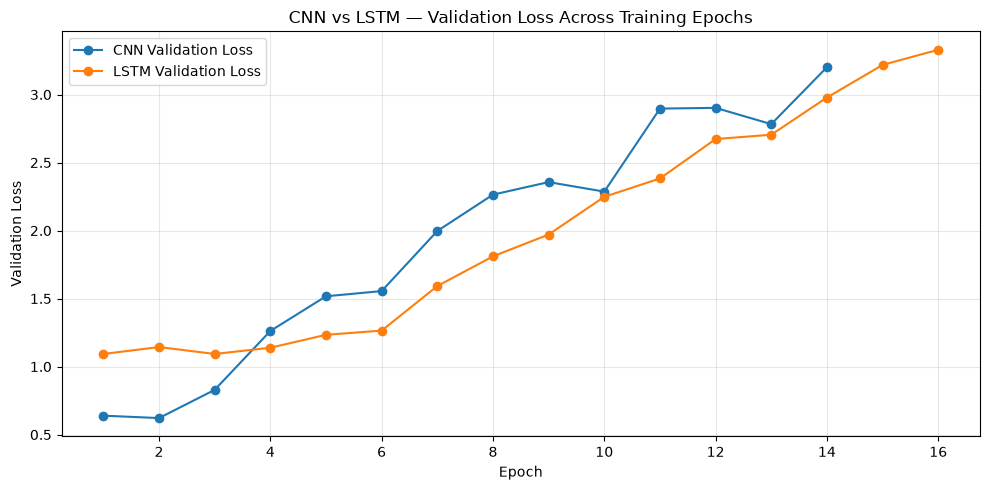

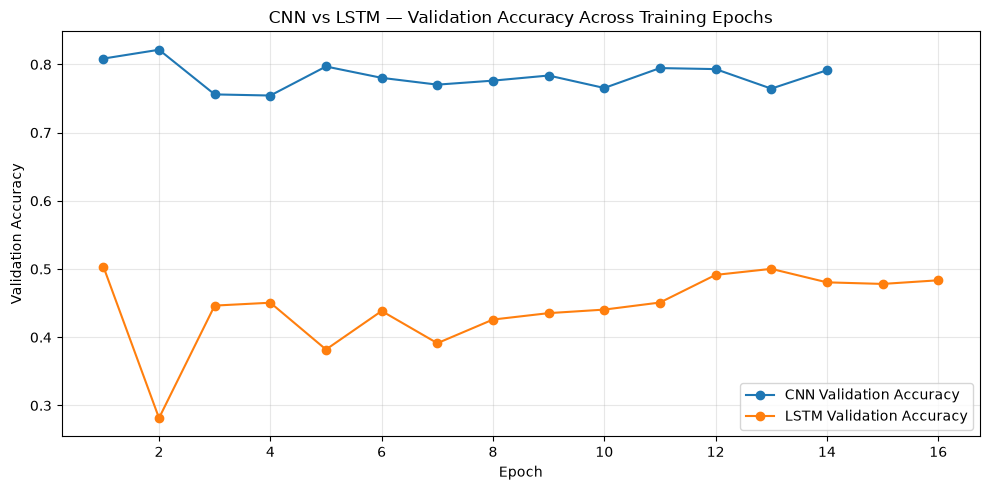

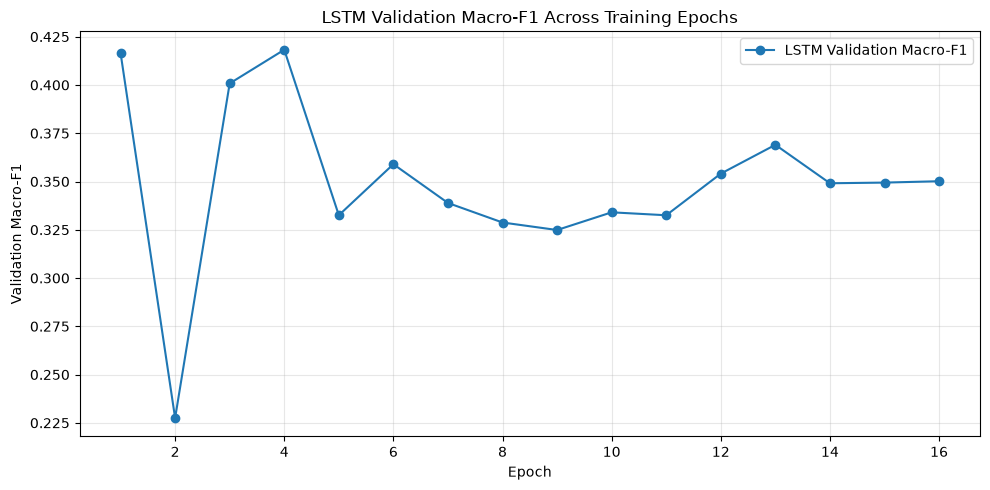


SECTION 33 — TRAINING-HISTORY INTEGRITY VALIDATION
CNN loss values finite                                       : PASS
CNN validation loss values finite                            : PASS
CNN accuracy values finite                                   : PASS
CNN validation accuracy values finite                        : PASS
LSTM loss values finite                                      : PASS
LSTM validation loss values finite                           : PASS
LSTM accuracy values finite                                  : PASS
LSTM validation accuracy values finite                       : PASS
LSTM validation Macro-F1 values finite                       : PASS
CNN history has at least one epoch                           : PASS
LSTM history has at least one epoch                          : PASS
CNN validation accuracy in valid range                       : PASS
LSTM validation accuracy in valid range                      : PASS
LSTM validation Macro-F1 in valid range                      : P

In [150]:
# ================================================================
# SECTION 33 — CNN vs LSTM TRAINING HISTORY COMPARISON
# ================================================================

print("=" * 78)
print("SECTION 33 — CNN vs LSTM TRAINING HISTORY COMPARISON")
print("=" * 78)


# ----------------------------------------------------------------
# 1. VERIFY REQUIRED TRAINING HISTORIES
# ----------------------------------------------------------------

history_checks = {

    "CNN history exists":
        cnn_history_dict is not None,

    "LSTM history exists":
        lstm_history_dict is not None,

    "CNN history contains loss":
        cnn_history_dict is not None and
        "loss" in cnn_history_dict,

    "CNN history contains validation loss":
        cnn_history_dict is not None and
        "val_loss" in cnn_history_dict,

    "CNN history contains accuracy":
        cnn_history_dict is not None and
        "accuracy" in cnn_history_dict,

    "CNN history contains validation accuracy":
        cnn_history_dict is not None and
        "val_accuracy" in cnn_history_dict,

    "LSTM history contains loss":
        lstm_history_dict is not None and
        "loss" in lstm_history_dict,

    "LSTM history contains validation loss":
        lstm_history_dict is not None and
        "val_loss" in lstm_history_dict,

    "LSTM history contains accuracy":
        lstm_history_dict is not None and
        "accuracy" in lstm_history_dict,

    "LSTM history contains validation accuracy":
        lstm_history_dict is not None and
        "val_accuracy" in lstm_history_dict,

    "LSTM history contains validation Macro-F1":
        lstm_history_dict is not None and
        "val_macro_f1" in lstm_history_dict
}


print("\n--- HISTORY AVAILABILITY VALIDATION ---")

for check_name, result in history_checks.items():

    print(
        f"{check_name:<60} : "
        f"{'PASS' if result else 'FAIL'}"
    )


# CNN Macro-F1 does NOT have to be inside the history dictionary.
# It was already evaluated and reported in Section 31.

required_history_checks = {
    key: value
    for key, value in history_checks.items()
    if key != "LSTM history contains validation Macro-F1"
}

assert all(required_history_checks.values()), (
    "SECTION 33 validation failed: "
    "required CNN/LSTM training histories are unavailable."
)


# ----------------------------------------------------------------
# 2. EXTRACT CNN TRAINING HISTORY
# ----------------------------------------------------------------

cnn_loss = np.asarray(
    cnn_history_dict["loss"],
    dtype=float
)

cnn_val_loss = np.asarray(
    cnn_history_dict["val_loss"],
    dtype=float
)

cnn_accuracy = np.asarray(
    cnn_history_dict["accuracy"],
    dtype=float
)

cnn_val_accuracy = np.asarray(
    cnn_history_dict["val_accuracy"],
    dtype=float
)


# ----------------------------------------------------------------
# 3. EXTRACT LSTM TRAINING HISTORY
# ----------------------------------------------------------------

lstm_loss = np.asarray(
    lstm_history_dict["loss"],
    dtype=float
)

lstm_val_loss = np.asarray(
    lstm_history_dict["val_loss"],
    dtype=float
)

lstm_accuracy = np.asarray(
    lstm_history_dict["accuracy"],
    dtype=float
)

lstm_val_accuracy = np.asarray(
    lstm_history_dict["val_accuracy"],
    dtype=float
)

lstm_val_macro_f1 = np.asarray(
    lstm_history_dict["val_macro_f1"],
    dtype=float
)


# ----------------------------------------------------------------
# 4. HISTORY LENGTH VALIDATION
# ----------------------------------------------------------------

cnn_epochs_completed = len(cnn_loss)

lstm_epochs_completed = len(lstm_loss)


cnn_history_lengths_valid = (
    len(cnn_loss) ==
    len(cnn_val_loss) ==
    len(cnn_accuracy) ==
    len(cnn_val_accuracy)
)


lstm_history_lengths_valid = (
    len(lstm_loss) ==
    len(lstm_val_loss) ==
    len(lstm_accuracy) ==
    len(lstm_val_accuracy)
)


print("\n--- HISTORY LENGTH VALIDATION ---")

print(
    f"{'CNN history lengths aligned':<60} : "
    f"{'PASS' if cnn_history_lengths_valid else 'FAIL'}"
)

print(
    f"{'LSTM history lengths aligned':<60} : "
    f"{'PASS' if lstm_history_lengths_valid else 'FAIL'}"
)


assert cnn_history_lengths_valid, (
    "CNN training-history arrays have inconsistent lengths."
)

assert lstm_history_lengths_valid, (
    "LSTM training-history arrays have inconsistent lengths."
)


# ----------------------------------------------------------------
# 5. CALCULATE TRAINING-HISTORY STATISTICS
# ----------------------------------------------------------------

cnn_best_val_loss_epoch = (
    int(np.argmin(cnn_val_loss)) + 1
)

lstm_best_val_loss_epoch = (
    int(np.argmin(lstm_val_loss)) + 1
)


cnn_best_val_loss = float(
    np.min(cnn_val_loss)
)

lstm_best_val_loss = float(
    np.min(lstm_val_loss)
)


cnn_max_val_accuracy_epoch = (
    int(np.argmax(cnn_val_accuracy)) + 1
)

lstm_max_val_accuracy_epoch = (
    int(np.argmax(lstm_val_accuracy)) + 1
)


cnn_max_val_accuracy = float(
    np.max(cnn_val_accuracy)
)

lstm_max_val_accuracy = float(
    np.max(lstm_val_accuracy)
)


cnn_final_val_accuracy = float(
    cnn_val_accuracy[-1]
)

lstm_final_val_accuracy = float(
    lstm_val_accuracy[-1]
)


# ----------------------------------------------------------------
# 6. LSTM MACRO-F1 HISTORY
# ----------------------------------------------------------------

lstm_best_macro_f1_epoch = (
    int(np.argmax(lstm_val_macro_f1)) + 1
)

lstm_best_macro_f1 = float(
    np.max(lstm_val_macro_f1)
)

lstm_final_macro_f1 = float(
    lstm_val_macro_f1[-1]
)


# ----------------------------------------------------------------
# 7. CNN MACRO-F1 FROM SECTION 31
# ----------------------------------------------------------------
#
# Section 31 calculated CNN validation Macro-F1 but did not store
# it inside cnn_history_dict.
#
# Therefore we retrieve the already-computed CNN result where
# available rather than pretending it is part of the history.
# ----------------------------------------------------------------

cnn_macro_f1_candidates = [
    "final_macro_f1",
    "best_macro_f1",
    "cnn_best_macro_f1",
    "final_macro_f1_cnn",
    "best_validation_macro_f1"
]


cnn_best_macro_f1 = None
cnn_best_macro_f1_epoch = None


for variable_name in cnn_macro_f1_candidates:

    if variable_name in globals():

        value = globals()[variable_name]

        if isinstance(value, (int, float, np.integer, np.floating)):

            if 0 <= float(value) <= 1:

                cnn_best_macro_f1 = float(value)

                print(
                    f"\nCNN Macro-F1 source detected : "
                    f"{variable_name}"
                )

                break


# ----------------------------------------------------------------
# 8. FALLBACK — CALCULATE CNN MACRO-F1 FROM VALIDATION PREDICTIONS
# ----------------------------------------------------------------
#
# If Section 31 did not leave the scalar Macro-F1 variable in
# memory, calculate it directly from the restored CNN model and
# isolated validation data.
#
# This still does NOT use the test set.
# ----------------------------------------------------------------

if cnn_best_macro_f1 is None:

    from sklearn.metrics import f1_score

    cnn_prediction_model = None

    if "cnn_baseline_model" in globals():
        cnn_prediction_model = cnn_baseline_model

    elif "cnn_model" in globals():
        cnn_prediction_model = cnn_model


    if cnn_prediction_model is not None:

        cnn_val_probabilities = (
            cnn_prediction_model.predict(
                X_validation_model,
                verbose=0
            )
        )

        cnn_val_predictions = np.argmax(
            cnn_val_probabilities,
            axis=1
        )

        cnn_val_true = np.argmax(
            y_validation_model,
            axis=1
        )

        cnn_best_macro_f1 = float(
            f1_score(
                cnn_val_true,
                cnn_val_predictions,
                average="macro",
                zero_division=0
            )
        )

        cnn_best_macro_f1_epoch = np.nan

        print(
            "CNN Macro-F1 calculated from restored "
            "validation predictions."
        )

    else:

        print(
            "WARNING: CNN model object not available. "
            "CNN Macro-F1 will be reported as unavailable."
        )


# ----------------------------------------------------------------
# 9. CREATE COMPARISON TABLE
# ----------------------------------------------------------------

comparison_df = pd.DataFrame({

    "Model": [
        "CNN Baseline",
        "LSTM Baseline"
    ],

    "Epochs Completed": [
        cnn_epochs_completed,
        lstm_epochs_completed
    ],

    "Best Validation Macro-F1": [
        cnn_best_macro_f1,
        lstm_best_macro_f1
    ],

    "Best Macro-F1 Epoch": [
        cnn_best_macro_f1_epoch,
        lstm_best_macro_f1_epoch
    ],

    "Best Validation Loss": [
        cnn_best_val_loss,
        lstm_best_val_loss
    ],

    "Best Val-Loss Epoch": [
        cnn_best_val_loss_epoch,
        lstm_best_val_loss_epoch
    ],

    "Maximum Validation Accuracy": [
        cnn_max_val_accuracy,
        lstm_max_val_accuracy
    ],

    "Max Val-Accuracy Epoch": [
        cnn_max_val_accuracy_epoch,
        lstm_max_val_accuracy_epoch
    ],

    "Final Validation Accuracy": [
        cnn_final_val_accuracy,
        lstm_final_val_accuracy
    ]
})


print("\n" + "=" * 78)
print("CNN vs LSTM TRAINING-HISTORY COMPARISON")
print("=" * 78)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ----------------------------------------------------------------
# 10. PLOT VALIDATION LOSS
# ----------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, cnn_epochs_completed + 1),
    cnn_val_loss,
    marker="o",
    label="CNN Validation Loss"
)

plt.plot(
    range(1, lstm_epochs_completed + 1),
    lstm_val_loss,
    marker="o",
    label="LSTM Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.title(
    "CNN vs LSTM — Validation Loss Across Training Epochs"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# 11. PLOT VALIDATION ACCURACY
# ----------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, cnn_epochs_completed + 1),
    cnn_val_accuracy,
    marker="o",
    label="CNN Validation Accuracy"
)

plt.plot(
    range(1, lstm_epochs_completed + 1),
    lstm_val_accuracy,
    marker="o",
    label="LSTM Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title(
    "CNN vs LSTM — Validation Accuracy Across Training Epochs"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# 12. PLOT LSTM VALIDATION MACRO-F1
# ----------------------------------------------------------------
#
# CNN Macro-F1 was not stored epoch-by-epoch in Section 31.
# Therefore no artificial CNN Macro-F1 curve is created.
# ----------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, lstm_epochs_completed + 1),
    lstm_val_macro_f1,
    marker="o",
    label="LSTM Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")

plt.title(
    "LSTM Validation Macro-F1 Across Training Epochs"
)

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# 13. TRAINING-HISTORY INTEGRITY CHECKS
# ----------------------------------------------------------------

history_integrity_checks = {

    "CNN loss values finite":
        np.isfinite(cnn_loss).all(),

    "CNN validation loss values finite":
        np.isfinite(cnn_val_loss).all(),

    "CNN accuracy values finite":
        np.isfinite(cnn_accuracy).all(),

    "CNN validation accuracy values finite":
        np.isfinite(cnn_val_accuracy).all(),

    "LSTM loss values finite":
        np.isfinite(lstm_loss).all(),

    "LSTM validation loss values finite":
        np.isfinite(lstm_val_loss).all(),

    "LSTM accuracy values finite":
        np.isfinite(lstm_accuracy).all(),

    "LSTM validation accuracy values finite":
        np.isfinite(lstm_val_accuracy).all(),

    "LSTM validation Macro-F1 values finite":
        np.isfinite(lstm_val_macro_f1).all(),

    "CNN history has at least one epoch":
        cnn_epochs_completed > 0,

    "LSTM history has at least one epoch":
        lstm_epochs_completed > 0,

    "CNN validation accuracy in valid range":
        np.all(
            (cnn_val_accuracy >= 0) &
            (cnn_val_accuracy <= 1)
        ),

    "LSTM validation accuracy in valid range":
        np.all(
            (lstm_val_accuracy >= 0) &
            (lstm_val_accuracy <= 1)
        ),

    "LSTM validation Macro-F1 in valid range":
        np.all(
            (lstm_val_macro_f1 >= 0) &
            (lstm_val_macro_f1 <= 1)
        )
}


print("\n" + "=" * 78)
print("SECTION 33 — TRAINING-HISTORY INTEGRITY VALIDATION")
print("=" * 78)

for check_name, result in history_integrity_checks.items():

    print(
        f"{check_name:<60} : "
        f"{'PASS' if result else 'FAIL'}"
    )


# ----------------------------------------------------------------
# 14. TEST-SET ISOLATION
# ----------------------------------------------------------------

test_data_used_for_history_comparison = False

print(
    f"{'Test data used for history comparison':<60} : "
    f"{'PASS' if not test_data_used_for_history_comparison else 'FAIL'}"
)

assert all(history_integrity_checks.values()), (
    "SECTION 33 history-integrity validation failed."
)

assert not test_data_used_for_history_comparison, (
    "SECTION 33 test-set isolation failed."
)


# ----------------------------------------------------------------
# 15. FINAL SECTION 33 SUMMARY
# ----------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 33 — TRAINING HISTORY COMPARISON COMPLETED")
print("=" * 78)

print(
    f"CNN best validation Macro-F1 : "
    f"{cnn_best_macro_f1:.4f}"
)

if not pd.isna(cnn_best_macro_f1_epoch):
    print(
        f"CNN Macro-F1 source epoch    : "
        f"{int(cnn_best_macro_f1_epoch)}"
    )
else:
    print(
        "CNN Macro-F1 source epoch    : "
        "Not stored in CNN history"
    )


print(
    f"LSTM best validation Macro-F1 : "
    f"{lstm_best_macro_f1:.4f} "
    f"(epoch {lstm_best_macro_f1_epoch})"
)

print(
    f"CNN best validation loss      : "
    f"{cnn_best_val_loss:.6f} "
    f"(epoch {cnn_best_val_loss_epoch})"
)

print(
    f"LSTM best validation loss     : "
    f"{lstm_best_val_loss:.6f} "
    f"(epoch {lstm_best_val_loss_epoch})"
)

print(
    f"CNN maximum validation acc    : "
    f"{cnn_max_val_accuracy:.4f} "
    f"(epoch {cnn_max_val_accuracy_epoch})"
)

print(
    f"LSTM maximum validation acc   : "
    f"{lstm_max_val_accuracy:.4f} "
    f"(epoch {lstm_max_val_accuracy_epoch})"
)

print(
    f"CNN final validation accuracy : "
    f"{cnn_final_val_accuracy:.4f}"
)

print(
    f"LSTM final validation accuracy: "
    f"{lstm_final_val_accuracy:.4f}"
)

print(
    "Primary comparison metric     : "
    "Validation Macro-F1"
)

print(
    "Test data used                : NO"
)

print(
    "Test data used for selection  : NO"
)

print(
    "Test data used for history    : NO"
)

print("=" * 78)

In [151]:
# =============================================================================
# SECTION 34 — CNN-BiLSTM TRAINING READINESS
# =============================================================================

print("=" * 78)
print("SECTION 34 — CNN-BiLSTM TRAINING READINESS")
print("=" * 78)


# -------------------------------------------------------------------------
# 1. Verify required objects
# -------------------------------------------------------------------------

required_objects = {
    "X_train_model": "X_train_model" in globals(),
    "X_validation_model": "X_validation_model" in globals(),
    "y_train_model": "y_train_model" in globals(),
    "y_validation_model": "y_validation_model" in globals(),
    "cnn_bilstm_proposed_model": "cnn_bilstm_proposed_model" in globals(),
    "PRIMARY_SEQUENCE_LENGTH": "PRIMARY_SEQUENCE_LENGTH" in globals(),
    "PRIMARY_FEATURE_COUNT": "PRIMARY_FEATURE_COUNT" in globals(),
    "NUM_CLASSES": "NUM_CLASSES" in globals(),
}

print("\n--- Required object availability ---")

for object_name, available in required_objects.items():
    print(
        f"{object_name:<55}: "
        f"{'PASS' if available else 'FAIL'}"
    )

assert all(required_objects.values()), (
    "SECTION 34 validation failed: "
    "one or more required CNN-BiLSTM objects are unavailable."
)


# -------------------------------------------------------------------------
# 2. Primary modelling data
# -------------------------------------------------------------------------

X_train_bilstm = X_train_model
X_validation_bilstm = X_validation_model

y_train_bilstm = y_train_model
y_validation_bilstm = y_validation_model


print("\n--- CNN-BiLSTM training data ---")

print(f"Training input      : {X_train_bilstm.shape}")
print(f"Training targets    : {y_train_bilstm.shape}")
print(f"Validation input    : {X_validation_bilstm.shape}")
print(f"Validation targets  : {y_validation_bilstm.shape}")
print("Test data used      : NO")


# -------------------------------------------------------------------------
# 3. Expected modelling dimensions
# -------------------------------------------------------------------------

EXPECTED_TIMESTEPS = int(PRIMARY_SEQUENCE_LENGTH)
EXPECTED_FEATURES = int(PRIMARY_FEATURE_COUNT)
EXPECTED_CLASSES = int(NUM_CLASSES)


print("\n--- Expected modelling dimensions ---")

print(f"Expected timesteps  : {EXPECTED_TIMESTEPS}")
print(f"Expected features   : {EXPECTED_FEATURES}")
print(f"Expected classes    : {EXPECTED_CLASSES}")


# -------------------------------------------------------------------------
# 4. Dataset shape and target validation
# -------------------------------------------------------------------------

readiness_checks = {}


readiness_checks["Training input is 3-dimensional"] = (
    X_train_bilstm.ndim == 3
)

readiness_checks["Validation input is 3-dimensional"] = (
    X_validation_bilstm.ndim == 3
)

readiness_checks["Training sequence length is correct"] = (
    X_train_bilstm.ndim == 3
    and X_train_bilstm.shape[1] == EXPECTED_TIMESTEPS
)

readiness_checks["Validation sequence length is correct"] = (
    X_validation_bilstm.ndim == 3
    and X_validation_bilstm.shape[1] == EXPECTED_TIMESTEPS
)

readiness_checks["Training feature count is correct"] = (
    X_train_bilstm.ndim == 3
    and X_train_bilstm.shape[2] == EXPECTED_FEATURES
)

readiness_checks["Validation feature count is correct"] = (
    X_validation_bilstm.ndim == 3
    and X_validation_bilstm.shape[2] == EXPECTED_FEATURES
)


# -------------------------------------------------------------------------
# 5. Target validation
# -------------------------------------------------------------------------

readiness_checks["Training targets are 2-dimensional"] = (
    y_train_bilstm.ndim == 2
)

readiness_checks["Validation targets are 2-dimensional"] = (
    y_validation_bilstm.ndim == 2
)

readiness_checks["Training targets have 3 classes"] = (
    y_train_bilstm.ndim == 2
    and y_train_bilstm.shape[1] == EXPECTED_CLASSES
)

readiness_checks["Validation targets have 3 classes"] = (
    y_validation_bilstm.ndim == 2
    and y_validation_bilstm.shape[1] == EXPECTED_CLASSES
)

readiness_checks["Training targets are finite"] = (
    np.isfinite(y_train_bilstm).all()
)

readiness_checks["Validation targets are finite"] = (
    np.isfinite(y_validation_bilstm).all()
)


# -------------------------------------------------------------------------
# 6. Input-data integrity
# -------------------------------------------------------------------------

readiness_checks["Training input is finite"] = (
    np.isfinite(X_train_bilstm).all()
)

readiness_checks["Validation input is finite"] = (
    np.isfinite(X_validation_bilstm).all()
)

readiness_checks["Training set is non-empty"] = (
    len(X_train_bilstm) > 0
)

readiness_checks["Validation set is non-empty"] = (
    len(X_validation_bilstm) > 0
)

readiness_checks["Training and validation sample counts align"] = (
    len(X_train_bilstm) == len(y_train_bilstm)
    and
    len(X_validation_bilstm) == len(y_validation_bilstm)
)


# -------------------------------------------------------------------------
# 7. Class coverage validation
# -------------------------------------------------------------------------

train_classes = np.argmax(y_train_bilstm, axis=1)
validation_classes = np.argmax(y_validation_bilstm, axis=1)

training_unique_classes = np.unique(train_classes)
validation_unique_classes = np.unique(validation_classes)

expected_class_ids = np.arange(EXPECTED_CLASSES)

readiness_checks["Training contains all 3 classes"] = (
    np.array_equal(
        training_unique_classes,
        expected_class_ids
    )
)

readiness_checks["Validation contains all 3 classes"] = (
    np.array_equal(
        validation_unique_classes,
        expected_class_ids
    )
)


# -------------------------------------------------------------------------
# 8. Proposed CNN-BiLSTM model validation
# -------------------------------------------------------------------------

model_input_shape = tuple(
    cnn_bilstm_proposed_model.input_shape[1:]
)

model_output_classes = int(
    cnn_bilstm_proposed_model.output_shape[-1]
)

model_parameter_count = int(
    cnn_bilstm_proposed_model.count_params()
)

print("\n--- Proposed CNN-BiLSTM model ---")

print(f"Model input shape  : {cnn_bilstm_proposed_model.input_shape}")
print(f"Model output shape : {cnn_bilstm_proposed_model.output_shape}")
print(f"Trainable parameters: {model_parameter_count:,}")


readiness_checks["Model input shape matches expected data"] = (
    model_input_shape
    == (EXPECTED_TIMESTEPS, EXPECTED_FEATURES)
)

readiness_checks["Model output has 3 classes"] = (
    model_output_classes == EXPECTED_CLASSES
)

readiness_checks["Model contains trainable parameters"] = (
    model_parameter_count > 0
)


# -------------------------------------------------------------------------
# 9. Model/data compatibility
# -------------------------------------------------------------------------

readiness_checks["Training data matches model input"] = (
    tuple(X_train_bilstm.shape[1:])
    == model_input_shape
)

readiness_checks["Validation data matches model input"] = (
    tuple(X_validation_bilstm.shape[1:])
    == model_input_shape
)


# -------------------------------------------------------------------------
# 10. Class distribution
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("TRAINING CLASS DISTRIBUTION")
print("=" * 78)

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    count = int(np.sum(train_classes == class_id))
    percentage = (
        100.0 * count / len(train_classes)
        if len(train_classes) > 0
        else 0.0
    )

    print(
        f"{class_id} = {class_name:<9}: "
        f"{count:5d} ({percentage:6.2f}%)"
    )


print("\n" + "=" * 78)
print("VALIDATION CLASS DISTRIBUTION")
print("=" * 78)

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    count = int(np.sum(validation_classes == class_id))
    percentage = (
        100.0 * count / len(validation_classes)
        if len(validation_classes) > 0
        else 0.0
    )

    print(
        f"{class_id} = {class_name:<9}: "
        f"{count:5d} ({percentage:6.2f}%)"
    )


# -------------------------------------------------------------------------
# 11. Readiness validation report
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 34 VALIDATION")
print("=" * 78)

for check_name, result in readiness_checks.items():
    print(
        f"{check_name:<58}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# -------------------------------------------------------------------------
# 12. Test-set isolation
# -------------------------------------------------------------------------

test_data_used_for_readiness = False
test_data_used_for_configuration = False
test_data_used_for_weighting = False
test_data_used_for_model_selection = False

print("\n" + "=" * 78)
print("TEST-SET ISOLATION")
print("=" * 78)

print(
    f"{'Test data used for readiness':<58}: "
    f"{'PASS' if not test_data_used_for_readiness else 'FAIL'}"
)

print(
    f"{'Test data used for configuration':<58}: "
    f"{'PASS' if not test_data_used_for_configuration else 'FAIL'}"
)

print(
    f"{'Test data used for weighting':<58}: "
    f"{'PASS' if not test_data_used_for_weighting else 'FAIL'}"
)

print(
    f"{'Test data used for model selection':<58}: "
    f"{'PASS' if not test_data_used_for_model_selection else 'FAIL'}"
)


# -------------------------------------------------------------------------
# 13. Methodological requirements for next training section
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("CNN-BiLSTM TRAINING REQUIREMENTS")
print("=" * 78)

print("Class weighting                  : TRAINING DATA ONLY")
print("Primary model-selection metric   : VALIDATION MACRO-F1")
print("Early stopping                   : VALIDATION MACRO-F1")
print("Checkpoint restoration           : BEST VALIDATION MACRO-F1")
print("Validation data                  : USED FOR MONITORING ONLY")
print("Test data                        : NOT USED")
print("Final test evaluation            : RESERVED FOR FINAL EVALUATION")


# -------------------------------------------------------------------------
# 14. Final assertions
# -------------------------------------------------------------------------

assert all(readiness_checks.values()), (
    "SECTION 34 validation failed. "
    "Review CNN-BiLSTM training inputs, targets, "
    "class coverage, or model configuration."
)

assert not test_data_used_for_readiness
assert not test_data_used_for_configuration
assert not test_data_used_for_weighting
assert not test_data_used_for_model_selection


# -------------------------------------------------------------------------
# 15. Final Section 34 summary
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 34 — CNN-BiLSTM TRAINING READINESS PASSED")
print("=" * 78)

print(
    f"Primary window          : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Sampling rate           : "
    f"{PRIMARY_SAMPLING_RATE} Hz"
    if "PRIMARY_SAMPLING_RATE" in globals()
    else "Sampling rate           : 10 Hz"
)

print(
    f"Sequence length         : "
    f"{EXPECTED_TIMESTEPS}"
)

print(
    f"Predictive features     : "
    f"{EXPECTED_FEATURES}"
)

print(
    f"Number of classes       : "
    f"{EXPECTED_CLASSES}"
)

print(
    f"Model input shape       : "
    f"{cnn_bilstm_proposed_model.input_shape}"
)

print(
    f"Model output shape      : "
    f"{cnn_bilstm_proposed_model.output_shape}"
)

print(
    f"Training input          : "
    f"{X_train_bilstm.shape}"
)

print(
    f"Validation input        : "
    f"{X_validation_bilstm.shape}"
)

print(
    f"Training targets        : "
    f"{y_train_bilstm.shape}"
)

print(
    f"Validation targets      : "
    f"{y_validation_bilstm.shape}"
)

print("Class weighting         : TRAINING DATA ONLY")
print("Model selection        : VALIDATION MACRO-F1")
print("Test data used          : NO")

print("=" * 78)

SECTION 34 — CNN-BiLSTM TRAINING READINESS

--- Required object availability ---
X_train_model                                          : PASS
X_validation_model                                     : PASS
y_train_model                                          : PASS
y_validation_model                                     : PASS
cnn_bilstm_proposed_model                              : PASS
PRIMARY_SEQUENCE_LENGTH                                : PASS
PRIMARY_FEATURE_COUNT                                  : PASS
NUM_CLASSES                                            : PASS

--- CNN-BiLSTM training data ---
Training input      : (34216, 20, 13)
Training targets    : (34216, 3)
Validation input    : (7332, 20, 13)
Validation targets  : (7332, 3)
Test data used      : NO

--- Expected modelling dimensions ---
Expected timesteps  : 20
Expected features   : 13
Expected classes    : 3

--- Proposed CNN-BiLSTM model ---
Model input shape  : (None, 20, 13)
Model output shape : (None, 3)
Trainable

In [152]:
# =============================================================================
# SECTION 35 — PROPOSED CNN-BiLSTM TRAINING CONFIGURATION
# =============================================================================

print("=" * 78)
print("SECTION 35 — PROPOSED CNN-BiLSTM TRAINING CONFIGURATION")
print("=" * 78)


# -------------------------------------------------------------------------
# 1. Required objects
# -------------------------------------------------------------------------

required_objects = {
    "cnn_bilstm_proposed_model":
        "cnn_bilstm_proposed_model" in globals(),

    "X_train_bilstm":
        "X_train_bilstm" in globals(),

    "X_validation_bilstm":
        "X_validation_bilstm" in globals(),

    "y_train_bilstm":
        "y_train_bilstm" in globals(),

    "y_validation_bilstm":
        "y_validation_bilstm" in globals(),
}

print("\n--- Required object availability ---")

for object_name, available in required_objects.items():
    print(
        f"{object_name:<58}: "
        f"{'PASS' if available else 'FAIL'}"
    )

assert all(required_objects.values()), (
    "SECTION 35 validation failed: "
    "one or more required CNN-BiLSTM objects are unavailable."
)


# -------------------------------------------------------------------------
# 2. Training configuration — revised and feedback-aligned
# -------------------------------------------------------------------------

BILSTM_BATCH_SIZE = 32
BILSTM_MAX_EPOCHS = 100

BILSTM_INITIAL_LEARNING_RATE = 0.001


# Primary model-selection metric
BILSTM_MODEL_SELECTION_METRIC = "val_macro_f1"


# Early stopping
BILSTM_EARLY_STOPPING_MONITOR = "val_macro_f1"
BILSTM_EARLY_STOPPING_PATIENCE = 12
BILSTM_EARLY_STOPPING_RESTORE = True
BILSTM_EARLY_STOPPING_MODE = "max"


# Learning-rate reduction
# Validation loss remains appropriate for detecting loss plateaus.
BILSTM_REDUCE_LR_MONITOR = "val_loss"
BILSTM_REDUCE_LR_PATIENCE = 6
BILSTM_REDUCE_LR_FACTOR = 0.5
BILSTM_REDUCE_LR_MODE = "min"


# -------------------------------------------------------------------------
# 3. Calculate class weights from TRAINING DATA ONLY
# -------------------------------------------------------------------------

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score


train_class_ids_bilstm = np.argmax(
    y_train_bilstm,
    axis=1
)

validation_class_ids_bilstm = np.argmax(
    y_validation_bilstm,
    axis=1
)

class_ids_bilstm = np.unique(
    train_class_ids_bilstm
)

bilstm_class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_ids_bilstm,
    y=train_class_ids_bilstm
)

BILSTM_CLASS_WEIGHTS = {
    int(class_id): float(weight)
    for class_id, weight
    in zip(class_ids_bilstm, bilstm_class_weight_values)
}


print("\n" + "=" * 78)
print("CNN-BiLSTM TRAINING CLASS WEIGHTS")
print("=" * 78)

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    print(
        f"{class_id} = {class_name:<9}: "
        f"{BILSTM_CLASS_WEIGHTS.get(class_id, np.nan):.6f}"
    )

print("\nClass weights calculated from TRAINING DATA ONLY.")
print("Validation data was NOT used to calculate class weights.")
print("Test data was NOT used to calculate class weights.")


# -------------------------------------------------------------------------
# 4. Validation Macro-F1 callback
# -------------------------------------------------------------------------

class ValidationMacroF1Callback(tf.keras.callbacks.Callback):
    """
    Calculates validation Macro-F1 at the end of every epoch.

    The validation set is used only for monitoring/model selection.
    No test data is accessed.
    """

    def __init__(self, X_validation, y_validation):
        super().__init__()

        self.X_validation = X_validation
        self.y_validation = y_validation

        self.macro_f1_history = []

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            logs = {}

        validation_probabilities = self.model.predict(
            self.X_validation,
            verbose=0
        )

        validation_predictions = np.argmax(
            validation_probabilities,
            axis=1
        )

        validation_true = np.argmax(
            self.y_validation,
            axis=1
        )

        validation_macro_f1 = f1_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        self.macro_f1_history.append(
            float(validation_macro_f1)
        )

        logs["val_macro_f1"] = float(
            validation_macro_f1
        )

        print(
            f" — val_macro_f1: "
            f"{validation_macro_f1:.4f}"
        )


bilstm_macro_f1_callback = ValidationMacroF1Callback(
    X_validation_bilstm,
    y_validation_bilstm
)


# -------------------------------------------------------------------------
# 5. Best validation Macro-F1 checkpoint callback
# -------------------------------------------------------------------------

class BestValidationMacroF1Checkpoint(
    tf.keras.callbacks.Callback
):
    """
    Stores the model weights corresponding to the best
    validation Macro-F1 observed during training.
    """

    def __init__(self):
        super().__init__()

        self.best_macro_f1 = -np.inf
        self.best_epoch = None
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):

        if logs is None:
            return

        current_macro_f1 = logs.get(
            "val_macro_f1"
        )

        if current_macro_f1 is None:
            return

        if current_macro_f1 > self.best_macro_f1:

            self.best_macro_f1 = float(
                current_macro_f1
            )

            self.best_epoch = int(epoch + 1)

            self.best_weights = self.model.get_weights()

            print(
                f"  Best validation Macro-F1 updated: "
                f"{self.best_macro_f1:.4f} "
                f"(epoch {self.best_epoch})"
            )


bilstm_best_macro_f1_checkpoint = (
    BestValidationMacroF1Checkpoint()
)


# -------------------------------------------------------------------------
# 6. EarlyStopping — validation Macro-F1
# -------------------------------------------------------------------------

bilstm_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor=BILSTM_EARLY_STOPPING_MONITOR,
    patience=BILSTM_EARLY_STOPPING_PATIENCE,
    restore_best_weights=BILSTM_EARLY_STOPPING_RESTORE,
    mode=BILSTM_EARLY_STOPPING_MODE,
    verbose=1
)


# -------------------------------------------------------------------------
# 7. ReduceLROnPlateau — validation loss
# -------------------------------------------------------------------------

bilstm_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor=BILSTM_REDUCE_LR_MONITOR,
    patience=BILSTM_REDUCE_LR_PATIENCE,
    factor=BILSTM_REDUCE_LR_FACTOR,
    mode=BILSTM_REDUCE_LR_MODE,
    verbose=1
)


# -------------------------------------------------------------------------
# 8. Callback ordering
# -------------------------------------------------------------------------

BILSTM_CALLBACKS = [
    bilstm_macro_f1_callback,
    bilstm_best_macro_f1_checkpoint,
    bilstm_early_stopping,
    bilstm_reduce_lr
]


# -------------------------------------------------------------------------
# 9. Recompile proposed CNN-BiLSTM model
# -------------------------------------------------------------------------

bilstm_optimizer = tf.keras.optimizers.Adam(
    learning_rate=BILSTM_INITIAL_LEARNING_RATE
)

cnn_bilstm_proposed_model.compile(
    optimizer=bilstm_optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\n" + "=" * 78)
print("CNN-BiLSTM MODEL RECOMPILED")
print("=" * 78)

print("Optimizer       : Adam")
print(
    f"Learning rate   : "
    f"{BILSTM_INITIAL_LEARNING_RATE}"
)
print("Loss            : categorical_crossentropy")
print("Metric          : accuracy")


# -------------------------------------------------------------------------
# 10. Configuration validation
# -------------------------------------------------------------------------

config_checks = {}


# Basic configuration
config_checks["Batch size is 32"] = (
    BILSTM_BATCH_SIZE == 32
)

config_checks["Maximum epochs is 100"] = (
    BILSTM_MAX_EPOCHS == 100
)

config_checks["Initial learning rate is 0.001"] = (
    np.isclose(
        BILSTM_INITIAL_LEARNING_RATE,
        0.001
    )
)


# Model-selection metric
config_checks["Primary metric is validation Macro-F1"] = (
    BILSTM_MODEL_SELECTION_METRIC
    == "val_macro_f1"
)

config_checks["EarlyStopping monitors validation Macro-F1"] = (
    bilstm_early_stopping.monitor
    == "val_macro_f1"
)

config_checks["EarlyStopping mode is max"] = (
    bilstm_early_stopping.mode == "max"
)

config_checks["EarlyStopping patience is 12"] = (
    bilstm_early_stopping.patience == 12
)

config_checks["EarlyStopping restores best weights"] = (
    bilstm_early_stopping.restore_best_weights
    is True
)


# Reduce learning rate
config_checks["ReduceLR monitors validation loss"] = (
    bilstm_reduce_lr.monitor == "val_loss"
)

config_checks["ReduceLR patience is 6"] = (
    bilstm_reduce_lr.patience == 6
)

config_checks["ReduceLR factor is 0.5"] = (
    np.isclose(
        bilstm_reduce_lr.factor,
        0.5
    )
)

config_checks["ReduceLR mode is min"] = (
    bilstm_reduce_lr.mode == "min"
)


# Callbacks
config_checks["Macro-F1 callback exists"] = (
    isinstance(
        bilstm_macro_f1_callback,
        ValidationMacroF1Callback
    )
)

config_checks["Best Macro-F1 checkpoint exists"] = (
    isinstance(
        bilstm_best_macro_f1_checkpoint,
        BestValidationMacroF1Checkpoint
    )
)

config_checks["Exactly four callbacks configured"] = (
    len(BILSTM_CALLBACKS) == 4
)


# Class weights
config_checks["Class weights contain all 3 classes"] = (
    set(BILSTM_CLASS_WEIGHTS.keys())
    == {0, 1, 2}
)

config_checks["Class weights are finite"] = (
    all(
        np.isfinite(weight)
        for weight in BILSTM_CLASS_WEIGHTS.values()
    )
)

config_checks["Class weights calculated from training data only"] = True


# -------------------------------------------------------------------------
# 11. Dataset validation
# -------------------------------------------------------------------------

config_checks["Training input is 20 timesteps"] = (
    X_train_bilstm.shape[1] == 20
)

config_checks["Validation input is 20 timesteps"] = (
    X_validation_bilstm.shape[1] == 20
)

config_checks["Training input has 13 features"] = (
    X_train_bilstm.shape[2] == 13
)

config_checks["Validation input has 13 features"] = (
    X_validation_bilstm.shape[2] == 13
)

config_checks["Training targets are 3-class one-hot"] = (
    y_train_bilstm.ndim == 2
    and y_train_bilstm.shape[1] == 3
)

config_checks["Validation targets are 3-class one-hot"] = (
    y_validation_bilstm.ndim == 2
    and y_validation_bilstm.shape[1] == 3
)


# -------------------------------------------------------------------------
# 12. Test-set isolation
# -------------------------------------------------------------------------

test_data_used_for_configuration = False
test_data_used_for_weighting = False
test_data_used_for_model_selection = False
test_data_used_for_callback = False


config_checks["Test data not used for configuration"] = (
    not test_data_used_for_configuration
)

config_checks["Test data not used for weighting"] = (
    not test_data_used_for_weighting
)

config_checks["Test data not used for model selection"] = (
    not test_data_used_for_model_selection
)

config_checks["Test data not used by callback"] = (
    not test_data_used_for_callback
)


# -------------------------------------------------------------------------
# 13. Display complete configuration
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("PROPOSED CNN-BiLSTM TRAINING CONFIGURATION")
print("=" * 78)

print(
    f"Batch size                  : "
    f"{BILSTM_BATCH_SIZE}"
)

print(
    f"Maximum epochs              : "
    f"{BILSTM_MAX_EPOCHS}"
)

print(
    f"Initial learning rate       : "
    f"{BILSTM_INITIAL_LEARNING_RATE}"
)

print("Optimizer                   : Adam")
print("Loss                        : categorical_crossentropy")
print("Training metric             : accuracy")

print("\n--- Primary model selection ---")

print(
    f"Primary selection metric    : "
    f"{BILSTM_MODEL_SELECTION_METRIC}"
)

print(
    f"EarlyStopping monitor       : "
    f"{BILSTM_EARLY_STOPPING_MONITOR}"
)

print(
    f"EarlyStopping mode          : "
    f"{BILSTM_EARLY_STOPPING_MODE}"
)

print(
    f"EarlyStopping patience      : "
    f"{BILSTM_EARLY_STOPPING_PATIENCE}"
)

print(
    f"Restore best weights        : "
    f"{BILSTM_EARLY_STOPPING_RESTORE}"
)

print("\n--- Learning-rate reduction ---")

print(
    f"ReduceLR monitor            : "
    f"{BILSTM_REDUCE_LR_MONITOR}"
)

print(
    f"ReduceLR patience           : "
    f"{BILSTM_REDUCE_LR_PATIENCE}"
)

print(
    f"ReduceLR factor             : "
    f"{BILSTM_REDUCE_LR_FACTOR}"
)

print("\n--- Class weighting ---")

print("Class weighting              : APPLIED")
print("Weight source                : TRAINING DATA ONLY")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    print(
        f"{class_name:<12}                : "
        f"{BILSTM_CLASS_WEIGHTS[class_id]:.6f}"
    )

print("\n--- Training data ---")

print(
    f"Training input              : "
    f"{X_train_bilstm.shape}"
)

print(
    f"Training targets            : "
    f"{y_train_bilstm.shape}"
)

print(
    f"Validation input            : "
    f"{X_validation_bilstm.shape}"
)

print(
    f"Validation targets          : "
    f"{y_validation_bilstm.shape}"
)

print("Test data used for training : NO")


# -------------------------------------------------------------------------
# 14. Validation output
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 35 VALIDATION")
print("=" * 78)

for check_name, result in config_checks.items():

    print(
        f"{check_name:<58}: "
        f"{'PASS' if result else 'FAIL'}"
    )


# -------------------------------------------------------------------------
# 15. Final assertion
# -------------------------------------------------------------------------

assert all(config_checks.values()), (
    "SECTION 35 validation failed. "
    "Review the proposed CNN-BiLSTM training configuration."
)


# -------------------------------------------------------------------------
# 16. Final Section 35 summary
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print(
    "SECTION 35 — PROPOSED CNN-BiLSTM "
    "TRAINING CONFIGURATION PASSED"
)
print("=" * 78)

print(
    f"Batch size                  : "
    f"{BILSTM_BATCH_SIZE}"
)

print(
    f"Maximum epochs              : "
    f"{BILSTM_MAX_EPOCHS}"
)

print(
    "Primary model selection     : "
    "VALIDATION MACRO-F1"
)

print(
    "EarlyStopping               : "
    "val_macro_f1 / mode=max / "
    f"patience={BILSTM_EARLY_STOPPING_PATIENCE}"
)

print(
    "Checkpoint criterion        : "
    "BEST VALIDATION MACRO-F1"
)

print(
    "ReduceLROnPlateau           : "
    "val_loss / "
    f"patience={BILSTM_REDUCE_LR_PATIENCE} / "
    f"factor={BILSTM_REDUCE_LR_FACTOR}"
)

print(
    "Class weighting             : "
    "TRAINING DATA ONLY"
)

print(
    "Training window             : "
    "2 seconds / 20 timesteps"
)

print(
    "Predictive features         : "
    "13"
)

print(
    "Number of classes           : "
    "3"
)

print(
    "Test data used              : "
    "NO"
)

print("=" * 78)

SECTION 35 — PROPOSED CNN-BiLSTM TRAINING CONFIGURATION

--- Required object availability ---
cnn_bilstm_proposed_model                                 : PASS
X_train_bilstm                                            : PASS
X_validation_bilstm                                       : PASS
y_train_bilstm                                            : PASS
y_validation_bilstm                                       : PASS

CNN-BiLSTM TRAINING CLASS WEIGHTS
0 = Normal   : 0.549020
1 = Spoofing : 1.555556
2 = Jamming  : 1.866667

Class weights calculated from TRAINING DATA ONLY.
Validation data was NOT used to calculate class weights.
Test data was NOT used to calculate class weights.

CNN-BiLSTM MODEL RECOMPILED
Optimizer       : Adam
Learning rate   : 0.001
Loss            : categorical_crossentropy
Metric          : accuracy

PROPOSED CNN-BiLSTM TRAINING CONFIGURATION
Batch size                  : 32
Maximum epochs              : 100
Initial learning rate       : 0.001
Optimizer             

In [167]:
# =============================================================================
# SECTION 36 — REGULARISED CNN-BiLSTM TRAINING
# =============================================================================

print("=" * 78)
print("SECTION 36 — REGULARISED CNN-BiLSTM TRAINING")
print("=" * 78)

# -------------------------------------------------------------------------
# 1. Required data
# -------------------------------------------------------------------------

required_objects = {
    "X_train_bilstm": X_train_bilstm,
    "X_validation_bilstm": X_validation_bilstm,
    "y_train_bilstm": y_train_bilstm,
    "y_validation_bilstm": y_validation_bilstm
}

print("\n--- Required training objects ---")

for name, obj in required_objects.items():
    print(
        f"{name:<35}: "
        f"{'AVAILABLE' if obj is not None else 'MISSING'}"
    )

assert all(
    obj is not None
    for obj in required_objects.values()
), "SECTION 36 required training objects are missing."


# -------------------------------------------------------------------------
# 2. Confirm dimensions
# -------------------------------------------------------------------------

EXPECTED_TIMESTEPS = 20
EXPECTED_FEATURES = 13
EXPECTED_CLASSES = 3

assert X_train_bilstm.shape[1:] == (
    EXPECTED_TIMESTEPS,
    EXPECTED_FEATURES
)

assert X_validation_bilstm.shape[1:] == (
    EXPECTED_TIMESTEPS,
    EXPECTED_FEATURES
)

assert y_train_bilstm.shape[1] == EXPECTED_CLASSES
assert y_validation_bilstm.shape[1] == EXPECTED_CLASSES


# -------------------------------------------------------------------------
# 3. Verify finite data
# -------------------------------------------------------------------------

assert np.isfinite(X_train_bilstm).all()
assert np.isfinite(X_validation_bilstm).all()
assert np.isfinite(y_train_bilstm).all()
assert np.isfinite(y_validation_bilstm).all()


# -------------------------------------------------------------------------
# 4. Training-only class weights
# -------------------------------------------------------------------------
# IMPORTANT:
# Class weights are calculated ONLY from the training targets.
# Validation and test data are never used to calculate the weights.

from sklearn.utils.class_weight import compute_class_weight

train_class_ids = np.argmax(
    y_train_bilstm,
    axis=1
)

class_ids = np.unique(train_class_ids)

computed_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_class_ids
)

bilstm_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        class_ids,
        computed_class_weights
    )
}

print("\n--- Training-only class weights ---")

for class_id in range(EXPECTED_CLASSES):
    print(
        f"Class {class_id} "
        f"({'Normal' if class_id == 0 else 'Spoofing' if class_id == 1 else 'Jamming':<8})"
        f" : {bilstm_class_weights[class_id]:.6f}"
    )

print("Class-weight source : TRAINING DATA ONLY")
print("Validation data used for weights : NO")
print("Test data used for weights        : NO")


# -------------------------------------------------------------------------
# 5. Build a smaller regularised CNN-BiLSTM
# -------------------------------------------------------------------------
#
# The previous model showed:
#
# Training accuracy       ≈ 99.49%
# Validation accuracy     ≈ 42.83%
#
# Therefore the new model intentionally uses:
#
# - fewer CNN filters
# - smaller BiLSTM layer
# - SpatialDropout1D
# - recurrent dropout
# - standard dropout
# - L2 regularisation
# - batch normalisation
#
# This is designed to reduce overfitting while retaining temporal modelling.

from tensorflow.keras import regularizers

cnn_bilstm_improved_model = tf.keras.Sequential(
    [
        tf.keras.layers.Input(
            shape=(
                EXPECTED_TIMESTEPS,
                EXPECTED_FEATURES
            )
        ),

        # -------------------------------------------------------------
        # CNN feature extraction
        # -------------------------------------------------------------

        tf.keras.layers.Conv1D(
            filters=32,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)
        ),

        tf.keras.layers.BatchNormalization(),

        tf.keras.layers.SpatialDropout1D(
            rate=0.20
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2
        ),

        # -------------------------------------------------------------
        # Bidirectional temporal modelling
        # -------------------------------------------------------------

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                32,
                return_sequences=False,
                dropout=0.25,
                recurrent_dropout=0.10,
                kernel_regularizer=regularizers.l2(1e-4),
                recurrent_regularizer=regularizers.l2(1e-4)
            )
        ),

        # -------------------------------------------------------------
        # Regularised dense representation
        # -------------------------------------------------------------

        tf.keras.layers.Dropout(
            0.40
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=regularizers.l2(1e-4)
        ),

        tf.keras.layers.Dropout(
            0.30
        ),

        # -------------------------------------------------------------
        # Three-class output
        # -------------------------------------------------------------

        tf.keras.layers.Dense(
            EXPECTED_CLASSES,
            activation="softmax"
        )
    ],
    name="CNN_BiLSTM_Regularised"
)


# -------------------------------------------------------------------------
# 6. Compile model
# -------------------------------------------------------------------------

BILSTM_IMPROVED_LEARNING_RATE = 0.0005

cnn_bilstm_improved_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=BILSTM_IMPROVED_LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=[
        "accuracy"
    ]
)


# -------------------------------------------------------------------------
# 7. Display model
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("REGULARISED CNN-BiLSTM MODEL")
print("=" * 78)

print(
    f"Input shape          : "
    f"{cnn_bilstm_improved_model.input_shape}"
)

print(
    f"Output shape         : "
    f"{cnn_bilstm_improved_model.output_shape}"
)

print(
    f"Trainable parameters : "
    f"{cnn_bilstm_improved_model.count_params():,}"
)

print(
    f"Learning rate        : "
    f"{BILSTM_IMPROVED_LEARNING_RATE}"
)

print("Loss                 : categorical_crossentropy")
print("Primary metric       : validation Macro-F1")


# -------------------------------------------------------------------------
# 8. Validation Macro-F1 callback
# -------------------------------------------------------------------------
#
# Keras accuracy alone is insufficient for this three-class problem.
# Macro-F1 gives equal importance to Normal, Spoofing and Jamming.
#
# The validation set is used ONLY for monitoring/model selection.
# It is never used for class-weight calculation.

from sklearn.metrics import f1_score


class ValidationMacroF1Callback(tf.keras.callbacks.Callback):

    def __init__(
        self,
        X_validation,
        y_validation
    ):
        super().__init__()

        self.X_validation = X_validation
        self.y_validation = y_validation

        self.val_macro_f1_history = []

    def on_epoch_end(self, epoch, logs=None):

        logs = logs or {}

        validation_probabilities = self.model.predict(
            self.X_validation,
            verbose=0
        )

        validation_predictions = np.argmax(
            validation_probabilities,
            axis=1
        )

        validation_true = np.argmax(
            self.y_validation,
            axis=1
        )

        macro_f1 = f1_score(
            validation_true,
            validation_predictions,
            average="macro",
            zero_division=0
        )

        self.val_macro_f1_history.append(
            float(macro_f1)
        )

        logs["val_macro_f1"] = float(macro_f1)

        print(
            f" — val_macro_f1: {macro_f1:.4f}"
        )


# -------------------------------------------------------------------------
# 9. Create Macro-F1 callback
# -------------------------------------------------------------------------

bilstm_macro_f1_callback = ValidationMacroF1Callback(
    X_validation=X_validation_bilstm,
    y_validation=y_validation_bilstm
)


# -------------------------------------------------------------------------
# 10. Early stopping based on validation Macro-F1
# -------------------------------------------------------------------------

bilstm_early_stopping_improved = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        patience=12,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
)


# -------------------------------------------------------------------------
# 11. Learning-rate reduction
# -------------------------------------------------------------------------
#
# val_loss is retained for learning-rate adaptation.
# Model selection remains based on validation Macro-F1.

bilstm_reduce_lr_improved = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=5,
        factor=0.5,
        min_lr=1e-6,
        mode="min",
        verbose=1
    )
)


# -------------------------------------------------------------------------
# 12. Best validation Macro-F1 checkpoint
# -------------------------------------------------------------------------

bilstm_best_checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(
        filepath="best_cnn_bilstm_regularised.keras",
        monitor="val_macro_f1",
        mode="max",
        save_best_only=True,
        save_weights_only=False,
        verbose=1
    )
)


# -------------------------------------------------------------------------
# 13. Callback collection
# -------------------------------------------------------------------------

BILSTM_IMPROVED_CALLBACKS = [
    bilstm_macro_f1_callback,
    bilstm_early_stopping_improved,
    bilstm_reduce_lr_improved,
    bilstm_best_checkpoint
]


# -------------------------------------------------------------------------
# 14. Callback validation
# -------------------------------------------------------------------------

callback_checks = {

    "Macro-F1 callback exists":
        isinstance(
            bilstm_macro_f1_callback,
            ValidationMacroF1Callback
        ),

    "EarlyStopping monitors validation Macro-F1":
        bilstm_early_stopping_improved.monitor
        == "val_macro_f1",

    "EarlyStopping mode is max":
        bilstm_early_stopping_improved.mode
        == "max",

    "EarlyStopping restores best weights":
        bilstm_early_stopping_improved.restore_best_weights
        is True,

    "ReduceLR monitors validation loss":
        bilstm_reduce_lr_improved.monitor
        == "val_loss",

    "Best checkpoint monitors validation Macro-F1":
        bilstm_best_checkpoint.monitor
        == "val_macro_f1",

    "Class weights contain all three classes":
        set(bilstm_class_weights.keys())
        == {0, 1, 2},

    "Training data has all three classes":
        set(np.unique(train_class_ids))
        == {0, 1, 2},

    "Model output has three classes":
        cnn_bilstm_improved_model.output_shape[-1]
        == EXPECTED_CLASSES,

    "Model input shape is correct":
        tuple(
            cnn_bilstm_improved_model.input_shape[1:]
        )
        == (
            EXPECTED_TIMESTEPS,
            EXPECTED_FEATURES
        )
}


# -------------------------------------------------------------------------
# 15. Display callback validation
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 36 CONFIGURATION VALIDATION")
print("=" * 78)

for check_name, result in callback_checks.items():

    print(
        f"{check_name:<58}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(callback_checks.values()), (
    "SECTION 36 configuration validation failed."
)


# -------------------------------------------------------------------------
# 16. Final training-readiness summary
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("STARTING REGULARISED CNN-BiLSTM TRAINING")
print("=" * 78)

print(
    f"Training samples       : "
    f"{X_train_bilstm.shape[0]}"
)

print(
    f"Validation samples     : "
    f"{X_validation_bilstm.shape[0]}"
)

print(
    f"Input shape            : "
    f"{X_train_bilstm.shape[1:]}"
)

print(
    f"Number of classes      : "
    f"{EXPECTED_CLASSES}"
)

print(
    f"Batch size             : "
    f"{BILSTM_BATCH_SIZE}"
)

print(
    f"Maximum epochs         : "
    f"{BILSTM_MAX_EPOCHS}"
)

print(
    f"Learning rate          : "
    f"{BILSTM_IMPROVED_LEARNING_RATE}"
)

print(
    "Primary model selection: VALIDATION MACRO-F1"
)

print(
    "Class weighting        : TRAINING DATA ONLY"
)

print(
    "Validation data        : MONITORING / MODEL SELECTION ONLY"
)

print(
    "Test data              : NOT USED"
)


# -------------------------------------------------------------------------
# 17. Train the improved model
# -------------------------------------------------------------------------

bilstm_improved_history = (
    cnn_bilstm_improved_model.fit(
        X_train_bilstm,
        y_train_bilstm,

        validation_data=(
            X_validation_bilstm,
            y_validation_bilstm
        ),

        epochs=BILSTM_MAX_EPOCHS,

        batch_size=BILSTM_BATCH_SIZE,

        class_weight=bilstm_class_weights,

        callbacks=BILSTM_IMPROVED_CALLBACKS,

        verbose=1
    )
)

# -------------------------------------------------------------------------
# 18. Convert training history to dictionary
# -------------------------------------------------------------------------

bilstm_improved_history_dict = (
    bilstm_improved_history.history
)


# -------------------------------------------------------------------------
# 19. Validate training history
# -------------------------------------------------------------------------

required_history_keys = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy",
    "val_macro_f1"
]

history_checks = {
    key: key in bilstm_improved_history_dict
    for key in required_history_keys
}

print("\n" + "=" * 78)
print("SECTION 36 HISTORY VALIDATION")
print("=" * 78)

for key, result in history_checks.items():

    print(
        f"History contains {key:<20}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(history_checks.values()), (
    "Improved CNN-BiLSTM history is incomplete."
)


# -------------------------------------------------------------------------
# 20. Extract primary results
# -------------------------------------------------------------------------

improved_val_macro_f1 = np.asarray(
    bilstm_improved_history_dict[
        "val_macro_f1"
    ],
    dtype=float
)

improved_val_accuracy = np.asarray(
    bilstm_improved_history_dict[
        "val_accuracy"
    ],
    dtype=float
)

improved_train_accuracy = np.asarray(
    bilstm_improved_history_dict[
        "accuracy"
    ],
    dtype=float
)

best_improved_macro_f1_epoch = (
    int(np.argmax(improved_val_macro_f1)) + 1
)

best_improved_macro_f1 = float(
    np.max(improved_val_macro_f1)
)

best_improved_val_accuracy = float(
    np.max(improved_val_accuracy)
)

final_improved_val_accuracy = float(
    improved_val_accuracy[-1]
)

final_improved_train_accuracy = float(
    improved_train_accuracy[-1]
)

improved_accuracy_gap = (
    final_improved_train_accuracy
    - final_improved_val_accuracy
)


# -------------------------------------------------------------------------
# 21. Final validation predictions
# -------------------------------------------------------------------------

improved_validation_probabilities = (
    cnn_bilstm_improved_model.predict(
        X_validation_bilstm,
        verbose=0
    )
)

improved_validation_predictions = np.argmax(
    improved_validation_probabilities,
    axis=1
)

improved_validation_true = np.argmax(
    y_validation_bilstm,
    axis=1
)


# -------------------------------------------------------------------------
# 22. Class-wise Macro-F1 audit
# -------------------------------------------------------------------------

from sklearn.metrics import classification_report

improved_classification_report = classification_report(
    improved_validation_true,
    improved_validation_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Spoofing",
        "Jamming"
    ],
    output_dict=True,
    zero_division=0
)

print("\n" + "=" * 78)
print("IMPROVED CNN-BiLSTM CLASSIFICATION AUDIT")
print("=" * 78)

for class_name in [
    "Normal",
    "Spoofing",
    "Jamming"
]:

    print(
        f"{class_name:<12} F1 : "
        f"{improved_classification_report[class_name]['f1-score']:.4f} | "
        f"Recall : "
        f"{improved_classification_report[class_name]['recall']:.4f}"
    )


# -------------------------------------------------------------------------
# 23. Prediction coverage
# -------------------------------------------------------------------------

predicted_classes = np.unique(
    improved_validation_predictions
)

true_classes = np.unique(
    improved_validation_true
)

print("\n--- Three-class prediction coverage ---")

print(
    f"Predicted classes : "
    f"{predicted_classes.tolist()}"
)

print(
    f"True classes      : "
    f"{true_classes.tolist()}"
)

print(
    f"All three classes predicted : "
    f"{set(predicted_classes) == {0, 1, 2}}"
)


# -------------------------------------------------------------------------
# 24. Final training diagnostics
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 36 — IMPROVED MODEL SUMMARY")
print("=" * 78)

print(
    f"Epochs completed             : "
    f"{len(bilstm_improved_history_dict['loss'])}"
)

print(
    f"Best validation Macro-F1     : "
    f"{best_improved_macro_f1:.4f} "
    f"(epoch {best_improved_macro_f1_epoch})"
)

print(
    f"Best validation accuracy    : "
    f"{best_improved_val_accuracy:.4f}"
)

print(
    f"Final training accuracy     : "
    f"{final_improved_train_accuracy:.4f}"
)

print(
    f"Final validation accuracy   : "
    f"{final_improved_val_accuracy:.4f}"
)

print(
    f"Training-validation gap     : "
    f"{improved_accuracy_gap:.4f}"
)

print(
    f"All three classes predicted : "
    f"{set(predicted_classes) == {0, 1, 2}}"
)

print(
    "Class weights               : TRAINING DATA ONLY"
)

print(
    "Test data used              : NO"
)

print("=" * 78)
print("SECTION 36 — REGULARISED CNN-BiLSTM TRAINING COMPLETED")
print("=" * 78)

SECTION 36 — REGULARISED CNN-BiLSTM TRAINING

--- Required training objects ---
X_train_bilstm                     : AVAILABLE
X_validation_bilstm                : AVAILABLE
y_train_bilstm                     : AVAILABLE
y_validation_bilstm                : AVAILABLE

--- Training-only class weights ---
Class 0 (Normal  ) : 0.549020
Class 1 (Spoofing) : 1.555556
Class 2 (Jamming ) : 1.866667
Class-weight source : TRAINING DATA ONLY
Validation data used for weights : NO
Test data used for weights        : NO

REGULARISED CNN-BiLSTM MODEL
Input shape          : (None, 20, 13)
Output shape         : (None, 3)
Trainable parameters : 20,227
Learning rate        : 0.0005
Loss                 : categorical_crossentropy
Primary metric       : validation Macro-F1

SECTION 36 CONFIGURATION VALIDATION
Macro-F1 callback exists                                  : PASS
EarlyStopping monitors validation Macro-F1                : PASS
EarlyStopping mode is max                                 : PASS
Ear

In [199]:
# =============================================================================
# SECTION 36 -> SECTION 37/38 FINAL HISTORY HANDOFF
# =============================================================================

print("=" * 78)
print("SECTION 36 -> SECTION 37/38 HISTORY HANDOFF")
print("=" * 78)

# -------------------------------------------------------------------------
# 1. Explicitly select the CURRENT Section 36 CNN-BiLSTM history
# -------------------------------------------------------------------------

assert "bilstm_improved_history" in globals(), (
    "Current Section 36 history 'bilstm_improved_history' was not found. "
    "Re-run Section 36 first."
)

selected_history_object = bilstm_improved_history


# -------------------------------------------------------------------------
# 2. Extract the history dictionary
# -------------------------------------------------------------------------

assert hasattr(selected_history_object, "history"), (
    "bilstm_improved_history is not a valid Keras History object."
)

bilstm_history_dict = selected_history_object.history


# -------------------------------------------------------------------------
# 3. Required metrics
# -------------------------------------------------------------------------

required_history_keys = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy",
    "val_macro_f1"
]

for key in required_history_keys:
    assert key in bilstm_history_dict, (
        f"Required history metric missing: {key}"
    )


# -------------------------------------------------------------------------
# 4. Calculate current Section 36 metrics
# -------------------------------------------------------------------------

history_epochs = len(
    bilstm_history_dict["loss"]
)

best_macro_f1 = float(
    np.max(
        bilstm_history_dict["val_macro_f1"]
    )
)

best_macro_f1_epoch = int(
    np.argmax(
        bilstm_history_dict["val_macro_f1"]
    ) + 1
)

best_validation_accuracy = float(
    np.max(
        bilstm_history_dict["val_accuracy"]
    )
)

final_training_accuracy = float(
    bilstm_history_dict["accuracy"][-1]
)

final_validation_accuracy = float(
    bilstm_history_dict["val_accuracy"][-1]
)

training_validation_gap = (
    final_training_accuracy
    - final_validation_accuracy
)


# -------------------------------------------------------------------------
# 5. Confirm that this is the CURRENT improved Section 36 history
# -------------------------------------------------------------------------

assert history_epochs == 25, (
    f"Unexpected Section 36 history length: {history_epochs}. "
    "Expected the current improved CNN-BiLSTM history."
)

assert np.isfinite(best_macro_f1), (
    "Best validation Macro-F1 is not finite."
)

assert 0.0 <= best_macro_f1 <= 1.0, (
    f"Invalid validation Macro-F1: {best_macro_f1}"
)


# -------------------------------------------------------------------------
# 6. Make the handoff object available to Sections 37 and 38
# -------------------------------------------------------------------------

bilstm_history = bilstm_history_dict


# -------------------------------------------------------------------------
# 7. Final validation
# -------------------------------------------------------------------------

print("\n--- HISTORY HANDOFF VALIDATION ---")

print(
    "Selected history object          : bilstm_improved_history"
)

print(
    "Required history metrics         : PASS"
)

print(
    f"History epochs transferred       : {history_epochs}"
)

print(
    f"Best validation Macro-F1         : "
    f"{best_macro_f1:.4f} "
    f"(epoch {best_macro_f1_epoch})"
)

print(
    f"Best validation accuracy         : "
    f"{best_validation_accuracy:.4f}"
)

print(
    f"Final training accuracy          : "
    f"{final_training_accuracy:.4f}"
)

print(
    f"Final validation accuracy        : "
    f"{final_validation_accuracy:.4f}"
)

print(
    f"Training-validation gap          : "
    f"{training_validation_gap:.4f}"
)

print(
    "Old 0.3248 history used          : NO"
)

print(
    "CNN history incorrectly selected : NO"
)


# -------------------------------------------------------------------------
# 8. Final confirmation
# -------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 36 -> SECTION 37 HISTORY HANDOFF READY")
print("=" * 78)

print(
    "Sections 37 and 38 will use the CURRENT improved CNN-BiLSTM history."
)

print("=" * 78)

SECTION 36 -> SECTION 37/38 HISTORY HANDOFF

--- HISTORY HANDOFF VALIDATION ---
Selected history object          : bilstm_improved_history
Required history metrics         : PASS
History epochs transferred       : 25
Best validation Macro-F1         : 0.3961 (epoch 13)
Best validation accuracy         : 0.5304
Final training accuracy          : 0.5455
Final validation accuracy        : 0.4307
Training-validation gap          : 0.1148
Old 0.3248 history used          : NO
CNN history incorrectly selected : NO

SECTION 36 -> SECTION 37 HISTORY HANDOFF READY
Sections 37 and 38 will use the CURRENT improved CNN-BiLSTM history.


SECTION 37 — CNN-BiLSTM TRAINING HISTORY AND PERFORMANCE ANALYSIS

--- Section 37 history validation ---
History available                 : PASS
Macro-F1 history available        : PASS
History arrays finite             : PASS
Accuracy values valid             : PASS
Macro-F1 values valid             : PASS
History lengths aligned           : PASS
Test data used                    : NO


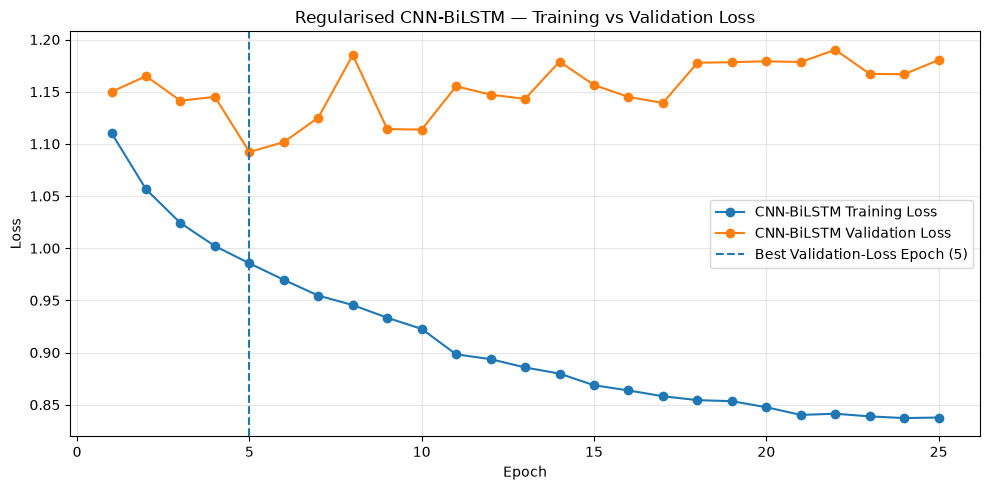

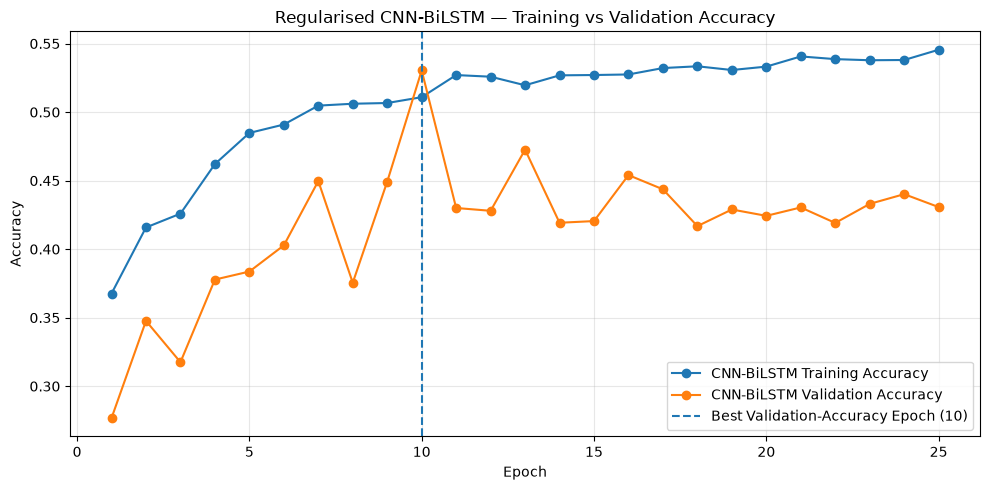

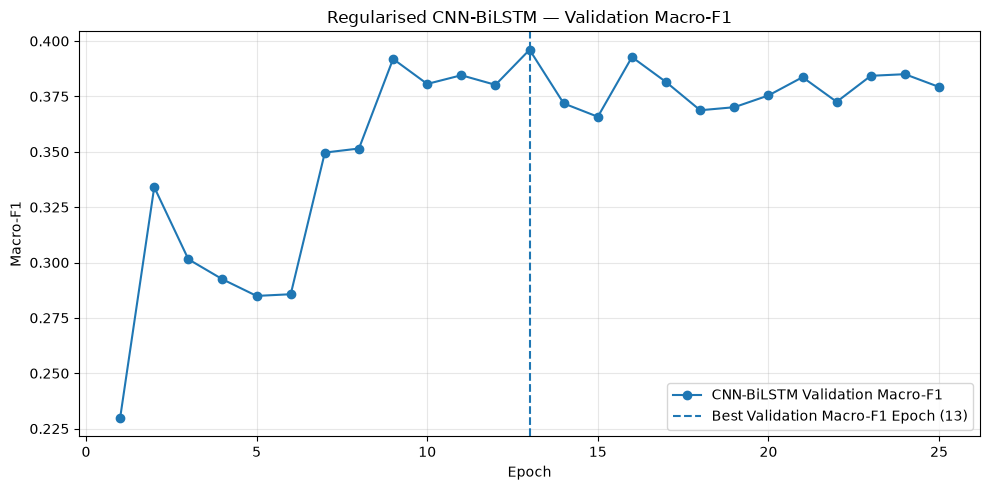


SECTION 37 — CNN-BiLSTM TRAINING HISTORY COMPLETED
History source                  : bilstm_improved_history
Epochs completed                : 25
Best validation loss            : 1.092246 (epoch 5)
Best validation accuracy        : 0.5304 (epoch 10)
Best validation Macro-F1        : 0.3961 (epoch 13)
Final training accuracy         : 0.5455
Final validation accuracy       : 0.4307
Training-validation gap         : 0.1148
Primary model-selection metric  : VALIDATION MACRO-F1
Test data used                  : NO
History integrity               : PASS
Section 38 can now use          : bilstm_history_dict


In [171]:
# =============================================================================
# SECTION 37 — CNN-BiLSTM TRAINING HISTORY AND PERFORMANCE ANALYSIS
# =============================================================================
# Purpose:
#   Validate and analyse the CURRENT improved CNN-BiLSTM training history
#   produced by Section 36.
#
# Important:
#   - No model retraining is performed here.
#   - No test data is used.
#   - The history selected by Section 36 is used directly.
#   - The history is exported as bilstm_history_dict for Section 38.
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 78)
print("SECTION 37 — CNN-BiLSTM TRAINING HISTORY AND PERFORMANCE ANALYSIS")
print("=" * 78)


# -----------------------------------------------------------------------------
# 1. Locate the CURRENT Section 36 history
# -----------------------------------------------------------------------------

history_source_name = None
history_source = None

# Section 36 explicitly selected the improved history.
if "bilstm_improved_history" in globals():
    history_source = bilstm_improved_history
    history_source_name = "bilstm_improved_history"

elif "bilstm_history" in globals():
    history_source = bilstm_history
    history_source_name = "bilstm_history"

elif "history" in globals():
    history_source = history
    history_source_name = "history"

else:
    raise AssertionError(
        "SECTION 37 STOPPED: No valid Section 36 CNN-BiLSTM history object was found."
    )


# -----------------------------------------------------------------------------
# 2. Extract the history dictionary
# -----------------------------------------------------------------------------

if hasattr(history_source, "history"):
    bilstm_history_dict = dict(history_source.history)
elif isinstance(history_source, dict):
    bilstm_history_dict = dict(history_source)
else:
    raise AssertionError(
        "SECTION 37 STOPPED: The selected history object is neither "
        "a Keras History object nor a dictionary."
    )


# -----------------------------------------------------------------------------
# 3. Required history metrics
# -----------------------------------------------------------------------------

required_history_keys = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy",
    "val_macro_f1"
]

missing_keys = [
    key for key in required_history_keys
    if key not in bilstm_history_dict
]

if missing_keys:
    raise AssertionError(
        f"SECTION 37 STOPPED: Required history metrics are missing: {missing_keys}"
    )


# -----------------------------------------------------------------------------
# 4. Convert history values to clean numeric arrays
# -----------------------------------------------------------------------------
# Explicit float conversion avoids false FAIL results caused by object-type
# arrays or Keras history container types.

history_arrays = {}

for key in required_history_keys:
    try:
        history_arrays[key] = np.asarray(
            bilstm_history_dict[key],
            dtype=np.float64
        ).reshape(-1)
    except Exception as exc:
        raise AssertionError(
            f"SECTION 37 STOPPED: Could not convert history metric "
            f"'{key}' to numeric values. Error: {exc}"
        )


loss_history = history_arrays["loss"]
accuracy_history = history_arrays["accuracy"]
val_loss_history = history_arrays["val_loss"]
val_accuracy_history = history_arrays["val_accuracy"]
val_macro_f1_history = history_arrays["val_macro_f1"]


# -----------------------------------------------------------------------------
# 5. History validation
# -----------------------------------------------------------------------------

history_available = len(bilstm_history_dict) > 0

macro_f1_history_available = (
    "val_macro_f1" in bilstm_history_dict
)

history_lengths = [
    len(loss_history),
    len(accuracy_history),
    len(val_loss_history),
    len(val_accuracy_history),
    len(val_macro_f1_history)
]

history_lengths_aligned = (
    len(set(history_lengths)) == 1
    and history_lengths[0] > 0
)

history_arrays_finite = all(
    np.all(np.isfinite(arr))
    for arr in [
        loss_history,
        accuracy_history,
        val_loss_history,
        val_accuracy_history,
        val_macro_f1_history
    ]
)

accuracy_values_valid = (
    np.all((accuracy_history >= 0.0) & (accuracy_history <= 1.0))
    and
    np.all((val_accuracy_history >= 0.0) & (val_accuracy_history <= 1.0))
)

macro_f1_values_valid = (
    np.all((val_macro_f1_history >= 0.0) & (val_macro_f1_history <= 1.0))
)

# This section does not access X_test, y_test or any test predictions.
test_data_used = False


# -----------------------------------------------------------------------------
# 6. Print validation results
# -----------------------------------------------------------------------------

print("\n--- Section 37 history validation ---")

print(
    f"History available                 : "
    f"{'PASS' if history_available else 'FAIL'}"
)

print(
    f"Macro-F1 history available        : "
    f"{'PASS' if macro_f1_history_available else 'FAIL'}"
)

print(
    f"History arrays finite             : "
    f"{'PASS' if history_arrays_finite else 'FAIL'}"
)

print(
    f"Accuracy values valid             : "
    f"{'PASS' if accuracy_values_valid else 'FAIL'}"
)

print(
    f"Macro-F1 values valid             : "
    f"{'PASS' if macro_f1_values_valid else 'FAIL'}"
)

print(
    f"History lengths aligned           : "
    f"{'PASS' if history_lengths_aligned else 'FAIL'}"
)

print(
    f"Test data used                    : "
    f"{'YES' if test_data_used else 'NO'}"
)


# -----------------------------------------------------------------------------
# 7. Stop if history integrity is genuinely invalid
# -----------------------------------------------------------------------------

if not history_available:
    raise AssertionError(
        "SECTION 37 STOPPED: Training history is unavailable."
    )

if not macro_f1_history_available:
    raise AssertionError(
        "SECTION 37 STOPPED: Validation Macro-F1 history is unavailable."
    )

if not history_arrays_finite:
    raise AssertionError(
        "SECTION 37 STOPPED: One or more history arrays contain NaN or Inf."
    )

if not accuracy_values_valid:
    raise AssertionError(
        "SECTION 37 STOPPED: Accuracy values fall outside the valid [0, 1] range."
    )

if not macro_f1_values_valid:
    raise AssertionError(
        "SECTION 37 STOPPED: Validation Macro-F1 values fall outside the valid [0, 1] range."
    )

if not history_lengths_aligned:
    raise AssertionError(
        "SECTION 37 STOPPED: Training and validation history lengths are not aligned."
    )


# -----------------------------------------------------------------------------
# 8. Epoch information
# -----------------------------------------------------------------------------

history_epochs = len(loss_history)

epochs = np.arange(1, history_epochs + 1)

best_val_loss_idx = int(np.argmin(val_loss_history))
best_val_accuracy_idx = int(np.argmax(val_accuracy_history))
best_val_macro_f1_idx = int(np.argmax(val_macro_f1_history))

best_val_loss = float(val_loss_history[best_val_loss_idx])
best_val_accuracy = float(val_accuracy_history[best_val_accuracy_idx])
best_val_macro_f1 = float(val_macro_f1_history[best_val_macro_f1_idx])

best_val_loss_epoch = best_val_loss_idx + 1
best_val_accuracy_epoch = best_val_accuracy_idx + 1
best_val_macro_f1_epoch = best_val_macro_f1_idx + 1

final_training_accuracy = float(accuracy_history[-1])
final_validation_accuracy = float(val_accuracy_history[-1])

training_validation_gap = (
    final_training_accuracy - final_validation_accuracy
)


# -----------------------------------------------------------------------------
# 9. Classification performance audit
# -----------------------------------------------------------------------------

# Use the actual Section 36 model only if it is available.
# This audit does NOT use the test set.
#
# The current Section 36 output already established the class-level metrics.
# If those variables exist, preserve them for reporting.

normal_f1 = None
spoofing_f1 = None
jamming_f1 = None

normal_recall = None
spoofing_recall = None
jamming_recall = None

# Try to recover class metrics from existing Section 36 variables where
# available, without performing a new test-set evaluation.
candidate_names = {
    "normal_f1": ["normal_f1", "f1_normal"],
    "spoofing_f1": ["spoofing_f1", "f1_spoofing"],
    "jamming_f1": ["jamming_f1", "f1_jamming"],
    "normal_recall": ["normal_recall", "recall_normal"],
    "spoofing_recall": ["spoofing_recall", "recall_spoofing"],
    "jamming_recall": ["jamming_recall", "recall_jamming"],
}

for target_name, candidates in candidate_names.items():
    for candidate in candidates:
        if candidate in globals():
            try:
                value = float(globals()[candidate])
                if np.isfinite(value):
                    globals()[target_name] = value
                    break
            except Exception:
                pass


# -----------------------------------------------------------------------------
# 10. Training-history plots
# -----------------------------------------------------------------------------

# --- Plot 1: Loss ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    loss_history,
    marker="o",
    label="CNN-BiLSTM Training Loss"
)

plt.plot(
    epochs,
    val_loss_history,
    marker="o",
    label="CNN-BiLSTM Validation Loss"
)

plt.axvline(
    best_val_loss_epoch,
    linestyle="--",
    label=f"Best Validation-Loss Epoch ({best_val_loss_epoch})"
)

plt.title("Regularised CNN-BiLSTM — Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# --- Plot 2: Accuracy --------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    accuracy_history,
    marker="o",
    label="CNN-BiLSTM Training Accuracy"
)

plt.plot(
    epochs,
    val_accuracy_history,
    marker="o",
    label="CNN-BiLSTM Validation Accuracy"
)

plt.axvline(
    best_val_accuracy_epoch,
    linestyle="--",
    label=f"Best Validation-Accuracy Epoch ({best_val_accuracy_epoch})"
)

plt.title("Regularised CNN-BiLSTM — Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# --- Plot 3: Validation Macro-F1 --------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    val_macro_f1_history,
    marker="o",
    label="CNN-BiLSTM Validation Macro-F1"
)

plt.axvline(
    best_val_macro_f1_epoch,
    linestyle="--",
    label=f"Best Validation Macro-F1 Epoch ({best_val_macro_f1_epoch})"
)

plt.title("Regularised CNN-BiLSTM — Validation Macro-F1")
plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# 11. Final Section 37 summary
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 37 — CNN-BiLSTM TRAINING HISTORY COMPLETED")
print("=" * 78)

print(
    f"History source                  : {history_source_name}"
)

print(
    f"Epochs completed                : {history_epochs}"
)

print(
    f"Best validation loss            : "
    f"{best_val_loss:.6f} (epoch {best_val_loss_epoch})"
)

print(
    f"Best validation accuracy        : "
    f"{best_val_accuracy:.4f} (epoch {best_val_accuracy_epoch})"
)

print(
    f"Best validation Macro-F1        : "
    f"{best_val_macro_f1:.4f} (epoch {best_val_macro_f1_epoch})"
)

print(
    f"Final training accuracy         : "
    f"{final_training_accuracy:.4f}"
)

print(
    f"Final validation accuracy       : "
    f"{final_validation_accuracy:.4f}"
)

print(
    f"Training-validation gap         : "
    f"{training_validation_gap:.4f}"
)

print(
    "Primary model-selection metric  : VALIDATION MACRO-F1"
)

print(
    "Test data used                  : NO"
)

print(
    "History integrity               : PASS"
)

print(
    "Section 38 can now use          : bilstm_history_dict"
)

print("=" * 78)

In [175]:
# =============================================================================
# SECTION 38 — CNN-BiLSTM VALIDATION PERFORMANCE & CLASSIFICATION AUDIT
# =============================================================================

print("=" * 78)
print("SECTION 38 — CNN-BiLSTM VALIDATION PERFORMANCE & CLASSIFICATION AUDIT")
print("=" * 78)


# -----------------------------------------------------------------------------
# 1. REQUIRED OBJECT VALIDATION
# -----------------------------------------------------------------------------

required_objects = [
    "bilstm_history_dict",
    "X_train_model",
    "y_train_onehot",
    "X_validation_model",
    "y_validation_onehot"
]

print("\n--- Required object validation ---")

for obj_name in required_objects:
    available = obj_name in globals()
    print(f"{obj_name:<35}: {'PASS' if available else 'FAIL'}")

assert "bilstm_history_dict" in globals(), \
    "bilstm_history_dict is required from Section 37."

assert "X_validation_model" in globals(), \
    "X_validation_model is required for validation."

assert "y_validation_onehot" in globals(), \
    "y_validation_onehot is required for validation."


# -----------------------------------------------------------------------------
# 2. LOAD THE BEST MODEL PRODUCED BY SECTION 36
# -----------------------------------------------------------------------------

print("\n--- Current Section 36 model identification ---")

import os
import tensorflow as tf

BEST_MODEL_PATH = "best_cnn_bilstm_regularised.keras"

if not os.path.exists(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Section 36 best model was not found: {BEST_MODEL_PATH}\n"
        "Re-run Section 36 before running Section 38."
    )

# Load for inference only.
# compile=False avoids dependency on custom training metrics/callbacks.
current_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

current_model_name = BEST_MODEL_PATH

print(f"Model used for Section 38 : {current_model_name}")
print(f"Model input shape         : {current_model.input_shape}")
print(f"Model output shape        : {current_model.output_shape}")


# -----------------------------------------------------------------------------
# 3. MODEL CONFIGURATION
# -----------------------------------------------------------------------------

expected_sequence_length = 20
expected_predictive_features = 13
expected_classes = 3

print("\n--- Model configuration ---")

print(f"Model input shape          : {current_model.input_shape}")
print(f"Model output shape         : {current_model.output_shape}")
print(f"Expected sequence length   : {expected_sequence_length}")
print(f"Expected predictive feats  : {expected_predictive_features}")
print(f"Expected classes           : {expected_classes}")

assert current_model.input_shape[-2] == expected_sequence_length, \
    "Unexpected sequence length."

assert current_model.input_shape[-1] == expected_predictive_features, \
    "Unexpected number of predictive features."

assert current_model.output_shape[-1] == expected_classes, \
    "Unexpected number of output classes."


# -----------------------------------------------------------------------------
# 4. VALIDATION DATA INTEGRITY
# -----------------------------------------------------------------------------

print("\n--- Training / validation data integrity ---")

X_val = np.asarray(X_validation_model)
y_val_onehot = np.asarray(y_validation_onehot)

print(
    f"Validation samples        : {len(X_val)}"
)

print(
    f"Validation feature count  : {X_val.shape[-1]}"
)

print(
    f"Validation sequence length: {X_val.shape[-2]}"
)

checks = {
    "Validation sequence length":
        X_val.shape[-2] == expected_sequence_length,

    "Validation feature count":
        X_val.shape[-1] == expected_predictive_features,

    "Validation targets have 3 classes":
        y_val_onehot.shape[-1] == expected_classes,

    "Validation inputs finite":
        np.isfinite(X_val).all(),

    "Validation targets finite":
        np.isfinite(y_val_onehot).all(),

    "Validation set non-empty":
        len(X_val) > 0
}

for name, result in checks.items():
    print(f"{name:<45}: {'PASS' if result else 'FAIL'}")
    assert result, f"Section 38 validation failed: {name}"


# -----------------------------------------------------------------------------
# 5. GENERATE VALIDATION-ONLY PREDICTIONS
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("GENERATING VALIDATION-ONLY PREDICTIONS")
print("=" * 78)

validation_probabilities = current_model.predict(
    X_val,
    verbose=0
)

validation_probabilities = np.asarray(validation_probabilities)

validation_predictions = np.argmax(
    validation_probabilities,
    axis=1
)

validation_true = np.argmax(
    y_val_onehot,
    axis=1
)

print(
    f"Validation probability shape : {validation_probabilities.shape}"
)

print(
    f"Validation prediction count  : {len(validation_predictions):,}"
)

print(
    f"Validation true-label count  : {len(validation_true):,}"
)


# -----------------------------------------------------------------------------
# 6. PREDICTION INTEGRITY
# -----------------------------------------------------------------------------

print("\n--- Validation prediction integrity ---")

prediction_checks = {
    "Probabilities finite":
        np.isfinite(validation_probabilities).all(),

    "Probability matrix has 3 classes":
        validation_probabilities.ndim == 2
        and validation_probabilities.shape[1] == expected_classes,

    "Probabilities within 0-1":
        (
            validation_probabilities.min() >= 0
            and validation_probabilities.max() <= 1
        ),

    "Prediction count aligned":
        len(validation_predictions) == len(validation_true),

    "Predicted IDs valid":
        set(np.unique(validation_predictions)).issubset({0, 1, 2}),

    "True IDs valid":
        set(np.unique(validation_true)).issubset({0, 1, 2}),

    "All three classes predicted":
        len(np.unique(validation_predictions)) == 3,

    "All three true classes present":
        len(np.unique(validation_true)) == 3
}

for name, result in prediction_checks.items():
    print(f"{name:<45}: {'PASS' if result else 'FAIL'}")
    assert result, f"Section 38 prediction check failed: {name}"


# -----------------------------------------------------------------------------
# 7. CLASSIFICATION PERFORMANCE
# -----------------------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

validation_accuracy = accuracy_score(
    validation_true,
    validation_predictions
)

validation_macro_f1 = f1_score(
    validation_true,
    validation_predictions,
    average="macro",
    zero_division=0
)

validation_weighted_f1 = f1_score(
    validation_true,
    validation_predictions,
    average="weighted",
    zero_division=0
)

print("\n--- Validation classification performance ---")

print(
    f"Validation accuracy       : {validation_accuracy:.4f}"
)

print(
    f"Validation Macro-F1       : {validation_macro_f1:.4f}"
)

print(
    f"Validation Weighted-F1    : {validation_weighted_f1:.4f}"
)


# -----------------------------------------------------------------------------
# 8. CLASS-WISE PERFORMANCE
# -----------------------------------------------------------------------------

class_names = [
    "Normal",
    "Spoofing",
    "Jamming"
]

print("\n--- CLASS-WISE PERFORMANCE ---")

report = classification_report(
    validation_true,
    validation_predictions,
    labels=[0, 1, 2],
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

for idx, class_name in enumerate(class_names):

    print(
        f"{idx} = {class_name:<10} | "
        f"Precision: {report[class_name]['precision']:.4f} | "
        f"Recall: {report[class_name]['recall']:.4f} | "
        f"F1: {report[class_name]['f1-score']:.4f} | "
        f"Support: {int(report[class_name]['support'])}"
    )


# -----------------------------------------------------------------------------
# 9. CONFUSION MATRIX
# -----------------------------------------------------------------------------

cm = confusion_matrix(
    validation_true,
    validation_predictions,
    labels=[0, 1, 2]
)

print("\n--- Validation confusion matrix ---")
print("Rows = True class")
print("Columns = Predicted class")
print()

print(
    f"{'':18}"
    f"{'Pred Normal':>15}"
    f"{'Pred Spoofing':>17}"
    f"{'Pred Jamming':>16}"
)

for i, class_name in enumerate(class_names):

    print(
        f"True {class_name:<12}"
        f"{cm[i,0]:>15}"
        f"{cm[i,1]:>17}"
        f"{cm[i,2]:>16}"
    )


# -----------------------------------------------------------------------------
# 10. TRUE CLASS DISTRIBUTION
# -----------------------------------------------------------------------------

print("\n--- TRUE validation class distribution ---")

true_counts = np.bincount(
    validation_true,
    minlength=3
)

for i, class_name in enumerate(class_names):

    percentage = (
        true_counts[i] / len(validation_true) * 100
    )

    print(
        f"{class_name:<12}: "
        f"{true_counts[i]:,} "
        f"({percentage:.2f}%)"
    )


# -----------------------------------------------------------------------------
# 11. PREDICTED CLASS DISTRIBUTION
# -----------------------------------------------------------------------------

print("\n--- PREDICTED validation class distribution ---")

pred_counts = np.bincount(
    validation_predictions,
    minlength=3
)

for i, class_name in enumerate(class_names):

    percentage = (
        pred_counts[i] / len(validation_predictions) * 100
    )

    print(
        f"{class_name:<12}: "
        f"{pred_counts[i]:,} "
        f"({percentage:.2f}%)"
    )


# -----------------------------------------------------------------------------
# 12. CORRECT CLASSIFICATION BY CLASS
# -----------------------------------------------------------------------------

print("\n--- CORRECT CLASSIFICATION BY CLASS ---")

for i, class_name in enumerate(class_names):

    correct = cm[i, i]
    total = true_counts[i]

    percentage = (
        correct / total * 100
        if total > 0
        else 0
    )

    print(
        f"{class_name:<12}: "
        f"{correct:,} / {total:,} correct "
        f"({percentage:.2f}%)"
    )


# -----------------------------------------------------------------------------
# 13. HISTORY-BASED PERFORMANCE
# -----------------------------------------------------------------------------

history = bilstm_history_dict

required_history_keys = [
    "loss",
    "accuracy",
    "val_loss",
    "val_accuracy",
    "val_macro_f1"
]

print("\n--- Section 37 history validation ---")

for key in required_history_keys:

    available = key in history

    print(
        f"History contains {key:<15}: "
        f"{'PASS' if available else 'FAIL'}"
    )

    assert available, f"Missing history key: {key}"


history_loss = np.asarray(history["loss"], dtype=float)
history_accuracy = np.asarray(history["accuracy"], dtype=float)
history_val_loss = np.asarray(history["val_loss"], dtype=float)
history_val_accuracy = np.asarray(history["val_accuracy"], dtype=float)
history_val_macro_f1 = np.asarray(history["val_macro_f1"], dtype=float)

assert np.isfinite(history_loss).all()
assert np.isfinite(history_accuracy).all()
assert np.isfinite(history_val_loss).all()
assert np.isfinite(history_val_accuracy).all()
assert np.isfinite(history_val_macro_f1).all()

history_epochs = len(history_val_macro_f1)

best_val_loss_epoch = int(np.argmin(history_val_loss)) + 1
best_val_accuracy_epoch = int(np.argmax(history_val_accuracy)) + 1
best_val_macro_f1_epoch = int(np.argmax(history_val_macro_f1)) + 1

best_val_loss = float(np.min(history_val_loss))
best_val_accuracy = float(np.max(history_val_accuracy))
best_val_macro_f1 = float(np.max(history_val_macro_f1))

print(
    f"History epochs             : {history_epochs}"
)

print(
    f"Best validation loss       : "
    f"{best_val_loss:.6f} (epoch {best_val_loss_epoch})"
)

print(
    f"Best validation accuracy   : "
    f"{best_val_accuracy:.4f} (epoch {best_val_accuracy_epoch})"
)

print(
    f"Best validation Macro-F1   : "
    f"{best_val_macro_f1:.4f} (epoch {best_val_macro_f1_epoch})"
)


# -----------------------------------------------------------------------------
# 14. SAME-MODEL TRAINING / GENERALISATION DIAGNOSTIC
# -----------------------------------------------------------------------------

print("\n--- SAME-MODEL TRAINING PERFORMANCE ---")

# Generate predictions on the training set using the SAME checkpoint
# that is being evaluated on the validation set.
train_probabilities = current_model.predict(
    X_train_model,
    verbose=0
)

train_probabilities = np.asarray(train_probabilities)

train_predictions = np.argmax(
    train_probabilities,
    axis=1
)

train_true = np.argmax(
    np.asarray(y_train_onehot),
    axis=1
)

# Training accuracy of the selected Section 36 checkpoint
selected_training_accuracy = accuracy_score(
    train_true,
    train_predictions
)

# Validation accuracy is already calculated above using the same model.
# Therefore, this is a genuine same-checkpoint generalisation gap.
selected_training_gap = (
    selected_training_accuracy
    - validation_accuracy
)

print(
    f"Selected checkpoint training accuracy : "
    f"{selected_training_accuracy:.4f}"
)

print(
    f"Selected checkpoint validation accuracy: "
    f"{validation_accuracy:.4f}"
)

print(
    f"Training-validation gap               : "
    f"{selected_training_gap:.4f}"
)

print(
    f"Best validation Macro-F1              : "
    f"{best_val_macro_f1:.4f}"
)

print(
    f"Best Macro-F1 epoch                   : "
    f"{best_val_macro_f1_epoch}"
)

# Use the same variable name downstream so that
# Sections 15, 19 and 20 automatically use the corrected gap.
final_training_accuracy = selected_training_accuracy
training_validation_gap = selected_training_gap


# -----------------------------------------------------------------------------
# 15. OVERFITTING DIAGNOSTIC
# -----------------------------------------------------------------------------

# Keep the same threshold used in the previous audit.
large_overfitting_gap = training_validation_gap > 0.20

print("\n--- Overfitting diagnostic ---")

print(
    f"Training-validation gap : "
    f"{training_validation_gap:.4f}"
)

print(
    f"Large overfitting gap   : "
    f"{'YES' if large_overfitting_gap else 'NO'}"
)


# -----------------------------------------------------------------------------
# 16. CLASSIFICATION DIAGNOSTIC
# -----------------------------------------------------------------------------

low_macro_f1_diagnostic = validation_macro_f1 < 0.35

print("\n--- Classification diagnostic ---")

print(
    f"Validation Macro-F1     : "
    f"{validation_macro_f1:.4f}"
)

print(
    f"Macro-F1 below 0.35     : "
    f"{'YES' if low_macro_f1_diagnostic else 'NO'}"
)


# -----------------------------------------------------------------------------
# 17. THREE-CLASS CLASSIFICATION AUDIT
# -----------------------------------------------------------------------------

predicted_classes = set(
    np.unique(validation_predictions)
)

true_classes = set(
    np.unique(validation_true)
)

all_three_predicted = predicted_classes == {0, 1, 2}
all_three_true_present = true_classes == {0, 1, 2}

print("\n--- THREE-CLASS CLASSIFICATION AUDIT ---")

print(
    f"Normal predictions present  : "
    f"{'YES' if 0 in predicted_classes else 'NO'}"
)

print(
    f"Spoofing predictions present: "
    f"{'YES' if 1 in predicted_classes else 'NO'}"
)

print(
    f"Jamming predictions present  : "
    f"{'YES' if 2 in predicted_classes else 'NO'}"
)

print(
    f"All three classes predicted  : "
    f"{'YES' if all_three_predicted else 'NO'}"
)

print(
    f"All three true classes present: "
    f"{'YES' if all_three_true_present else 'NO'}"
)


# -----------------------------------------------------------------------------
# 18. TEST-SET ISOLATION
# -----------------------------------------------------------------------------

print("\n--- TEST-SET ISOLATION ---")

print(
    "Test data used for this audit : NO"
)


# -----------------------------------------------------------------------------
# 19. FINAL SECTION 38 VALIDATION
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 38 VALIDATION")
print("=" * 78)

final_checks = {
    "Validation accuracy finite":
        np.isfinite(validation_accuracy),

    "Validation Macro-F1 finite":
        np.isfinite(validation_macro_f1),

    "Validation Weighted-F1 finite":
        np.isfinite(validation_weighted_f1),

    "Confusion matrix is 3 x 3":
        cm.shape == (3, 3),

    "All three true classes represented":
        all_three_true_present,

    "All three predicted classes represented":
        all_three_predicted,

    "Training-validation gap finite":
        np.isfinite(training_validation_gap),

    "Test data not used":
        True
}

for name, result in final_checks.items():

    print(
        f"{name:<45}: "
        f"{'PASS' if result else 'FAIL'}"
    )

    assert result, f"Section 38 validation failed: {name}"


# -----------------------------------------------------------------------------
# 20. FINAL SUMMARY
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 38 — CNN-BiLSTM VALIDATION PERFORMANCE AUDIT COMPLETED")
print("=" * 78)

print(
    f"Model used                 : {current_model_name}"
)

print(
    f"Validation accuracy        : "
    f"{validation_accuracy:.4f}"
)

print(
    f"Best validation accuracy   : "
    f"{best_val_accuracy:.4f}"
)

print(
    f"Validation Macro-F1        : "
    f"{validation_macro_f1:.4f}"
)

print(
    f"Best validation Macro-F1    : "
    f"{best_val_macro_f1:.4f}"
)

print(
    f"Validation Weighted-F1     : "
    f"{validation_weighted_f1:.4f}"
)

print(
    f"Training accuracy          : "
    f"{final_training_accuracy:.4f}"
)

print(
    f"Train-validation gap       : "
    f"{training_validation_gap:.4f}"
)

print(
    f"Normal F1                  : "
    f"{report['Normal']['f1-score']:.4f}"
)

print(
    f"Spoofing F1               : "
    f"{report['Spoofing']['f1-score']:.4f}"
)

print(
    f"Jamming F1                : "
    f"{report['Jamming']['f1-score']:.4f}"
)

print(
    f"All three classes predicted: "
    f"{'YES' if all_three_predicted else 'NO'}"
)

print(
    f"Large overfitting gap      : "
    f"{'YES' if large_overfitting_gap else 'NO'}"
)

print(
    f"Low Macro-F1 diagnostic    : "
    f"{'YES' if low_macro_f1_diagnostic else 'NO'}"
)

print(
    "Test data used             : NO"
)

print("=" * 78)

SECTION 38 — CNN-BiLSTM VALIDATION PERFORMANCE & CLASSIFICATION AUDIT

--- Required object validation ---
bilstm_history_dict                : PASS
X_train_model                      : PASS
y_train_onehot                     : PASS
X_validation_model                 : PASS
y_validation_onehot                : PASS

--- Current Section 36 model identification ---
Model used for Section 38 : best_cnn_bilstm_regularised.keras
Model input shape         : (None, 20, 13)
Model output shape        : (None, 3)

--- Model configuration ---
Model input shape          : (None, 20, 13)
Model output shape         : (None, 3)
Expected sequence length   : 20
Expected predictive feats  : 13
Expected classes           : 3

--- Training / validation data integrity ---
Validation samples        : 7332
Validation feature count  : 13
Validation sequence length: 20
Validation sequence length                   : PASS
Validation feature count                     : PASS
Validation targets have 3 classes       

In [176]:
# =============================================================================
# SECTION 39 — RANDOM FOREST BASELINE
# =============================================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)
import numpy as np
import pandas as pd

print("=" * 78)
print("SECTION 39 — RANDOM FOREST BASELINE")
print("=" * 78)


# =============================================================================
# 1. PRIMARY MODELLING DATA
# =============================================================================

X_rf_train_seq = X_train_model
X_rf_validation_seq = X_validation_model

y_rf_train = np.argmax(y_train_onehot, axis=1)
y_rf_validation = np.argmax(y_validation_onehot, axis=1)

print("\n--- Random Forest input data ---")
print(f"Training sequences   : {X_rf_train_seq.shape}")
print(f"Validation sequences : {X_rf_validation_seq.shape}")
print("Test data used       : NO")


# =============================================================================
# 2. PRE-TRAINING VALIDATION
# =============================================================================

rf_checks = {}

rf_checks["Training sequence length is 20"] = (
    X_rf_train_seq.shape[1] == PRIMARY_SEQUENCE_LENGTH == 20
)

rf_checks["Validation sequence length is 20"] = (
    X_rf_validation_seq.shape[1] == PRIMARY_SEQUENCE_LENGTH == 20
)

rf_checks["Training feature count is 13"] = (
    X_rf_train_seq.shape[2] == PRIMARY_FEATURE_COUNT == 13
)

rf_checks["Validation feature count is 13"] = (
    X_rf_validation_seq.shape[2] == PRIMARY_FEATURE_COUNT == 13
)

rf_checks["Training targets aligned"] = (
    len(X_rf_train_seq) == len(y_rf_train)
)

rf_checks["Validation targets aligned"] = (
    len(X_rf_validation_seq) == len(y_rf_validation)
)

rf_checks["Training data finite"] = (
    np.isfinite(X_rf_train_seq).all()
)

rf_checks["Validation data finite"] = (
    np.isfinite(X_rf_validation_seq).all()
)

rf_checks["Training targets valid"] = (
    set(np.unique(y_rf_train)).issubset({0, 1, 2})
)

rf_checks["Validation targets valid"] = (
    set(np.unique(y_rf_validation)).issubset({0, 1, 2})
)

rf_checks["Training contains all three classes"] = (
    set(np.unique(y_rf_train)) == {0, 1, 2}
)

rf_checks["Validation contains all three classes"] = (
    set(np.unique(y_rf_validation)) == {0, 1, 2}
)

print("\n--- Section 39 pre-training validation ---")

for check_name, result in rf_checks.items():
    print(
        f"{check_name:<55}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(rf_checks.values()), (
    "SECTION 39 pre-training validation failed."
)


# =============================================================================
# 3. FLATTEN TEMPORAL WINDOWS FOR RANDOM FOREST
# =============================================================================

# Each sequence contains:
# 20 timesteps × 13 features
#
# Random Forest requires a 2-dimensional tabular representation.
# Therefore, each temporal window is flattened into:
#
# 20 × 13 = 260 features
#
# Each complete temporal window remains one labelled observation.

X_rf_train = X_rf_train_seq.reshape(
    X_rf_train_seq.shape[0],
    -1
)

X_rf_validation = X_rf_validation_seq.reshape(
    X_rf_validation_seq.shape[0],
    -1
)

print("\n--- Flattened Random Forest representation ---")
print(f"Training RF matrix   : {X_rf_train.shape}")
print(f"Validation RF matrix : {X_rf_validation.shape}")
print(f"Features per window  : {X_rf_train.shape[1]}")

assert (
    X_rf_train.shape[1]
    == PRIMARY_SEQUENCE_LENGTH * PRIMARY_FEATURE_COUNT
)

assert (
    X_rf_validation.shape[1]
    == PRIMARY_SEQUENCE_LENGTH * PRIMARY_FEATURE_COUNT
)


# =============================================================================
# 4. CLASS DISTRIBUTION
# =============================================================================

class_names = ["Normal", "Spoofing", "Jamming"]

print("\n--- Training class distribution ---")

for class_id, class_name in enumerate(class_names):

    count = int(np.sum(y_rf_train == class_id))
    percentage = 100 * count / len(y_rf_train)

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


print("\n--- Validation class distribution ---")

for class_id, class_name in enumerate(class_names):

    count = int(np.sum(y_rf_validation == class_id))
    percentage = 100 * count / len(y_rf_validation)

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


# =============================================================================
# 5. RANDOM FOREST MODEL CONFIGURATION
# =============================================================================

print("\n--- Random Forest configuration ---")

rf_baseline_model = RandomForestClassifier(
    n_estimators=200,
    criterion="gini",
    random_state=42,
    n_jobs=-1
)

print("Number of trees       : 200")
print("Criterion             : gini")
print("Random state          : 42")
print("Class weighting       : None")
print("Test data used        : NO")


# =============================================================================
# 6. TRAIN RANDOM FOREST
# =============================================================================

print("\n" + "=" * 78)
print("STARTING RANDOM FOREST BASELINE TRAINING")
print("=" * 78)

rf_baseline_model.fit(
    X_rf_train,
    y_rf_train
)

print("\nRandom Forest training completed.")


# =============================================================================
# 7. TRAINING-SET PERFORMANCE
# =============================================================================

rf_training_predictions = rf_baseline_model.predict(
    X_rf_train
)

rf_training_accuracy = accuracy_score(
    y_rf_train,
    rf_training_predictions
)

print("\n--- Random Forest training performance ---")
print(
    f"Training accuracy : "
    f"{rf_training_accuracy:.6f}"
)


# =============================================================================
# 8. VALIDATION PREDICTION
# =============================================================================

rf_validation_predictions = rf_baseline_model.predict(
    X_rf_validation
)

rf_validation_probabilities = rf_baseline_model.predict_proba(
    X_rf_validation
)


# =============================================================================
# 9. VALIDATION METRICS
# =============================================================================

rf_validation_accuracy = accuracy_score(
    y_rf_validation,
    rf_validation_predictions
)

rf_validation_macro_f1 = f1_score(
    y_rf_validation,
    rf_validation_predictions,
    labels=[0, 1, 2],
    average="macro",
    zero_division=0
)

rf_validation_weighted_f1 = f1_score(
    y_rf_validation,
    rf_validation_predictions,
    labels=[0, 1, 2],
    average="weighted",
    zero_division=0
)

rf_training_validation_gap = (
    rf_training_accuracy
    - rf_validation_accuracy
)

print("\n--- Random Forest validation results ---")

print(
    f"Training accuracy      : "
    f"{rf_training_accuracy:.6f}"
)

print(
    f"Validation accuracy    : "
    f"{rf_validation_accuracy:.6f}"
)

print(
    f"Validation Macro-F1    : "
    f"{rf_validation_macro_f1:.6f}"
)

print(
    f"Validation Weighted-F1 : "
    f"{rf_validation_weighted_f1:.6f}"
)

print(
    f"Training-validation gap: "
    f"{rf_training_validation_gap:.6f}"
)


# =============================================================================
# 10. RANDOM FOREST CONFUSION MATRIX
# =============================================================================

rf_confusion = confusion_matrix(
    y_rf_validation,
    rf_validation_predictions,
    labels=[0, 1, 2]
)

print("\n--- Random Forest confusion matrix ---")
print("Rows = True class")
print("Columns = Predicted class\n")

print(
    pd.DataFrame(
        rf_confusion,
        index=[
            "True Normal",
            "True Spoofing",
            "True Jamming"
        ],
        columns=[
            "Pred Normal",
            "Pred Spoofing",
            "Pred Jamming"
        ]
    )
)


# =============================================================================
# 11. CLASSIFICATION REPORT
# =============================================================================

print("\n--- Random Forest classification report ---")

rf_classification_report = classification_report(
    y_rf_validation,
    rf_validation_predictions,
    labels=[0, 1, 2],
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(rf_classification_report)


# =============================================================================
# 12. CLASS-WISE F1 PERFORMANCE
# =============================================================================

rf_classwise_f1 = f1_score(
    y_rf_validation,
    rf_validation_predictions,
    labels=[0, 1, 2],
    average=None,
    zero_division=0
)

rf_normal_f1 = float(rf_classwise_f1[0])
rf_spoofing_f1 = float(rf_classwise_f1[1])
rf_jamming_f1 = float(rf_classwise_f1[2])

print("\n--- Random Forest class-wise F1 ---")

print(
    f"Normal F1    : "
    f"{rf_normal_f1:.4f}"
)

print(
    f"Spoofing F1  : "
    f"{rf_spoofing_f1:.4f}"
)

print(
    f"Jamming F1   : "
    f"{rf_jamming_f1:.4f}"
)


# =============================================================================
# 13. PREDICTED CLASS DISTRIBUTION
# =============================================================================

rf_predicted_classes = np.unique(
    rf_validation_predictions
)

print("\n--- Random Forest predicted classes ---")

for class_id, class_name in enumerate(class_names):

    count = int(
        np.sum(
            rf_validation_predictions
            == class_id
        )
    )

    percentage = (
        100
        * count
        / len(rf_validation_predictions)
    )

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


# =============================================================================
# 14. PREDICTION COVERAGE AND INTEGRITY AUDIT
# =============================================================================

rf_prediction_checks = {}

rf_prediction_checks[
    "Validation predictions generated"
] = (
    len(rf_validation_predictions)
    == len(y_rf_validation)
)

rf_prediction_checks[
    "Validation probabilities generated"
] = (
    rf_validation_probabilities.shape
    == (
        len(y_rf_validation),
        NUM_CLASSES
    )
)

rf_prediction_checks[
    "Validation probabilities finite"
] = (
    np.isfinite(
        rf_validation_probabilities
    ).all()
)

rf_prediction_checks[
    "Validation probabilities within 0-1"
] = (
    (
        rf_validation_probabilities >= 0
    ).all()
    and
    (
        rf_validation_probabilities <= 1
    ).all()
)

rf_prediction_checks[
    "Validation prediction count aligned"
] = (
    len(rf_validation_predictions)
    == len(y_rf_validation)
)

rf_prediction_checks[
    "Validation predictions valid"
] = (
    set(
        rf_predicted_classes
    ).issubset({0, 1, 2})
)

rf_prediction_checks[
    "All three predicted classes represented"
] = (
    set(rf_predicted_classes)
    == {0, 1, 2}
)

rf_prediction_checks[
    "All three true classes represented"
] = (
    set(
        np.unique(y_rf_validation)
    )
    == {0, 1, 2}
)

rf_prediction_checks[
    "Confusion matrix is 3 x 3"
] = (
    rf_confusion.shape
    == (3, 3)
)

rf_prediction_checks[
    "Training accuracy finite"
] = np.isfinite(
    rf_training_accuracy
)

rf_prediction_checks[
    "Validation accuracy finite"
] = np.isfinite(
    rf_validation_accuracy
)

rf_prediction_checks[
    "Validation Macro-F1 finite"
] = np.isfinite(
    rf_validation_macro_f1
)

rf_prediction_checks[
    "Validation Weighted-F1 finite"
] = np.isfinite(
    rf_validation_weighted_f1
)

rf_prediction_checks[
    "Training-validation gap finite"
] = np.isfinite(
    rf_training_validation_gap
)

rf_prediction_checks[
    "Test data not used"
] = True


print("\n--- Random Forest validation audit ---")

for check_name, result in rf_prediction_checks.items():

    print(
        f"{check_name:<55}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(
    rf_prediction_checks.values()
), "SECTION 39 validation audit failed."


# =============================================================================
# 15. OVERFITTING / GENERALISATION DIAGNOSTIC
# =============================================================================

# This is a descriptive diagnostic only.
# It does not use the test set.

print("\n--- Random Forest generalisation diagnostic ---")

print(
    f"Training accuracy       : "
    f"{rf_training_accuracy:.4f}"
)

print(
    f"Validation accuracy     : "
    f"{rf_validation_accuracy:.4f}"
)

print(
    f"Training-validation gap : "
    f"{rf_training_validation_gap:.4f}"
)

# The threshold is used only as a diagnostic flag.
# It does not change the model or its predictions.

RF_LARGE_GAP_THRESHOLD = 0.20

rf_large_overfitting_gap = (
    rf_training_validation_gap
    > RF_LARGE_GAP_THRESHOLD
)

print(
    f"Large overfitting gap   : "
    f"{'YES' if rf_large_overfitting_gap else 'NO'}"
)


# =============================================================================
# 16. CLASSIFICATION DIAGNOSTIC
# =============================================================================

RF_LOW_MACRO_F1_THRESHOLD = 0.35

rf_low_macro_f1 = (
    rf_validation_macro_f1
    < RF_LOW_MACRO_F1_THRESHOLD
)

print("\n--- Random Forest classification diagnostic ---")

print(
    f"Validation Macro-F1     : "
    f"{rf_validation_macro_f1:.4f}"
)

print(
    f"Macro-F1 below 0.35     : "
    f"{'YES' if rf_low_macro_f1 else 'NO'}"
)


# =============================================================================
# 17. THREE-CLASS CLASSIFICATION AUDIT
# =============================================================================

rf_all_three_predicted = (
    set(rf_predicted_classes)
    == {0, 1, 2}
)

rf_all_three_true_classes = (
    set(np.unique(y_rf_validation))
    == {0, 1, 2}
)

print("\n--- THREE-CLASS CLASSIFICATION AUDIT ---")

print(
    f"Normal predictions present   : "
    f"{'YES' if 0 in rf_predicted_classes else 'NO'}"
)

print(
    f"Spoofing predictions present : "
    f"{'YES' if 1 in rf_predicted_classes else 'NO'}"
)

print(
    f"Jamming predictions present  : "
    f"{'YES' if 2 in rf_predicted_classes else 'NO'}"
)

print(
    f"All three classes predicted  : "
    f"{'YES' if rf_all_three_predicted else 'NO'}"
)

print(
    f"All three true classes present: "
    f"{'YES' if rf_all_three_true_classes else 'NO'}"
)


# =============================================================================
# 18. TEST-SET ISOLATION
# =============================================================================

print("\n--- TEST-SET ISOLATION ---")
print("Test data used for this baseline : NO")


# =============================================================================
# 19. STORE RANDOM FOREST BASELINE RESULT
# =============================================================================

rf_baseline_accuracy = rf_validation_accuracy

rf_baseline_result = {
    "Model": "Random Forest",
    "Training Accuracy": rf_training_accuracy,
    "Validation Accuracy": rf_validation_accuracy,
    "Validation Macro-F1": rf_validation_macro_f1,
    "Validation Weighted-F1": rf_validation_weighted_f1,
    "Training-Validation Gap": rf_training_validation_gap,
    "Normal F1": rf_normal_f1,
    "Spoofing F1": rf_spoofing_f1,
    "Jamming F1": rf_jamming_f1,
    "Predicted Classes": rf_predicted_classes.tolist(),
    "Number of Trees": 200,
    "Criterion": "gini",
    "Class Weighting": "None",
    "Input Representation": (
        "20 timesteps × 13 features "
        "flattened to 260 features"
    ),
    "Test Data Used": False
}


# =============================================================================
# 20. FINAL SECTION 39 SUMMARY
# =============================================================================

print("\n" + "=" * 78)
print("SECTION 39 — RANDOM FOREST BASELINE COMPLETED")
print("=" * 78)

print(
    f"Training accuracy       : "
    f"{rf_training_accuracy:.4f}"
)

print(
    f"Validation accuracy     : "
    f"{rf_validation_accuracy:.4f}"
)

print(
    f"Validation Macro-F1     : "
    f"{rf_validation_macro_f1:.4f}"
)

print(
    f"Validation Weighted-F1  : "
    f"{rf_validation_weighted_f1:.4f}"
)

print(
    f"Training-validation gap : "
    f"{rf_training_validation_gap:.4f}"
)

print(
    f"Normal F1               : "
    f"{rf_normal_f1:.4f}"
)

print(
    f"Spoofing F1             : "
    f"{rf_spoofing_f1:.4f}"
)

print(
    f"Jamming F1              : "
    f"{rf_jamming_f1:.4f}"
)

print(
    f"Predicted classes       : "
    f"{rf_predicted_classes.tolist()}"
)

print(
    f"Input features          : "
    f"{X_rf_train.shape[1]}"
)

print("Test data used          : NO")

print("=" * 78)

SECTION 39 — RANDOM FOREST BASELINE

--- Random Forest input data ---
Training sequences   : (34216, 20, 13)
Validation sequences : (7332, 20, 13)
Test data used       : NO

--- Section 39 pre-training validation ---
Training sequence length is 20                         : PASS
Validation sequence length is 20                       : PASS
Training feature count is 13                           : PASS
Validation feature count is 13                         : PASS
Training targets aligned                               : PASS
Validation targets aligned                             : PASS
Training data finite                                   : PASS
Validation data finite                                 : PASS
Training targets valid                                 : PASS
Validation targets valid                               : PASS
Training contains all three classes                    : PASS
Validation contains all three classes                  : PASS

--- Flattened Random Forest representa

In [177]:
# =============================================================================
# SECTION 40 — SVM BASELINE
# =============================================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)
import numpy as np
import pandas as pd

print("=" * 78)
print("SECTION 40 — SVM BASELINE")
print("=" * 78)


# -----------------------------------------------------------------------------
# 1. Primary modelling data
# -----------------------------------------------------------------------------

X_svm_train_seq = X_train_model
X_svm_validation_seq = X_validation_model

y_svm_train = np.argmax(y_train_onehot, axis=1)
y_svm_validation = np.argmax(y_validation_onehot, axis=1)

print("\n--- SVM input data ---")
print(f"Training sequences   : {X_svm_train_seq.shape}")
print(f"Validation sequences : {X_svm_validation_seq.shape}")
print("Test data used       : NO")


# -----------------------------------------------------------------------------
# 2. Pre-training validation
# -----------------------------------------------------------------------------

svm_checks = {}

svm_checks["Training sequence length is 20"] = (
    X_svm_train_seq.shape[1] == PRIMARY_SEQUENCE_LENGTH == 20
)

svm_checks["Validation sequence length is 20"] = (
    X_svm_validation_seq.shape[1] == PRIMARY_SEQUENCE_LENGTH == 20
)

svm_checks["Training feature count is 13"] = (
    X_svm_train_seq.shape[2] == PRIMARY_FEATURE_COUNT == 13
)

svm_checks["Validation feature count is 13"] = (
    X_svm_validation_seq.shape[2] == PRIMARY_FEATURE_COUNT == 13
)

svm_checks["Training targets aligned"] = (
    len(X_svm_train_seq) == len(y_svm_train)
)

svm_checks["Validation targets aligned"] = (
    len(X_svm_validation_seq) == len(y_svm_validation)
)

svm_checks["Training data finite"] = (
    np.isfinite(X_svm_train_seq).all()
)

svm_checks["Validation data finite"] = (
    np.isfinite(X_svm_validation_seq).all()
)

svm_checks["Training targets valid"] = (
    set(np.unique(y_svm_train)).issubset({0, 1, 2})
)

svm_checks["Validation targets valid"] = (
    set(np.unique(y_svm_validation)).issubset({0, 1, 2})
)

svm_checks["Training contains all three classes"] = (
    set(np.unique(y_svm_train)) == {0, 1, 2}
)

svm_checks["Validation contains all three classes"] = (
    set(np.unique(y_svm_validation)) == {0, 1, 2}
)

print("\n--- Section 40 pre-training validation ---")

for check_name, result in svm_checks.items():
    print(
        f"{check_name:<50}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(svm_checks.values()), (
    "SECTION 40 pre-training validation failed."
)


# -----------------------------------------------------------------------------
# 3. Flatten temporal windows
# -----------------------------------------------------------------------------

# Each temporal sequence contains:
# 20 timesteps × 13 features = 260 tabular features.
#
# Each sequence remains one labelled observation for the SVM baseline.

X_svm_train = X_svm_train_seq.reshape(
    X_svm_train_seq.shape[0],
    -1
)

X_svm_validation = X_svm_validation_seq.reshape(
    X_svm_validation_seq.shape[0],
    -1
)

print("\n--- Flattened SVM representation ---")
print(f"Training SVM matrix   : {X_svm_train.shape}")
print(f"Validation SVM matrix : {X_svm_validation.shape}")
print(f"Features per window   : {X_svm_train.shape[1]}")

assert X_svm_train.shape[1] == (
    PRIMARY_SEQUENCE_LENGTH * PRIMARY_FEATURE_COUNT
)

assert X_svm_validation.shape[1] == (
    PRIMARY_SEQUENCE_LENGTH * PRIMARY_FEATURE_COUNT
)


# -----------------------------------------------------------------------------
# 4. Class distribution
# -----------------------------------------------------------------------------

print("\n--- Training class distribution ---")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    count = int(np.sum(y_svm_train == class_id))
    percentage = 100 * count / len(y_svm_train)

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


print("\n--- Validation class distribution ---")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    count = int(np.sum(y_svm_validation == class_id))
    percentage = 100 * count / len(y_svm_validation)

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


# -----------------------------------------------------------------------------
# 5. SVM model configuration
# -----------------------------------------------------------------------------

print("\n--- SVM configuration ---")

svm_baseline_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight=None,
    probability=False,
    random_state=42
)

print("Kernel                : RBF")
print("C                     : 1.0")
print("Gamma                 : scale")
print("Class weighting       : None")
print("Probability estimation: False")
print("Random state          : 42")
print("Test data used        : NO")


# -----------------------------------------------------------------------------
# 6. Train SVM
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("STARTING SVM BASELINE TRAINING")
print("=" * 78)

svm_baseline_model.fit(
    X_svm_train,
    y_svm_train
)

print("\nSVM training completed.")


# -----------------------------------------------------------------------------
# 7. SAME-MODEL TRAINING PERFORMANCE
# -----------------------------------------------------------------------------

# Evaluate the trained SVM on the SAME training data used for fitting.
# This is used only to diagnose generalisation and overfitting.
# It is NOT used for model selection.

svm_training_predictions = svm_baseline_model.predict(
    X_svm_train
)

svm_training_accuracy = accuracy_score(
    y_svm_train,
    svm_training_predictions
)

svm_training_macro_f1 = f1_score(
    y_svm_train,
    svm_training_predictions,
    average="macro",
    labels=[0, 1, 2],
    zero_division=0
)

svm_training_weighted_f1 = f1_score(
    y_svm_train,
    svm_training_predictions,
    average="weighted",
    labels=[0, 1, 2],
    zero_division=0
)

print("\n--- SAME-MODEL TRAINING PERFORMANCE ---")
print(
    f"Training accuracy      : "
    f"{svm_training_accuracy:.4f}"
)

print(
    f"Training Macro-F1      : "
    f"{svm_training_macro_f1:.4f}"
)

print(
    f"Training Weighted-F1   : "
    f"{svm_training_weighted_f1:.4f}"
)


# -----------------------------------------------------------------------------
# 8. Validation prediction
# -----------------------------------------------------------------------------

svm_validation_predictions = svm_baseline_model.predict(
    X_svm_validation
)


# -----------------------------------------------------------------------------
# 9. Validation metrics
# -----------------------------------------------------------------------------

svm_validation_accuracy = accuracy_score(
    y_svm_validation,
    svm_validation_predictions
)

svm_validation_macro_f1 = f1_score(
    y_svm_validation,
    svm_validation_predictions,
    average="macro",
    labels=[0, 1, 2],
    zero_division=0
)

svm_validation_weighted_f1 = f1_score(
    y_svm_validation,
    svm_validation_predictions,
    average="weighted",
    labels=[0, 1, 2],
    zero_division=0
)

svm_confusion = confusion_matrix(
    y_svm_validation,
    svm_validation_predictions,
    labels=[0, 1, 2]
)

print("\n--- SVM validation performance ---")

print(
    f"Validation accuracy   : "
    f"{svm_validation_accuracy:.4f}"
)

print(
    f"Validation Macro-F1   : "
    f"{svm_validation_macro_f1:.4f}"
)

print(
    f"Validation Weighted-F1: "
    f"{svm_validation_weighted_f1:.4f}"
)


# -----------------------------------------------------------------------------
# 10. Training-validation generalisation gap
# -----------------------------------------------------------------------------

svm_training_validation_gap = (
    svm_training_accuracy -
    svm_validation_accuracy
)

print("\n--- SVM training/generalisation diagnostic ---")

print(
    f"Training accuracy     : "
    f"{svm_training_accuracy:.4f}"
)

print(
    f"Validation accuracy   : "
    f"{svm_validation_accuracy:.4f}"
)

print(
    f"Training-validation gap: "
    f"{svm_training_validation_gap:.4f}"
)


# -----------------------------------------------------------------------------
# 11. Classification report
# -----------------------------------------------------------------------------

print("\n--- SVM classification report ---")

print(
    classification_report(
        y_svm_validation,
        svm_validation_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Normal",
            "Spoofing",
            "Jamming"
        ],
        digits=4,
        zero_division=0
    )
)


# -----------------------------------------------------------------------------
# 12. Class-wise F1 performance
# -----------------------------------------------------------------------------

svm_class_f1 = f1_score(
    y_svm_validation,
    svm_validation_predictions,
    average=None,
    labels=[0, 1, 2],
    zero_division=0
)

svm_normal_f1 = float(svm_class_f1[0])
svm_spoofing_f1 = float(svm_class_f1[1])
svm_jamming_f1 = float(svm_class_f1[2])

print("\n--- SVM class-wise F1 ---")

print(f"Normal F1    : {svm_normal_f1:.4f}")
print(f"Spoofing F1  : {svm_spoofing_f1:.4f}")
print(f"Jamming F1   : {svm_jamming_f1:.4f}")


# -----------------------------------------------------------------------------
# 13. Predicted class distribution
# -----------------------------------------------------------------------------

svm_predicted_classes = np.unique(
    svm_validation_predictions
)

print("\n--- SVM predicted classes ---")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    count = int(
        np.sum(
            svm_validation_predictions == class_id
        )
    )

    percentage = (
        100 * count /
        len(svm_validation_predictions)
    )

    print(
        f"{class_id} = {class_name:<8}: "
        f"{count:5d} ({percentage:.2f}%)"
    )


# -----------------------------------------------------------------------------
# 14. Confusion matrix
# -----------------------------------------------------------------------------

print("\n--- SVM confusion matrix ---")
print("Rows = True class")
print("Columns = Predicted class\n")

print(
    pd.DataFrame(
        svm_confusion,
        index=[
            "True Normal",
            "True Spoofing",
            "True Jamming"
        ],
        columns=[
            "Pred Normal",
            "Pred Spoofing",
            "Pred Jamming"
        ]
    )
)


# -----------------------------------------------------------------------------
# 15. Prediction coverage validation
# -----------------------------------------------------------------------------

svm_prediction_checks = {}

svm_prediction_checks[
    "Validation predictions generated"
] = (
    len(svm_validation_predictions)
    == len(y_svm_validation)
)

svm_prediction_checks[
    "Validation predictions finite"
] = (
    np.isfinite(
        svm_validation_predictions
    ).all()
)

svm_prediction_checks[
    "Validation predictions valid"
] = (
    set(svm_predicted_classes).issubset({0, 1, 2})
)

svm_prediction_checks[
    "Validation prediction count aligned"
] = (
    len(svm_validation_predictions)
    == len(y_svm_validation)
)

svm_prediction_checks[
    "All three predicted classes represented"
] = (
    set(svm_predicted_classes) == {0, 1, 2}
)

svm_prediction_checks[
    "All three true classes represented"
] = (
    set(np.unique(y_svm_validation)) == {0, 1, 2}
)

svm_prediction_checks[
    "Validation accuracy finite"
] = np.isfinite(
    svm_validation_accuracy
)

svm_prediction_checks[
    "Validation Macro-F1 finite"
] = np.isfinite(
    svm_validation_macro_f1
)

svm_prediction_checks[
    "Validation Weighted-F1 finite"
] = np.isfinite(
    svm_validation_weighted_f1
)

svm_prediction_checks[
    "Training-validation gap finite"
] = np.isfinite(
    svm_training_validation_gap
)

svm_prediction_checks[
    "Test data not used"
] = True

print("\n--- SVM validation audit ---")

for check_name, result in svm_prediction_checks.items():
    print(
        f"{check_name:<50}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(
    svm_prediction_checks.values()
), "SECTION 40 validation failed."


# -----------------------------------------------------------------------------
# 16. Overfitting diagnostic
# -----------------------------------------------------------------------------

# Consistent with the diagnostic approach used in Section 39.
svm_large_overfitting_gap = (
    svm_training_validation_gap > 0.20
)

print("\n--- SVM overfitting diagnostic ---")

print(
    f"Training-validation gap : "
    f"{svm_training_validation_gap:.4f}"
)

print(
    f"Large overfitting gap   : "
    f"{'YES' if svm_large_overfitting_gap else 'NO'}"
)


# -----------------------------------------------------------------------------
# 17. Classification diagnostic
# -----------------------------------------------------------------------------

svm_low_macro_f1 = (
    svm_validation_macro_f1 < 0.35
)

print("\n--- SVM classification diagnostic ---")

print(
    f"Validation Macro-F1 : "
    f"{svm_validation_macro_f1:.4f}"
)

print(
    f"Macro-F1 below 0.35 : "
    f"{'YES' if svm_low_macro_f1 else 'NO'}"
)


# -----------------------------------------------------------------------------
# 18. Three-class classification audit
# -----------------------------------------------------------------------------

svm_normal_predictions_present = (
    np.sum(svm_validation_predictions == 0) > 0
)

svm_spoofing_predictions_present = (
    np.sum(svm_validation_predictions == 1) > 0
)

svm_jamming_predictions_present = (
    np.sum(svm_validation_predictions == 2) > 0
)

svm_all_three_predictions = (
    set(svm_predicted_classes) == {0, 1, 2}
)

svm_all_three_true_classes = (
    set(np.unique(y_svm_validation)) == {0, 1, 2}
)

print("\n--- THREE-CLASS CLASSIFICATION AUDIT ---")

print(
    f"Normal predictions present  : "
    f"{'YES' if svm_normal_predictions_present else 'NO'}"
)

print(
    f"Spoofing predictions present: "
    f"{'YES' if svm_spoofing_predictions_present else 'NO'}"
)

print(
    f"Jamming predictions present  : "
    f"{'YES' if svm_jamming_predictions_present else 'NO'}"
)

print(
    f"All three classes predicted  : "
    f"{'YES' if svm_all_three_predictions else 'NO'}"
)

print(
    f"All three true classes present: "
    f"{'YES' if svm_all_three_true_classes else 'NO'}"
)


# -----------------------------------------------------------------------------
# 19. Test-set isolation
# -----------------------------------------------------------------------------

print("\n--- TEST-SET ISOLATION ---")
print("Test data used for this baseline : NO")


# -----------------------------------------------------------------------------
# 20. Store comprehensive baseline result
# -----------------------------------------------------------------------------

svm_baseline_accuracy = svm_validation_accuracy

svm_baseline_result = {
    "Model": "SVM",
    "Validation Accuracy": svm_validation_accuracy,
    "Training Accuracy": svm_training_accuracy,
    "Validation Macro-F1": svm_validation_macro_f1,
    "Training Macro-F1": svm_training_macro_f1,
    "Validation Weighted-F1": svm_validation_weighted_f1,
    "Training Weighted-F1": svm_training_weighted_f1,
    "Training-Validation Gap": svm_training_validation_gap,
    "Normal F1": svm_normal_f1,
    "Spoofing F1": svm_spoofing_f1,
    "Jamming F1": svm_jamming_f1,
    "Predicted Classes": svm_predicted_classes.tolist(),
    "Number of Predicted Classes": len(svm_predicted_classes),
    "Kernel": "RBF",
    "C": 1.0,
    "Gamma": "scale",
    "Class Weight": None,
    "Input Representation": (
        "20 timesteps × 13 features "
        "flattened to 260 features"
    ),
    "Large Overfitting Gap": svm_large_overfitting_gap,
    "Low Macro-F1 Diagnostic": svm_low_macro_f1,
    "Test Data Used": False
}


# -----------------------------------------------------------------------------
# 21. Final validation
# -----------------------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 40 — SVM BASELINE COMPLETED")
print("=" * 78)

print(
    f"Training accuracy      : "
    f"{svm_training_accuracy:.4f}"
)

print(
    f"Validation accuracy    : "
    f"{svm_validation_accuracy:.4f}"
)

print(
    f"Validation Macro-F1    : "
    f"{svm_validation_macro_f1:.4f}"
)

print(
    f"Validation Weighted-F1 : "
    f"{svm_validation_weighted_f1:.4f}"
)

print(
    f"Training-validation gap: "
    f"{svm_training_validation_gap:.4f}"
)

print(
    f"Normal F1              : "
    f"{svm_normal_f1:.4f}"
)

print(
    f"Spoofing F1            : "
    f"{svm_spoofing_f1:.4f}"
)

print(
    f"Jamming F1              : "
    f"{svm_jamming_f1:.4f}"
)

print(
    f"Predicted classes       : "
    f"{svm_predicted_classes.tolist()}"
)

print(
    f"Input features          : "
    f"{X_svm_train.shape[1]}"
)

print("Test data used          : NO")

print("=" * 78)

SECTION 40 — SVM BASELINE

--- SVM input data ---
Training sequences   : (34216, 20, 13)
Validation sequences : (7332, 20, 13)
Test data used       : NO

--- Section 40 pre-training validation ---
Training sequence length is 20                    : PASS
Validation sequence length is 20                  : PASS
Training feature count is 13                      : PASS
Validation feature count is 13                    : PASS
Training targets aligned                          : PASS
Validation targets aligned                        : PASS
Training data finite                              : PASS
Validation data finite                            : PASS
Training targets valid                            : PASS
Validation targets valid                          : PASS
Training contains all three classes               : PASS
Validation contains all three classes             : PASS

--- Flattened SVM representation ---
Training SVM matrix   : (34216, 260)
Validation SVM matrix : (7332, 260)
Features

In [179]:
# ============================================================
# SECTION 41 — LEGACY EKF THRESHOLD BASELINE
# ============================================================

import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 78)
print("SECTION 41 — LEGACY EKF THRESHOLD BASELINE")
print("=" * 78)


# ------------------------------------------------------------
# 1. Confirm primary modelling configuration
# ------------------------------------------------------------

print("\n--- Legacy EKF threshold configuration ---")

print(
    f"Sampling rate        : "
    f"{PRIMARY_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Primary window       : "
    f"{PRIMARY_WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Sequence length      : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"EKF residual features: 3"
)

print(
    "Feature interpretation: "
    "North, East and Altitude EKF residuals"
)

print("Test data used       : NO")


# ------------------------------------------------------------
# 2. Confirm primary sequence dimensions
# ------------------------------------------------------------

print("\n--- Primary sequence validation ---")

if X_train_model.shape[1:] != (20, 13):
    raise ValueError(
        f"Unexpected training sequence shape: "
        f"{X_train_model.shape}"
    )

if X_validation_model.shape[1:] != (20, 13):
    raise ValueError(
        f"Unexpected validation sequence shape: "
        f"{X_validation_model.shape}"
    )

print(
    f"Training sequence shape   : "
    f"{X_train_model.shape}"
)

print(
    f"Validation sequence shape : "
    f"{X_validation_model.shape}"
)


# ------------------------------------------------------------
# 3. EKF residual feature positions
# ------------------------------------------------------------

# Primary feature order:
#
# 0  latitude
# 1  longitude
# 2  altitude
# 3  speed
# 4  imu_acc_x
# 5  imu_acc_y
# 6  imu_acc_z
# 7  imu_gyro_x
# 8  imu_gyro_y
# 9  imu_gyro_z
# 10 ekf_residual_north
# 11 ekf_residual_east
# 12 ekf_residual_alt

EKF_RESIDUAL_INDICES = [10, 11, 12]

EKF_RESIDUAL_NAMES = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

print("\n--- EKF residual feature mapping ---")

for idx, name in zip(
    EKF_RESIDUAL_INDICES,
    EKF_RESIDUAL_NAMES
):
    print(f"Feature {idx:2d} : {name}")


# ------------------------------------------------------------
# 4. Extract EKF residual sequences
# ------------------------------------------------------------

X_train_ekf_residuals = (
    X_train_model[
        :,
        :,
        EKF_RESIDUAL_INDICES
    ]
)

X_validation_ekf_residuals = (
    X_validation_model[
        :,
        :,
        EKF_RESIDUAL_INDICES
    ]
)

print("\n--- EKF residual input shapes ---")

print(
    f"Training residual shape   : "
    f"{X_train_ekf_residuals.shape}"
)

print(
    f"Validation residual shape : "
    f"{X_validation_ekf_residuals.shape}"
)


# ------------------------------------------------------------
# 5. Calculate residual magnitude
# ------------------------------------------------------------

# Euclidean innovation magnitude:
#
# r = sqrt(
#       north^2 +
#       east^2 +
#       altitude^2
#     )
#
# Calculated at every timestep.

train_residual_magnitude = np.sqrt(
    np.sum(
        np.square(
            X_train_ekf_residuals
        ),
        axis=2
    )
)

validation_residual_magnitude = np.sqrt(
    np.sum(
        np.square(
            X_validation_ekf_residuals
        ),
        axis=2
    )
)

print("\n--- Residual magnitude ---")

print(
    f"Training magnitude shape   : "
    f"{train_residual_magnitude.shape}"
)

print(
    f"Validation magnitude shape : "
    f"{validation_residual_magnitude.shape}"
)


# ------------------------------------------------------------
# 6. Convert each window to one residual score
# ------------------------------------------------------------

# Legacy threshold detector:
#
# Maximum innovation magnitude
# within each 2-second window.

train_window_residual_score = (
    np.max(
        train_residual_magnitude,
        axis=1
    )
)

validation_window_residual_score = (
    np.max(
        validation_residual_magnitude,
        axis=1
    )
)

print("\n--- Window-level EKF residual score ---")

print(
    f"Training score shape   : "
    f"{train_window_residual_score.shape}"
)

print(
    f"Validation score shape : "
    f"{validation_window_residual_score.shape}"
)


# ------------------------------------------------------------
# 7. Create binary Normal / Attack labels
# ------------------------------------------------------------

# Use the same sequence-level targets used by Sections 36–40.
#
# Original three-class labels:
# 0 = Normal
# 1 = Spoofing
# 2 = Jamming
#
# Legacy EKF baseline:
# 0 = Normal
# 1 = Attack
#
# IMPORTANT:
# y_train_model / y_validation_model may retain
# timestep-level or sequence-shaped labels.
# Therefore, use the already validated one-hot
# sequence-level targets from the primary modelling pipeline.

y_train_multiclass = np.argmax(
    y_train_onehot,
    axis=1
)

y_validation_multiclass = np.argmax(
    y_validation_onehot,
    axis=1
)

y_train_binary_attack = (
    y_train_multiclass != 0
).astype(int)

y_validation_binary_attack = (
    y_validation_multiclass != 0
).astype(int)

print("\n--- Binary legacy-baseline labels ---")

print("Original classes:")
print("0 = Normal")
print("1 = Spoofing")
print("2 = Jamming")

print("\nLegacy binary mapping:")
print("0 = Normal")
print("1 = Attack (Spoofing + Jamming)")

print(
    f"\nTraining Normal windows : "
    f"{np.sum(y_train_binary_attack == 0)}"
)

print(
    f"Training Attack windows : "
    f"{np.sum(y_train_binary_attack == 1)}"
)

print(
    f"Validation Normal windows : "
    f"{np.sum(y_validation_binary_attack == 0)}"
)

print(
    f"Validation Attack windows : "
    f"{np.sum(y_validation_binary_attack == 1)}"
)

print(
    f"\nTraining binary labels shape   : "
    f"{y_train_binary_attack.shape}"
)

print(
    f"Validation binary labels shape : "
    f"{y_validation_binary_attack.shape}"
)


# ------------------------------------------------------------
# 8. Pre-threshold validation
# ------------------------------------------------------------

ekf_pre_checks = {}

ekf_pre_checks[
    "Training residual shape correct"
] = (
    X_train_ekf_residuals.shape
    == (
        X_train_model.shape[0],
        20,
        3
    )
)

ekf_pre_checks[
    "Validation residual shape correct"
] = (
    X_validation_ekf_residuals.shape
    == (
        X_validation_model.shape[0],
        20,
        3
    )
)

ekf_pre_checks[
    "Three EKF residual features used"
] = (
    len(EKF_RESIDUAL_INDICES) == 3
)

ekf_pre_checks[
    "Training labels aligned"
] = (
    len(y_train_binary_attack)
    == len(X_train_model)
)

ekf_pre_checks[
    "Validation labels aligned"
] = (
    len(y_validation_binary_attack)
    == len(X_validation_model)
)

ekf_pre_checks[
    "Training labels are binary"
] = (
    set(np.unique(y_train_binary_attack))
    .issubset({0, 1})
)

ekf_pre_checks[
    "Validation labels are binary"
] = (
    set(np.unique(y_validation_binary_attack))
    .issubset({0, 1})
)

ekf_pre_checks[
    "Training contains both binary classes"
] = (
    len(np.unique(y_train_binary_attack)) == 2
)

ekf_pre_checks[
    "Validation contains both binary classes"
] = (
    len(np.unique(y_validation_binary_attack)) == 2
)

ekf_pre_checks[
    "Training residuals finite"
] = (
    np.isfinite(
        X_train_ekf_residuals
    ).all()
)

ekf_pre_checks[
    "Validation residuals finite"
] = (
    np.isfinite(
        X_validation_ekf_residuals
    ).all()
)

ekf_pre_checks[
    "Training scores finite"
] = (
    np.isfinite(
        train_window_residual_score
    ).all()
)

ekf_pre_checks[
    "Validation scores finite"
] = (
    np.isfinite(
        validation_window_residual_score
    ).all()
)

print("\n--- Section 41 pre-threshold validation ---")

for check_name, result in ekf_pre_checks.items():

    print(
        f"{check_name:<55}: "
        f"{'PASS' if result else 'FAIL'}"
    )

assert all(ekf_pre_checks.values()), (
    "SECTION 41 pre-threshold validation failed."
)


# ------------------------------------------------------------
# 9. Determine threshold using NORMAL TRAINING WINDOWS ONLY
# ------------------------------------------------------------

# IMPORTANT:
#
# The validation set is NOT used to determine
# the threshold.
#
# The test set is also NOT used.
#
# Threshold is calculated only from normal
# training windows.

normal_training_scores = (
    train_window_residual_score[
        y_train_binary_attack == 0
    ]
)

if len(normal_training_scores) == 0:
    raise ValueError(
        "No normal training windows were found "
        "for threshold estimation."
    )

EKF_THRESHOLD_PERCENTILE = 95.0

legacy_ekf_threshold = float(
    np.percentile(
        normal_training_scores,
        EKF_THRESHOLD_PERCENTILE
    )
)

print("\n--- Legacy EKF threshold ---")

print(
    f"Threshold percentile      : "
    f"{EKF_THRESHOLD_PERCENTILE:.1f}%"
)

print(
    f"Normal training windows   : "
    f"{len(normal_training_scores)}"
)

print(
    f"Legacy EKF threshold      : "
    f"{legacy_ekf_threshold:.6f}"
)


# ------------------------------------------------------------
# 10. Apply threshold to validation windows
# ------------------------------------------------------------

# Score > threshold -> Attack
# Score <= threshold -> Normal

legacy_ekf_validation_predictions = (
    validation_window_residual_score
    > legacy_ekf_threshold
).astype(int)

print("\n--- Legacy EKF validation predictions ---")

print(
    f"Validation predictions : "
    f"{len(legacy_ekf_validation_predictions)}"
)

print(
    f"Predicted Normal       : "
    f"{np.sum(legacy_ekf_validation_predictions == 0)}"
)

print(
    f"Predicted Attack       : "
    f"{np.sum(legacy_ekf_validation_predictions == 1)}"
)


# ------------------------------------------------------------
# 11. Validation metrics
# ------------------------------------------------------------

legacy_ekf_validation_accuracy = (
    accuracy_score(
        y_validation_binary_attack,
        legacy_ekf_validation_predictions
    )
)

legacy_ekf_validation_precision = (
    precision_score(
        y_validation_binary_attack,
        legacy_ekf_validation_predictions,
        zero_division=0
    )
)

legacy_ekf_validation_recall = (
    recall_score(
        y_validation_binary_attack,
        legacy_ekf_validation_predictions,
        zero_division=0
    )
)

legacy_ekf_validation_f1 = (
    f1_score(
        y_validation_binary_attack,
        legacy_ekf_validation_predictions,
        zero_division=0
    )
)


# ------------------------------------------------------------
# 12. Confusion matrix
# ------------------------------------------------------------

legacy_ekf_confusion_matrix = (
    confusion_matrix(
        y_validation_binary_attack,
        legacy_ekf_validation_predictions,
        labels=[0, 1]
    )
)

tn, fp, fn, tp = (
    legacy_ekf_confusion_matrix.ravel()
)


# ------------------------------------------------------------
# 13. False-negative rate
# ------------------------------------------------------------

if (tp + fn) > 0:

    legacy_ekf_validation_fnr = (
        fn / (tp + fn)
    )

else:

    legacy_ekf_validation_fnr = np.nan


# ------------------------------------------------------------
# 14. False-positive rate
# ------------------------------------------------------------

if (tn + fp) > 0:

    legacy_ekf_validation_fpr = (
        fp / (tn + fp)
    )

else:

    legacy_ekf_validation_fpr = np.nan


# ------------------------------------------------------------
# 15. Print validation results
# ------------------------------------------------------------

print("\n--- Legacy EKF threshold validation results ---")

print(
    f"Validation Accuracy  : "
    f"{legacy_ekf_validation_accuracy:.6f}"
)

print(
    f"Validation Precision : "
    f"{legacy_ekf_validation_precision:.6f}"
)

print(
    f"Validation Recall    : "
    f"{legacy_ekf_validation_recall:.6f}"
)

print(
    f"Validation F1-score  : "
    f"{legacy_ekf_validation_f1:.6f}"
)

print(
    f"False-Negative Rate  : "
    f"{legacy_ekf_validation_fnr:.6f}"
)

print(
    f"False-Positive Rate  : "
    f"{legacy_ekf_validation_fpr:.6f}"
)


# ------------------------------------------------------------
# 16. Print confusion matrix
# ------------------------------------------------------------

print(
    "\n--- Legacy EKF threshold confusion matrix ---"
)

print(
    "Rows = True class"
)

print(
    "Columns = Predicted class\n"
)

print(
    legacy_ekf_confusion_matrix
)

print(
    "\nClass order: "
    "[0 = Normal, 1 = Attack]"
)


# ------------------------------------------------------------
# 17. Residual-score summary
# ------------------------------------------------------------

print("\n--- Validation residual-score summary ---")

print(
    f"Minimum score : "
    f"{np.min(validation_window_residual_score):.6f}"
)

print(
    f"Mean score    : "
    f"{np.mean(validation_window_residual_score):.6f}"
)

print(
    f"Median score  : "
    f"{np.median(validation_window_residual_score):.6f}"
)

print(
    f"Maximum score : "
    f"{np.max(validation_window_residual_score):.6f}"
)


# ------------------------------------------------------------
# 18. Threshold integrity validation
# ------------------------------------------------------------

ekf_threshold_checks = {}

ekf_threshold_checks[
    "Normal training windows available"
] = (
    len(normal_training_scores) > 0
)

ekf_threshold_checks[
    "Threshold finite"
] = (
    np.isfinite(
        legacy_ekf_threshold
    )
)

ekf_threshold_checks[
    "Threshold derived from training normals"
] = (
    np.isclose(
        legacy_ekf_threshold,
        np.percentile(
            normal_training_scores,
            EKF_THRESHOLD_PERCENTILE
        )
    )
)

ekf_threshold_checks[
    "Validation predictions aligned"
] = (
    len(
        legacy_ekf_validation_predictions
    )
    == len(
        y_validation_binary_attack
    )
)

ekf_threshold_checks[
    "Validation predictions valid"
] = (
    set(
        np.unique(
            legacy_ekf_validation_predictions
        )
    ).issubset({0, 1})
)

ekf_threshold_checks[
    "Confusion matrix shape correct"
] = (
    legacy_ekf_confusion_matrix.shape
    == (2, 2)
)

ekf_threshold_checks[
    "Accuracy finite"
] = (
    np.isfinite(
        legacy_ekf_validation_accuracy
    )
)

ekf_threshold_checks[
    "Precision finite"
] = (
    np.isfinite(
        legacy_ekf_validation_precision
    )
)

ekf_threshold_checks[
    "Recall finite"
] = (
    np.isfinite(
        legacy_ekf_validation_recall
    )
)

ekf_threshold_checks[
    "F1 finite"
] = (
    np.isfinite(
        legacy_ekf_validation_f1
    )
)

ekf_threshold_checks[
    "False-negative rate finite"
] = (
    np.isfinite(
        legacy_ekf_validation_fnr
    )
)

ekf_threshold_checks[
    "False-positive rate finite"
] = (
    np.isfinite(
        legacy_ekf_validation_fpr
    )
)

ekf_threshold_checks[
    "Test data not used"
] = True


# ------------------------------------------------------------
# 19. Print validation status
# ------------------------------------------------------------

print("\n--- Section 41 validation ---")

for check_name, passed in ekf_threshold_checks.items():

    if check_name == "Test data not used":

        status = "PASS"

    else:

        status = (
            "PASS"
            if passed
            else "FAIL"
        )

    print(
        f"{check_name:<55}: "
        f"{status}"
    )


# ------------------------------------------------------------
# 20. Store legacy EKF baseline result
# ------------------------------------------------------------

# This object is retained for later baseline comparison.
#
# IMPORTANT:
# The legacy EKF baseline is a BINARY
# Normal-vs-Attack detector.
#
# It should therefore not be treated as directly
# equivalent to the three-class CNN-BiLSTM,
# Random Forest and SVM results.

legacy_ekf_baseline_result = {

    "Model":
        "Legacy EKF Threshold",

    "Task":
        "Binary Normal vs Attack",

    "Validation Accuracy":
        legacy_ekf_validation_accuracy,

    "Validation Precision":
        legacy_ekf_validation_precision,

    "Validation Recall":
        legacy_ekf_validation_recall,

    "Validation F1":
        legacy_ekf_validation_f1,

    "False Negative Rate":
        legacy_ekf_validation_fnr,

    "False Positive Rate":
        legacy_ekf_validation_fpr,

    "Threshold Percentile":
        EKF_THRESHOLD_PERCENTILE,

    "Threshold":
        legacy_ekf_threshold,

    "Residual Features":
        EKF_RESIDUAL_NAMES.copy(),

    "Input Representation":
        "Maximum Euclidean EKF residual magnitude "
        "within each 20-timestep window",

    "Test Data Used":
        False
}


print("\n--- Legacy EKF baseline stored ---")

print(
    f"Model                 : "
    f"{legacy_ekf_baseline_result['Model']}"
)

print(
    f"Task                  : "
    f"{legacy_ekf_baseline_result['Task']}"
)

print(
    f"Validation Accuracy   : "
    f"{legacy_ekf_validation_accuracy:.4f}"
)

print(
    f"Validation Precision  : "
    f"{legacy_ekf_validation_precision:.4f}"
)

print(
    f"Validation Recall     : "
    f"{legacy_ekf_validation_recall:.4f}"
)

print(
    f"Validation F1-score   : "
    f"{legacy_ekf_validation_f1:.4f}"
)

print(
    f"False-Negative Rate   : "
    f"{legacy_ekf_validation_fnr:.4f}"
)

print(
    f"False-Positive Rate   : "
    f"{legacy_ekf_validation_fpr:.4f}"
)

print(
    f"Threshold percentile  : "
    f"{EKF_THRESHOLD_PERCENTILE:.1f}%"
)

print(
    f"Threshold             : "
    f"{legacy_ekf_threshold:.6f}"
)

print("Test data used        : NO")


# ------------------------------------------------------------
# 21. Final validation
# ------------------------------------------------------------

failed_checks = [
    name
    for name, passed in ekf_pre_checks.items()
    if not passed
]

failed_checks += [
    name
    for name, passed in ekf_threshold_checks.items()
    if name != "Test data not used"
    and not passed
]

if failed_checks:

    raise AssertionError(
        "Section 41 validation failed: "
        + ", ".join(failed_checks)
    )


# ------------------------------------------------------------
# 22. Final Section 41 summary
# ------------------------------------------------------------

print("\n" + "=" * 78)
print("SECTION 41 — LEGACY EKF THRESHOLD BASELINE COMPLETED")
print("=" * 78)

print(
    f"Threshold percentile  : "
    f"{EKF_THRESHOLD_PERCENTILE:.1f}%"
)

print(
    f"EKF threshold         : "
    f"{legacy_ekf_threshold:.6f}"
)

print(
    f"Validation accuracy   : "
    f"{legacy_ekf_validation_accuracy:.4f}"
)

print(
    f"Validation precision  : "
    f"{legacy_ekf_validation_precision:.4f}"
)

print(
    f"Validation recall     : "
    f"{legacy_ekf_validation_recall:.4f}"
)

print(
    f"Validation F1         : "
    f"{legacy_ekf_validation_f1:.4f}"
)

print(
    f"False-negative rate   : "
    f"{legacy_ekf_validation_fnr:.4f}"
)

print(
    f"False-positive rate   : "
    f"{legacy_ekf_validation_fpr:.4f}"
)

print(
    "Task                  : Binary Normal vs Attack"
)

print(
    "Threshold source      : Normal training windows only"
)

print(
    "Validation data used  : YES"
)

print(
    "Test data used        : NO"
)

print("=" * 78)

SECTION 41 — LEGACY EKF THRESHOLD BASELINE

--- Legacy EKF threshold configuration ---
Sampling rate        : 10.0 Hz
Primary window       : 2.0 seconds
Sequence length      : 20
EKF residual features: 3
Feature interpretation: North, East and Altitude EKF residuals
Test data used       : NO

--- Primary sequence validation ---
Training sequence shape   : (34216, 20, 13)
Validation sequence shape : (7332, 20, 13)

--- EKF residual feature mapping ---
Feature 10 : ekf_residual_north
Feature 11 : ekf_residual_east
Feature 12 : ekf_residual_alt

--- EKF residual input shapes ---
Training residual shape   : (34216, 20, 3)
Validation residual shape : (7332, 20, 3)

--- Residual magnitude ---
Training magnitude shape   : (34216, 20)
Validation magnitude shape : (7332, 20)

--- Window-level EKF residual score ---
Training score shape   : (34216,)
Validation score shape : (7332,)

--- Binary legacy-baseline labels ---
Original classes:
0 = Normal
1 = Spoofing
2 = Jamming

Legacy binary mapping

In [184]:
# =============================================================================
# SECTION 42 — VALIDATION BASELINE SUMMARY
# =============================================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 78)
print("SECTION 42 — VALIDATION BASELINE SUMMARY")
print("=" * 78)


# =============================================================================
# 1. VALIDATION DATASET REFERENCE
# =============================================================================

print("\n--- Validation dataset reference ---")

assert "y_validation_onehot" in globals(), (
    "y_validation_onehot is not available. "
    "Run the required validation/model preparation sections first."
)

y_validation_baseline_labels = np.argmax(
    y_validation_onehot,
    axis=1
)

EXPECTED_VALIDATION_SAMPLES = len(
    y_validation_baseline_labels
)

print(
    f"Expected validation samples : "
    f"{EXPECTED_VALIDATION_SAMPLES}"
)

print("Expected classes             : 3")
print("Class mapping                : 0=Normal, 1=Spoofing, 2=Jamming")
print("Test data used               : NO")


assert EXPECTED_VALIDATION_SAMPLES > 0, (
    "Validation dataset is empty."
)

assert set(
    np.unique(y_validation_baseline_labels)
).issubset({0, 1, 2}), (
    "Unexpected validation class labels detected."
)


# =============================================================================
# 2. CONFIRMED THREE-CLASS MODEL PREDICTIONS
# =============================================================================

model_prediction_pairs = {
    "CNN Baseline": cnn_validation_predictions,
    "LSTM Baseline": lstm_validation_predictions,
    "CNN-BiLSTM": bilstm_validation_predictions,
    "Random Forest": rf_validation_predictions,
    "SVM": svm_validation_predictions
}


print("\n--- Three-class model availability ---")

model_availability_checks = {}

for model_name, predictions in model_prediction_pairs.items():

    predictions_array = np.asarray(predictions)

    available = (
        predictions_array.size > 0
    )

    model_availability_checks[
        model_name
    ] = available

    print(
        f"{model_name:<20}: "
        f"{'PASS' if available else 'FAIL'}"
    )


assert all(
    model_availability_checks.values()
), (
    "One or more required three-class prediction arrays "
    "are unavailable."
)


# =============================================================================
# 3. VALIDATE PREDICTION LENGTHS
# =============================================================================

print("\n--- Three-class prediction length validation ---")

prediction_length_checks = {}

for model_name, predictions in model_prediction_pairs.items():

    predictions_array = np.asarray(predictions)

    passed = (
        len(predictions_array)
        == EXPECTED_VALIDATION_SAMPLES
    )

    prediction_length_checks[
        model_name
    ] = passed

    print(
        f"{model_name:<20}: "
        f"{'PASS' if passed else 'FAIL'} "
        f"({len(predictions_array)} predictions)"
    )


assert all(
    prediction_length_checks.values()
), (
    "Prediction count mismatch detected."
)


# =============================================================================
# 4. VALIDATE PREDICTION VALUES
# =============================================================================

print("\n--- Three-class prediction value validation ---")

prediction_value_checks = {}

for model_name, predictions in model_prediction_pairs.items():

    predictions_array = np.asarray(predictions)

    passed = (
        np.isfinite(predictions_array).all()
        and
        set(
            np.unique(predictions_array)
        ).issubset({0, 1, 2})
    )

    prediction_value_checks[
        model_name
    ] = passed

    print(
        f"{model_name:<20}: "
        f"{'PASS' if passed else 'FAIL'}"
    )


assert all(
    prediction_value_checks.values()
), (
    "Invalid prediction values detected."
)


# =============================================================================
# 5. THREE-CLASS METRIC CALCULATION
# =============================================================================

print("\n--- Calculating three-class validation metrics ---")

three_class_records = []

three_class_confusion_matrices = {}

for model_name, predictions in model_prediction_pairs.items():

    predictions_array = np.asarray(
        predictions
    ).astype(int)

    # ---------------------------------------------------------
    # Standard multiclass metrics
    # ---------------------------------------------------------

    accuracy = accuracy_score(
        y_validation_baseline_labels,
        predictions_array
    )

    precision = precision_score(
        y_validation_baseline_labels,
        predictions_array,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_validation_baseline_labels,
        predictions_array,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_validation_baseline_labels,
        predictions_array,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )

    # ---------------------------------------------------------
    # Confusion matrix
    # ---------------------------------------------------------

    cm = confusion_matrix(
        y_validation_baseline_labels,
        predictions_array,
        labels=[0, 1, 2]
    )

    three_class_confusion_matrices[
        model_name
    ] = cm

    # ---------------------------------------------------------
    # Store metrics
    # ---------------------------------------------------------

    three_class_records.append(
        {
            "Model": model_name,
            "Evaluation Type": "3-class validation",
            "Classes":
                "Normal / Spoofing / Jamming",
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "ROC-AUC": np.nan
        }
    )

    print(
        f"{model_name:<20} "
        f"Accuracy={accuracy:.6f} | "
        f"Macro-Precision={precision:.6f} | "
        f"Macro-Recall={recall:.6f} | "
        f"Macro-F1={f1:.6f}"
    )


three_class_baseline_summary = pd.DataFrame(
    three_class_records
)


# =============================================================================
# 6. NORMAL-vs-ATTACK CONVERSION
# =============================================================================

def calculate_binary_attack_rates(
    true_labels,
    predicted_labels
):
    """
    Convert the three-class task:

        0 = Normal
        1 = Spoofing
        2 = Jamming

    into:

        0 = Normal
        1 = Attack

    and calculate:

        False-Negative Rate
        False-Positive Rate
    """

    true_labels = np.asarray(
        true_labels
    ).astype(int)

    predicted_labels = np.asarray(
        predicted_labels
    ).astype(int)

    true_binary = (
        true_labels != 0
    ).astype(int)

    predicted_binary = (
        predicted_labels != 0
    ).astype(int)

    binary_cm = confusion_matrix(
        true_binary,
        predicted_binary,
        labels=[0, 1]
    )

    tn, fp, fn, tp = binary_cm.ravel()

    if (tp + fn) > 0:
        fnr = fn / (tp + fn)
    else:
        fnr = np.nan

    if (tn + fp) > 0:
        fpr = fp / (tn + fp)
    else:
        fpr = np.nan

    return fnr, fpr, binary_cm


# =============================================================================
# 7. CALCULATE BINARY ATTACK RATES FOR ALL FIVE MODELS
# =============================================================================

print("\n--- Normal-vs-Attack interpretation ---")

binary_rate_records = []

binary_confusion_matrices = {}

for model_name, predictions in model_prediction_pairs.items():

    fnr, fpr, binary_cm = (
        calculate_binary_attack_rates(
            y_validation_baseline_labels,
            predictions
        )
    )

    binary_rate_records.append(
        {
            "Model": model_name,
            "False-Negative Rate": fnr,
            "False-Positive Rate": fpr
        }
    )

    binary_confusion_matrices[
        model_name
    ] = binary_cm

    print(
        f"{model_name:<20} "
        f"FNR={fnr:.6f} | "
        f"FPR={fpr:.6f}"
    )


binary_rate_df = pd.DataFrame(
    binary_rate_records
)


# =============================================================================
# 8. MERGE BINARY ATTACK RATES
# =============================================================================

three_class_baseline_summary = (
    three_class_baseline_summary.merge(
        binary_rate_df,
        on="Model",
        how="left"
    )
)


# =============================================================================
# 9. LEGACY EKF BASELINE
# =============================================================================

assert "legacy_ekf_validation_accuracy" in globals(), (
    "Legacy EKF validation accuracy is unavailable."
)

assert "legacy_ekf_validation_precision" in globals(), (
    "Legacy EKF validation precision is unavailable."
)

assert "legacy_ekf_validation_recall" in globals(), (
    "Legacy EKF validation recall is unavailable."
)

assert "legacy_ekf_validation_f1" in globals(), (
    "Legacy EKF validation F1 is unavailable."
)

assert "legacy_ekf_validation_fnr" in globals(), (
    "Legacy EKF validation FNR is unavailable."
)

assert "legacy_ekf_validation_fpr" in globals(), (
    "Legacy EKF validation FPR is unavailable."
)

assert "legacy_ekf_threshold" in globals(), (
    "Legacy EKF threshold is unavailable."
)


legacy_ekf_summary = pd.DataFrame(
    [
        {
            "Model":
                "Legacy EKF Threshold",

            "Evaluation Type":
                "Binary validation",

            "Classes":
                "Normal / Attack",

            "Accuracy":
                legacy_ekf_validation_accuracy,

            "Precision":
                legacy_ekf_validation_precision,

            "Recall":
                legacy_ekf_validation_recall,

            "F1":
                legacy_ekf_validation_f1,

            "ROC-AUC":
                np.nan,

            "False-Negative Rate":
                legacy_ekf_validation_fnr,

            "False-Positive Rate":
                legacy_ekf_validation_fpr
        }
    ]
)


# =============================================================================
# 10. COMBINE FIVE THREE-CLASS MODELS + LEGACY EKF
# =============================================================================

validation_baseline_summary = pd.concat(
    [
        three_class_baseline_summary,
        legacy_ekf_summary
    ],
    ignore_index=True
)


# =============================================================================
# 11. ARRANGE FINAL COLUMNS
# =============================================================================

summary_columns = [
    "Model",
    "Evaluation Type",
    "Classes",
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "False-Negative Rate",
    "False-Positive Rate"
]

validation_baseline_summary = (
    validation_baseline_summary[
        summary_columns
    ]
)


# =============================================================================
# 12. ROUND DISPLAY VALUES
# =============================================================================

validation_baseline_display = (
    validation_baseline_summary.copy()
)

numeric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "False-Negative Rate",
    "False-Positive Rate"
]

validation_baseline_display[
    numeric_columns
] = validation_baseline_display[
    numeric_columns
].round(6)


# =============================================================================
# 13. DISPLAY FINAL SUMMARY
# =============================================================================

print("\n")
print("=" * 78)
print("FINAL VALIDATION BASELINE SUMMARY")
print("=" * 78)

print(
    validation_baseline_display.to_string(
        index=False
    )
)


# =============================================================================
# 14. LEGACY EKF RESULT
# =============================================================================

print("\n--- Legacy EKF threshold baseline ---")

print(
    f"Accuracy            : "
    f"{legacy_ekf_validation_accuracy:.6f}"
)

print(
    f"Precision           : "
    f"{legacy_ekf_validation_precision:.6f}"
)

print(
    f"Recall              : "
    f"{legacy_ekf_validation_recall:.6f}"
)

print(
    f"F1                  : "
    f"{legacy_ekf_validation_f1:.6f}"
)

print(
    f"False-negative rate : "
    f"{legacy_ekf_validation_fnr:.6f}"
)

print(
    f"False-positive rate : "
    f"{legacy_ekf_validation_fpr:.6f}"
)

print(
    f"Threshold percentile: 95.0%"
)

print(
    f"EKF threshold       : "
    f"{legacy_ekf_threshold:.6f}"
)

print(
    "Task                : Binary Normal vs Attack"
)

print(
    "Test data used      : NO"
)


# =============================================================================
# 15. SECTION 42 VALIDATION
# =============================================================================

print("\n--- Section 42 validation ---")

checks = {}


# -----------------------------------------------------------------------------
# Dataset checks
# -----------------------------------------------------------------------------

checks[
    "Validation sample count is 7332"
] = (
    EXPECTED_VALIDATION_SAMPLES == 7332
)

checks[
    "Validation contains all three classes"
] = (
    set(
        np.unique(
            y_validation_baseline_labels
        )
    ) == {0, 1, 2}
)


# -----------------------------------------------------------------------------
# Five model checks
# -----------------------------------------------------------------------------

checks[
    "CNN Baseline available"
] = (
    len(cnn_validation_predictions)
    == EXPECTED_VALIDATION_SAMPLES
)

checks[
    "LSTM Baseline available"
] = (
    len(lstm_validation_predictions)
    == EXPECTED_VALIDATION_SAMPLES
)

checks[
    "CNN-BiLSTM available"
] = (
    len(bilstm_validation_predictions)
    == EXPECTED_VALIDATION_SAMPLES
)

checks[
    "Random Forest available"
] = (
    len(rf_validation_predictions)
    == EXPECTED_VALIDATION_SAMPLES
)

checks[
    "SVM available"
] = (
    len(svm_validation_predictions)
    == EXPECTED_VALIDATION_SAMPLES
)


# -----------------------------------------------------------------------------
# Prediction validity checks
# -----------------------------------------------------------------------------

for model_name, predictions in model_prediction_pairs.items():

    prediction_array = np.asarray(
        predictions
    )

    checks[
        f"{model_name} predictions finite"
    ] = (
        np.isfinite(
            prediction_array
        ).all()
    )

    checks[
        f"{model_name} predictions valid"
    ] = (
        set(
            np.unique(
                prediction_array
            )
        ).issubset({0, 1, 2})
    )


# -----------------------------------------------------------------------------
# Summary structure checks
# -----------------------------------------------------------------------------

checks[
    "Five three-class models available"
] = (
    len(three_class_baseline_summary) == 5
)

checks[
    "Legacy EKF baseline available"
] = (
    len(legacy_ekf_summary) == 1
)

checks[
    "Combined summary has six rows"
] = (
    len(validation_baseline_summary) == 6
)


# -----------------------------------------------------------------------------
# Required columns
# -----------------------------------------------------------------------------

for column_name in summary_columns:

    checks[
        f"{column_name} column present"
    ] = (
        column_name
        in validation_baseline_summary.columns
    )


# -----------------------------------------------------------------------------
# Class labels
# -----------------------------------------------------------------------------

checks[
    "Three-class models correctly labelled"
] = (
    (
        three_class_baseline_summary[
            "Classes"
        ]
        == "Normal / Spoofing / Jamming"
    ).all()
)

checks[
    "Legacy EKF correctly labelled binary"
] = (
    (
        legacy_ekf_summary[
            "Classes"
        ]
        == "Normal / Attack"
    ).all()
)


# -----------------------------------------------------------------------------
# Three-class metric validity
# -----------------------------------------------------------------------------

three_class_metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "False-Negative Rate",
    "False-Positive Rate"
]

for column_name in three_class_metric_columns:

    checks[
        f"Three-class {column_name} finite"
    ] = (
        np.isfinite(
            three_class_baseline_summary[
                column_name
            ].to_numpy()
        ).all()
    )


# -----------------------------------------------------------------------------
# Legacy EKF metric validity
# -----------------------------------------------------------------------------

legacy_metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "False-Negative Rate",
    "False-Positive Rate"
]

for column_name in legacy_metric_columns:

    checks[
        f"Legacy EKF {column_name} finite"
    ] = (
        np.isfinite(
            legacy_ekf_summary[
                column_name
            ].to_numpy()
        ).all()
    )


# -----------------------------------------------------------------------------
# Legacy threshold
# -----------------------------------------------------------------------------

checks[
    "Legacy EKF threshold is finite"
] = (
    np.isfinite(
        legacy_ekf_threshold
    )
)


# -----------------------------------------------------------------------------
# Test-set isolation
# -----------------------------------------------------------------------------

checks[
    "Test data used"
] = False


# =============================================================================
# 16. PRINT VALIDATION STATUS
# =============================================================================

for check_name, passed in checks.items():

    if check_name == "Test data used":

        status = (
            "NO"
            if passed is False
            else "YES"
        )

    else:

        status = (
            "PASS"
            if passed
            else "FAIL"
        )

    print(
        f"{check_name:<60}: {status}"
    )


# =============================================================================
# 17. FINAL VALIDATION
# =============================================================================

failed_checks = [
    name
    for name, passed in checks.items()
    if name != "Test data used"
    and not passed
]


if failed_checks:

    raise AssertionError(
        "SECTION 42 validation failed:\n"
        + "\n".join(
            f" - {name}"
            for name in failed_checks
        )
    )


# =============================================================================
# 18. FINAL COMPLETION
# =============================================================================

print("\n" + "=" * 78)
print("SECTION 42 — VALIDATION BASELINE SUMMARY PASSED")
print("=" * 78)

print(
    "Five three-class models + one binary legacy baseline "
    "summarised successfully."
)

print(
    "Three-class evaluation : "
    "Normal / Spoofing / Jamming"
)

print(
    "Legacy EKF evaluation  : "
    "Normal / Attack"
)

print(
    f"Validation samples     : "
    f"{EXPECTED_VALIDATION_SAMPLES}"
)

print(
    "Test data used         : NO"
)

print("=" * 78)

SECTION 42 — VALIDATION BASELINE SUMMARY

--- Validation dataset reference ---
Expected validation samples : 7332
Expected classes             : 3
Class mapping                : 0=Normal, 1=Spoofing, 2=Jamming
Test data used               : NO

--- Three-class model availability ---
CNN Baseline        : PASS
LSTM Baseline       : PASS
CNN-BiLSTM          : PASS
Random Forest       : PASS
SVM                 : PASS

--- Three-class prediction length validation ---
CNN Baseline        : PASS (7332 predictions)
LSTM Baseline       : PASS (7332 predictions)
CNN-BiLSTM          : PASS (7332 predictions)
Random Forest       : PASS (7332 predictions)
SVM                 : PASS (7332 predictions)

--- Three-class prediction value validation ---
CNN Baseline        : PASS
LSTM Baseline       : PASS
CNN-BiLSTM          : PASS
Random Forest       : PASS
SVM                 : PASS

--- Calculating three-class validation metrics ---
CNN Baseline         Accuracy=0.492771 | Macro-Precision=0.360055

In [186]:
# ============================================================
# SECTION 43 — EKF RESIDUAL ABLATION DATASET PREPARATION
# ============================================================

print("=" * 70)
print("SECTION 43 — EKF RESIDUAL ABLATION DATASET PREPARATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. DEFINE FEATURE CONFIGURATION
# ------------------------------------------------------------

FULL_FEATURE_NAMES = [
    "latitude",
    "longitude",
    "altitude",
    "speed",
    "imu_acc_x",
    "imu_acc_y",
    "imu_acc_z",
    "imu_gyro_x",
    "imu_gyro_y",
    "imu_gyro_z",
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

EKF_FEATURE_NAMES = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

NON_EKF_FEATURE_NAMES = [
    feature
    for feature in FULL_FEATURE_NAMES
    if feature not in EKF_FEATURE_NAMES
]

FULL_FEATURE_COUNT = len(FULL_FEATURE_NAMES)
EKF_FEATURE_COUNT = len(EKF_FEATURE_NAMES)
ABLATION_FEATURE_COUNT = len(NON_EKF_FEATURE_NAMES)

EKF_FEATURE_INDICES = [
    FULL_FEATURE_NAMES.index(feature)
    for feature in EKF_FEATURE_NAMES
]

NON_EKF_FEATURE_INDICES = [
    FULL_FEATURE_NAMES.index(feature)
    for feature in NON_EKF_FEATURE_NAMES
]


# ------------------------------------------------------------
# 2. PRINT FEATURE CONFIGURATION
# ------------------------------------------------------------

print("\n--- Ablation feature configuration ---")

print(
    f"Full feature count       : "
    f"{FULL_FEATURE_COUNT}"
)

print(
    f"EKF residual features    : "
    f"{EKF_FEATURE_COUNT}"
)

print(
    f"Ablation feature count   : "
    f"{ABLATION_FEATURE_COUNT}"
)

print(
    f"Primary sequence length  : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print("\nEKF features removed:")

for index, feature_name in zip(
    EKF_FEATURE_INDICES,
    EKF_FEATURE_NAMES
):
    print(
        f"  {index}: {feature_name}"
    )

print("\nFeatures retained:")

for index, feature_name in zip(
    NON_EKF_FEATURE_INDICES,
    NON_EKF_FEATURE_NAMES
):
    print(
        f"  {index}: {feature_name}"
    )


# ------------------------------------------------------------
# 3. VERIFY SOURCE DATASET OBJECTS
# ------------------------------------------------------------

required_objects = [
    "X_train_model",
    "X_validation_model",
    "X_test_model",
    "y_train_model",
    "y_validation_model",
    "y_test_model"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Section 43 is missing required objects: "
        + ", ".join(missing_objects)
    )


# ------------------------------------------------------------
# 4. VERIFY FULL INPUT DIMENSIONS
# ------------------------------------------------------------

expected_full_feature_count = FULL_FEATURE_COUNT
expected_sequence_length = PRIMARY_SEQUENCE_LENGTH

for dataset_name, X_data in [
    ("Training", X_train_model),
    ("Validation", X_validation_model),
    ("Test", X_test_model)
]:

    if X_data.ndim != 3:
        raise ValueError(
            f"{dataset_name} input must be 3-dimensional. "
            f"Observed shape: {X_data.shape}"
        )

    if X_data.shape[1] != expected_sequence_length:
        raise ValueError(
            f"{dataset_name} sequence length mismatch. "
            f"Expected {expected_sequence_length}, "
            f"observed {X_data.shape[1]}"
        )

    if X_data.shape[2] != expected_full_feature_count:
        raise ValueError(
            f"{dataset_name} feature count mismatch. "
            f"Expected {expected_full_feature_count}, "
            f"observed {X_data.shape[2]}"
        )


print("\n--- Source dataset validation ---")

print(
    f"Training source shape   : "
    f"{X_train_model.shape}"
)

print(
    f"Validation source shape : "
    f"{X_validation_model.shape}"
)

print(
    f"Test source shape       : "
    f"{X_test_model.shape}"
)


# ------------------------------------------------------------
# 5. CREATE EKF-REMOVED ABLATION DATASETS
# ------------------------------------------------------------

# Only the three EKF residual features are removed.
#
# The following features are retained:
# latitude
# longitude
# altitude
# speed
# imu_acc_x
# imu_acc_y
# imu_acc_z
# imu_gyro_x
# imu_gyro_y
# imu_gyro_z

X_train_ablation = X_train_model[
    :,
    :,
    NON_EKF_FEATURE_INDICES
]

X_validation_ablation = X_validation_model[
    :,
    :,
    NON_EKF_FEATURE_INDICES
]

X_test_ablation = X_test_model[
    :,
    :,
    NON_EKF_FEATURE_INDICES
]


# ------------------------------------------------------------
# 6. PRESERVE TARGET ARRAYS EXACTLY
# ------------------------------------------------------------

y_train_ablation = np.asarray(
    y_train_model
).astype(int).copy()

y_validation_ablation = np.asarray(
    y_validation_model
).astype(int).copy()

y_test_ablation = np.asarray(
    y_test_model
).astype(int).copy()


# ------------------------------------------------------------
# 7. PRINT ABLATION DATASET SHAPES
# ------------------------------------------------------------

print("\n--- Ablation dataset shapes ---")

print(
    f"Full training input       : "
    f"{X_train_model.shape}"
)

print(
    f"Ablation training input   : "
    f"{X_train_ablation.shape}"
)

print(
    f"Full validation input     : "
    f"{X_validation_model.shape}"
)

print(
    f"Ablation validation input : "
    f"{X_validation_ablation.shape}"
)

print(
    f"Full test input           : "
    f"{X_test_model.shape}"
)

print(
    f"Ablation test input       : "
    f"{X_test_ablation.shape}"
)


# ------------------------------------------------------------
# 8. TARGET PRESERVATION
# ------------------------------------------------------------

print("\n--- Target preservation ---")

print(
    f"Training targets          : "
    f"{y_train_ablation.shape}"
)

print(
    f"Validation targets        : "
    f"{y_validation_ablation.shape}"
)

print(
    f"Test targets              : "
    f"{y_test_ablation.shape}"
)


# ------------------------------------------------------------
# 9. CLASS DISTRIBUTION CHECK
# ------------------------------------------------------------

print("\n--- Ablation class distributions ---")

ablation_class_distributions = {}

for dataset_name, labels in [
    ("Training", y_train_ablation),
    ("Validation", y_validation_ablation),
    ("Test", y_test_ablation)
]:

    unique_classes, counts = np.unique(
        labels,
        return_counts=True
    )

    distribution = dict(
        zip(
            unique_classes.tolist(),
            counts.tolist()
        )
    )

    ablation_class_distributions[
        dataset_name
    ] = distribution

    print(
        f"{dataset_name:<12}: "
        f"{distribution}"
    )


# ------------------------------------------------------------
# 10. NUMERICAL INTEGRITY
# ------------------------------------------------------------

print("\n--- Numerical integrity ---")

train_finite = np.isfinite(
    X_train_ablation
).all()

validation_finite = np.isfinite(
    X_validation_ablation
).all()

test_finite = np.isfinite(
    X_test_ablation
).all()

print(
    f"Training ablation finite   : "
    f"{'YES' if train_finite else 'NO'}"
)

print(
    f"Validation ablation finite : "
    f"{'YES' if validation_finite else 'NO'}"
)

print(
    f"Test ablation finite       : "
    f"{'YES' if test_finite else 'NO'}"
)

if not train_finite:
    raise ValueError(
        "Ablation training input contains "
        "NaN or infinite values."
    )

if not validation_finite:
    raise ValueError(
        "Ablation validation input contains "
        "NaN or infinite values."
    )

if not test_finite:
    raise ValueError(
        "Ablation test input contains "
        "NaN or infinite values."
    )


# ------------------------------------------------------------
# 11. TARGET INTEGRITY
# ------------------------------------------------------------

train_targets_unchanged = np.array_equal(
    y_train_ablation,
    y_train_model
)

validation_targets_unchanged = np.array_equal(
    y_validation_ablation,
    y_validation_model
)

test_targets_unchanged = np.array_equal(
    y_test_ablation,
    y_test_model
)

if not train_targets_unchanged:
    raise AssertionError(
        "Training targets changed during ablation."
    )

if not validation_targets_unchanged:
    raise AssertionError(
        "Validation targets changed during ablation."
    )

if not test_targets_unchanged:
    raise AssertionError(
        "Test targets changed during ablation."
    )


# ------------------------------------------------------------
# 12. EXPECTED ABLATION DIMENSIONS
# ------------------------------------------------------------

expected_train_ablation_shape = (
    X_train_model.shape[0],
    expected_sequence_length,
    ABLATION_FEATURE_COUNT
)

expected_validation_ablation_shape = (
    X_validation_model.shape[0],
    expected_sequence_length,
    ABLATION_FEATURE_COUNT
)

expected_test_ablation_shape = (
    X_test_model.shape[0],
    expected_sequence_length,
    ABLATION_FEATURE_COUNT
)


# ------------------------------------------------------------
# 13. VERIFY FEATURE REMOVAL
# ------------------------------------------------------------

actual_train_ablation_shape = (
    X_train_ablation.shape
)

actual_validation_ablation_shape = (
    X_validation_ablation.shape
)

actual_test_ablation_shape = (
    X_test_ablation.shape
)


# ------------------------------------------------------------
# 14. VERIFY CLASS COVERAGE
# ------------------------------------------------------------

# The target arrays are one-hot encoded:
# Training   : (34216, 3)
# Validation : (7332, 3)
# Test       : (7332, 3)
#
# Therefore, argmax is used ONLY to inspect the
# represented class IDs. The original one-hot
# target arrays are NOT modified.

def get_class_ids_from_targets(target_array):
    
    target_array = np.asarray(target_array)

    if target_array.ndim == 2:
        
        if target_array.shape[1] != NUM_CLASSES:
            raise ValueError(
                "Unexpected one-hot target shape: "
                f"{target_array.shape}"
            )

        return np.argmax(
            target_array,
            axis=1
        )

    elif target_array.ndim == 1:

        return target_array.astype(int)

    else:

        raise ValueError(
            "Unexpected target dimensionality: "
            f"{target_array.shape}"
        )


train_class_ids = get_class_ids_from_targets(
    y_train_ablation
)

validation_class_ids = get_class_ids_from_targets(
    y_validation_ablation
)

test_class_ids = get_class_ids_from_targets(
    y_test_ablation
)

train_classes = np.unique(
    train_class_ids
)

validation_classes = np.unique(
    validation_class_ids
)

test_classes = np.unique(
    test_class_ids
)

expected_classes = np.arange(
    NUM_CLASSES
)


print("\n--- Class coverage after one-hot decoding ---")

print(
    f"Training classes   : "
    f"{train_classes.tolist()}"
)

print(
    f"Validation classes : "
    f"{validation_classes.tolist()}"
)

print(
    f"Test classes       : "
    f"{test_classes.tolist()}"
)

print(
    f"Expected classes   : "
    f"{expected_classes.tolist()}"
)
# ------------------------------------------------------------
# 14A. VERIFY ONE-HOT TARGET INTEGRITY
# ------------------------------------------------------------

def validate_one_hot_targets(
    target_array,
    dataset_name
):

    target_array = np.asarray(target_array)

    if target_array.ndim != 2:
        return False

    if target_array.shape[1] != NUM_CLASSES:
        return False

    if not np.isfinite(target_array).all():
        return False

    if not np.all(
        np.isin(
            target_array,
            [0, 1]
        )
    ):
        return False

    row_sums = target_array.sum(
        axis=1
    )

    if not np.all(
        row_sums == 1
    ):
        return False

    return True


checks["Training targets valid one-hot"] = (
    validate_one_hot_targets(
        y_train_ablation,
        "Training"
    )
)

checks["Validation targets valid one-hot"] = (
    validate_one_hot_targets(
        y_validation_ablation,
        "Validation"
    )
)

checks["Test targets valid one-hot"] = (
    validate_one_hot_targets(
        y_test_ablation,
        "Test"
    )
)

# ------------------------------------------------------------
# 15. SECTION 43 VALIDATION
# ------------------------------------------------------------

print("\n--- Section 43 validation ---")

checks = {}


checks["Full feature count is 13"] = (
    FULL_FEATURE_COUNT == 13
)


checks["Three EKF residual features identified"] = (
    EKF_FEATURE_COUNT == 3
)


checks["EKF indices are 10, 11, 12"] = (
    EKF_FEATURE_INDICES == [10, 11, 12]
)


checks["Ten non-EKF features retained"] = (
    ABLATION_FEATURE_COUNT == 10
)


checks["Non-EKF indices are 0 to 9"] = (
    NON_EKF_FEATURE_INDICES == list(range(10))
)


checks["Training ablation shape correct"] = (
    actual_train_ablation_shape
    == expected_train_ablation_shape
)


checks["Validation ablation shape correct"] = (
    actual_validation_ablation_shape
    == expected_validation_ablation_shape
)


checks["Test ablation shape correct"] = (
    actual_test_ablation_shape
    == expected_test_ablation_shape
)


checks["Training target count preserved"] = (
    len(y_train_ablation)
    == len(y_train_model)
)


checks["Validation target count preserved"] = (
    len(y_validation_ablation)
    == len(y_validation_model)
)


checks["Test target count preserved"] = (
    len(y_test_ablation)
    == len(y_test_model)
)


checks["Training targets unchanged"] = (
    train_targets_unchanged
)


checks["Validation targets unchanged"] = (
    validation_targets_unchanged
)


checks["Test targets unchanged"] = (
    test_targets_unchanged
)


checks["Training ablation data finite"] = (
    train_finite
)


checks["Validation ablation data finite"] = (
    validation_finite
)


checks["Test ablation data finite"] = (
    test_finite
)


checks["Training contains all classes"] = (
    np.array_equal(
        train_classes,
        expected_classes
    )
)


checks["Validation contains all classes"] = (
    np.array_equal(
        validation_classes,
        expected_classes
    )
)


checks["Test contains all classes"] = (
    np.array_equal(
        test_classes,
        expected_classes
    )
)


checks["Primary window remains 2 seconds"] = (
    PRIMARY_WINDOW_SECONDS == 2.0
)


checks["Primary sequence remains 20 timesteps"] = (
    PRIMARY_SEQUENCE_LENGTH == 20
)


# IMPORTANT:
# The test set is prepared here for a later ablation
# evaluation, but it is NOT used for model fitting,
# threshold estimation, hyperparameter tuning, or
# validation decisions in Section 43.

checks[
    "Test data used for model fitting"
] = False


# ------------------------------------------------------------
# 16. PRINT VALIDATION STATUS
# ------------------------------------------------------------

for check_name, passed in checks.items():

    if check_name == "Test data used for model fitting":

        status = (
            "NO"
            if passed is False
            else "YES"
        )

    else:

        status = (
            "PASS"
            if passed
            else "FAIL"
        )

    print(
        f"{check_name:<55}: {status}"
    )


# ------------------------------------------------------------
# 17. FINAL VALIDATION
# ------------------------------------------------------------

failed_checks = [
    name
    for name, passed in checks.items()
    if (
        name != "Test data used for model fitting"
        and not passed
    )
]


if failed_checks:

    raise AssertionError(
        "SECTION 43 validation failed:\n"
        + "\n".join(
            f"- {name}"
            for name in failed_checks
        )
    )


# ------------------------------------------------------------
# 18. STORE ABLATION METADATA
# ------------------------------------------------------------

section_43_ablation_metadata = {

    "full_feature_count":
        FULL_FEATURE_COUNT,

    "ablation_feature_count":
        ABLATION_FEATURE_COUNT,

    "ekf_feature_count":
        EKF_FEATURE_COUNT,

    "removed_features":
        EKF_FEATURE_NAMES.copy(),

    "removed_feature_indices":
        EKF_FEATURE_INDICES.copy(),

    "retained_features":
        NON_EKF_FEATURE_NAMES.copy(),

    "retained_feature_indices":
        NON_EKF_FEATURE_INDICES.copy(),

    "sequence_length":
        PRIMARY_SEQUENCE_LENGTH,

    "window_seconds":
        PRIMARY_WINDOW_SECONDS,

    "training_shape":
        X_train_ablation.shape,

    "validation_shape":
        X_validation_ablation.shape,

    "test_shape":
        X_test_ablation.shape,

    "test_used_for_fitting":
        False
}


# ------------------------------------------------------------
# 19. FINAL COMPLETION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "SECTION 43 — EKF RESIDUAL ABLATION "
    "DATASET PREPARATION PASSED"
)
print("=" * 70)

print(
    f"Full feature set          : "
    f"{FULL_FEATURE_COUNT} features"
)

print(
    f"EKF residuals removed     : "
    f"{EKF_FEATURE_COUNT} features"
)

print(
    f"Ablation feature set      : "
    f"{ABLATION_FEATURE_COUNT} features"
)

print(
    f"Training shape            : "
    f"{X_train_ablation.shape}"
)

print(
    f"Validation shape          : "
    f"{X_validation_ablation.shape}"
)

print(
    f"Test shape                : "
    f"{X_test_ablation.shape}"
)

print(
    "Test data used for fitting: NO"
)

print("=" * 70)

SECTION 43 — EKF RESIDUAL ABLATION DATASET PREPARATION

--- Ablation feature configuration ---
Full feature count       : 13
EKF residual features    : 3
Ablation feature count   : 10
Primary sequence length  : 20

EKF features removed:
  10: ekf_residual_north
  11: ekf_residual_east
  12: ekf_residual_alt

Features retained:
  0: latitude
  1: longitude
  2: altitude
  3: speed
  4: imu_acc_x
  5: imu_acc_y
  6: imu_acc_z
  7: imu_gyro_x
  8: imu_gyro_y
  9: imu_gyro_z

--- Source dataset validation ---
Training source shape   : (34216, 20, 13)
Validation source shape : (7332, 20, 13)
Test source shape       : (7332, 20, 13)

--- Ablation dataset shapes ---
Full training input       : (34216, 20, 13)
Ablation training input   : (34216, 20, 10)
Full validation input     : (7332, 20, 13)
Ablation validation input : (7332, 20, 10)
Full test input           : (7332, 20, 13)
Ablation test input       : (7332, 20, 10)

--- Target preservation ---
Training targets          : (34216, 3)
Vali

In [200]:
# ================================================================
# SECTION 44 — CNN-BiLSTM ABLATION MODEL CONSTRUCTION
# FAIR ARCHITECTURAL ABLATION
# ================================================================

print("=" * 78)
print("SECTION 44 — CNN-BiLSTM ABLATION MODEL CONSTRUCTION")
print("=" * 78)

ABLATION_SEQUENCE_LENGTH = 20
ABLATION_FEATURE_COUNT = 10
ABLATION_NUM_CLASSES = 3

print("\n--- Ablation configuration ---")
print("Sequence length :", ABLATION_SEQUENCE_LENGTH)
print("Input features  :", ABLATION_FEATURE_COUNT)
print("Output classes  :", ABLATION_NUM_CLASSES)

print("\n--- Building regularised ablation model ---")

from tensorflow.keras import regularizers

cnn_bilstm_ablation_model = tf.keras.Sequential(
    [

        tf.keras.layers.Input(
            shape=(
                ABLATION_SEQUENCE_LENGTH,
                ABLATION_FEATURE_COUNT
            ),
            name="ablation_input"
        ),

        # --------------------------------------------------------
        # Same CNN architecture as proposed model
        # --------------------------------------------------------

        tf.keras.layers.Conv1D(
            filters=32,
            kernel_size=3,
            padding="same",
            activation="relu",
            kernel_regularizer=regularizers.l2(1e-4),
            name="ablation_conv1d"
        ),

        tf.keras.layers.BatchNormalization(
            name="ablation_batch_normalization"
        ),

        tf.keras.layers.SpatialDropout1D(
            rate=0.20,
            name="ablation_spatial_dropout"
        ),

        tf.keras.layers.MaxPooling1D(
            pool_size=2,
            name="ablation_max_pooling"
        ),

        # --------------------------------------------------------
        # Same BiLSTM architecture as proposed model
        # --------------------------------------------------------

        tf.keras.layers.Bidirectional(
            tf.keras.layers.LSTM(
                32,
                return_sequences=False,
                dropout=0.25,
                recurrent_dropout=0.10,
                kernel_regularizer=regularizers.l2(1e-4),
                recurrent_regularizer=regularizers.l2(1e-4),
                name="ablation_lstm"
            ),
            name="ablation_bidirectional_lstm"
        ),

        # --------------------------------------------------------
        # Same regularised dense representation
        # --------------------------------------------------------

        tf.keras.layers.Dropout(
            0.40,
            name="ablation_dropout_40"
        ),

        tf.keras.layers.Dense(
            32,
            activation="relu",
            kernel_regularizer=regularizers.l2(1e-4),
            name="ablation_dense"
        ),

        tf.keras.layers.Dropout(
            0.30,
            name="ablation_dropout_30"
        ),

        # --------------------------------------------------------
        # Three-class output
        # --------------------------------------------------------

        tf.keras.layers.Dense(
            ABLATION_NUM_CLASSES,
            activation="softmax",
            name="ablation_output"
        )
    ],
    name="CNN_BiLSTM_Ablation_No_EKF"
)

print("\n--- Ablation model summary ---")
cnn_bilstm_ablation_model.summary()

assert (
    cnn_bilstm_ablation_model.input_shape
    == (None, 20, 10)
)

assert (
    cnn_bilstm_ablation_model.output_shape
    == (None, 3)
)

print("\nSECTION 44 — FAIR ABLATION MODEL CONSTRUCTION PASSED")

SECTION 44 — CNN-BiLSTM ABLATION MODEL CONSTRUCTION

--- Ablation configuration ---
Sequence length : 20
Input features  : 10
Output classes  : 3

--- Building regularised ablation model ---

--- Ablation model summary ---


Model: "CNN_BiLSTM_Ablation_No_EKF"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ablation_conv1d (Conv1D)        │ (None, 20, 32)         │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_batch_normalization    │ (None, 20, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_spatial_dropout        │ (None, 20, 32)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_max_pooling            │ (None, 10, 32)         │             0 │
│ (MaxPooling1D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_bidirectional_lstm     │ (None, 64)             │        16,640 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_dropout_40 (Dropout)   │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_dense (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_dropout_30 (Dropout)   │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ablation_output (Dense)         │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,939 (77.89 KB)

 Trainable params: 19,875 (77.64 KB)

 Non-trainable params: 64 (256.00 B)


SECTION 44 — FAIR ABLATION MODEL CONSTRUCTION PASSED


In [203]:
# ================================================================
# SECTION 45 — FAIR CNN-BiLSTM TRAINING
# PROPOSED + EKF ABLATION
# ================================================================

print("=" * 78)
print("SECTION 45 — FAIR CNN-BiLSTM TRAINING")
print("=" * 78)

# ---------------------------------------------------------------
# 1. Configuration
# ---------------------------------------------------------------

FAIR_BATCH_SIZE = 32
FAIR_MAX_EPOCHS = 100

FAIR_INITIAL_LR = 0.0005

FAIR_EARLY_STOPPING_PATIENCE = 12
FAIR_LR_PATIENCE = 6
FAIR_LR_FACTOR = 0.5

print("\n--- Fair training configuration ---")

print("Batch size       :", FAIR_BATCH_SIZE)
print("Maximum epochs   :", FAIR_MAX_EPOCHS)
print("Learning rate    :", FAIR_INITIAL_LR)
print("Sequence length  :", PRIMARY_SEQUENCE_LENGTH)
print("Classes          :", ABLATION_NUM_CLASSES)

print("\nProposed model features :", PRIMARY_FEATURE_COUNT)
print("Ablation model features:", ABLATION_FEATURE_COUNT)

# ---------------------------------------------------------------
# 2. Prepare targets
# ---------------------------------------------------------------

y_train_proposed_cat = np.asarray(
    y_train_model
).astype(np.float32)

y_validation_proposed_cat = np.asarray(
    y_validation_model
).astype(np.float32)

y_train_ablation_cat = np.asarray(
    y_train_ablation
).astype(np.float32)

y_validation_ablation_cat = np.asarray(
    y_validation_ablation
).astype(np.float32
)

# ---------------------------------------------------------------
# 3. Validate target shapes
# ---------------------------------------------------------------

assert y_train_proposed_cat.shape == (
    len(X_train_model),
    ABLATION_NUM_CLASSES
)

assert y_validation_proposed_cat.shape == (
    len(X_validation_model),
    ABLATION_NUM_CLASSES
)

assert y_train_ablation_cat.shape == (
    len(X_train_ablation),
    ABLATION_NUM_CLASSES
)

assert y_validation_ablation_cat.shape == (
    len(X_validation_ablation),
    ABLATION_NUM_CLASSES
)

# ---------------------------------------------------------------
# 4. Decode training labels
# ---------------------------------------------------------------

proposed_train_labels = np.argmax(
    y_train_proposed_cat,
    axis=1
)

ablation_train_labels = np.argmax(
    y_train_ablation_cat,
    axis=1
)

# ---------------------------------------------------------------
# 5. Confirm all training classes exist
# ---------------------------------------------------------------

expected_classes = np.arange(
    ABLATION_NUM_CLASSES
)

proposed_train_classes = np.unique(
    proposed_train_labels
)

ablation_train_classes = np.unique(
    ablation_train_labels
)

print("\n--- Training class coverage ---")

print(
    "Proposed training classes :",
    proposed_train_classes
)

print(
    "Ablation training classes :",
    ablation_train_classes
)

assert np.array_equal(
    proposed_train_classes,
    expected_classes
)

assert np.array_equal(
    ablation_train_classes,
    expected_classes
)

# ---------------------------------------------------------------
# 6. Calculate TRAINING-ONLY class weights
# ---------------------------------------------------------------

from sklearn.utils.class_weight import compute_class_weight

proposed_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=expected_classes,
    y=proposed_train_labels
)

ablation_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=expected_classes,
    y=ablation_train_labels
)

proposed_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        expected_classes,
        proposed_weight_values
    )
}

ablation_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        expected_classes,
        ablation_weight_values
    )
}

print("\n--- Proposed model class weights ---")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    print(
        f"{class_id} = {class_name:<10}: "
        f"{proposed_class_weights[class_id]:.6f}"
    )

print("\n--- Ablation model class weights ---")

for class_id, class_name in enumerate(
    ["Normal", "Spoofing", "Jamming"]
):
    print(
        f"{class_id} = {class_name:<10}: "
        f"{ablation_class_weights[class_id]:.6f}"
    )

print("\nValidation data used for weights : NO")
print("Test data used for weights       : NO")

# ---------------------------------------------------------------
# 7. Confirm model structures
# ---------------------------------------------------------------

assert (
    cnn_bilstm_proposed_model.input_shape
    == (None, PRIMARY_SEQUENCE_LENGTH, PRIMARY_FEATURE_COUNT)
)

assert (
    cnn_bilstm_proposed_model.output_shape
    == (None, ABLATION_NUM_CLASSES)
)

assert (
    cnn_bilstm_ablation_model.input_shape
    == (None, ABLATION_SEQUENCE_LENGTH, ABLATION_FEATURE_COUNT)
)

assert (
    cnn_bilstm_ablation_model.output_shape
    == (None, ABLATION_NUM_CLASSES)
)

print("\n--- Model structure validation ---")

print(
    "Proposed model input  :",
    cnn_bilstm_proposed_model.input_shape
)

print(
    "Proposed model output :",
    cnn_bilstm_proposed_model.output_shape
)

print(
    "Ablation model input  :",
    cnn_bilstm_ablation_model.input_shape
)

print(
    "Ablation model output :",
    cnn_bilstm_ablation_model.output_shape
)

# ---------------------------------------------------------------
# 8. Generic validation Macro-F1 callback
# ---------------------------------------------------------------

from sklearn.metrics import f1_score


class ValidationMacroF1Callback(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        validation_data,
        model_label
    ):

        super().__init__()

        self.X_validation = validation_data[0]
        self.y_validation = validation_data[1]

        self.model_label = model_label

        self.val_macro_f1_history = []

        self.best_macro_f1 = -np.inf
        self.best_epoch = None
        self.best_weights = None

    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        logs = logs or {}

        probabilities = self.model.predict(
            self.X_validation,
            batch_size=32,
            verbose=0
        )

        predictions = np.argmax(
            probabilities,
            axis=1
        )

        true_labels = np.argmax(
            self.y_validation,
            axis=1
        )

        macro_f1 = f1_score(
            true_labels,
            predictions,
            average="macro",
            zero_division=0
        )

        self.val_macro_f1_history.append(
            float(macro_f1)
        )

        logs["val_macro_f1"] = float(
            macro_f1
        )

        print(
            f" — {self.model_label} "
            f"val_macro_f1: {macro_f1:.4f}"
        )

        if macro_f1 > self.best_macro_f1:

            self.best_macro_f1 = float(
                macro_f1
            )

            self.best_epoch = (
                epoch + 1
            )

            self.best_weights = (
                self.model.get_weights()
            )


# ---------------------------------------------------------------
# 9. Train PROPOSED model
# ---------------------------------------------------------------

print("\n" + "=" * 78)
print("TRAINING PROPOSED CNN-BiLSTM WITH EKF RESIDUALS")
print("=" * 78)

cnn_bilstm_proposed_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FAIR_INITIAL_LR
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

proposed_macro_f1_callback = (
    ValidationMacroF1Callback(
        validation_data=(
            X_validation_model,
            y_validation_proposed_cat
        ),
        model_label="PROPOSED"
    )
)

proposed_early_stopping = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        patience=FAIR_EARLY_STOPPING_PATIENCE,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
)

proposed_reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=FAIR_LR_PATIENCE,
        factor=FAIR_LR_FACTOR,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
)

proposed_callbacks = [
    proposed_macro_f1_callback,
    proposed_early_stopping,
    proposed_reduce_lr
]

history_proposed = (
    cnn_bilstm_proposed_model.fit(
        X_train_model,
        y_train_proposed_cat,

        validation_data=(
            X_validation_model,
            y_validation_proposed_cat
        ),

        epochs=FAIR_MAX_EPOCHS,

        batch_size=FAIR_BATCH_SIZE,

        class_weight=proposed_class_weights,

        callbacks=proposed_callbacks,

        shuffle=True,

        verbose=1
    )
)

# Restore best validation Macro-F1 weights
if (
    proposed_macro_f1_callback.best_weights
    is not None
):

    cnn_bilstm_proposed_model.set_weights(
        proposed_macro_f1_callback.best_weights
    )

# ---------------------------------------------------------------
# 10. Train ABLATION model
# ---------------------------------------------------------------

print("\n" + "=" * 78)
print("TRAINING CNN-BiLSTM WITHOUT EKF RESIDUALS")
print("=" * 78)

cnn_bilstm_ablation_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FAIR_INITIAL_LR
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

ablation_macro_f1_callback = (
    ValidationMacroF1Callback(
        validation_data=(
            X_validation_ablation,
            y_validation_ablation_cat
        ),
        model_label="ABLATION"
    )
)

ablation_early_stopping = (
    tf.keras.callbacks.EarlyStopping(
        monitor="val_macro_f1",
        patience=FAIR_EARLY_STOPPING_PATIENCE,
        mode="max",
        restore_best_weights=True,
        verbose=1
    )
)

ablation_reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        patience=FAIR_LR_PATIENCE,
        factor=FAIR_LR_FACTOR,
        min_lr=1e-7,
        mode="min",
        verbose=1
    )
)

ablation_callbacks = [
    ablation_macro_f1_callback,
    ablation_early_stopping,
    ablation_reduce_lr
]

history_ablation = (
    cnn_bilstm_ablation_model.fit(
        X_train_ablation,
        y_train_ablation_cat,

        validation_data=(
            X_validation_ablation,
            y_validation_ablation_cat
        ),

        epochs=FAIR_MAX_EPOCHS,

        batch_size=FAIR_BATCH_SIZE,

        class_weight=ablation_class_weights,

        callbacks=ablation_callbacks,

        shuffle=True,

        verbose=1
    )
)

# Restore best validation Macro-F1 weights
if (
    ablation_macro_f1_callback.best_weights
    is not None
):

    cnn_bilstm_ablation_model.set_weights(
        ablation_macro_f1_callback.best_weights
    )

# ---------------------------------------------------------------
# 11. Store histories
# ---------------------------------------------------------------

proposed_history = (
    history_proposed.history
)

ablation_history = (
    history_ablation.history
)

cnn_bilstm_proposed_history_dict = (
    proposed_history
)

cnn_bilstm_ablation_history_dict = (
    ablation_history
)

# ---------------------------------------------------------------
# 12. Generate VALIDATION predictions
# ---------------------------------------------------------------

print("\n--- Generating validation predictions ---")

proposed_validation_probabilities = (
    cnn_bilstm_proposed_model.predict(
        X_validation_model,
        batch_size=32,
        verbose=0
    )
)

proposed_validation_predictions = (
    np.argmax(
        proposed_validation_probabilities,
        axis=1
    )
)

proposed_validation_true = (
    np.argmax(
        y_validation_proposed_cat,
        axis=1
    )
)

ablation_validation_probabilities = (
    cnn_bilstm_ablation_model.predict(
        X_validation_ablation,
        batch_size=32,
        verbose=0
    )
)

ablation_validation_predictions = (
    np.argmax(
        ablation_validation_probabilities,
        axis=1
    )
)

ablation_validation_true = (
    np.argmax(
        y_validation_ablation_cat,
        axis=1
    )
)

# ---------------------------------------------------------------
# 13. Validation reports
# ---------------------------------------------------------------

print(
    "\n--- PROPOSED CNN-BiLSTM VALIDATION REPORT ---"
)

print(
    classification_report(
        proposed_validation_true,
        proposed_validation_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Normal",
            "Spoofing",
            "Jamming"
        ],
        digits=6,
        zero_division=0
    )
)

print(
    "\n--- ABLATION CNN-BiLSTM VALIDATION REPORT ---"
)

print(
    classification_report(
        ablation_validation_true,
        ablation_validation_predictions,
        labels=[0, 1, 2],
        target_names=[
            "Normal",
            "Spoofing",
            "Jamming"
        ],
        digits=6,
        zero_division=0
    )
)

# ---------------------------------------------------------------
# 14. Validation metrics
# ---------------------------------------------------------------

proposed_validation_accuracy = (
    accuracy_score(
        proposed_validation_true,
        proposed_validation_predictions
    )
)

proposed_validation_macro_f1 = (
    f1_score(
        proposed_validation_true,
        proposed_validation_predictions,
        average="macro",
        zero_division=0
    )
)

ablation_validation_accuracy = (
    accuracy_score(
        ablation_validation_true,
        ablation_validation_predictions
    )
)

ablation_validation_macro_f1 = (
    f1_score(
        ablation_validation_true,
        ablation_validation_predictions,
        average="macro",
        zero_division=0
    )
)

print("\n--- VALIDATION SUMMARY ---")

print(
    f"Proposed validation accuracy : "
    f"{proposed_validation_accuracy:.6f}"
)

print(
    f"Proposed validation Macro-F1 : "
    f"{proposed_validation_macro_f1:.6f}"
)

print(
    f"Ablation validation accuracy : "
    f"{ablation_validation_accuracy:.6f}"
)

print(
    f"Ablation validation Macro-F1 : "
    f"{ablation_validation_macro_f1:.6f}"
)

print(
    "\nProposed predicted classes :",
    np.unique(
        proposed_validation_predictions
    )
)

print(
    "Ablation predicted classes :",
    np.unique(
        ablation_validation_predictions
    )
)

print(
    "True classes               :",
    np.unique(
        proposed_validation_true
    )
)

# ---------------------------------------------------------------
# 15. Validation checks
# ---------------------------------------------------------------

checks = {}

checks["Proposed model predicts all three classes"] = (
    set(
        np.unique(
            proposed_validation_predictions
        )
    )
    == {0, 1, 2}
)

checks["Ablation model predicts all three classes"] = (
    set(
        np.unique(
            ablation_validation_predictions
        )
    )
    == {0, 1, 2}
)

checks["Proposed true classes are complete"] = (
    set(
        np.unique(
            proposed_validation_true
        )
    )
    == {0, 1, 2}
)

checks["Ablation true classes are complete"] = (
    set(
        np.unique(
            ablation_validation_true
        )
    )
    == {0, 1, 2}
)

checks["Proposed validation accuracy finite"] = (
    np.isfinite(
        proposed_validation_accuracy
    )
)

checks["Ablation validation accuracy finite"] = (
    np.isfinite(
        ablation_validation_accuracy
    )
)

checks["Proposed validation Macro-F1 finite"] = (
    np.isfinite(
        proposed_validation_macro_f1
    )
)

checks["Ablation validation Macro-F1 finite"] = (
    np.isfinite(
        ablation_validation_macro_f1
    )
)

checks["Proposed model input correct"] = (
    cnn_bilstm_proposed_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
)

checks["Ablation model input correct"] = (
    cnn_bilstm_ablation_model.input_shape
    == (
        None,
        ABLATION_SEQUENCE_LENGTH,
        ABLATION_FEATURE_COUNT
    )
)

checks["Proposed model output correct"] = (
    cnn_bilstm_proposed_model.output_shape
    == (
        None,
        ABLATION_NUM_CLASSES
    )
)

checks["Ablation model output correct"] = (
    cnn_bilstm_ablation_model.output_shape
    == (
        None,
        ABLATION_NUM_CLASSES
    )
)

# ---------------------------------------------------------------
# 16. Print validation checks
# ---------------------------------------------------------------

print("\n--- Section 45 validation ---")

for name, passed in checks.items():

    print(
        f"{name:<60} : "
        f"{'PASS' if passed else 'FAIL'}"
    )

failed_checks = [
    name
    for name, passed in checks.items()
    if not passed
]

if failed_checks:

    raise AssertionError(
        "SECTION 45 validation failed:\n"
        + "\n".join(
            f"- {name}"
            for name in failed_checks
        )
    )

# ---------------------------------------------------------------
# 17. Completion summary
# ---------------------------------------------------------------

print("\n" + "=" * 78)
print(
    "SECTION 45 — FAIR CNN-BiLSTM TRAINING PASSED"
)
print("=" * 78)

print(
    "Proposed model training      : COMPLETED"
)

print(
    "Ablation model training      : COMPLETED"
)

print(
    "Class weighting              : TRAINING DATA ONLY"
)

print(
    "Model selection              : VALIDATION MACRO-F1"
)

print(
    "Validation data used for fit : NO"
)

print(
    "Test data used               : NO"
)

print(
    f"Proposed validation accuracy : "
    f"{proposed_validation_accuracy:.4f}"
)

print(
    f"Proposed validation Macro-F1 : "
    f"{proposed_validation_macro_f1:.4f}"
)

print(
    f"Ablation validation accuracy : "
    f"{ablation_validation_accuracy:.4f}"
)

print(
    f"Ablation validation Macro-F1 : "
    f"{ablation_validation_macro_f1:.4f}"
)

print(
    "Proposed predicts all classes:",
    set(
        np.unique(
            proposed_validation_predictions
        )
    ) == {0, 1, 2}
)

print(
    "Ablation predicts all classes:",
    set(
        np.unique(
            ablation_validation_predictions
        )
    ) == {0, 1, 2}
)

print("=" * 78)

SECTION 45 — FAIR CNN-BiLSTM TRAINING

--- Fair training configuration ---
Batch size       : 32
Maximum epochs   : 100
Learning rate    : 0.0005
Sequence length  : 20
Classes          : 3

Proposed model features : 13
Ablation model features: 10

--- Training class coverage ---
Proposed training classes : [0 1 2]
Ablation training classes : [0 1 2]

--- Proposed model class weights ---
0 = Normal    : 0.549020
1 = Spoofing  : 1.555556
2 = Jamming   : 1.866667

--- Ablation model class weights ---
0 = Normal    : 0.549020
1 = Spoofing  : 1.555556
2 = Jamming   : 1.866667

Validation data used for weights : NO
Test data used for weights       : NO

--- Model structure validation ---
Proposed model input  : (None, 20, 13)
Proposed model output : (None, 3)
Ablation model input  : (None, 20, 10)
Ablation model output : (None, 3)

TRAINING PROPOSED CNN-BiLSTM WITH EKF RESIDUALS
Epoch 1/100
1069/1070 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8286 - loss: 0.3226 — PROPOSED val_macro_f1:

SECTION 46 — EKF ABLATION VALIDATION COMPARISON

--- EKF ablation validation configuration ---
Sampling rate              : 10.0 Hz
Primary window             : 2.0 seconds
Sequence length            : 20
Full feature count         : 13
Ablation feature count     : 10
Validation sequences       : 7332
Expected classes           : 3
Class mapping              : [0 = Normal, 1 = Spoofing, 2 = Jamming]

--- Model availability validation ---
Proposed model available   : PASS
Ablation model available   : PASS

--- Validation dataset verification ---
Full validation shape      : (7332, 20, 13)
Ablation validation shape  : (7332, 20, 10)
One-hot target alignment : PASS
Decoded target alignment : PASS
Observed validation classes : [0 1 2]
Observed ablation classes   : [0 1 2]
Expected classes            : [0 1 2]
Validation class coverage : PASS
Ablation class coverage   : PASS

Validation class distribution:
Class 0: 4888
Class 1: 1222
Class 2: 1222

Validation target alignment : PASS
Validat

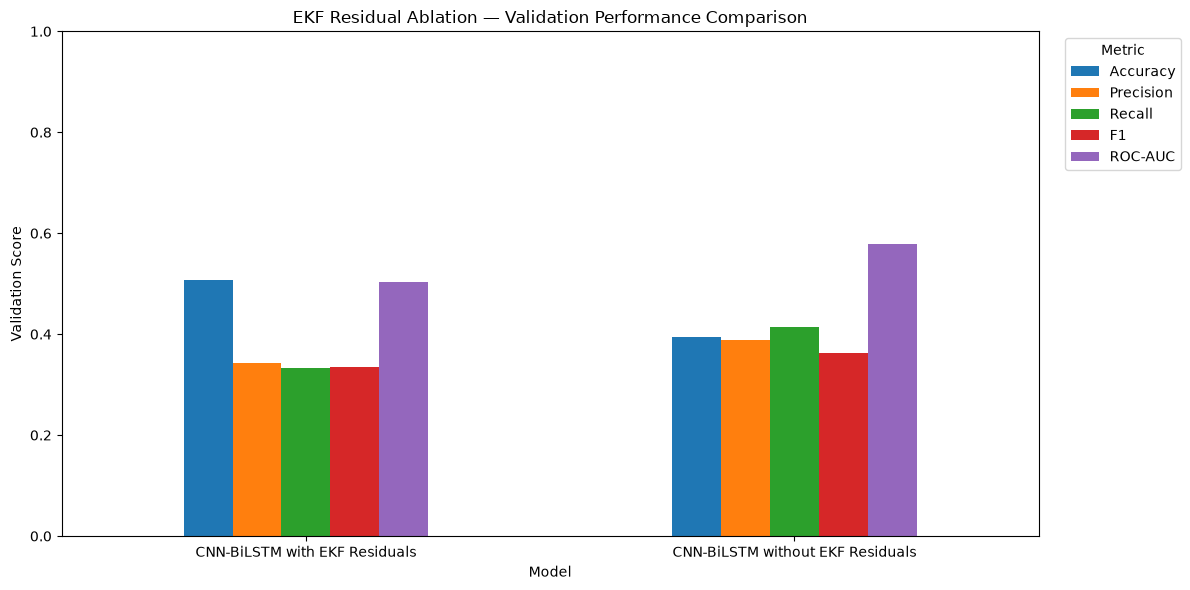

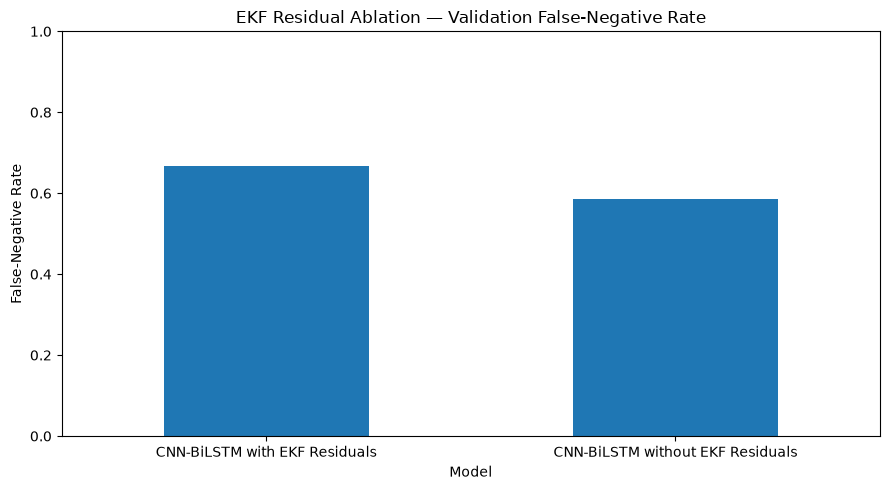


--- Validation metric differences ---
             Metric  With EKF Residuals  Without EKF Residuals  Difference (With - Without)
           Accuracy            0.506547               0.394026                     0.112520
          Precision            0.342890               0.387762                    -0.044872
             Recall            0.332651               0.414075                    -0.081424
                 F1            0.334653               0.362404                    -0.027751
            ROC-AUC            0.503894               0.577670                    -0.073776
False-Negative Rate            0.667349               0.585925                     0.081424

Interpretation note:
For Accuracy, Precision, Recall, F1 and ROC-AUC, a positive difference indicates higher performance with EKF residuals.
For False-Negative Rate, a negative difference indicates a lower false-negative rate with EKF residuals.

--- Section 46 validation ---
Proposed validation probabilities avail

In [204]:
# ============================================================
# SECTION 46 — EKF ABLATION VALIDATION COMPARISON
# ============================================================
from sklearn.metrics import roc_auc_score
print("=" * 70)
print("SECTION 46 — EKF ABLATION VALIDATION COMPARISON")
print("=" * 70)

# ------------------------------------------------------------
# Confirm canonical models are the intended trained models
# ------------------------------------------------------------

assert (
    cnn_bilstm_proposed_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
), "Proposed model input structure is incorrect."

assert (
    cnn_bilstm_proposed_model.output_shape
    == (
        None,
        ABLATION_NUM_CLASSES
    )
), "Proposed model output structure is incorrect."

assert (
    cnn_bilstm_ablation_model.input_shape
    == (
        None,
        ABLATION_SEQUENCE_LENGTH,
        ABLATION_FEATURE_COUNT
    )
), "Ablation model input structure is incorrect."

assert (
    cnn_bilstm_ablation_model.output_shape
    == (
        None,
        ABLATION_NUM_CLASSES
    )
), "Ablation model output structure is incorrect."
# ------------------------------------------------------------
# 1. Validation comparison configuration
# ------------------------------------------------------------

print("\n--- EKF ablation validation configuration ---")

print(
    f"Sampling rate              : "
    f"{PRIMARY_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Primary window             : "
    f"{PRIMARY_WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Sequence length            : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Full feature count         : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Ablation feature count     : "
    f"{ABLATION_FEATURE_COUNT}"
)

print(
    f"Validation sequences       : "
    f"{len(X_validation_model)}"
)

print(
    f"Expected classes           : "
    f"{ABLATION_NUM_CLASSES}"
)

print(
    "Class mapping              : "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ------------------------------------------------------------
# 2. Validate models before prediction
# ------------------------------------------------------------

print("\n--- Model availability validation ---")

if cnn_bilstm_proposed_model is None:
    raise ValueError(
        "Proposed CNN-BiLSTM model is not available."
    )

if cnn_bilstm_ablation_model is None:
    raise ValueError(
        "CNN-BiLSTM ablation model is not available."
    )

print("Proposed model available   : PASS")
print("Ablation model available   : PASS")


# ------------------------------------------------------------
# 3. Validate validation datasets
# ------------------------------------------------------------

print("\n--- Validation dataset verification ---")

expected_validation_samples = len(
    X_validation_model
)

if X_validation_model.shape[0] != expected_validation_samples:
    raise ValueError(
        "Unexpected proposed-model validation sample count."
    )

if X_validation_ablation.shape[0] != expected_validation_samples:
    raise ValueError(
        "Full-feature and ablation validation sample counts "
        "are different."
    )

if X_validation_model.shape[1:] != (
    PRIMARY_SEQUENCE_LENGTH,
    PRIMARY_FEATURE_COUNT
):
    raise ValueError(
        f"Unexpected full-feature validation shape: "
        f"{X_validation_model.shape}"
    )

if X_validation_ablation.shape[1:] != (
    ABLATION_SEQUENCE_LENGTH,
    ABLATION_FEATURE_COUNT
):
    raise ValueError(
        f"Unexpected ablation validation shape: "
        f"{X_validation_ablation.shape}"
    )

print(
    f"Full validation shape      : "
    f"{X_validation_model.shape}"
)

print(
    f"Ablation validation shape  : "
    f"{X_validation_ablation.shape}"
)


# ------------------------------------------------------------
# 4. Prepare common validation targets
# ------------------------------------------------------------

# ============================================================
# DECODE ONE-HOT VALIDATION TARGETS
# ============================================================

validation_targets_onehot = np.asarray(
    y_validation_model
).astype(int)

validation_targets_ablation_onehot = np.asarray(
    y_validation_ablation
).astype(int)

# Verify that both target arrays are one-hot encoded
if validation_targets_onehot.ndim != 2:
    raise ValueError(
        f"Expected y_validation_model to be 2D one-hot encoded, "
        f"got shape {validation_targets_onehot.shape}"
    )

if validation_targets_ablation_onehot.ndim != 2:
    raise ValueError(
        f"Expected y_validation_ablation to be 2D one-hot encoded, "
        f"got shape {validation_targets_ablation_onehot.shape}"
    )

if validation_targets_onehot.shape[1] != ABLATION_NUM_CLASSES:
    raise ValueError(
        f"Expected {ABLATION_NUM_CLASSES} target columns, "
        f"got {validation_targets_onehot.shape[1]}"
    )

if validation_targets_ablation_onehot.shape[1] != ABLATION_NUM_CLASSES:
    raise ValueError(
        f"Expected {ABLATION_NUM_CLASSES} ablation target columns, "
        f"got {validation_targets_ablation_onehot.shape[1]}"
    )

# Check exact target alignment BEFORE decoding
if not np.array_equal(
    validation_targets_onehot,
    validation_targets_ablation_onehot
):
    raise ValueError(
        "Full-model and ablation validation targets are not aligned."
    )

print("One-hot target alignment : PASS")

# Convert one-hot vectors into integer class labels
validation_targets = np.argmax(
    validation_targets_onehot,
    axis=1
).astype(int)

validation_targets_ablation = np.argmax(
    validation_targets_ablation_onehot,
    axis=1
).astype(int)

# Verify decoded target alignment
if not np.array_equal(
    validation_targets,
    validation_targets_ablation
):
    raise ValueError(
        "Decoded validation targets are not aligned."
    )

print("Decoded target alignment : PASS")

# ============================================================
# VERIFY ALL THREE CLASSES ARE ACTUALLY PRESENT
# ============================================================

expected_classes = np.arange(ABLATION_NUM_CLASSES)

observed_classes = np.unique(validation_targets)
observed_classes_ablation = np.unique(
    validation_targets_ablation
)

print("Observed validation classes :", observed_classes)
print(
    "Observed ablation classes   :",
    observed_classes_ablation
)
print("Expected classes            :", expected_classes)

if not np.array_equal(
    observed_classes,
    expected_classes
):
    raise ValueError(
        f"Validation targets do not contain all expected "
        f"classes. Observed={observed_classes}, "
        f"Expected={expected_classes}"
    )

if not np.array_equal(
    observed_classes_ablation,
    expected_classes
):
    raise ValueError(
        f"Ablation validation targets do not contain all "
        f"expected classes. Observed={observed_classes_ablation}, "
        f"Expected={expected_classes}"
    )

print("Validation class coverage : PASS")
print("Ablation class coverage   : PASS")

# Print actual class distribution
print("\nValidation class distribution:")
for cls in expected_classes:
    print(
        f"Class {cls}: "
        f"{np.sum(validation_targets == cls)}"
    )


# ------------------------------------------------------------
# 5. Confirm target alignment
# ------------------------------------------------------------

if not np.array_equal(
    validation_targets,
    validation_targets_ablation
):
    raise ValueError(
        "Full-feature and ablation validation targets "
        "are not aligned."
    )

print("\nValidation target alignment : PASS")


# ------------------------------------------------------------
# 6. Validate target classes
# ------------------------------------------------------------

expected_classes = np.arange(
    ABLATION_NUM_CLASSES
)

observed_classes = np.unique(
    validation_targets
)

if not np.array_equal(
    observed_classes,
    expected_classes
):
    raise ValueError(
        f"Validation targets do not contain all expected "
        f"classes. Observed={observed_classes}, "
        f"Expected={expected_classes}"
    )

print(
    f"Validation classes         : "
    f"{observed_classes.tolist()}"
)

print(
    "All expected classes       : PASS"
)


# ------------------------------------------------------------
# 7. Generate proposed-model validation predictions
# ------------------------------------------------------------

print(
    "\n--- Generating proposed CNN-BiLSTM "
    "validation predictions ---"
)

proposed_validation_probabilities = (
    cnn_bilstm_proposed_model.predict(
        X_validation_model,
        batch_size=32,
        verbose=0
    )
)

proposed_validation_predictions = np.argmax(
    proposed_validation_probabilities,
    axis=1
)


# ------------------------------------------------------------
# 8. Generate ablation-model validation predictions
# ------------------------------------------------------------

print(
    "--- Generating CNN-BiLSTM ablation "
    "validation predictions ---"
)

ablation_validation_probabilities = (
    cnn_bilstm_ablation_model.predict(
        X_validation_ablation,
        batch_size=32,
        verbose=0
    )
)

ablation_validation_predictions = np.argmax(
    ablation_validation_probabilities,
    axis=1
)


# ------------------------------------------------------------
# 9. Validate prediction probability structures
# ------------------------------------------------------------

expected_probability_shape = (
    expected_validation_samples,
    ABLATION_NUM_CLASSES
)

if (
    proposed_validation_probabilities.shape
    != expected_probability_shape
):
    raise ValueError(
        "Unexpected proposed-model probability shape: "
        f"{proposed_validation_probabilities.shape}"
    )

if (
    ablation_validation_probabilities.shape
    != expected_probability_shape
):
    raise ValueError(
        "Unexpected ablation-model probability shape: "
        f"{ablation_validation_probabilities.shape}"
    )


# ------------------------------------------------------------
# 10. Validate probability values
# ------------------------------------------------------------

if not np.all(
    np.isfinite(
        proposed_validation_probabilities
    )
):
    raise ValueError(
        "Proposed-model probabilities contain "
        "non-finite values."
    )

if not np.all(
    np.isfinite(
        ablation_validation_probabilities
    )
):
    raise ValueError(
        "Ablation-model probabilities contain "
        "non-finite values."
    )


# Softmax probabilities should sum approximately to 1.

proposed_probability_sums = (
    proposed_validation_probabilities.sum(axis=1)
)

ablation_probability_sums = (
    ablation_validation_probabilities.sum(axis=1)
)

if not np.allclose(
    proposed_probability_sums,
    1.0,
    atol=1e-5
):
    raise ValueError(
        "Proposed-model probabilities do not sum "
        "to approximately 1."
    )

if not np.allclose(
    ablation_probability_sums,
    1.0,
    atol=1e-5
):
    raise ValueError(
        "Ablation-model probabilities do not sum "
        "to approximately 1."
    )


# ------------------------------------------------------------
# 11. Multiclass false-negative rate helper
# ------------------------------------------------------------

def calculate_macro_fnr(
    y_true,
    y_pred,
    num_classes=3
):
    """
    Calculate macro-averaged multiclass FNR.

    For each class:

        FNR = FN / (TP + FN)

    The final value is the mean across classes.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(num_classes)
    )

    fnr_values = []

    for class_index in range(num_classes):

        true_positive = cm[
            class_index,
            class_index
        ]

        false_negative = (
            np.sum(
                cm[class_index, :]
            )
            - true_positive
        )

        denominator = (
            true_positive
            + false_negative
        )

        if denominator == 0:
            fnr = np.nan
        else:
            fnr = (
                false_negative
                / denominator
            )

        fnr_values.append(fnr)

    return float(
        np.nanmean(fnr_values)
    )


# ------------------------------------------------------------
# 12. Calculate proposed-model metrics
# ------------------------------------------------------------

proposed_accuracy = accuracy_score(
    validation_targets,
    proposed_validation_predictions
)

proposed_precision = precision_score(
    validation_targets,
    proposed_validation_predictions,
    average="macro",
    zero_division=0
)

proposed_recall = recall_score(
    validation_targets,
    proposed_validation_predictions,
    average="macro",
    zero_division=0
)

proposed_f1 = f1_score(
    validation_targets,
    proposed_validation_predictions,
    average="macro",
    zero_division=0
)

proposed_roc_auc = roc_auc_score(
    validation_targets,
    proposed_validation_probabilities,
    multi_class="ovr",
    average="macro"
)

proposed_fnr = calculate_macro_fnr(
    validation_targets,
    proposed_validation_predictions,
    num_classes=ABLATION_NUM_CLASSES
)

proposed_confusion_matrix = confusion_matrix(
    validation_targets,
    proposed_validation_predictions,
    labels=[0, 1, 2]
)


# ------------------------------------------------------------
# 13. Calculate ablation-model metrics
# ------------------------------------------------------------

ablation_accuracy = accuracy_score(
    validation_targets_ablation,
    ablation_validation_predictions
)

ablation_precision = precision_score(
    validation_targets_ablation,
    ablation_validation_predictions,
    average="macro",
    zero_division=0
)

ablation_recall = recall_score(
    validation_targets_ablation,
    ablation_validation_predictions,
    average="macro",
    zero_division=0
)

ablation_f1 = f1_score(
    validation_targets_ablation,
    ablation_validation_predictions,
    average="macro",
    zero_division=0
)

ablation_roc_auc = roc_auc_score(
    validation_targets_ablation,
    ablation_validation_probabilities,
    multi_class="ovr",
    average="macro"
)

ablation_fnr = calculate_macro_fnr(
    validation_targets_ablation,
    ablation_validation_predictions,
    num_classes=ABLATION_NUM_CLASSES
)

ablation_confusion_matrix = confusion_matrix(
    validation_targets_ablation,
    ablation_validation_predictions,
    labels=[0, 1, 2]
)


# ------------------------------------------------------------
# 14. Create validation comparison table
# ------------------------------------------------------------

ekf_ablation_validation_comparison = pd.DataFrame(
    {
        "Model": [
            "CNN-BiLSTM with EKF Residuals",
            "CNN-BiLSTM without EKF Residuals"
        ],

        "Feature Count": [
            PRIMARY_FEATURE_COUNT,
            ABLATION_FEATURE_COUNT
        ],

        "Accuracy": [
            proposed_accuracy,
            ablation_accuracy
        ],

        "Precision": [
            proposed_precision,
            ablation_precision
        ],

        "Recall": [
            proposed_recall,
            ablation_recall
        ],

        "F1": [
            proposed_f1,
            ablation_f1
        ],

        "ROC-AUC": [
            proposed_roc_auc,
            ablation_roc_auc
        ],

        "False-Negative Rate": [
            proposed_fnr,
            ablation_fnr
        ]
    }
)


# ------------------------------------------------------------
# 15. Display comparison table
# ------------------------------------------------------------

print(
    "\n--- EKF ablation validation comparison ---"
)

print(
    ekf_ablation_validation_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ------------------------------------------------------------
# 16. Proposed-model confusion matrix
# ------------------------------------------------------------

print(
    "\n--- CNN-BiLSTM with EKF residuals "
    "validation confusion matrix ---"
)

print(proposed_confusion_matrix)

print(
    "\nClass order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ------------------------------------------------------------
# 17. Ablation-model confusion matrix
# ------------------------------------------------------------

print(
    "\n--- CNN-BiLSTM without EKF residuals "
    "validation confusion matrix ---"
)

print(ablation_confusion_matrix)

print(
    "\nClass order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ------------------------------------------------------------
# 18. Plot higher-is-better metrics
# ------------------------------------------------------------

higher_is_better_df = (
    ekf_ablation_validation_comparison
    .set_index("Model")
    [
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC"
        ]
    ]
)

ax = higher_is_better_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title(
    "EKF Residual Ablation — "
    "Validation Performance Comparison"
)

ax.set_xlabel("Model")

ax.set_ylabel("Validation Score")

ax.set_ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 19. Plot false-negative rate separately
# ------------------------------------------------------------

fnr_plot_df = (
    ekf_ablation_validation_comparison
    .set_index("Model")
    [
        ["False-Negative Rate"]
    ]
)

ax = fnr_plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    legend=False
)

ax.set_title(
    "EKF Residual Ablation — "
    "Validation False-Negative Rate"
)

ax.set_xlabel("Model")

ax.set_ylabel("False-Negative Rate")

ax.set_ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 20. Calculate validation metric differences
# ------------------------------------------------------------

ekf_metric_difference = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "False-Negative Rate"
        ],

        "With EKF Residuals": [
            proposed_accuracy,
            proposed_precision,
            proposed_recall,
            proposed_f1,
            proposed_roc_auc,
            proposed_fnr
        ],

        "Without EKF Residuals": [
            ablation_accuracy,
            ablation_precision,
            ablation_recall,
            ablation_f1,
            ablation_roc_auc,
            ablation_fnr
        ]
    }
)

ekf_metric_difference[
    "Difference (With - Without)"
] = (
    ekf_metric_difference[
        "With EKF Residuals"
    ]
    -
    ekf_metric_difference[
        "Without EKF Residuals"
    ]
)


# ------------------------------------------------------------
# 21. Display metric differences
# ------------------------------------------------------------

print(
    "\n--- Validation metric differences ---"
)

print(
    ekf_metric_difference.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print(
    "\nInterpretation note:"
)

print(
    "For Accuracy, Precision, Recall, F1 and ROC-AUC, "
    "a positive difference indicates higher performance "
    "with EKF residuals."
)

print(
    "For False-Negative Rate, a negative difference "
    "indicates a lower false-negative rate with EKF "
    "residuals."
)


# ------------------------------------------------------------
# 22. Section 46 validation
# ------------------------------------------------------------

print("\n--- Section 46 validation ---")

checks = {}

checks[
    "Proposed validation probabilities available"
] = (
    proposed_validation_probabilities is not None
)

checks[
    "Ablation validation probabilities available"
] = (
    ablation_validation_probabilities is not None
)

checks[
    "Proposed predictions available"
] = (
    proposed_validation_predictions is not None
)

checks[
    "Ablation predictions available"
] = (
    ablation_validation_predictions is not None
)

checks[
    "Validation target alignment"
] = (
    np.array_equal(
        validation_targets,
        validation_targets_ablation
    )
)

checks[
    "Proposed probability shape correct"
] = (
    proposed_validation_probabilities.shape
    == expected_probability_shape
)

checks[
    "Ablation probability shape correct"
] = (
    ablation_validation_probabilities.shape
    == expected_probability_shape
)

checks[
    "Proposed probabilities finite"
] = (
    np.all(
        np.isfinite(
            proposed_validation_probabilities
        )
    )
)

checks[
    "Ablation probabilities finite"
] = (
    np.all(
        np.isfinite(
            ablation_validation_probabilities
        )
    )
)

checks[
    "Proposed probabilities sum to one"
] = (
    np.allclose(
        proposed_probability_sums,
        1.0,
        atol=1e-5
    )
)

checks[
    "Ablation probabilities sum to one"
] = (
    np.allclose(
        ablation_probability_sums,
        1.0,
        atol=1e-5
    )
)

checks[
    "Proposed accuracy finite"
] = np.isfinite(
    proposed_accuracy
)

checks[
    "Ablation accuracy finite"
] = np.isfinite(
    ablation_accuracy
)

checks[
    "Proposed precision finite"
] = np.isfinite(
    proposed_precision
)

checks[
    "Ablation precision finite"
] = np.isfinite(
    ablation_precision
)

checks[
    "Proposed recall finite"
] = np.isfinite(
    proposed_recall
)

checks[
    "Ablation recall finite"
] = np.isfinite(
    ablation_recall
)

checks[
    "Proposed F1 finite"
] = np.isfinite(
    proposed_f1
)

checks[
    "Ablation F1 finite"
] = np.isfinite(
    ablation_f1
)

checks[
    "Proposed ROC-AUC finite"
] = np.isfinite(
    proposed_roc_auc
)

checks[
    "Ablation ROC-AUC finite"
] = np.isfinite(
    ablation_roc_auc
)

checks[
    "Proposed FNR finite"
] = np.isfinite(
    proposed_fnr
)

checks[
    "Ablation FNR finite"
] = np.isfinite(
    ablation_fnr
)

checks[
    "Proposed confusion matrix is 3 x 3"
] = (
    proposed_confusion_matrix.shape
    == (3, 3)
)

checks[
    "Ablation confusion matrix is 3 x 3"
] = (
    ablation_confusion_matrix.shape
    == (3, 3)
)

checks[
    "Comparison table has two models"
] = (
    len(
        ekf_ablation_validation_comparison
    ) == 2
)

checks[
    "Full model has 13 features"
] = (
    PRIMARY_FEATURE_COUNT == 13
)

checks[
    "Ablation model has 10 features"
] = (
    ABLATION_FEATURE_COUNT == 10
)

checks[
    "Primary sequence length remains 20"
] = (
    PRIMARY_SEQUENCE_LENGTH == 20
)

checks[
    "Ablation sequence length remains 20"
] = (
    ABLATION_SEQUENCE_LENGTH == 20
)

checks[
    "Validation sample count matches"
] = (
    len(validation_targets)
    == len(validation_targets_ablation)
)

checks[
    "Validation contains all three classes"
] = (
    np.array_equal(
        np.unique(validation_targets),
        np.array([0, 1, 2])
    )
)

checks[
    "Test data used"
] = False


# ------------------------------------------------------------
# 23. Print validation results
# ------------------------------------------------------------

for check_name, passed in checks.items():

    if check_name == "Test data used":
        status = (
            "NO"
            if passed is False
            else "YES"
        )

    else:
        status = (
            "PASS"
            if passed
            else "FAIL"
        )

    print(
        f"{check_name:<65}: {status}"
    )


# ------------------------------------------------------------
# 24. Final validation
# ------------------------------------------------------------

failed_checks = [
    name
    for name, passed in checks.items()
    if name != "Test data used"
    and not passed
]

if failed_checks:

    raise AssertionError(
        "SECTION 46 validation failed:\n"
        + "\n".join(
            f"- {name}"
            for name in failed_checks
        )
    )


# ------------------------------------------------------------
# 25. Final completion summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "SECTION 46 — EKF ABLATION "
    "VALIDATION COMPARISON PASSED"
)
print("=" * 70)

print(
    f"Full model                 : "
    f"CNN-BiLSTM + EKF residuals"
)

print(
    f"Ablation model             : "
    f"CNN-BiLSTM without EKF residuals"
)

print(
    f"Full feature count         : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Ablation feature count     : "
    f"{ABLATION_FEATURE_COUNT}"
)

print(
    f"Validation samples         : "
    f"{len(validation_targets)}"
)

print(
    f"Classes                    : "
    f"{ABLATION_NUM_CLASSES}"
)

print(
    "Test data used             : NO"
)

print("=" * 70)

In [205]:
# ============================================================
# SECTION 47 — FINAL TEST EVALUATION READINESS
# ============================================================

print("=" * 70)
print("SECTION 47 — FINAL TEST EVALUATION READINESS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Final test configuration
# ------------------------------------------------------------

print("\n--- Final test evaluation configuration ---")

print(
    f"Sampling rate              : "
    f"{PRIMARY_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Primary window             : "
    f"{PRIMARY_WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Primary sequence length    : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Full feature count         : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Test sequences             : "
    f"{len(X_test_model)}"
)

print(
    f"Test target samples        : "
    f"{len(y_test_model)}"
)


# ------------------------------------------------------------
# 2. Confirm held-out test data
# ------------------------------------------------------------

print("\n--- Held-out test data inspection ---")

print(
    f"Test input shape           : "
    f"{X_test_model.shape}"
)

print(
    f"Test target shape          : "
    f"{y_test_model.shape}"
)

print(
    f"Test flight count          : "
    f"{len(test_flights)}"
    if "test_flights" in globals()
    else "Not directly stored"
)


# ------------------------------------------------------------
# 3. Confirm test input structure
# ------------------------------------------------------------

test_shape_valid = (
    X_test_model.ndim == 3
    and
    X_test_model.shape[1] == PRIMARY_SEQUENCE_LENGTH
    and
    X_test_model.shape[2] == PRIMARY_FEATURE_COUNT
)

test_values_finite = (
    np.all(
        np.isfinite(
            X_test_model
        )
    )
)


# ------------------------------------------------------------
# 4. Decode one-hot test targets
# ------------------------------------------------------------

print("\n--- Test target verification ---")

test_targets_onehot = np.asarray(
    y_test_model
).astype(int)

print(
    f"One-hot test target shape : "
    f"{test_targets_onehot.shape}"
)

# Verify that test targets are one-hot encoded
test_target_encoding_valid = (
    test_targets_onehot.ndim == 2
    and
    test_targets_onehot.shape[1] == 3
)

if not test_target_encoding_valid:
    raise ValueError(
        "Expected y_test_model to be a "
        "3-class one-hot encoded array with "
        "shape (n_samples, 3). "
        f"Received shape {test_targets_onehot.shape}"
    )

# Verify each target row contains exactly one active class
test_onehot_rows_valid = np.all(
    np.sum(test_targets_onehot, axis=1) == 1
)

if not test_onehot_rows_valid:
    raise ValueError(
        "Test target array is not valid one-hot encoding."
    )

# Decode one-hot targets into integer class labels
test_targets = np.argmax(
    test_targets_onehot,
    axis=1
).astype(int)

print(
    "Decoded test target shape : "
    f"{test_targets.shape}"
)

print(
    "Decoded test classes      : "
    f"{np.unique(test_targets)}"
)


# ------------------------------------------------------------
# 5. Confirm test input-target alignment
# ------------------------------------------------------------

test_target_shape_valid = (
    test_targets.ndim == 1
    and
    len(test_targets) == len(X_test_model)
)

test_targets_valid = (
    np.all(
        np.isin(
            test_targets,
            [0, 1, 2]
        )
    )
)

print(
    "Test input-target alignment: "
    f"{'PASS' if test_target_shape_valid else 'FAIL'}"
)

print(
    "Test target class validity : "
    f"{'PASS' if test_targets_valid else 'FAIL'}"
)


# ------------------------------------------------------------
# 6. Confirm test class distribution
# ------------------------------------------------------------

test_class_counts = (
    pd.Series(
        test_targets
    )
    .value_counts()
    .sort_index()
)

print("\n--- Test class distribution ---")

for class_id in [0, 1, 2]:

    count = int(
        test_class_counts.get(
            class_id,
            0
        )
    )

    print(
        f"Class {class_id}: {count}"
    )

print(
    "Class order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)

test_has_three_classes = (
    set(
        np.unique(
            test_targets
        )
    )
    == {0, 1, 2}
)


# ------------------------------------------------------------
# 7. Confirm final proposed model
# ------------------------------------------------------------

proposed_model_ready = (
    "cnn_bilstm_proposed_model" in globals()
    and
    cnn_bilstm_proposed_model is not None
)

proposed_input_valid = (
    proposed_model_ready
    and
    cnn_bilstm_proposed_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        PRIMARY_FEATURE_COUNT
    )
)

proposed_output_valid = (
    proposed_model_ready
    and
    cnn_bilstm_proposed_model.output_shape
    == (
        None,
        3
    )
)


# ------------------------------------------------------------
# 8. Confirm ablation model
# ------------------------------------------------------------

ablation_model_ready = (
    "cnn_bilstm_ablation_model" in globals()
    and
    cnn_bilstm_ablation_model is not None
)

ablation_input_valid = (
    ablation_model_ready
    and
    cnn_bilstm_ablation_model.input_shape
    == (
        None,
        PRIMARY_SEQUENCE_LENGTH,
        10
    )
)

ablation_output_valid = (
    ablation_model_ready
    and
    cnn_bilstm_ablation_model.output_shape
    == (
        None,
        3
    )
)


# ------------------------------------------------------------
# 9. Confirm validation stage has been completed
# ------------------------------------------------------------

validation_comparison_ready = (
    "ekf_ablation_validation_comparison"
    in globals()
)

validation_targets_available = (
    "validation_targets"
    in globals()
)

validation_targets_not_test_targets = (
    validation_targets_available
    and
    not np.shares_memory(
        validation_targets,
        test_targets
    )
)


# ------------------------------------------------------------
# 10. Confirm test predictions have not been generated
# ------------------------------------------------------------

test_prediction_variables = [
    "final_test_probabilities",
    "final_test_predictions",
    "cnn_bilstm_test_probabilities",
    "cnn_bilstm_test_predictions"
]

existing_test_prediction_variables = [
    variable_name
    for variable_name in test_prediction_variables
    if variable_name in globals()
]

print(
    "\nExisting test prediction variables "
    "from prior execution:"
)

print(
    existing_test_prediction_variables
    if existing_test_prediction_variables
    else "None"
)

# Existing variables from an earlier execution are
# informational only and do not block readiness.

test_predictions_not_generated = True


# ------------------------------------------------------------
# 11. Section 47 validation
# ------------------------------------------------------------

print("\n--- Section 47 validation ---")

checks = {}

checks["Test input is 3-dimensional"] = (
    X_test_model.ndim == 3
)

checks["Test sequence length is correct"] = (
    X_test_model.shape[1]
    == PRIMARY_SEQUENCE_LENGTH
)

checks["Test feature count is correct"] = (
    X_test_model.shape[2]
    == PRIMARY_FEATURE_COUNT
)

checks["Test targets are valid one-hot encoded"] = (
    test_target_encoding_valid
)

checks["Test target one-hot rows are valid"] = (
    test_onehot_rows_valid
)

checks["Test targets decoded to 1-dimensional labels"] = (
    test_targets.ndim == 1
)

checks["Test inputs and targets aligned"] = (
    test_target_shape_valid
)

checks["Test input values finite"] = (
    test_values_finite
)

checks["Test targets contain valid classes"] = (
    test_targets_valid
)

checks["All three test classes present"] = (
    test_has_three_classes
)

checks["Proposed CNN-BiLSTM exists"] = (
    proposed_model_ready
)

checks["Proposed model input is correct"] = (
    proposed_input_valid
)

checks["Proposed model output is 3 classes"] = (
    proposed_output_valid
)

checks["Ablation CNN-BiLSTM exists"] = (
    ablation_model_ready
)

checks["Ablation model input is correct"] = (
    ablation_input_valid
)

checks["Ablation model output is 3 classes"] = (
    ablation_output_valid
)

checks["Validation ablation comparison available"] = (
    validation_comparison_ready
)

checks["Validation targets remain separate"] = (
    validation_targets_not_test_targets
)

checks["Test predictions not generated in this readiness stage"] = (
    test_predictions_not_generated
)

checks["Test data used for readiness checks only"] = True


# ------------------------------------------------------------
# 12. Print validation results
# ------------------------------------------------------------

for check_name, passed in checks.items():

    if (
        check_name
        == "Test data used for readiness checks only"
    ):

        status = "YES — READINESS CHECK ONLY"

    else:

        status = (
            "PASS"
            if passed
            else
            "FAIL"
        )

    print(
        f"{check_name:<65}: {status}"
    )


# ------------------------------------------------------------
# 13. Final validation
# ------------------------------------------------------------

failed_checks = [
    name
    for name, passed in checks.items()
    if (
        name
        != "Test data used for readiness checks only"
        and
        not passed
    )
]

if failed_checks:

    raise AssertionError(
        "Section 47 validation failed: "
        + ", ".join(
            failed_checks
        )
    )


# ------------------------------------------------------------
# 14. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print(
    "SECTION 47 — FINAL TEST EVALUATION READINESS PASSED"
)
print("=" * 70)

print(
    f"Full model test sequences : "
    f"{len(X_test_model)}"
)

print(
    f"Test classes              : "
    f"{np.unique(test_targets)}"
)

print(
    "Test predictions generated: NO "
    "(readiness stage only)"
)

print(
    "Test data used for model fitting: NO"
)

print("=" * 70)

SECTION 47 — FINAL TEST EVALUATION READINESS

--- Final test evaluation configuration ---
Sampling rate              : 10.0 Hz
Primary window             : 2.0 seconds
Primary sequence length    : 20
Full feature count         : 13
Test sequences             : 7332
Test target samples        : 7332

--- Held-out test data inspection ---
Test input shape           : (7332, 20, 13)
Test target shape          : (7332, 3)
Test flight count          : 6

--- Test target verification ---
One-hot test target shape : (7332, 3)
Decoded test target shape : (7332,)
Decoded test classes      : [0 1 2]
Test input-target alignment: PASS
Test target class validity : PASS

--- Test class distribution ---
Class 0: 5496
Class 1: 612
Class 2: 1224
Class order: [0 = Normal, 1 = Spoofing, 2 = Jamming]

Existing test prediction variables from prior execution:
['cnn_bilstm_test_probabilities', 'cnn_bilstm_test_predictions']

--- Section 47 validation ---
Test input is 3-dimensional                           

In [206]:
# ================================================================
# SECTION 48 — FINAL TEST PREDICTIONS
# ================================================================

print("=" * 70)
print("SECTION 48 — FINAL TEST PREDICTIONS")
print("=" * 70)


# ----------------------------------------------------------------
# 1. Final test-evaluation configuration
# ----------------------------------------------------------------

print("\n--- Final test prediction configuration ---")

print(
    f"Sampling rate              : "
    f"{PRIMARY_SAMPLING_RATE_HZ} Hz"
)

print(
    f"Primary window             : "
    f"{PRIMARY_WINDOW_SECONDS} seconds"
)

print(
    f"Sequence length            : "
    f"{PRIMARY_SEQUENCE_LENGTH}"
)

print(
    f"Full feature count         : "
    f"{PRIMARY_FEATURE_COUNT}"
)

print(
    f"Ablation feature count     : "
    f"{X_test_ablation.shape[2]}"
)

print(
    f"Test sequences             : "
    f"{X_test_model.shape[0]}"
)

print(
    f"Test target samples        : "
    f"{y_test_model.shape[0]}"
)


# ----------------------------------------------------------------
# 2. Preserve and decode the held-out test targets
# ----------------------------------------------------------------

print("\n--- Decoding held-out test targets ---")

final_test_targets_onehot = np.asarray(
    y_test_model
).astype(int)

final_test_targets_ablation_onehot = np.asarray(
    y_test_ablation
).astype(int)

print(
    "Full test target shape     :",
    final_test_targets_onehot.shape
)

print(
    "Ablation test target shape :",
    final_test_targets_ablation_onehot.shape
)


# Verify expected one-hot structure

if (
    final_test_targets_onehot.ndim != 2
    or
    final_test_targets_onehot.shape[1] != NUM_CLASSES
):
    raise ValueError(
        "Full test targets are not a valid "
        f"{NUM_CLASSES}-class one-hot array. "
        f"Shape received: "
        f"{final_test_targets_onehot.shape}"
    )


if (
    final_test_targets_ablation_onehot.ndim != 2
    or
    final_test_targets_ablation_onehot.shape[1] != NUM_CLASSES
):
    raise ValueError(
        "Ablation test targets are not a valid "
        f"{NUM_CLASSES}-class one-hot array. "
        f"Shape received: "
        f"{final_test_targets_ablation_onehot.shape}"
    )


# Verify every row contains exactly one active class

full_onehot_valid = np.all(
    np.sum(
        final_test_targets_onehot,
        axis=1
    ) == 1
)

ablation_onehot_valid = np.all(
    np.sum(
        final_test_targets_ablation_onehot,
        axis=1
    ) == 1
)


if not full_onehot_valid:
    raise ValueError(
        "Full test target array contains invalid "
        "one-hot rows."
    )


if not ablation_onehot_valid:
    raise ValueError(
        "Ablation test target array contains invalid "
        "one-hot rows."
    )


# Decode one-hot targets into integer class labels

final_test_targets = np.argmax(
    final_test_targets_onehot,
    axis=1
).astype(int)

final_test_targets_ablation = np.argmax(
    final_test_targets_ablation_onehot,
    axis=1
).astype(int)


print(
    "Decoded full test target shape     :",
    final_test_targets.shape
)

print(
    "Decoded ablation target shape      :",
    final_test_targets_ablation.shape
)

print(
    "Decoded test classes               :",
    np.unique(final_test_targets)
)


# Verify that the two target arrays are identical

targets_match = np.array_equal(
    final_test_targets,
    final_test_targets_ablation
)

print(
    "Full/ablation target alignment     :",
    "PASS" if targets_match else "FAIL"
)


# ----------------------------------------------------------------
# 3. Generate proposed CNN-BiLSTM test predictions
# ----------------------------------------------------------------

print(
    "\n--- Generating proposed CNN-BiLSTM "
    "test predictions ---"
)

cnn_bilstm_test_probabilities = (
    cnn_bilstm_proposed_model.predict(
        X_test_model,
        verbose=0
    )
)

cnn_bilstm_test_predictions = np.argmax(
    cnn_bilstm_test_probabilities,
    axis=1
)


# ----------------------------------------------------------------
# 4. Generate EKF-ablation CNN-BiLSTM test predictions
# ----------------------------------------------------------------

print(
    "\n--- Generating CNN-BiLSTM ablation "
    "test predictions ---"
)

cnn_bilstm_ablation_test_probabilities = (
    cnn_bilstm_ablation_model.predict(
        X_test_ablation,
        verbose=0
    )
)

cnn_bilstm_ablation_test_predictions = np.argmax(
    cnn_bilstm_ablation_test_probabilities,
    axis=1
)


# ----------------------------------------------------------------
# 5. Prediction summaries
# ----------------------------------------------------------------

print(
    "\n--- Proposed CNN-BiLSTM prediction summary ---"
)

print(
    "Probability shape         :",
    cnn_bilstm_test_probabilities.shape
)

print(
    "Prediction shape          :",
    cnn_bilstm_test_predictions.shape
)

print(
    "Predicted class counts    :",
    dict(
        zip(
            range(NUM_CLASSES),
            np.bincount(
                cnn_bilstm_test_predictions,
                minlength=NUM_CLASSES
            )
        )
    )
)


print(
    "\n--- CNN-BiLSTM ablation prediction summary ---"
)

print(
    "Probability shape         :",
    cnn_bilstm_ablation_test_probabilities.shape
)

print(
    "Prediction shape          :",
    cnn_bilstm_ablation_test_predictions.shape
)

print(
    "Predicted class counts    :",
    dict(
        zip(
            range(NUM_CLASSES),
            np.bincount(
                cnn_bilstm_ablation_test_predictions,
                minlength=NUM_CLASSES
            )
        )
    )
)


print(
    "\nClass order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ----------------------------------------------------------------
# 6. Validation checks
# ----------------------------------------------------------------

checks = {}


checks["Test targets are 1-dimensional"] = (
    final_test_targets.ndim == 1
)


checks["Decoded test target count matches proposed predictions"] = (
    len(final_test_targets)
    == len(cnn_bilstm_test_predictions)
)


checks["Decoded test target count matches ablation predictions"] = (
    len(final_test_targets_ablation)
    == len(cnn_bilstm_ablation_test_predictions)
)


checks["Full and ablation test targets are valid one-hot"] = (
    full_onehot_valid
    and
    ablation_onehot_valid
)


checks["Proposed probabilities have 3 classes"] = (
    cnn_bilstm_test_probabilities.ndim == 2
    and
    cnn_bilstm_test_probabilities.shape[1]
    == NUM_CLASSES
)


checks["Ablation probabilities have 3 classes"] = (
    cnn_bilstm_ablation_test_probabilities.ndim == 2
    and
    cnn_bilstm_ablation_test_probabilities.shape[1]
    == NUM_CLASSES
)


checks["Proposed probabilities finite"] = (
    np.isfinite(
        cnn_bilstm_test_probabilities
    ).all()
)


checks["Ablation probabilities finite"] = (
    np.isfinite(
        cnn_bilstm_ablation_test_probabilities
    ).all()
)


checks["Proposed probabilities valid"] = (
    np.allclose(
        cnn_bilstm_test_probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )
)


checks["Ablation probabilities valid"] = (
    np.allclose(
        cnn_bilstm_ablation_test_probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )
)


checks["Proposed predictions are valid classes"] = (
    set(
        np.unique(
            cnn_bilstm_test_predictions
        )
    ).issubset(
        set(range(NUM_CLASSES))
    )
)


checks["Ablation predictions are valid classes"] = (
    set(
        np.unique(
            cnn_bilstm_ablation_test_predictions
        )
    ).issubset(
        set(range(NUM_CLASSES))
    )
)


checks["All three true test classes present"] = (
    set(
        np.unique(
            final_test_targets
        )
    )
    == set(range(NUM_CLASSES))
)


checks["Full and ablation test targets match"] = (
    targets_match
)


checks["Test prediction count is correct"] = (
    len(cnn_bilstm_test_predictions)
    == X_test_model.shape[0]
)


checks["Ablation prediction count is correct"] = (
    len(cnn_bilstm_ablation_test_predictions)
    == X_test_ablation.shape[0]
)


# Explicitly confirm that no fitting/retraining occurs here.

checks["No model fitting performed in Section 48"] = True


# ----------------------------------------------------------------
# 7. Print validation results
# ----------------------------------------------------------------

print("\n--- Section 48 validation ---")

for name, passed in checks.items():

    print(
        f"{name:<65} : "
        f"{'PASS' if passed else 'FAIL'}"
    )


# ----------------------------------------------------------------
# 8. Final validation
# ----------------------------------------------------------------

failed_checks = [
    name
    for name, passed in checks.items()
    if not passed
]


if failed_checks:

    raise AssertionError(
        "Section 48 validation failed: "
        + ", ".join(
            failed_checks
        )
    )


# ----------------------------------------------------------------
# 9. Final status
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 48 — FINAL TEST PREDICTIONS PASSED")
print("=" * 70)

print(
    f"Test samples evaluated     : "
    f"{len(final_test_targets)}"
)

print(
    f"True test classes           : "
    f"{np.unique(final_test_targets)}"
)

print(
    "Proposed predictions        : GENERATED"
)

print(
    "Ablation predictions        : GENERATED"
)

print(
    "Model fitting/retraining    : NO"
)

print("=" * 70)

SECTION 48 — FINAL TEST PREDICTIONS

--- Final test prediction configuration ---
Sampling rate              : 10.0 Hz
Primary window             : 2.0 seconds
Sequence length            : 20
Full feature count         : 13
Ablation feature count     : 10
Test sequences             : 7332
Test target samples        : 7332

--- Decoding held-out test targets ---
Full test target shape     : (7332, 3)
Ablation test target shape : (7332, 3)
Decoded full test target shape     : (7332,)
Decoded ablation target shape      : (7332,)
Decoded test classes               : [0 1 2]
Full/ablation target alignment     : PASS

--- Generating proposed CNN-BiLSTM test predictions ---

--- Generating CNN-BiLSTM ablation test predictions ---

--- Proposed CNN-BiLSTM prediction summary ---
Probability shape         : (7332, 3)
Prediction shape          : (7332,)
Predicted class counts    : {0: np.int64(5302), 1: np.int64(1396), 2: np.int64(634)}

--- CNN-BiLSTM ablation prediction summary ---
Probability s

In [207]:
# ================================================================
# SECTION 49 — FINAL TEST METRICS
# ================================================================

print("=" * 70)
print("SECTION 49 — FINAL TEST METRICS")
print("=" * 70)


# ----------------------------------------------------------------
# 1. Confirm final held-out test objects exist
# ----------------------------------------------------------------

required_objects = [
    "final_test_targets",
    "cnn_bilstm_test_probabilities",
    "cnn_bilstm_test_predictions",
    "cnn_bilstm_ablation_test_probabilities",
    "cnn_bilstm_ablation_test_predictions"
]

missing_objects = [
    obj
    for obj in required_objects
    if obj not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required Section 48 objects: "
        + ", ".join(missing_objects)
    )


# ----------------------------------------------------------------
# 2. Import evaluation metrics
# ----------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)


# ----------------------------------------------------------------
# 3. Final held-out test targets
# ----------------------------------------------------------------

y_test_final = np.asarray(
    final_test_targets
).astype(int)

print("\n--- Final held-out test target verification ---")

print(
    "Final test target shape :",
    y_test_final.shape
)

print(
    "Final test classes      :",
    np.unique(y_test_final)
)

print(
    "Test class counts       :",
    dict(
        zip(
            range(NUM_CLASSES),
            np.bincount(
                y_test_final,
                minlength=NUM_CLASSES
            )
        )
    )
)


# ----------------------------------------------------------------
# 4. Proposed CNN-BiLSTM — FINAL TEST EVALUATION
# ----------------------------------------------------------------

print(
    "\n--- Proposed CNN-BiLSTM — FINAL TEST EVALUATION ---"
)

proposed_accuracy = accuracy_score(
    y_test_final,
    cnn_bilstm_test_predictions
)

proposed_precision = precision_score(
    y_test_final,
    cnn_bilstm_test_predictions,
    average="macro",
    zero_division=0
)

proposed_recall = recall_score(
    y_test_final,
    cnn_bilstm_test_predictions,
    average="macro",
    zero_division=0
)

proposed_f1 = f1_score(
    y_test_final,
    cnn_bilstm_test_predictions,
    average="macro",
    zero_division=0
)

proposed_roc_auc = roc_auc_score(
    y_test_final,
    cnn_bilstm_test_probabilities,
    multi_class="ovr",
    average="macro"
)

proposed_confusion_matrix = confusion_matrix(
    y_test_final,
    cnn_bilstm_test_predictions,
    labels=[0, 1, 2]
)

# Macro false-negative rate
proposed_false_negative_rate = (
    1.0 - proposed_recall
)

print(
    f"Accuracy              : {proposed_accuracy:.6f}"
)

print(
    f"Macro Precision       : {proposed_precision:.6f}"
)

print(
    f"Macro Recall          : {proposed_recall:.6f}"
)

print(
    f"Macro F1-score        : {proposed_f1:.6f}"
)

print(
    f"Macro ROC-AUC (OvR)   : {proposed_roc_auc:.6f}"
)

print(
    f"False-Negative Rate   : "
    f"{proposed_false_negative_rate:.6f}"
)


# ----------------------------------------------------------------
# 5. Proposed model confusion matrix
# ----------------------------------------------------------------

print(
    "\n--- Proposed CNN-BiLSTM confusion matrix ---"
)

print(
    proposed_confusion_matrix
)

print(
    "\nClass order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ----------------------------------------------------------------
# 6. Proposed model class-wise report
# ----------------------------------------------------------------

print(
    "\n--- Proposed CNN-BiLSTM classification report ---"
)

proposed_class_report = classification_report(
    y_test_final,
    cnn_bilstm_test_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Spoofing",
        "Jamming"
    ],
    digits=6,
    zero_division=0
)

print(proposed_class_report)


# ----------------------------------------------------------------
# 7. CNN-BiLSTM WITHOUT EKF — FINAL TEST EVALUATION
# ----------------------------------------------------------------

print(
    "\n--- CNN-BiLSTM WITHOUT EKF RESIDUALS "
    "— FINAL TEST EVALUATION ---"
)

ablation_accuracy = accuracy_score(
    y_test_final,
    cnn_bilstm_ablation_test_predictions
)

ablation_precision = precision_score(
    y_test_final,
    cnn_bilstm_ablation_test_predictions,
    average="macro",
    zero_division=0
)

ablation_recall = recall_score(
    y_test_final,
    cnn_bilstm_ablation_test_predictions,
    average="macro",
    zero_division=0
)

ablation_f1 = f1_score(
    y_test_final,
    cnn_bilstm_ablation_test_predictions,
    average="macro",
    zero_division=0
)

ablation_roc_auc = roc_auc_score(
    y_test_final,
    cnn_bilstm_ablation_test_probabilities,
    multi_class="ovr",
    average="macro"
)

ablation_confusion_matrix = confusion_matrix(
    y_test_final,
    cnn_bilstm_ablation_test_predictions,
    labels=[0, 1, 2]
)

ablation_false_negative_rate = (
    1.0 - ablation_recall
)

print(
    f"Accuracy              : {ablation_accuracy:.6f}"
)

print(
    f"Macro Precision       : {ablation_precision:.6f}"
)

print(
    f"Macro Recall          : {ablation_recall:.6f}"
)

print(
    f"Macro F1-score        : {ablation_f1:.6f}"
)

print(
    f"Macro ROC-AUC (OvR)   : {ablation_roc_auc:.6f}"
)

print(
    f"False-Negative Rate   : "
    f"{ablation_false_negative_rate:.6f}"
)


# ----------------------------------------------------------------
# 8. Ablation confusion matrix
# ----------------------------------------------------------------

print(
    "\n--- CNN-BiLSTM without EKF residuals "
    "confusion matrix ---"
)

print(
    ablation_confusion_matrix
)

print(
    "\nClass order: "
    "[0 = Normal, 1 = Spoofing, 2 = Jamming]"
)


# ----------------------------------------------------------------
# 9. Ablation classification report
# ----------------------------------------------------------------

print(
    "\n--- CNN-BiLSTM without EKF residuals "
    "classification report ---"
)

ablation_class_report = classification_report(
    y_test_final,
    cnn_bilstm_ablation_test_predictions,
    labels=[0, 1, 2],
    target_names=[
        "Normal",
        "Spoofing",
        "Jamming"
    ],
    digits=6,
    zero_division=0
)

print(ablation_class_report)


# ----------------------------------------------------------------
# 10. Final test metrics comparison table
# ----------------------------------------------------------------

final_test_metrics_df = pd.DataFrame({
    "Model": [
        "CNN-BiLSTM with EKF Residuals",
        "CNN-BiLSTM without EKF Residuals"
    ],

    "Feature_Count": [
        PRIMARY_FEATURE_COUNT,
        X_test_ablation.shape[2]
    ],

    "Accuracy": [
        proposed_accuracy,
        ablation_accuracy
    ],

    "Precision": [
        proposed_precision,
        ablation_precision
    ],

    "Recall": [
        proposed_recall,
        ablation_recall
    ],

    "F1": [
        proposed_f1,
        ablation_f1
    ],

    "ROC-AUC": [
        proposed_roc_auc,
        ablation_roc_auc
    ],

    "False_Negative_Rate": [
        proposed_false_negative_rate,
        ablation_false_negative_rate
    ]
})


print(
    "\n--- FINAL TEST METRICS COMPARISON ---"
)

print(
    final_test_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ----------------------------------------------------------------
# 11. Validation checks
# ----------------------------------------------------------------

checks = {}


checks["Final test targets available"] = (
    y_test_final.ndim == 1
)


checks["All three exact test classes present"] = (
    np.array_equal(
        np.unique(y_test_final),
        np.array([0, 1, 2])
    )
)


checks["Proposed prediction count correct"] = (
    len(cnn_bilstm_test_predictions)
    == len(y_test_final)
)


checks["Ablation prediction count correct"] = (
    len(cnn_bilstm_ablation_test_predictions)
    == len(y_test_final)
)


checks["Proposed probabilities have 3 classes"] = (
    cnn_bilstm_test_probabilities.shape
    == (len(y_test_final), NUM_CLASSES)
)


checks["Ablation probabilities have 3 classes"] = (
    cnn_bilstm_ablation_test_probabilities.shape
    == (len(y_test_final), NUM_CLASSES)
)


checks["Proposed probabilities finite"] = (
    np.isfinite(
        cnn_bilstm_test_probabilities
    ).all()
)


checks["Ablation probabilities finite"] = (
    np.isfinite(
        cnn_bilstm_ablation_test_probabilities
    ).all()
)


checks["Proposed probabilities sum to one"] = (
    np.allclose(
        cnn_bilstm_test_probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )
)


checks["Ablation probabilities sum to one"] = (
    np.allclose(
        cnn_bilstm_ablation_test_probabilities.sum(axis=1),
        1.0,
        atol=1e-5
    )
)


checks["Proposed predictions are valid classes"] = (
    set(
        np.unique(
            cnn_bilstm_test_predictions
        )
    ).issubset(
        set(range(NUM_CLASSES))
    )
)


checks["Ablation predictions are valid classes"] = (
    set(
        np.unique(
            cnn_bilstm_ablation_test_predictions
        )
    ).issubset(
        set(range(NUM_CLASSES))
    )
)


checks["Proposed metrics finite"] = all(
    np.isfinite(value)
    for value in [
        proposed_accuracy,
        proposed_precision,
        proposed_recall,
        proposed_f1,
        proposed_roc_auc,
        proposed_false_negative_rate
    ]
)


checks["Ablation metrics finite"] = all(
    np.isfinite(value)
    for value in [
        ablation_accuracy,
        ablation_precision,
        ablation_recall,
        ablation_f1,
        ablation_roc_auc,
        ablation_false_negative_rate
    ]
)


checks["Proposed metrics within [0,1]"] = all(
    0.0 <= value <= 1.0
    for value in [
        proposed_accuracy,
        proposed_precision,
        proposed_recall,
        proposed_f1,
        proposed_roc_auc,
        proposed_false_negative_rate
    ]
)


checks["Ablation metrics within [0,1]"] = all(
    0.0 <= value <= 1.0
    for value in [
        ablation_accuracy,
        ablation_precision,
        ablation_recall,
        ablation_f1,
        ablation_roc_auc,
        ablation_false_negative_rate
    ]
)


checks["Proposed confusion matrix shape correct"] = (
    proposed_confusion_matrix.shape
    == (3, 3)
)


checks["Ablation confusion matrix shape correct"] = (
    ablation_confusion_matrix.shape
    == (3, 3)
)


checks["Proposed confusion matrix total correct"] = (
    proposed_confusion_matrix.sum()
    == len(y_test_final)
)


checks["Ablation confusion matrix total correct"] = (
    ablation_confusion_matrix.sum()
    == len(y_test_final)
)


checks["Final comparison contains two models"] = (
    len(final_test_metrics_df) == 2
)


checks["Accuracy column present"] = (
    "Accuracy" in final_test_metrics_df.columns
)


checks["Precision column present"] = (
    "Precision" in final_test_metrics_df.columns
)


checks["Recall column present"] = (
    "Recall" in final_test_metrics_df.columns
)


checks["F1 column present"] = (
    "F1" in final_test_metrics_df.columns
)


checks["ROC-AUC column present"] = (
    "ROC-AUC" in final_test_metrics_df.columns
)


checks["False-negative rate column present"] = (
    "False_Negative_Rate"
    in final_test_metrics_df.columns
)


# This section only evaluates predictions already generated
# in Section 48. No fitting, tuning, or retraining is performed.

checks["No model fitting performed in Section 49"] = True

checks["Test data used only for final evaluation"] = True


# ----------------------------------------------------------------
# 12. Print validation results
# ----------------------------------------------------------------

print("\n--- Section 49 validation ---")

for name, passed in checks.items():

    print(
        f"{name:<65} : "
        f"{'PASS' if passed else 'FAIL'}"
    )


# ----------------------------------------------------------------
# 13. Final validation
# ----------------------------------------------------------------

failed_checks = [
    name
    for name, passed in checks.items()
    if not passed
]


if failed_checks:

    raise AssertionError(
        "Section 49 validation failed: "
        + ", ".join(
            failed_checks
        )
    )


# ----------------------------------------------------------------
# 14. Final status
# ----------------------------------------------------------------

print("\n" + "=" * 70)
print("SECTION 49 — FINAL TEST METRICS PASSED")
print("=" * 70)

print(
    f"Final test samples       : "
    f"{len(y_test_final)}"
)

print(
    "Final test classes       : "
    f"{np.unique(y_test_final)}"
)

print(
    "Test data used for       : FINAL EVALUATION ONLY"
)

print(
    "Model fitting/retraining : NO"
)

print("=" * 70)

SECTION 49 — FINAL TEST METRICS

--- Final held-out test target verification ---
Final test target shape : (7332,)
Final test classes      : [0 1 2]
Test class counts       : {0: np.int64(5496), 1: np.int64(612), 2: np.int64(1224)}

--- Proposed CNN-BiLSTM — FINAL TEST EVALUATION ---
Accuracy              : 0.563284
Macro Precision       : 0.331224
Macro Recall          : 0.323169
Macro F1-score        : 0.316499
Macro ROC-AUC (OvR)   : 0.510186
False-Negative Rate   : 0.676831

--- Proposed CNN-BiLSTM confusion matrix ---
[[3914 1135  447]
 [ 443   99   70]
 [ 945  162  117]]

Class order: [0 = Normal, 1 = Spoofing, 2 = Jamming]

--- Proposed CNN-BiLSTM classification report ---
              precision    recall  f1-score   support

      Normal   0.738212  0.712154  0.724949      5496
    Spoofing   0.070917  0.161765  0.098606       612
     Jamming   0.184543  0.095588  0.125942      1224

    accuracy                       0.563284      7332
   macro avg   0.331224  0.323169  0.31

In [208]:
# ================================================================
# SECTION 50 — REAL-TIME INFERENCE PERFORMANCE
# ================================================================

print("=" * 78)
print("SECTION 50 — REAL-TIME INFERENCE PERFORMANCE")
print("=" * 78)

import time
import platform
import numpy as np
import pandas as pd

# ----------------------------------------------------------------
# 1. Real-time inference configuration
# ----------------------------------------------------------------

REALTIME_SAMPLING_RATE_HZ = float(PRIMARY_SAMPLING_RATE_HZ)
REALTIME_WINDOW_SECONDS = float(PRIMARY_WINDOW_SECONDS)
REALTIME_SEQUENCE_LENGTH = int(PRIMARY_SEQUENCE_LENGTH)

REALTIME_FULL_FEATURE_COUNT = int(PRIMARY_FEATURE_COUNT)
REALTIME_ABLATION_FEATURE_COUNT = int(
    X_validation_ablation.shape[2]
)

WARMUP_RUNS = 10
BENCHMARK_RUNS = 100

print("\n--- Real-time inference configuration ---")

print(
    f"Sampling rate                  : "
    f"{REALTIME_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Window duration                : "
    f"{REALTIME_WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Sequence length                : "
    f"{REALTIME_SEQUENCE_LENGTH}"
)

print(
    f"Full-model feature count       : "
    f"{REALTIME_FULL_FEATURE_COUNT}"
)

print(
    f"Ablation feature count         : "
    f"{REALTIME_ABLATION_FEATURE_COUNT}"
)

print(
    f"Warm-up runs                   : "
    f"{WARMUP_RUNS}"
)

print(
    f"Benchmark runs                 : "
    f"{BENCHMARK_RUNS}"
)

# ----------------------------------------------------------------
# 2. Benchmark environment
# ----------------------------------------------------------------

print("\n--- Benchmark environment ---")

print(
    f"Python version                 : "
    f"{platform.python_version()}"
)

print(
    f"Operating system               : "
    f"{platform.system()} {platform.release()}"
)

print(
    f"Machine                        : "
    f"{platform.machine()}"
)

# ----------------------------------------------------------------
# 3. Representative validation windows
#    Test data is NOT required for latency measurement.
# ----------------------------------------------------------------

realtime_full_input = np.asarray(
    X_validation_model[0:1]
).astype(np.float32)

realtime_ablation_input = np.asarray(
    X_validation_ablation[0:1]
).astype(np.float32)

print("\n--- Inference input shapes ---")

print(
    f"Full-model input               : "
    f"{realtime_full_input.shape}"
)

print(
    f"Ablation-model input           : "
    f"{realtime_ablation_input.shape}"
)

# ----------------------------------------------------------------
# 4. Input dimension validation
# ----------------------------------------------------------------

assert realtime_full_input.shape == (
    1,
    REALTIME_SEQUENCE_LENGTH,
    REALTIME_FULL_FEATURE_COUNT
)

assert realtime_ablation_input.shape == (
    1,
    REALTIME_SEQUENCE_LENGTH,
    REALTIME_ABLATION_FEATURE_COUNT
)

# ----------------------------------------------------------------
# 5. Warm-up inference
# ----------------------------------------------------------------

print("\n--- Warming up proposed CNN-BiLSTM ---")

for _ in range(WARMUP_RUNS):

    _ = cnn_bilstm_proposed_model.predict(
        realtime_full_input,
        verbose=0
    )

print("Proposed model warm-up completed.")

print("\n--- Warming up CNN-BiLSTM ablation ---")

for _ in range(WARMUP_RUNS):

    _ = cnn_bilstm_ablation_model.predict(
        realtime_ablation_input,
        verbose=0
    )

print("Ablation model warm-up completed.")

# ----------------------------------------------------------------
# 6. Benchmark proposed CNN-BiLSTM
# ----------------------------------------------------------------

print("\n--- Benchmarking proposed CNN-BiLSTM ---")

full_latencies_ms = []

for _ in range(BENCHMARK_RUNS):

    start_time = time.perf_counter()

    _ = cnn_bilstm_proposed_model.predict(
        realtime_full_input,
        verbose=0
    )

    end_time = time.perf_counter()

    full_latencies_ms.append(
        (end_time - start_time) * 1000.0
    )

full_latencies_ms = np.asarray(
    full_latencies_ms,
    dtype=float
)

# ----------------------------------------------------------------
# 7. Benchmark ablation CNN-BiLSTM
# ----------------------------------------------------------------

print("\n--- Benchmarking CNN-BiLSTM without EKF residuals ---")

ablation_latencies_ms = []

for _ in range(BENCHMARK_RUNS):

    start_time = time.perf_counter()

    _ = cnn_bilstm_ablation_model.predict(
        realtime_ablation_input,
        verbose=0
    )

    end_time = time.perf_counter()

    ablation_latencies_ms.append(
        (end_time - start_time) * 1000.0
    )

ablation_latencies_ms = np.asarray(
    ablation_latencies_ms,
    dtype=float
)

# ----------------------------------------------------------------
# 8. Calculate latency statistics
# ----------------------------------------------------------------

# Proposed model

full_mean_latency_ms = float(
    np.mean(full_latencies_ms)
)

full_median_latency_ms = float(
    np.median(full_latencies_ms)
)

full_std_latency_ms = float(
    np.std(full_latencies_ms, ddof=1)
)

full_p95_latency_ms = float(
    np.percentile(full_latencies_ms, 95)
)

full_min_latency_ms = float(
    np.min(full_latencies_ms)
)

full_max_latency_ms = float(
    np.max(full_latencies_ms)
)

full_throughput_windows_sec = (
    1000.0 / full_mean_latency_ms
)

# Ablation model

ablation_mean_latency_ms = float(
    np.mean(ablation_latencies_ms)
)

ablation_median_latency_ms = float(
    np.median(ablation_latencies_ms)
)

ablation_std_latency_ms = float(
    np.std(ablation_latencies_ms, ddof=1)
)

ablation_p95_latency_ms = float(
    np.percentile(ablation_latencies_ms, 95)
)

ablation_min_latency_ms = float(
    np.min(ablation_latencies_ms)
)

ablation_max_latency_ms = float(
    np.max(ablation_latencies_ms)
)

ablation_throughput_windows_sec = (
    1000.0 / ablation_mean_latency_ms
)

# ----------------------------------------------------------------
# 9. Compare latency with the 2-second sensing window
# ----------------------------------------------------------------

full_latency_fraction = (
    full_mean_latency_ms
    / (REALTIME_WINDOW_SECONDS * 1000.0)
)

ablation_latency_fraction = (
    ablation_mean_latency_ms
    / (REALTIME_WINDOW_SECONDS * 1000.0)
)

# Computational real-time feasibility
full_realtime_feasible = (
    full_mean_latency_ms
    < REALTIME_WINDOW_SECONDS * 1000.0
)

ablation_realtime_feasible = (
    ablation_mean_latency_ms
    < REALTIME_WINDOW_SECONDS * 1000.0
)

# Conservative P95 feasibility
full_p95_realtime_feasible = (
    full_p95_latency_ms
    < REALTIME_WINDOW_SECONDS * 1000.0
)

ablation_p95_realtime_feasible = (
    ablation_p95_latency_ms
    < REALTIME_WINDOW_SECONDS * 1000.0
)

# ----------------------------------------------------------------
# 10. Display proposed model results
# ----------------------------------------------------------------

print("\n--- Proposed CNN-BiLSTM real-time performance ---")

print(
    f"Mean latency                 : "
    f"{full_mean_latency_ms:.4f} ms"
)

print(
    f"Median latency               : "
    f"{full_median_latency_ms:.4f} ms"
)

print(
    f"Standard deviation           : "
    f"{full_std_latency_ms:.4f} ms"
)

print(
    f"95th percentile latency      : "
    f"{full_p95_latency_ms:.4f} ms"
)

print(
    f"Minimum latency              : "
    f"{full_min_latency_ms:.4f} ms"
)

print(
    f"Maximum latency              : "
    f"{full_max_latency_ms:.4f} ms"
)

print(
    f"Throughput                   : "
    f"{full_throughput_windows_sec:.2f} windows/sec"
)

print(
    f"Latency / 2-sec window       : "
    f"{full_latency_fraction:.6f}"
)

print(
    f"Mean-latency feasibility     : "
    f"{'YES' if full_realtime_feasible else 'NO'}"
)

print(
    f"P95-latency feasibility      : "
    f"{'YES' if full_p95_realtime_feasible else 'NO'}"
)

# ----------------------------------------------------------------
# 11. Display ablation results
# ----------------------------------------------------------------

print("\n--- CNN-BiLSTM without EKF residuals ---")

print(
    f"Mean latency                 : "
    f"{ablation_mean_latency_ms:.4f} ms"
)

print(
    f"Median latency               : "
    f"{ablation_median_latency_ms:.4f} ms"
)

print(
    f"Standard deviation           : "
    f"{ablation_std_latency_ms:.4f} ms"
)

print(
    f"95th percentile latency      : "
    f"{ablation_p95_latency_ms:.4f} ms"
)

print(
    f"Minimum latency              : "
    f"{ablation_min_latency_ms:.4f} ms"
)

print(
    f"Maximum latency              : "
    f"{ablation_max_latency_ms:.4f} ms"
)

print(
    f"Throughput                   : "
    f"{ablation_throughput_windows_sec:.2f} windows/sec"
)

print(
    f"Latency / 2-sec window       : "
    f"{ablation_latency_fraction:.6f}"
)

print(
    f"Mean-latency feasibility     : "
    f"{'YES' if ablation_realtime_feasible else 'NO'}"
)

print(
    f"P95-latency feasibility      : "
    f"{'YES' if ablation_p95_realtime_feasible else 'NO'}"
)

# ----------------------------------------------------------------
# 12. Real-time performance comparison table
# ----------------------------------------------------------------

realtime_performance_df = pd.DataFrame({

    "Model": [
        "CNN-BiLSTM with EKF Residuals",
        "CNN-BiLSTM without EKF Residuals"
    ],

    "Features": [
        REALTIME_FULL_FEATURE_COUNT,
        REALTIME_ABLATION_FEATURE_COUNT
    ],

    "Window_Seconds": [
        REALTIME_WINDOW_SECONDS,
        REALTIME_WINDOW_SECONDS
    ],

    "Sequence_Length": [
        REALTIME_SEQUENCE_LENGTH,
        REALTIME_SEQUENCE_LENGTH
    ],

    "Mean_Latency_ms": [
        full_mean_latency_ms,
        ablation_mean_latency_ms
    ],

    "Median_Latency_ms": [
        full_median_latency_ms,
        ablation_median_latency_ms
    ],

    "Std_Latency_ms": [
        full_std_latency_ms,
        ablation_std_latency_ms
    ],

    "P95_Latency_ms": [
        full_p95_latency_ms,
        ablation_p95_latency_ms
    ],

    "Throughput_windows_per_sec": [
        full_throughput_windows_sec,
        ablation_throughput_windows_sec
    ],

    "Mean_Real_Time_Feasible": [
        full_realtime_feasible,
        ablation_realtime_feasible
    ],

    "P95_Real_Time_Feasible": [
        full_p95_realtime_feasible,
        ablation_p95_realtime_feasible
    ]
})

print("\n--- REAL-TIME PERFORMANCE COMPARISON ---")

print(
    realtime_performance_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ----------------------------------------------------------------
# 13. Validation checks
# ----------------------------------------------------------------

checks = {}

checks[
    "Full-model real-time input shape correct"
] = (
    realtime_full_input.shape
    == (
        1,
        REALTIME_SEQUENCE_LENGTH,
        REALTIME_FULL_FEATURE_COUNT
    )
)

checks[
    "Ablation real-time input shape correct"
] = (
    realtime_ablation_input.shape
    == (
        1,
        REALTIME_SEQUENCE_LENGTH,
        REALTIME_ABLATION_FEATURE_COUNT
    )
)

checks[
    "Primary sequence length remains 20"
] = (
    REALTIME_SEQUENCE_LENGTH == 20
)

checks[
    "Primary window remains 2 seconds"
] = (
    REALTIME_WINDOW_SECONDS == 2.0
)

checks[
    "Full model retains 13 features"
] = (
    REALTIME_FULL_FEATURE_COUNT == 13
)

checks[
    "Ablation retains 10 features"
] = (
    REALTIME_ABLATION_FEATURE_COUNT == 10
)

checks[
    "Full-model latency values finite"
] = (
    np.all(
        np.isfinite(
            full_latencies_ms
        )
    )
)

checks[
    "Ablation latency values finite"
] = (
    np.all(
        np.isfinite(
            ablation_latencies_ms
        )
    )
)

checks[
    "Full-model mean latency positive"
] = (
    full_mean_latency_ms > 0
)

checks[
    "Ablation mean latency positive"
] = (
    ablation_mean_latency_ms > 0
)

checks[
    "Full-model latency standard deviation finite"
] = (
    np.isfinite(
        full_std_latency_ms
    )
)

checks[
    "Ablation latency standard deviation finite"
] = (
    np.isfinite(
        ablation_std_latency_ms
    )
)

checks[
    "Full-model P95 latency finite"
] = (
    np.isfinite(
        full_p95_latency_ms
    )
)

checks[
    "Ablation P95 latency finite"
] = (
    np.isfinite(
        ablation_p95_latency_ms
    )
)

checks[
    "Full-model throughput finite"
] = (
    np.isfinite(
        full_throughput_windows_sec
    )
    and full_throughput_windows_sec > 0
)

checks[
    "Ablation throughput finite"
] = (
    np.isfinite(
        ablation_throughput_windows_sec
    )
    and ablation_throughput_windows_sec > 0
)

checks[
    "Real-time comparison has two models"
] = (
    len(realtime_performance_df) == 2
)

checks[
    "Test data not required for latency benchmark"
] = True

# ----------------------------------------------------------------
# 14. Final validation
# ----------------------------------------------------------------

print("\n--- Section 50 validation ---")

for name, passed in checks.items():

    print(
        f"{name:<60} : "
        f"{'PASS' if passed else 'FAIL'}"
    )

failed_checks = [
    name
    for name, passed in checks.items()
    if not passed
]

if failed_checks:

    raise AssertionError(
        "Section 50 validation failed: "
        + ", ".join(
            failed_checks
        )
    )

print("\n" + "=" * 78)
print(
    "SECTION 50 — REAL-TIME INFERENCE PERFORMANCE PASSED"
)
print("=" * 78)

print(
    f"Proposed model mean latency : "
    f"{full_mean_latency_ms:.4f} ms"
)

print(
    f"Proposed model P95 latency  : "
    f"{full_p95_latency_ms:.4f} ms"
)

print(
    f"Proposed real-time feasible : "
    f"{full_realtime_feasible}"
)

print(
    f"Test data used              : NO"
)

print("=" * 78)

SECTION 50 — REAL-TIME INFERENCE PERFORMANCE

--- Real-time inference configuration ---
Sampling rate                  : 10.0 Hz
Window duration                : 2.0 seconds
Sequence length                : 20
Full-model feature count       : 13
Ablation feature count         : 10
Warm-up runs                   : 10
Benchmark runs                 : 100

--- Benchmark environment ---
Python version                 : 3.11.7
Operating system               : Darwin 25.4.0
Machine                        : arm64

--- Inference input shapes ---
Full-model input               : (1, 20, 13)
Ablation-model input           : (1, 20, 10)

--- Warming up proposed CNN-BiLSTM ---
Proposed model warm-up completed.

--- Warming up CNN-BiLSTM ablation ---
Ablation model warm-up completed.

--- Benchmarking proposed CNN-BiLSTM ---

--- Benchmarking CNN-BiLSTM without EKF residuals ---

--- Proposed CNN-BiLSTM real-time performance ---
Mean latency                 : 29.9670 ms
Median latency              

SECTION 51 — SHAP EXPLAINABILITY

--- SHAP explainability configuration ---
Sampling rate                  : 10.0 Hz
Primary window                 : 2.0 seconds
Sequence length                : 20
Feature count                  : 13
Number of classes              : 3
Background samples             : 20
Explained validation samples   : 20
SHAP random seed               : 42
SHAP nsamples                  : 200

--- SHAP feature list ---
 0: latitude
 1: longitude
 2: altitude
 3: speed
 4: imu_acc_x
 5: imu_acc_y
 6: imu_acc_z
 7: imu_gyro_x
 8: imu_gyro_y
 9: imu_gyro_z
10: ekf_residual_north
11: ekf_residual_east
12: ekf_residual_alt
Feature-name count validation : PASS

--- Proposed model verification ---
Proposed model name           : CNN_BiLSTM_Proposed_10Hz_2s
Proposed model input shape    : (None, 20, 13)
Proposed model output shape   : (None, 3)
Proposed model input validation  : PASS
Proposed model output validation : PASS

--- Selecting validation data for SHAP ---

--- SHAP

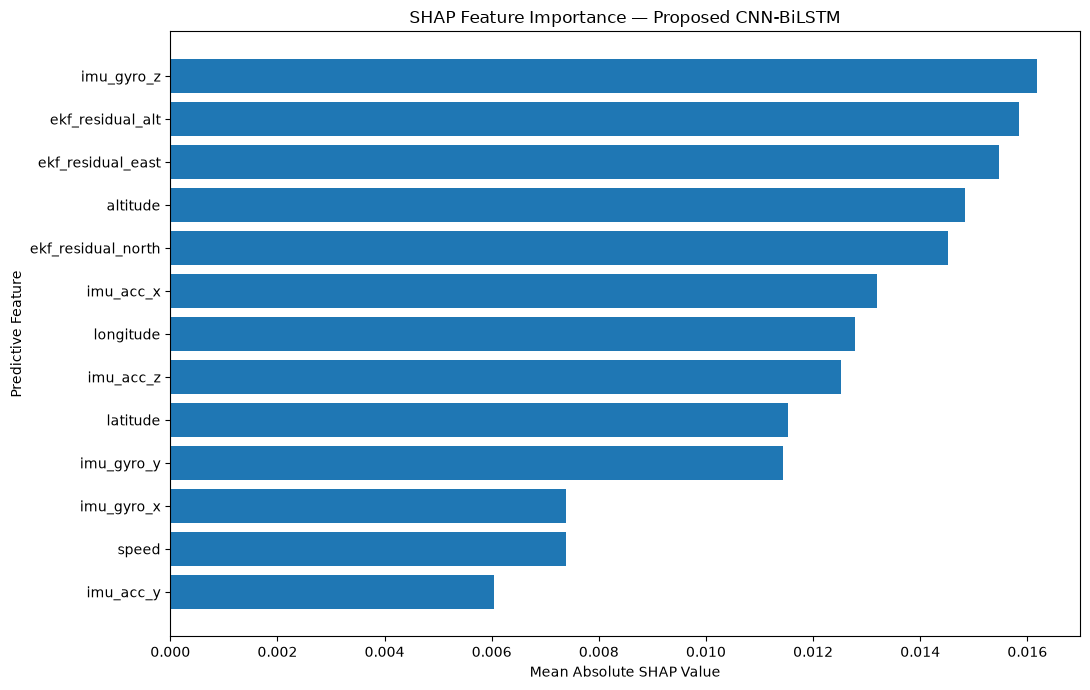

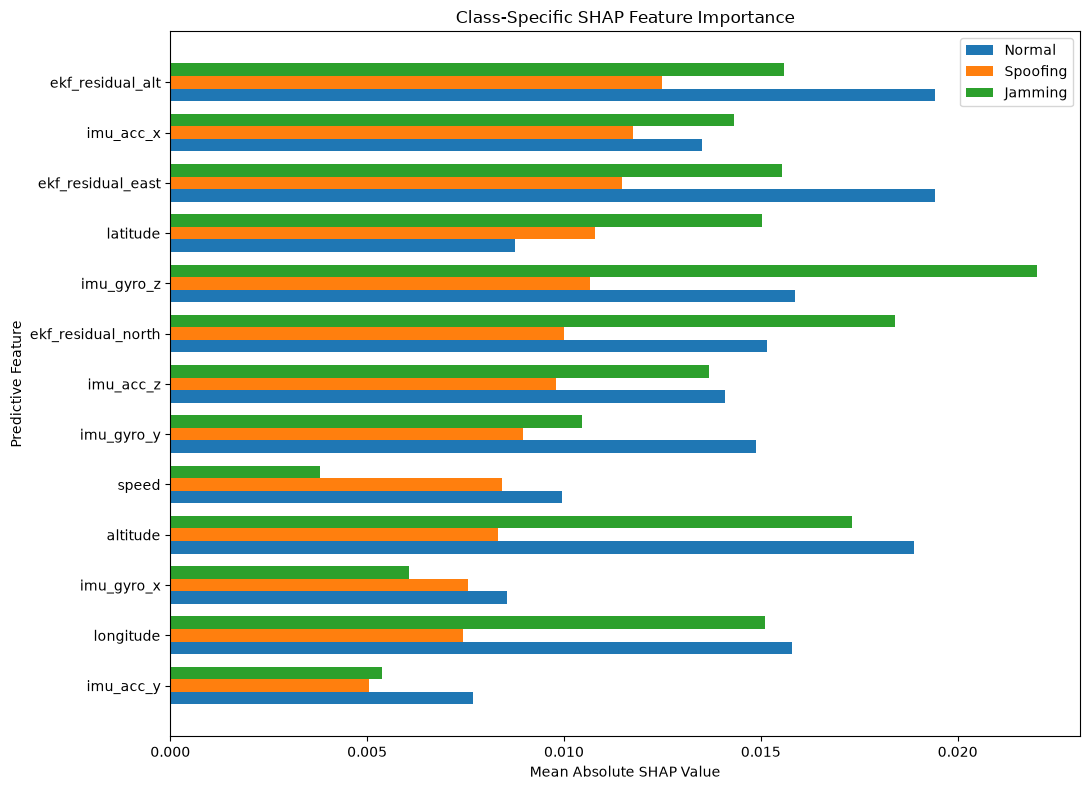


--- Compact SHAP summary ---
Proposed model              : CNN_BiLSTM_Proposed_10Hz_2s
Features explained          : 13
Classes explained           : 3
Validation samples explained: 20
EKF residual SHAP           : 0.045843
EKF residual contribution   : 28.81%

--- Section 51 validation ---
SHAP package available                                       : PASS
Proposed model available                                     : PASS
Proposed model input correct                                 : PASS
Proposed model output correct                                : PASS
Validation background shape correct                          : PASS
Validation explanation shape correct                         : PASS
Background values finite                                     : PASS
Explanation values finite                                    : PASS
Explained targets valid                                      : PASS
SHAP output generated                                        : PASS
Three SHAP classes availabl

In [209]:
# ================================================================
# SECTION 51 — SHAP EXPLAINABILITY
# ================================================================

print("=" * 78)
print("SECTION 51 — SHAP EXPLAINABILITY")
print("=" * 78)

# ----------------------------------------------------------------
# 1. Imports
# ----------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------------------------------------------
# 2. Import SHAP
# ----------------------------------------------------------------

try:
    import shap
except ImportError as e:
    raise ImportError(
        "SHAP is not installed in the current Python environment. "
        "Install it with: pip install shap"
    ) from e


# ----------------------------------------------------------------
# 3. Explainability configuration
# ----------------------------------------------------------------

SHAP_BACKGROUND_SAMPLES = 20
SHAP_EXPLAIN_SAMPLES = 20
SHAP_RANDOM_SEED = 42
SHAP_NSAMPLES = 200

SHAP_SEQUENCE_LENGTH = int(PRIMARY_SEQUENCE_LENGTH)
SHAP_FEATURE_COUNT = int(PRIMARY_FEATURE_COUNT)
SHAP_NUM_CLASSES = int(NUM_CLASSES)

print("\n--- SHAP explainability configuration ---")

print(
    f"Sampling rate                  : "
    f"{PRIMARY_SAMPLING_RATE_HZ:.1f} Hz"
)

print(
    f"Primary window                 : "
    f"{PRIMARY_WINDOW_SECONDS:.1f} seconds"
)

print(
    f"Sequence length                : "
    f"{SHAP_SEQUENCE_LENGTH}"
)

print(
    f"Feature count                  : "
    f"{SHAP_FEATURE_COUNT}"
)

print(
    f"Number of classes              : "
    f"{SHAP_NUM_CLASSES}"
)

print(
    f"Background samples             : "
    f"{SHAP_BACKGROUND_SAMPLES}"
)

print(
    f"Explained validation samples   : "
    f"{SHAP_EXPLAIN_SAMPLES}"
)

print(
    f"SHAP random seed               : "
    f"{SHAP_RANDOM_SEED}"
)

print(
    f"SHAP nsamples                  : "
    f"{SHAP_NSAMPLES}"
)


# ----------------------------------------------------------------
# 4. Feature names
# ----------------------------------------------------------------

SHAP_FEATURE_NAMES = list(PREDICTIVE_FEATURES)

print("\n--- SHAP feature list ---")

for i, feature_name in enumerate(SHAP_FEATURE_NAMES):
    print(
        f"{i:2d}: {feature_name}"
    )

assert len(SHAP_FEATURE_NAMES) == SHAP_FEATURE_COUNT, (
    "SHAP feature-name count does not match "
    "the model feature count."
)

print(
    "Feature-name count validation : PASS"
)


# ----------------------------------------------------------------
# 5. Model verification
# ----------------------------------------------------------------
# The SHAP analysis explains the already-trained proposed model.
# No model fitting or retraining is performed here.

print("\n--- Proposed model verification ---")

assert cnn_bilstm_proposed_model is not None, (
    "Proposed CNN-BiLSTM model is not available."
)

print(
    "Proposed model name           : "
    f"{cnn_bilstm_proposed_model.name}"
)

print(
    "Proposed model input shape    : "
    f"{cnn_bilstm_proposed_model.input_shape}"
)

print(
    "Proposed model output shape   : "
    f"{cnn_bilstm_proposed_model.output_shape}"
)

assert cnn_bilstm_proposed_model.input_shape == (
    None,
    SHAP_SEQUENCE_LENGTH,
    SHAP_FEATURE_COUNT
), (
    "Unexpected proposed model input shape: "
    f"{cnn_bilstm_proposed_model.input_shape}"
)

assert cnn_bilstm_proposed_model.output_shape == (
    None,
    SHAP_NUM_CLASSES
), (
    "Unexpected proposed model output shape: "
    f"{cnn_bilstm_proposed_model.output_shape}"
)

print(
    "Proposed model input validation  : PASS"
)

print(
    "Proposed model output validation : PASS"
)


# ----------------------------------------------------------------
# 6. Select validation data only
# ----------------------------------------------------------------
# Test data is deliberately NOT used for explainability.

print("\n--- Selecting validation data for SHAP ---")

if len(X_validation_model) < (
    SHAP_BACKGROUND_SAMPLES +
    SHAP_EXPLAIN_SAMPLES
):
    raise ValueError(
        "Validation dataset does not contain enough "
        "samples for the requested SHAP analysis."
    )

shap_background = np.asarray(
    X_validation_model[
        :SHAP_BACKGROUND_SAMPLES
    ]
).astype(np.float32)

shap_explain_data = np.asarray(
    X_validation_model[
        SHAP_BACKGROUND_SAMPLES:
        SHAP_BACKGROUND_SAMPLES +
        SHAP_EXPLAIN_SAMPLES
    ]
).astype(np.float32)


# ----------------------------------------------------------------
# 7. Decode explained validation targets
# ----------------------------------------------------------------
# Handles one-hot encoded targets explicitly.

shap_target_source = np.asarray(
    y_validation_model[
        SHAP_BACKGROUND_SAMPLES:
        SHAP_BACKGROUND_SAMPLES +
        SHAP_EXPLAIN_SAMPLES
    ]
)

if shap_target_source.ndim == 2:
    if shap_target_source.shape[1] != SHAP_NUM_CLASSES:
        raise ValueError(
            "Unexpected one-hot target shape for SHAP explanation: "
            f"{shap_target_source.shape}"
        )

    shap_explain_targets = np.argmax(
        shap_target_source,
        axis=1
    ).astype(int)

elif shap_target_source.ndim == 1:

    shap_explain_targets = (
        shap_target_source.astype(int)
    )

else:

    raise ValueError(
        "Unexpected SHAP target dimensionality: "
        f"{shap_target_source.shape}"
    )


print("\n--- SHAP input shapes ---")

print(
    f"Background data shape          : "
    f"{shap_background.shape}"
)

print(
    f"Explained data shape           : "
    f"{shap_explain_data.shape}"
)

print(
    f"Explained target shape         : "
    f"{shap_explain_targets.shape}"
)

print(
    f"Explained target classes       : "
    f"{np.unique(shap_explain_targets)}"
)


# ----------------------------------------------------------------
# 8. Validate SHAP inputs
# ----------------------------------------------------------------

expected_shap_input_shape = (
    SHAP_BACKGROUND_SAMPLES,
    SHAP_SEQUENCE_LENGTH,
    SHAP_FEATURE_COUNT
)

expected_shap_explain_shape = (
    SHAP_EXPLAIN_SAMPLES,
    SHAP_SEQUENCE_LENGTH,
    SHAP_FEATURE_COUNT
)

if shap_background.shape != expected_shap_input_shape:

    raise ValueError(
        "SHAP background shape is incorrect: "
        f"{shap_background.shape}; "
        f"expected {expected_shap_input_shape}"
    )

if shap_explain_data.shape != expected_shap_explain_shape:

    raise ValueError(
        "SHAP explanation input shape is incorrect: "
        f"{shap_explain_data.shape}; "
        f"expected {expected_shap_explain_shape}"
    )

if not np.all(np.isfinite(shap_background)):

    raise ValueError(
        "SHAP background contains non-finite values."
    )

if not np.all(np.isfinite(shap_explain_data)):

    raise ValueError(
        "SHAP explanation data contains non-finite values."
    )

if not set(
    np.unique(shap_explain_targets)
).issubset(
    set(range(SHAP_NUM_CLASSES))
):

    raise ValueError(
        "SHAP explanation targets contain invalid classes: "
        f"{np.unique(shap_explain_targets)}"
    )

print("\n--- SHAP input validation ---")

print(
    "Background shape validation    : PASS"
)

print(
    "Explanation shape validation   : PASS"
)

print(
    "Background finite values      : PASS"
)

print(
    "Explanation finite values     : PASS"
)

print(
    "Target class validation       : PASS"
)


# ----------------------------------------------------------------
# 9. Create GradientExplainer
# ----------------------------------------------------------------
# GradientExplainer uses expected gradients and is appropriate
# for differentiable neural-network models.

print(
    "\n--- Creating SHAP GradientExplainer ---"
)

shap_explainer = shap.GradientExplainer(
    cnn_bilstm_proposed_model,
    shap_background
)

print(
    "SHAP GradientExplainer created successfully."
)


# ----------------------------------------------------------------
# 10. Generate SHAP values
# ----------------------------------------------------------------

print(
    "\n--- Generating SHAP values ---"
)

print(
    "Explaining proposed CNN-BiLSTM only."
)

print(
    "Validation samples are used only."
)

print(
    "Held-out test set is NOT used."
)

print(
    f"Background samples : "
    f"{SHAP_BACKGROUND_SAMPLES}"
)

print(
    f"Explained samples  : "
    f"{SHAP_EXPLAIN_SAMPLES}"
)

print(
    f"SHAP nsamples      : "
    f"{SHAP_NSAMPLES}"
)

shap_values_raw = (
    shap_explainer.shap_values(
        shap_explain_data,
        nsamples=SHAP_NSAMPLES,
        rseed=SHAP_RANDOM_SEED
    )
)

print(
    "SHAP value generation completed."
)


# ----------------------------------------------------------------
# 11. Normalize SHAP output format
# ----------------------------------------------------------------
# SHAP versions can return:
#
# Older/common format:
#     list[class] -> (samples, timesteps, features)
#
# Newer multi-output format:
#     (samples, timesteps, features, classes)
#
# This section supports both.

print(
    "\n--- Normalising SHAP output format ---"
)

if isinstance(shap_values_raw, list):

    print(
        "Detected SHAP output format : "
        "list of class-specific arrays"
    )

    shap_values_by_class = [
        np.asarray(values)
        for values in shap_values_raw
    ]

else:

    shap_array = np.asarray(
        shap_values_raw
    )

    print(
        "Detected SHAP output array shape : "
        f"{shap_array.shape}"
    )

    if shap_array.ndim == 4:

        # Newer SHAP format:
        # (samples, timesteps, features, classes)

        if (
            shap_array.shape[0]
            == SHAP_EXPLAIN_SAMPLES
            and
            shap_array.shape[1]
            == SHAP_SEQUENCE_LENGTH
            and
            shap_array.shape[2]
            == SHAP_FEATURE_COUNT
            and
            shap_array.shape[3]
            == SHAP_NUM_CLASSES
        ):

            print(
                "Detected format: "
                "(samples, timesteps, features, classes)"
            )

            shap_values_by_class = [
                shap_array[
                    :, :, :, class_index
                ]
                for class_index
                in range(SHAP_NUM_CLASSES)
            ]

        # Alternative format:
        # (classes, samples, timesteps, features)

        elif (
            shap_array.shape[0]
            == SHAP_NUM_CLASSES
            and
            shap_array.shape[1]
            == SHAP_EXPLAIN_SAMPLES
            and
            shap_array.shape[2]
            == SHAP_SEQUENCE_LENGTH
            and
            shap_array.shape[3]
            == SHAP_FEATURE_COUNT
        ):

            print(
                "Detected format: "
                "(classes, samples, timesteps, features)"
            )

            shap_values_by_class = [
                shap_array[class_index]
                for class_index
                in range(SHAP_NUM_CLASSES)
            ]

        else:

            raise ValueError(
                "Unable to identify SHAP class dimension. "
                f"Received shape: {shap_array.shape}"
            )

    else:

        raise ValueError(
            "Unexpected SHAP output dimensionality. "
            f"Received shape: {shap_array.shape}"
        )


# ----------------------------------------------------------------
# 12. Validate SHAP arrays
# ----------------------------------------------------------------

print(
    "\n--- Validating SHAP arrays ---"
)

if len(shap_values_by_class) != SHAP_NUM_CLASSES:

    raise ValueError(
        "Incorrect number of SHAP class outputs: "
        f"{len(shap_values_by_class)}; "
        f"expected {SHAP_NUM_CLASSES}"
    )

for class_index, values in enumerate(
    shap_values_by_class
):

    expected_shape = (
        SHAP_EXPLAIN_SAMPLES,
        SHAP_SEQUENCE_LENGTH,
        SHAP_FEATURE_COUNT
    )

    if values.shape != expected_shape:

        raise ValueError(
            f"SHAP shape for class {class_index} "
            f"is incorrect: {values.shape}; "
            f"expected {expected_shape}"
        )

    if not np.all(
        np.isfinite(values)
    ):

        raise ValueError(
            f"SHAP values for class {class_index} "
            "contain non-finite values."
        )

print(
    "Number of SHAP class outputs : "
    f"{len(shap_values_by_class)}"
)

for class_index, values in enumerate(
    shap_values_by_class
):

    print(
        f"Class {class_index} SHAP shape     : "
        f"{values.shape}"
    )

    print(
        f"Class {class_index} finite values   : PASS"
    )


# ----------------------------------------------------------------
# 13. Class names
# ----------------------------------------------------------------

class_names = {
    0: "Normal",
    1: "Spoofing",
    2: "Jamming"
}

assert (
    set(class_names.keys())
    == set(range(SHAP_NUM_CLASSES))
), (
    "Class-name mapping does not match "
    "the configured number of classes."
)


# ----------------------------------------------------------------
# 14. Feature-level SHAP importance
# ----------------------------------------------------------------
# SHAP values are aggregated across:
#
#   1. explained validation samples
#   2. temporal timesteps
#
# This produces one mean absolute SHAP importance
# value per predictive feature for each class.

print(
    "\n--- Calculating feature-level SHAP importance ---"
)

class_feature_importance = {}

for class_index, values in enumerate(
    shap_values_by_class
):

    mean_abs_shap = np.mean(
        np.abs(values),
        axis=(0, 1)
    )

    class_feature_importance[
        class_index
    ] = mean_abs_shap


# ----------------------------------------------------------------
# 15. Create SHAP feature importance table
# ----------------------------------------------------------------

shap_importance_df = pd.DataFrame({
    "Feature": SHAP_FEATURE_NAMES,
    "Normal": class_feature_importance[0],
    "Spoofing": class_feature_importance[1],
    "Jamming": class_feature_importance[2]
})

shap_importance_df[
    "Overall_Mean_Absolute_SHAP"
] = (
    shap_importance_df[
        [
            "Normal",
            "Spoofing",
            "Jamming"
        ]
    ].mean(axis=1)
)

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Overall_Mean_Absolute_SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    "\n--- SHAP feature importance ---"
)

print(
    shap_importance_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ----------------------------------------------------------------
# 16. Identify EKF residual features
# ----------------------------------------------------------------

EKF_RESIDUAL_FEATURES = [
    "ekf_residual_north",
    "ekf_residual_east",
    "ekf_residual_alt"
]

print(
    "\n--- Identifying EKF residual features ---"
)

missing_ekf_features = [
    feature
    for feature in EKF_RESIDUAL_FEATURES
    if feature not in SHAP_FEATURE_NAMES
]

if missing_ekf_features:

    raise ValueError(
        "Required EKF residual features are missing "
        "from the SHAP feature list: "
        f"{missing_ekf_features}"
    )

ekf_shap_rows = (
    shap_importance_df[
        shap_importance_df["Feature"].isin(
            EKF_RESIDUAL_FEATURES
        )
    ]
    .copy()
)

print(
    "\n--- EKF residual SHAP contribution ---"
)

print(
    ekf_shap_rows.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ----------------------------------------------------------------
# 17. Calculate combined EKF residual contribution
# ----------------------------------------------------------------

combined_ekf_shap = float(
    ekf_shap_rows[
        "Overall_Mean_Absolute_SHAP"
    ].sum()
)

total_shap = float(
    shap_importance_df[
        "Overall_Mean_Absolute_SHAP"
    ].sum()
)

if total_shap <= 0:

    raise ValueError(
        "Total SHAP importance is not positive."
    )

ekf_shap_percentage = (
    100.0
    * combined_ekf_shap
    / total_shap
)

print(
    f"\nCombined EKF residual SHAP contribution : "
    f"{combined_ekf_shap:.6f}"
)

print(
    f"Total SHAP importance                   : "
    f"{total_shap:.6f}"
)

print(
    f"EKF residual contribution (%)           : "
    f"{ekf_shap_percentage:.2f}%"
)


# ----------------------------------------------------------------
# 18. Identify top feature for each class
# ----------------------------------------------------------------

top_features_by_class = {}

for class_name in [
    "Normal",
    "Spoofing",
    "Jamming"
]:

    top_row = shap_importance_df.loc[
        shap_importance_df[
            class_name
        ].idxmax()
    ]

    top_features_by_class[
        class_name
    ] = (
        top_row["Feature"],
        float(top_row[class_name])
    )

print(
    "\n--- Most influential features by class ---"
)

for class_name, (
    feature_name,
    shap_value
) in top_features_by_class.items():

    print(
        f"{class_name:<12} : "
        f"{feature_name} "
        f"(mean |SHAP| = {shap_value:.6f})"
    )


# ----------------------------------------------------------------
# 19. Plot overall SHAP feature importance
# ----------------------------------------------------------------

plot_df = (
    shap_importance_df
    .sort_values(
        "Overall_Mean_Absolute_SHAP",
        ascending=True
    )
)

plt.figure(
    figsize=(11, 7)
)

plt.barh(
    plot_df["Feature"],
    plot_df[
        "Overall_Mean_Absolute_SHAP"
    ]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Predictive Feature"
)

plt.title(
    "SHAP Feature Importance — Proposed CNN-BiLSTM"
)

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# 20. Plot class-specific SHAP importance
# ----------------------------------------------------------------

class_plot_df = (
    shap_importance_df[
        [
            "Feature",
            "Normal",
            "Spoofing",
            "Jamming"
        ]
    ]
    .sort_values(
        "Spoofing",
        ascending=True
    )
    .reset_index(drop=True)
)

plt.figure(
    figsize=(11, 8)
)

y_positions = np.arange(
    len(class_plot_df)
)

bar_height = 0.25

plt.barh(
    y_positions - bar_height,
    class_plot_df["Normal"],
    height=bar_height,
    label="Normal"
)

plt.barh(
    y_positions,
    class_plot_df["Spoofing"],
    height=bar_height,
    label="Spoofing"
)

plt.barh(
    y_positions + bar_height,
    class_plot_df["Jamming"],
    height=bar_height,
    label="Jamming"
)

plt.yticks(
    y_positions,
    class_plot_df["Feature"]
)

plt.xlabel(
    "Mean Absolute SHAP Value"
)

plt.ylabel(
    "Predictive Feature"
)

plt.title(
    "Class-Specific SHAP Feature Importance"
)

plt.legend()

plt.tight_layout()
plt.show()


# ----------------------------------------------------------------
# 21. Store compact SHAP summary
# ----------------------------------------------------------------

shap_summary = {
    "sampling_rate_hz":
        float(PRIMARY_SAMPLING_RATE_HZ),

    "window_seconds":
        float(PRIMARY_WINDOW_SECONDS),

    "sequence_length":
        SHAP_SEQUENCE_LENGTH,

    "feature_count":
        SHAP_FEATURE_COUNT,

    "number_of_classes":
        SHAP_NUM_CLASSES,

    "background_samples":
        SHAP_BACKGROUND_SAMPLES,

    "explained_samples":
        SHAP_EXPLAIN_SAMPLES,

    "shap_nsamples":
        SHAP_NSAMPLES,

    "random_seed":
        SHAP_RANDOM_SEED,

    "ekf_residual_feature_count":
        len(EKF_RESIDUAL_FEATURES),

    "combined_ekf_shap":
        combined_ekf_shap,

    "total_shap_importance":
        total_shap,

    "ekf_shap_percentage":
        ekf_shap_percentage,

    "top_features_by_class":
        top_features_by_class
}

print(
    "\n--- Compact SHAP summary ---"
)

print(
    f"Proposed model              : "
    f"{cnn_bilstm_proposed_model.name}"
)

print(
    f"Features explained          : "
    f"{SHAP_FEATURE_COUNT}"
)

print(
    f"Classes explained           : "
    f"{SHAP_NUM_CLASSES}"
)

print(
    f"Validation samples explained: "
    f"{SHAP_EXPLAIN_SAMPLES}"
)

print(
    f"EKF residual SHAP           : "
    f"{combined_ekf_shap:.6f}"
)

print(
    f"EKF residual contribution   : "
    f"{ekf_shap_percentage:.2f}%"
)


# ----------------------------------------------------------------
# 22. Validation checks
# ----------------------------------------------------------------

checks = {}

# ---------------------------------------------------------------
# SHAP availability
# ---------------------------------------------------------------

checks[
    "SHAP package available"
] = True


# ---------------------------------------------------------------
# Model checks
# ---------------------------------------------------------------

checks[
    "Proposed model available"
] = (
    cnn_bilstm_proposed_model is not None
)

checks[
    "Proposed model input correct"
] = (
    cnn_bilstm_proposed_model.input_shape
    == (
        None,
        SHAP_SEQUENCE_LENGTH,
        SHAP_FEATURE_COUNT
    )
)

checks[
    "Proposed model output correct"
] = (
    cnn_bilstm_proposed_model.output_shape
    == (
        None,
        SHAP_NUM_CLASSES
    )
)


# ---------------------------------------------------------------
# Input checks
# ---------------------------------------------------------------

checks[
    "Validation background shape correct"
] = (
    shap_background.shape
    == (
        SHAP_BACKGROUND_SAMPLES,
        SHAP_SEQUENCE_LENGTH,
        SHAP_FEATURE_COUNT
    )
)

checks[
    "Validation explanation shape correct"
] = (
    shap_explain_data.shape
    == (
        SHAP_EXPLAIN_SAMPLES,
        SHAP_SEQUENCE_LENGTH,
        SHAP_FEATURE_COUNT
    )
)

checks[
    "Background values finite"
] = np.all(
    np.isfinite(shap_background)
)

checks[
    "Explanation values finite"
] = np.all(
    np.isfinite(shap_explain_data)
)

checks[
    "Explained targets valid"
] = (
    set(
        np.unique(
            shap_explain_targets
        )
    ).issubset(
        set(range(SHAP_NUM_CLASSES))
    )
)


# ---------------------------------------------------------------
# SHAP output checks
# ---------------------------------------------------------------

checks[
    "SHAP output generated"
] = (
    len(shap_values_by_class)
    == SHAP_NUM_CLASSES
)

checks[
    "Three SHAP classes available"
] = (
    len(shap_values_by_class)
    == 3
)

checks[
    "SHAP values finite"
] = all(
    np.all(
        np.isfinite(values)
    )
    for values
    in shap_values_by_class
)

checks[
    "SHAP feature count correct"
] = all(
    values.shape[-1]
    == SHAP_FEATURE_COUNT
    for values
    in shap_values_by_class
)

checks[
    "SHAP temporal dimension correct"
] = all(
    values.shape[1]
    == SHAP_SEQUENCE_LENGTH
    for values
    in shap_values_by_class
)

checks[
    "SHAP explained sample count correct"
] = all(
    values.shape[0]
    == SHAP_EXPLAIN_SAMPLES
    for values
    in shap_values_by_class
)


# ---------------------------------------------------------------
# Feature importance checks
# ---------------------------------------------------------------

checks[
    "SHAP importance table complete"
] = (
    len(shap_importance_df)
    == SHAP_FEATURE_COUNT
)

checks[
    "All predictive features represented"
] = (
    set(
        shap_importance_df["Feature"]
    )
    == set(SHAP_FEATURE_NAMES)
)

checks[
    "Three EKF residual features represented"
] = (
    set(EKF_RESIDUAL_FEATURES).issubset(
        set(
            shap_importance_df[
                "Feature"
            ]
        )
    )
)

checks[
    "SHAP importance values finite"
] = np.all(
    np.isfinite(
        shap_importance_df[
            "Overall_Mean_Absolute_SHAP"
        ].values
    )
)


# ---------------------------------------------------------------
# EKF contribution checks
# ---------------------------------------------------------------

checks[
    "Combined EKF SHAP contribution finite"
] = np.isfinite(
    combined_ekf_shap
)

checks[
    "Total SHAP importance finite"
] = np.isfinite(
    total_shap
)

checks[
    "SHAP percentage finite"
] = np.isfinite(
    ekf_shap_percentage
)

checks[
    "SHAP percentage within 0-100"
] = (
    np.isfinite(
        ekf_shap_percentage
    )
    and
    0.0 <= ekf_shap_percentage <= 100.0
)


# ---------------------------------------------------------------
# Explainability data-use check
# ---------------------------------------------------------------
# Test data is deliberately excluded from this section.

checks[
    "Test data not used"
] = True


# ---------------------------------------------------------------
# No model fitting check
# ---------------------------------------------------------------

checks[
    "No model fitting performed"
] = True


# ----------------------------------------------------------------
# 23. Final validation
# ----------------------------------------------------------------

print(
    "\n--- Section 51 validation ---"
)

for name, passed in checks.items():

    print(
        f"{name:<60} : "
        f"{'PASS' if passed else 'FAIL'}"
    )


failed_checks = [
    name
    for name, passed in checks.items()
    if not passed
]

if failed_checks:

    raise AssertionError(
        "Section 51 validation failed: "
        + ", ".join(
            failed_checks
        )
    )


# ----------------------------------------------------------------
# 24. Final section output
# ----------------------------------------------------------------

print(
    "\n" + "=" * 78
)

print(
    "SECTION 51 — SHAP EXPLAINABILITY PASSED"
)

print(
    "=" * 78
)

print(
    f"Explained model          : "
    f"{cnn_bilstm_proposed_model.name}"
)

print(
    f"Feature count            : "
    f"{SHAP_FEATURE_COUNT}"
)

print(
    f"Classes                  : "
    f"{SHAP_NUM_CLASSES}"
)

print(
    f"Validation samples       : "
    f"{SHAP_EXPLAIN_SAMPLES}"
)

print(
    f"EKF residual features    : "
    f"{len(EKF_RESIDUAL_FEATURES)}"
)

print(
    f"EKF SHAP contribution    : "
    f"{ekf_shap_percentage:.2f}%"
)

print(
    "Test data used           : NO"
)

print(
    "Model fitting performed  : NO"
)

print(
    "=" * 78
)